# Imports and Util Functions

In [ ]:
#@title Imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import plotly.express as px
import plotly.graph_objects as go
import os # For creating an output directory

## Util

In [ ]:
#@title Misc

def get_criteria_names(df):
  prefix = 'num_alternatives_contributed_'
  columns = df.filter(like=prefix).columns
  criteria_names = []
  for column_name in columns:
    criteria_names.append(column_name[len(prefix):])
  return criteria_names

def get_metric_names(df):
  criteria_names = get_criteria_names(df)
  if len(criteria_names) == 0:
    return []

  suffix = '_' + criteria_names[0]
  columns = df.filter(like=suffix).columns
  metric_names = []
  for column_name in columns:
    metric_names.append(column_name[:-len(suffix)])
  return metric_names

In [ ]:
#@title Confidence Intervals

# Helper function to calculate median confidence interval using bootstrapping
def median_ci(data, n_bootstraps=1000, ci_level=0.95):
  bootstrapped_medians = np.zeros(n_bootstraps)
  for i in range(n_bootstraps):
    bootstrap_sample = np.random.choice(data, size=len(data), replace=True)
    bootstrapped_medians[i] = np.median(bootstrap_sample)

  lower_bound = np.percentile(bootstrapped_medians, (1 - ci_level) / 2 * 100)
  upper_bound = np.percentile(bootstrapped_medians, (1 + ci_level) / 2 * 100)
  return {'median': np.median(data), 'lower_bound': lower_bound, 'upper_bound': upper_bound}

def median_cis_from_df(df):
  criteria_names = get_criteria_names(df)
  metric_names = get_metric_names(criteria_names)
  median_cis = {}
  for metric_name in metric_names:
    median_cis[metric_name] = median_ci(df[metric_name])
  return median_cis

def mean_ci(data, ci_level=0.95):
  mean = np.mean(data)
  std = np.std(data)
  Z = stats.norm.ppf((1 + ci_level) / 2)
  margin_of_error = Z * (std / np.sqrt(len(data)))
  return {'mean': mean, 'lower_bound': mean - margin_of_error,
          'upper_bound': mean + margin_of_error}

def mean_cis_from_df(df):
  criteria_names = get_criteria_names(df)
  metric_names = get_metric_names(criteria_names)
  mean_cis = {}
  for metric_name in metric_names:
    mean_cis[metric_name] = mean_ci(df[metric_name])
  return mean_cis

def compute_contribution_gaps(cis_dict, metric_prefix, est_key='mean'):
  """Computes both the Maximal Contribution Gap (MCG = max_c U_c - min_c L_c)
  and the Central Contribution Gap (CCG = max_c c_hat_c - min_c c_hat_c)."""
  cols = [k for k in cis_dict.keys() if k.startswith(metric_prefix + '_')]
  if not cols:
    return None, None
  ests = [cis_dict[c][est_key] for c in cols]
  lbs  = [cis_dict[c]['lower_bound'] for c in cols]
  ubs  = [cis_dict[c]['upper_bound'] for c in cols]
  mcg = max(ubs) - min(lbs)
  ccg = max(ests) - min(ests)
  return mcg, ccg

def print_mean_cis(mean_cis):
  for col, res in mean_cis.items():
    print(f"=== Confidence Intervals for {col} ===")
    print(f"Final Mean Estimate: {res['mean']:.4f}")
    print(f"95% Confidence Interval (Mean): [{res['lower_bound']:.4f}, {res['upper_bound']:.4f}]\n")
  for prefix, label in [('relative_avg', 'RMC'), ('relative_high_owa', 'RHPC')]:
    mcg, ccg = compute_contribution_gaps(mean_cis, prefix, est_key='mean')
    if mcg is not None:
      print(f"--- {label} Disparity Summary (Mean) ---")
      print(f"Maximal Contribution Gap (MCG = max U_c - min L_c): {mcg:.4f}")
      print(f"Central Contribution Gap (CCG = max c_hat - min c_hat): {ccg:.4f}\n")

def print_median_cis(median_cis):
  for col, res in median_cis.items():
    print(f"=== Confidence Intervals for {col} ===")
    print(f"Final Median Estimate: {res['median']:.4f}")
    print(f"95% Confidence Interval (Median): [{res['lower_bound']:.4f}, {res['upper_bound']:.4f}]\n")
  for prefix, label in [('relative_avg', 'RMC'), ('relative_high_owa', 'RHPC')]:
    mcg, ccg = compute_contribution_gaps(median_cis, prefix, est_key='median')
    if mcg is not None:
      print(f"--- {label} Disparity Summary (Median) ---")
      print(f"Maximal Contribution Gap (MCG = max U_c - min L_c): {mcg:.4f}")
      print(f"Central Contribution Gap (CCG = max c_hat - min c_hat): {ccg:.4f}\n")


In [ ]:
#@title Plots and Stats

def histogram_for_criterion(df, criterion_name):
  metric_names = ['relative_avg', 'relative_high_owa', 'relative_max']
  for metric_name in metric_names:
    sns.displot(data=df, x=metric_name + '_' + criterion_name, kind='hist')
    plt.title(f'Distribution of {metric_name} for {criterion_name}')
    plt.xlabel(metric_name)
    plt.ylabel('Frequency')
    plt.show()

def histogram_for_metric(df, metric_name, criteria_names, stats_in_graph=False):
  for criterion_name in criteria_names:
    column_name = metric_name + '_' + criterion_name
    sns.displot(data=df, x=column_name, kind='hist', height=6, aspect=1.7)
    plt.title(f'Distribution of {metric_name} for {criterion_name}')
    if stats_in_graph:
      stats = calculate_stats(df[column_name])
      colors = ['blue', 'green', 'yellow', 'orange', 'red', 'purple', 'black']
      i = 0
      for stat in stats:
        plt.axvline(stats[stat], color=colors[i % len(colors)], linestyle='--',
                    linewidth=1, label=f'{stat} ({stats[stat]:,.3f})')
        i += 1
    plt.xlabel(metric_name)
    plt.ylabel('Frequency')
    plt.legend()
    plt.show()

def kde_for_metric(df, metric_name, criteria_names):
  columns_to_plot = [metric_name + '_' + criterion_name for criterion_name in criteria_names]
  sns.displot(data=df[columns_to_plot], kind='kde')
  plt.title(f'Distribution of {metric_name} for all criteria')
  plt.xlabel(metric_name)
  plt.ylabel('Frequency')
  plt.show()

# def get_criterion_name_for_plot(df_name, criterion):
#   prefix, suffix = '', ''
#   if df_name.startswith('formats_combined'):
#     if criterion.startswith('rn_from_data'):
#       prefix = 'RN No Scale + '
#     elif criterion.startswith('rn_fixed_scale'):
#       prefix = 'RN Fixed Scale + '
#     elif criterion.startswith('uv_cardinal'):
#       prefix = 'Cardinal UV + '
#     elif criterion.startswith('uv_ordinal'):
#       prefix = 'Ordinal UV + '
#     elif criterion.startswith('oa'):
#       prefix = 'OA + '
#     elif criterion.startswith('arfpr'):
#       prefix = 'ARFPR + '
#     elif criterion.startswith('mpr'):
#       prefix = 'MPR + '

#   if criterion.endswith('_distance') or criterion.endswith('_diff'):
#     suffix = 'Distance'
#   elif criterion.endswith('_div'):
#     suffix = 'Division'
#   elif criterion.endswith('_div_sqrt'):
#     suffix = 'Square Root-Division'
#   elif criterion.endswith('_div_sqrd'):
#     suffix = 'Squared-Division'
#   elif criterion.endswith('_original'):
#     suffix = 'Original'
#   elif criterion.endswith('_proposed'):
#     suffix = 'Proposed'
#   else:
#     suffix = '?'

#   return prefix + suffix

def boxplot_for_metric(df, metric_name, criteria_names):
  columns_to_plot = [metric_name + '_' + criterion_name for criterion_name in criteria_names]
  fig = go.Figure()
  for criterion in criteria_names:
      fig.add_trace(go.Box(y=df[metric_name + '_' + criterion], name=criterion,
                           boxmean=True))

  fig.update_layout(
      title_text=f'Boxplot of {metric_name} for all criteria',
      yaxis_title='Distribution',
      xaxis_title=metric_name
  )

  fig.show()

def violinplot_for_metric(df, metric_name, criteria_names):
  # Create violin plots for each selected column
  fig = go.Figure()
  columns_to_plot = [metric_name + '_' + criterion_name for criterion_name in criteria_names]

  for criterion in criteria_names:
    fig.add_trace(go.Violin(y=df[metric_name + '_' + criterion], name=criterion,
                            box_visible=True, meanline_visible=True,
                            opacity=1.0))

  metric_title = ''
  if metric_name == 'relative_avg':
    metric_title= 'Relative Mean'
  elif metric_name == 'relative_high_owa':
    metric_title = 'Relative High OWA'
  else:
    metric_title = 'Relative Number of Alternatives Contributed'
  fig.update_layout(
      title_text=f'Violin plot of {metric_title} for all criteria',
      yaxis_title='Distribution',
      xaxis_title=metric_title
  )

  fig.show()

def plot_percentiles(metric: pd.Series):
  percentiles = []
  p_values = []
  for i in range(0, 101, 5):
    percentile = np.percentile(metric, i)
    print(f'p{i}: {percentile}')
    p_values.append(percentile)
    percentiles.append(i)

  plt.plot(percentiles, p_values)

def plot_mean_ci_from_dict(mean_cis_dict, metric_name):
  metrics = []
  for metric in mean_cis_dict.keys():
    if metric.startswith(metric_name):
      metrics.append(metric)
  means = [mean_cis_dict[col]['mean'] for col in metrics]
  lower_bounds = [mean_cis_dict[col]['lower_bound'] for col in metrics]
  upper_bounds = [mean_cis_dict[col]['upper_bound'] for col in metrics]

  # Extract just the criterion name from the column name
  criteria_names = [col.replace(f'{metric_name}_', '') for col in metrics]

  plt.figure(figsize=(14, 7))

  plt.errorbar(criteria_names, means,
               yerr=[np.array(means) - np.array(lower_bounds),
                     np.array(upper_bounds) - np.array(means)],
               fmt='o', capsize=5, label='Mean with 95% CI', color='teal')
  title_metric_name = ''
  if metric_name == 'relative_avg':
    title_metric_name = 'Relative Mean'
  elif metric_name == 'relative_high_owa':
    title_metric_name = 'Relative High OWA'

  plt.title(f'Mean and 95% Confidence Interval for {title_metric_name} Across Criteria',
            fontsize=16)
  plt.xlabel('Criterion', fontsize=14)
  plt.ylabel(f'Mean "{title_metric_name}"', fontsize=14)
  plt.xticks(rotation=45, ha='right')
  plt.minorticks_on()
  plt.grid(True, which='major', linestyle='--', alpha=0.65)
  plt.grid(True, which='minor', linestyle=':', alpha=0.35)
  plt.legend()
  plt.tight_layout()
  plt.show()

def plot_median_ci_from_dict(median_cis_dict, metric_name):
  metrics = []
  for metric in median_cis_dict.keys():
    if metric.startswith(metric_name):
      metrics.append(metric)
  medians = [median_cis_dict[col]['median'] for col in metrics]
  lower_bounds = [median_cis_dict[col]['lower_bound'] for col in metrics]
  upper_bounds = [median_cis_dict[col]['upper_bound'] for col in metrics]

  # Extract just the criterion name from the column name
  criteria_names = [col.replace(f'{metric_name}_', '') for col in metrics]

  plt.figure(figsize=(14, 7))

  plt.errorbar(criteria_names, medians,
               yerr=[np.array(medians) - np.array(lower_bounds),
                     np.array(upper_bounds) - np.array(medians)],
               fmt='o', capsize=5, label='Median with 95% CI', color='teal')

  title_metric_name = ''
  if metric_name == 'relative_avg':
    title_metric_name = 'Relative Mean'
  elif metric_name == 'relative_high_owa':
    title_metric_name = 'Relative High OWA'

  plt.title(f'Median and 95% Confidence Interval for {title_metric_name} Across Criteria',
            fontsize=16)
  plt.xlabel('Criterion', fontsize=14)
  plt.ylabel(f'Median "{title_metric_name}"', fontsize=14)
  plt.xticks(rotation=45, ha='right')
  plt.minorticks_on()
  plt.grid(True, which='major', linestyle='--', alpha=0.65)
  plt.grid(True, which='minor', linestyle=':', alpha=0.35)
  plt.legend()
  plt.tight_layout()
  plt.show()

# Plots the CIs of the mean and the median of a metric in the same graph
def plot_cis_from_dict(means_dict, medians_dict, metric_name):
  mean_metrics = []
  for metric in means_dict.keys():
    if metric.startswith(metric_name):
      mean_metrics.append(metric)
  means = np.array([means_dict[col]['mean'] for col in mean_metrics])
  mean_lower_bounds = np.array([means_dict[col]['lower_bound'] for col in mean_metrics])
  mean_upper_bounds = np.array([means_dict[col]['upper_bound'] for col in mean_metrics])

  median_metrics = []
  for metric in medians_dict.keys():
    if metric.startswith(metric_name):
      median_metrics.append(metric)
  medians = np.array([medians_dict[col]['median'] for col in median_metrics])
  median_lower_bounds = np.array([medians_dict[col]['lower_bound'] for col in median_metrics])
  median_upper_bounds = np.array([medians_dict[col]['upper_bound'] for col in median_metrics])

  # Extract just the criterion name from the column name
  criteria_names = [col.replace(f'{metric_name}_', '') for col in median_metrics]

  plt.figure(figsize=(14, 7))

  plt.errorbar(criteria_names, means,
               yerr=[means - mean_lower_bounds, mean_upper_bounds - means],
               fmt='o', capsize=5, label='Mean with 95% CI', color='red')

  plt.errorbar(criteria_names, medians,
               yerr=[medians - median_lower_bounds, median_upper_bounds - medians],
               fmt='o', capsize=5, label='Median with 95% CI', color='teal')

  title_metric_name = ''
  if metric_name == 'relative_avg':
    title_metric_name = 'Relative Mean'
  elif metric_name == 'relative_high_owa':
    title_metric_name = 'Relative High OWA'

  plt.title(f'Mean and Median and 95% Confidence Interval for {title_metric_name} Across Criteria',
            fontsize=16)
  plt.xlabel('Criterion', fontsize=14)
  plt.ylabel(f'Mean and Median "{title_metric_name}" metric', fontsize=14)
  plt.xticks(rotation=45, ha='right')
  plt.minorticks_on()
  plt.grid(True, which='major', linestyle='--', alpha=0.65)
  plt.grid(True, which='minor', linestyle=':', alpha=0.35)
  plt.legend()
  plt.tight_layout()
  plt.show()

def calculate_stats(metric: pd.Series):
  stats = {}
  # Main percentiles
  stats['min'] = np.min(metric)
  stats['p5'] = np.percentile(metric, 5)
  stats['p10'] = np.percentile(metric, 10)
  stats['p25'] = np.percentile(metric, 25)
  stats['p75'] = np.percentile(metric, 75)
  stats['p90'] = np.percentile(metric, 90)
  stats['p95'] = np.percentile(metric, 95)
  stats['max'] = np.max(metric)

  # Mean with confidence intervals
  mean = np.mean(metric)
  stats['mean'] = mean
  stats['std'] = np.std(metric)
  Z = 1.96  # for 95% confidence interval
  margin_of_error = Z * (stats['std'] / np.sqrt(len(metric)))
  stats['mean_ci_lower'] = mean - margin_of_error
  stats['mean_ci_upper'] = mean + margin_of_error

  # Median with confidence intervals
  median_cis = median_ci(metric)
  stats['median'] = median_cis['median']
  stats['median_ci_lower'] = median_cis['lower_bound']
  stats['median_ci_upper'] = median_cis['upper_bound']

  return stats

In [ ]:
#@title Convergence Stability

def test_convergence(metric: pd.Series, complete=False):
  # Calculate cumulative metrics for plotting
  plot_points = np.arange(100, len(metric), 100)
  cumulative_means = []
  ci_upper_bounds = []
  ci_lower_bounds = []
  cumulative_p5 = []
  cumlative_p25 = []
  cumlative_p50 = []
  cumulative_p75 = []
  cumulative_p95 = []

  Z = 1.96  # For 95% CI

  for i in plot_points:
    current_data = metric[:i]
    mean = np.mean(current_data)
    std_dev = np.std(current_data)
    margin_of_error = Z * (std_dev / np.sqrt(i))
    p5 = np.percentile(current_data, 5)
    p25 = np.percentile(current_data, 25)
    p50 = np.percentile(current_data, 50)
    p75 = np.percentile(current_data, 75)
    p95 = np.percentile(current_data, 95)

    cumulative_means.append(mean)
    ci_upper_bounds.append(mean + margin_of_error)
    ci_lower_bounds.append(mean - margin_of_error)
    cumulative_p5.append(p5)
    cumlative_p25.append(p25)
    cumlative_p50.append(p50)
    cumulative_p75.append(p75)
    cumulative_p95.append(p95)

  # Plot the convergence with CI bands
  plt.figure(figsize=(10, 6))
  plt.plot(plot_points, cumulative_means, label='Cumulative Mean')
  if complete:
    plt.plot(plot_points, cumulative_p75, label='Cumulative 75th Percentile')
    plt.plot(plot_points, cumlative_p50, label='Cumulative Median')
    plt.plot(plot_points, cumlative_p25, label='Cumulative 25th Percentile')
  plt.fill_between(plot_points, ci_lower_bounds, ci_upper_bounds, color='skyblue', alpha=0.4, label='95% Confidence Interval')
  plt.title(f'Convergence of Mean {metric.name} with 95% Confidence Interval')
  plt.xlabel('Number of Simulations')
  plt.ylabel(metric.name)
  plt.legend()
  plt.grid(True, which='both', linestyle='--', alpha=0.6)
  plt.show()

def test_convergence_for_metric(df, metric_name):
  criteria_names = get_criteria_names(df)
  for criterion in criteria_names:
    column_name = metric_name + '_' + criterion
    if column_name in df.columns:
      test_convergence(df[column_name])

def test_convergence_from_config(configuration, sample_size=100000, run=1):
  file_path = f'/content/{configuration}_sample_{sample_size}_run_{run}.csv'
  df = pd.read_csv(file_path)
  print(f'========= Convergence Test for {configuration} ===============')
  print('============== Relative Mean =================')
  test_convergence_for_metric(df, 'relative_avg')
  print('============ Relative High OWA ===============')
  test_convergence_for_metric(df, 'relative_high_owa')

In [ ]:
#@title Run-to-Run Stability

def test_run_to_run_mean_stability_for_metric(dfs, metric_name):
  # Same criteria for the M dfs
  M_runs = len(dfs)
  criteria_names = get_criteria_names(dfs[0])
  final_cis = dict()

  # Values for the CI computation
  degrees_of_freedom = M_runs - 1
  confidence_level = 0.95
  t_value = stats.t.ppf((1 + confidence_level) / 2, df=degrees_of_freedom)

  for criterion in criteria_names:
    column_name = metric_name + '_' + criterion
    if column_name in dfs[0].columns:
      column_means = np.zeros(M_runs)
      for i in range(M_runs):
        column_means[i] = np.mean(dfs[i][column_name])
      mean_of_means = np.mean(column_means)
      std_of_means = np.std(column_means, ddof=1) # Use ddof=1 for sample std dev
      margin_of_error_final = t_value * (std_of_means / np.sqrt(M_runs))
      final_cis[column_name] = {'mean': mean_of_means,
                                'lower_bound': mean_of_means - margin_of_error_final,
                                'upper_bound': mean_of_means + margin_of_error_final}

  return final_cis

def test_run_to_run_stability_from_config(configuration, plot_graph=False):
  M_runs = 5
  dfs = []

  for i in range(M_runs):
    dfs.append(pd.read_csv(f'/content/{configuration}_sample_100000_run_{i+1}.csv'))

  # Run to Run stability on the Mean CI
  relative_avg_mean_cis = test_run_to_run_mean_stability_for_metric(dfs, 'relative_avg')
  relative_high_owa_mean_cis = test_run_to_run_mean_stability_for_metric(dfs, 'relative_high_owa')
  mean_cis = {**relative_avg_mean_cis, **relative_high_owa_mean_cis}

  # Run to Run stability on the Bootstraped Median CI
  merged_dfs = pd.concat(dfs, ignore_index=True)
  median_cis = median_cis_from_df(merged_dfs)

  if plot_graph:
    plot_mean_ci_from_dict(mean_cis, 'relative_avg')
    plot_mean_ci_from_dict(mean_cis, 'relative_high_owa')
    plot_median_ci_from_dict(median_cis, 'relative_avg')
    plot_median_ci_from_dict(median_cis, 'relative_high_owa')

  return mean_cis, median_cis

# Convergence Stability Analysis

Conclusion for both techniques: Some configurations needed 40k simulations to converge, others 60k and others 80k. I'll stick to 100k to be sure.

## First Technique - Early Aggregation
Conclusion: Some configurations needed 40k simulations to converge, others 60k and others 80k. I'll stick to 100k to be sure.

### All ARFPR Transformation Functions

The mean converges at around 40k simulations.

========= Convergence Test for all_arfpr ===============
============== Relative Mean =================


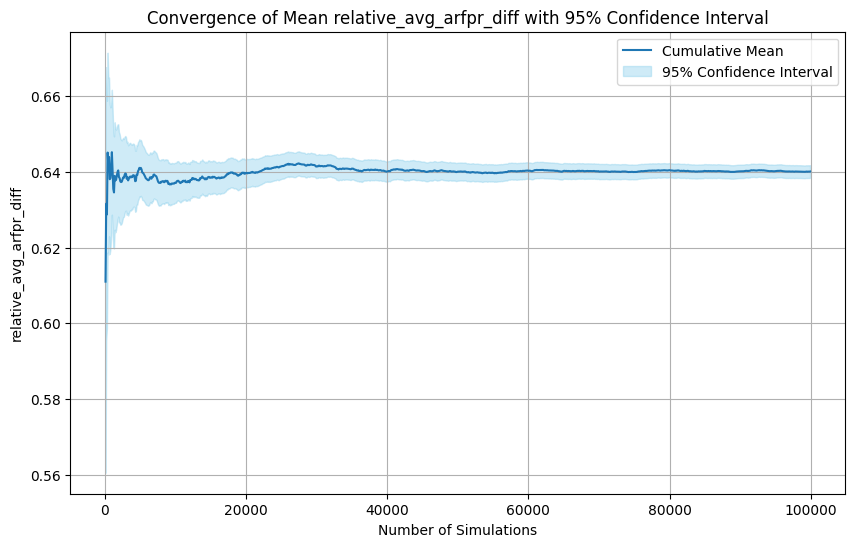

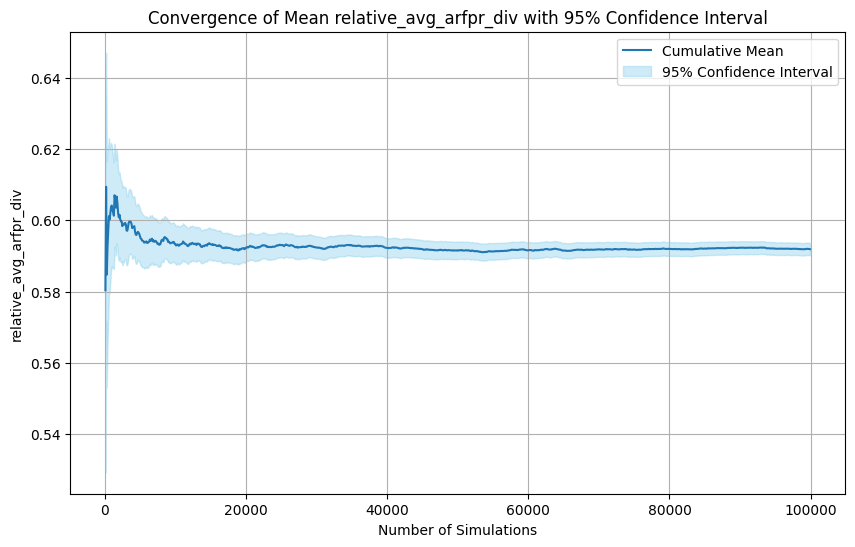

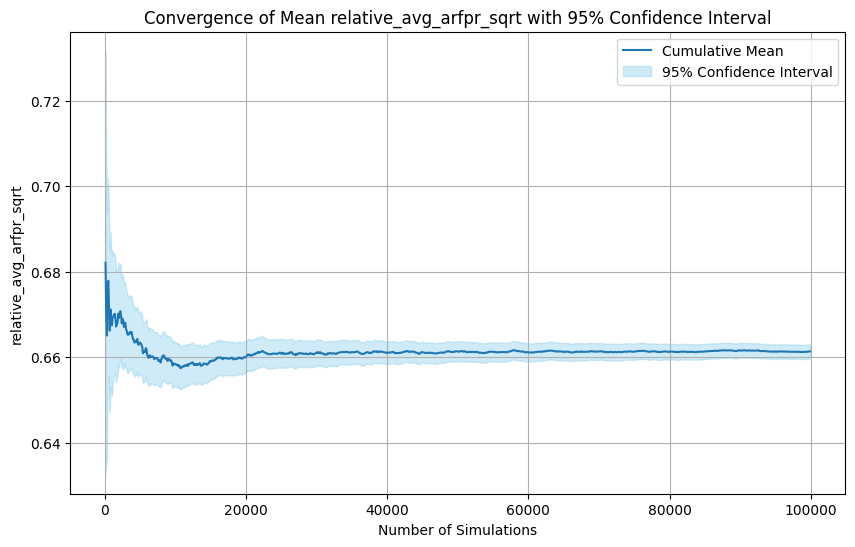

============ Relative High OWA ===============


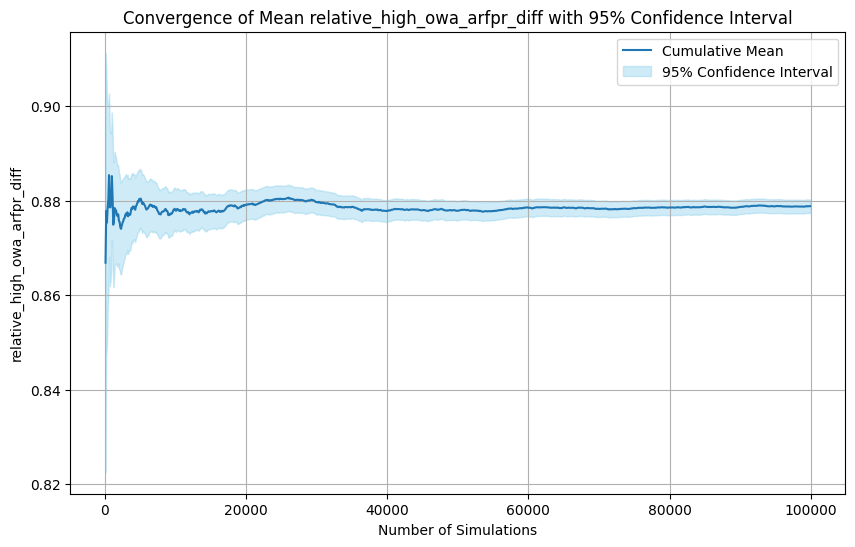

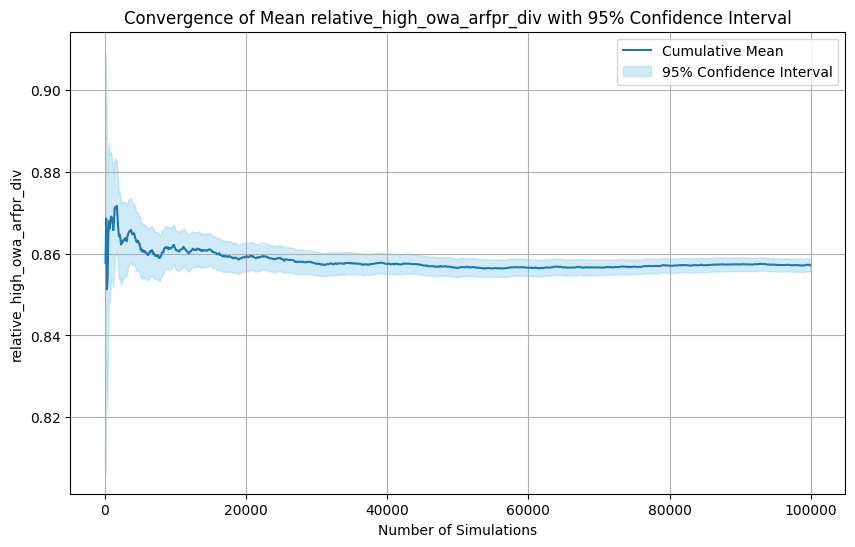

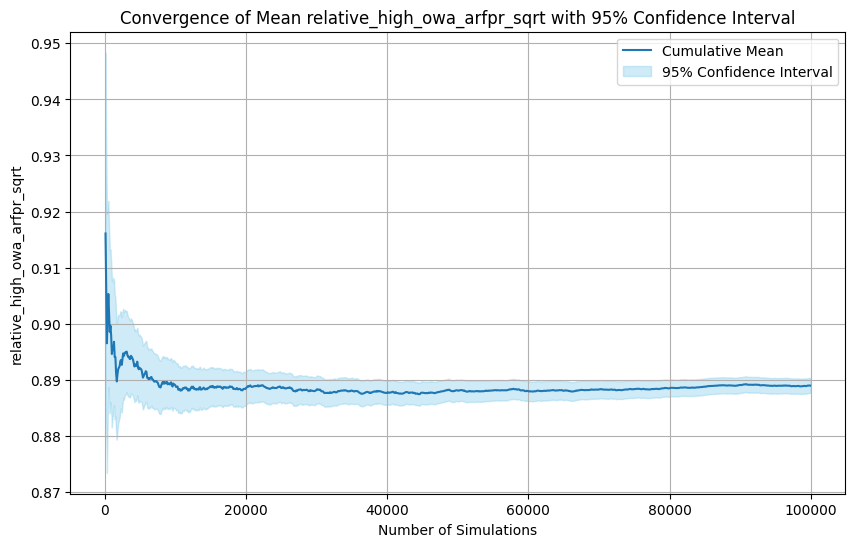

In [ ]:
test_convergence_from_config('all_arfpr')

### All MPR AHP Transformation Functions
The mean converges at around 40k simulations.

========= Convergence Test for all_mpr_ahp ===============
============== Relative Mean =================


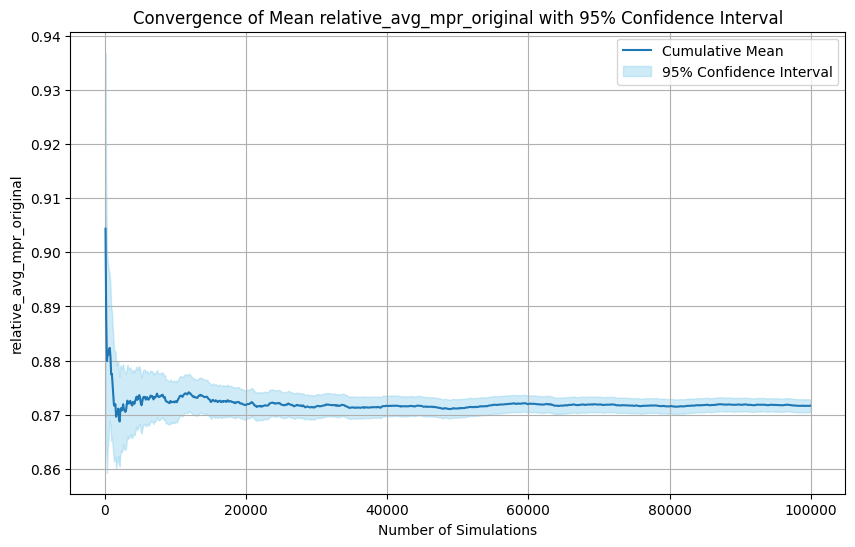

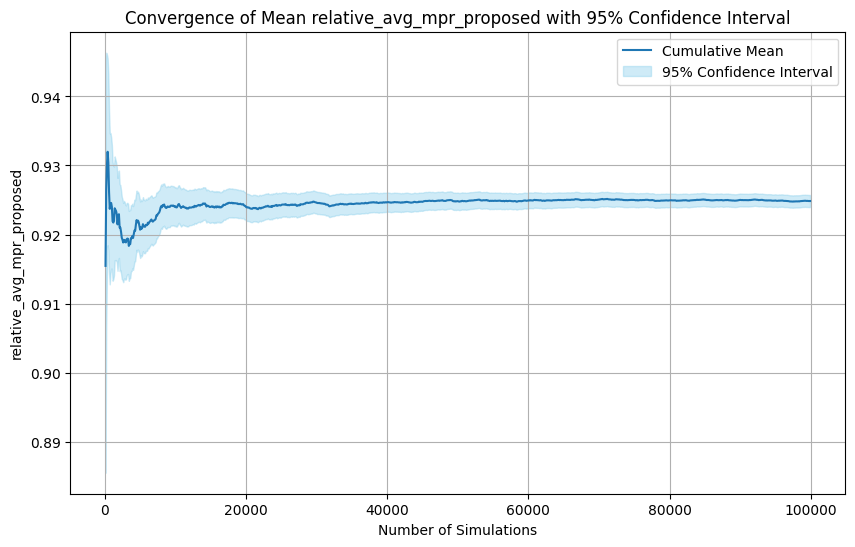

============ Relative High OWA ===============


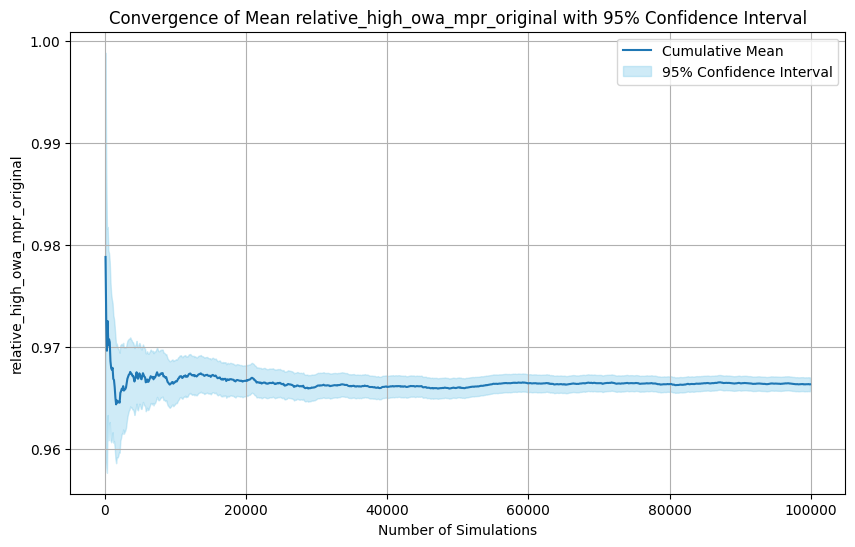

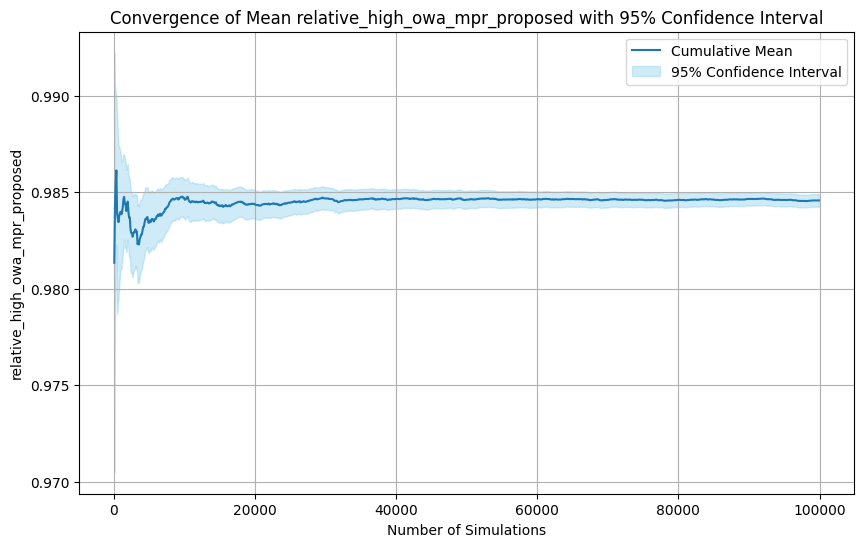

In [ ]:
test_convergence_from_config('all_mpr_ahp')

### All MPR All Values Transformation Functions
The mean converges at around 40k simulations.

========= Convergence Test for all_mpr_all_values ===============
============== Relative Mean =================


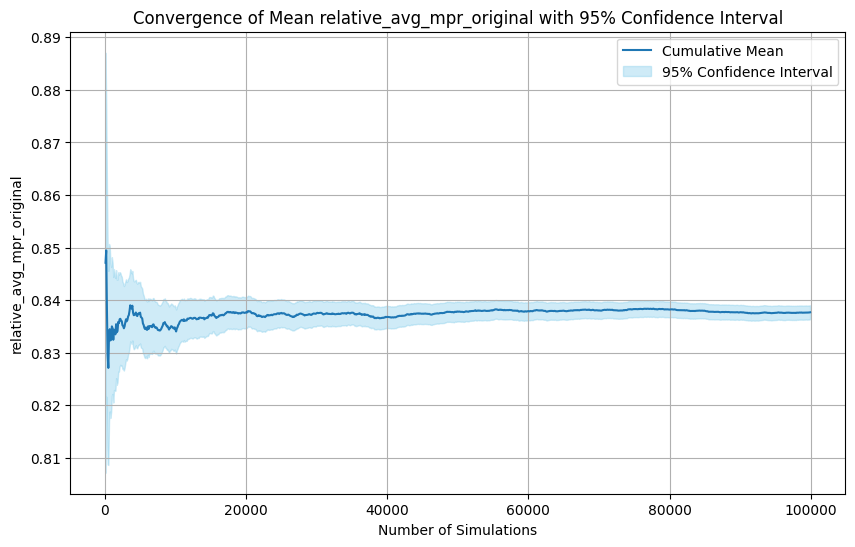

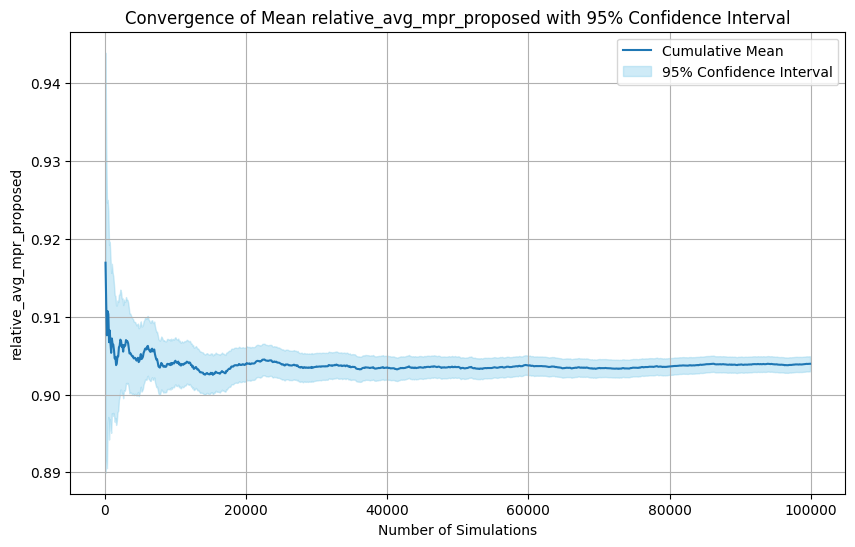

============ Relative High OWA ===============


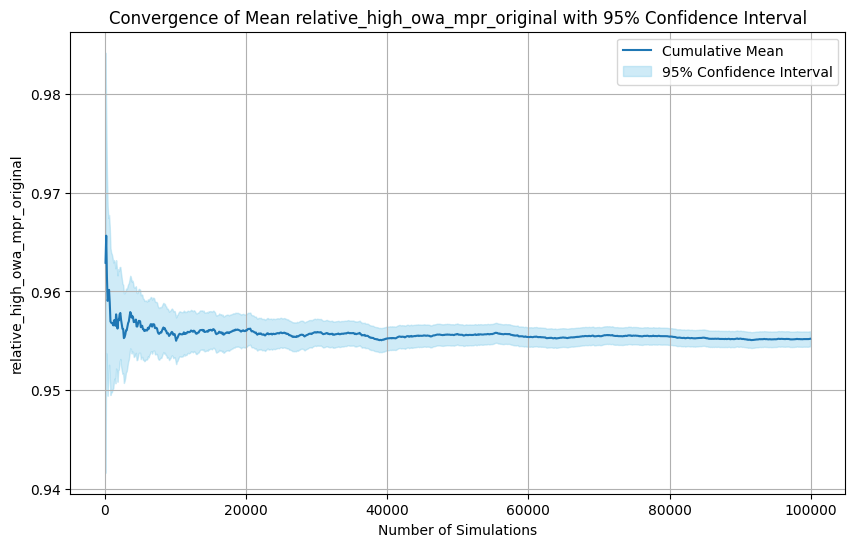

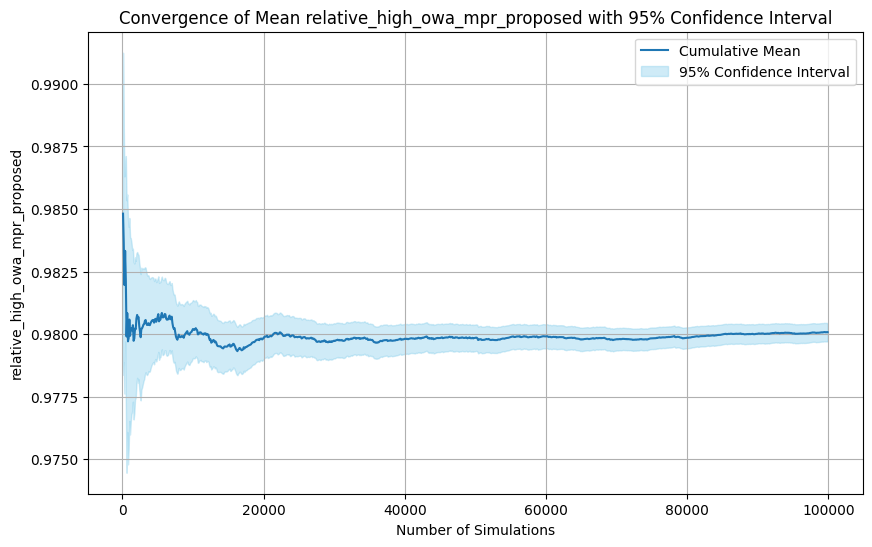

In [ ]:
test_convergence_from_config('all_mpr_all_values')

### All OA Transformation Functions
The mean converges at around 40k simulations.

========= Convergence Test for all_oa ===============
============== Relative Mean =================


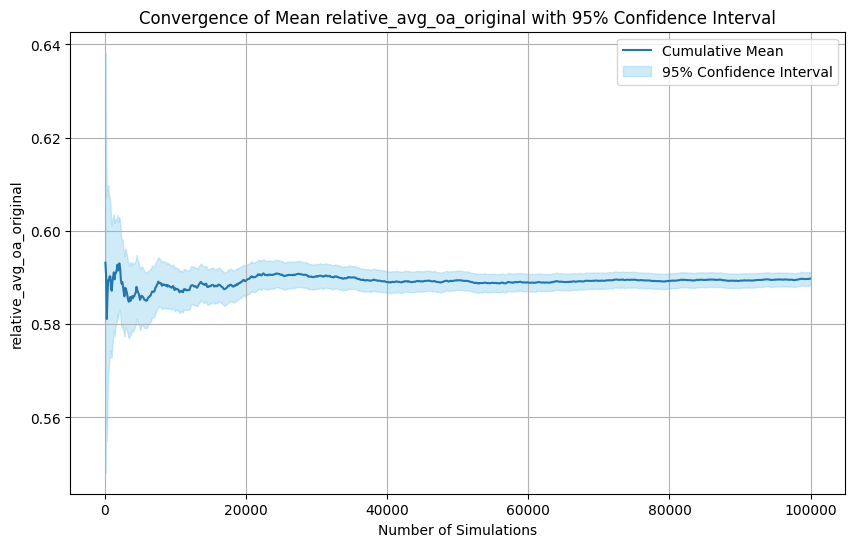

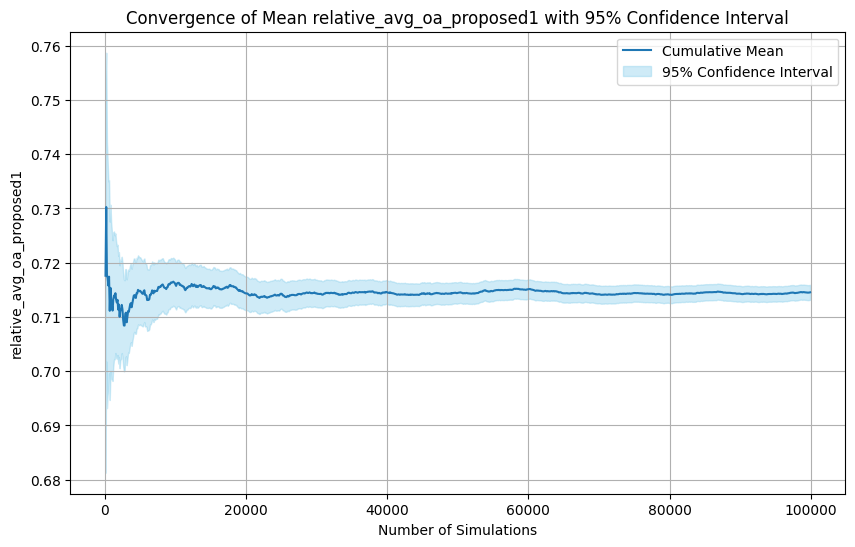

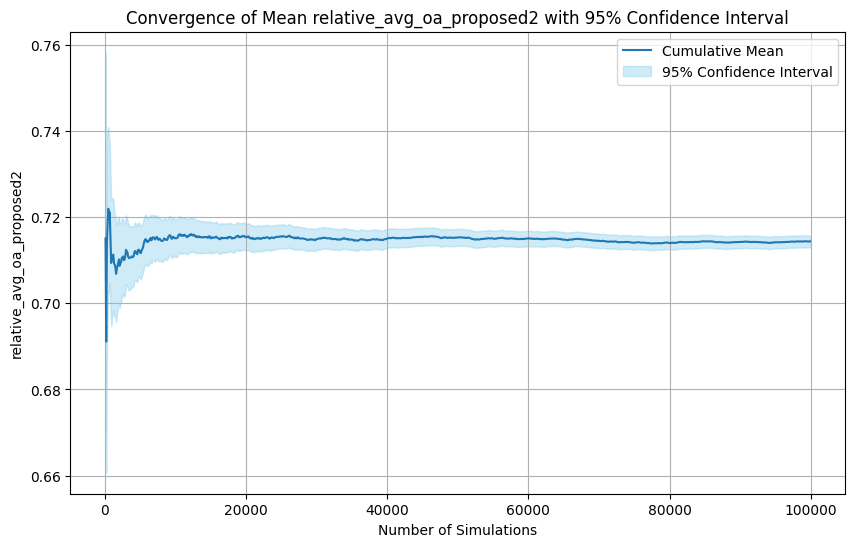

============ Relative High OWA ===============


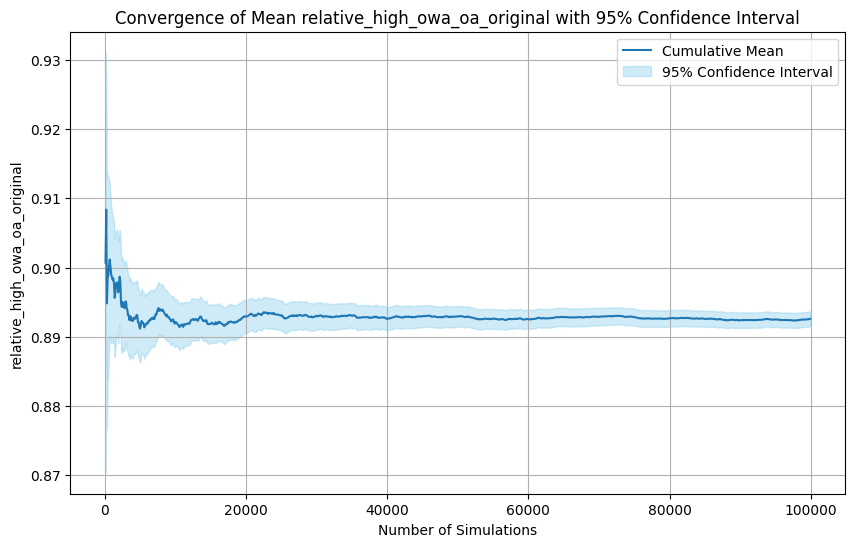

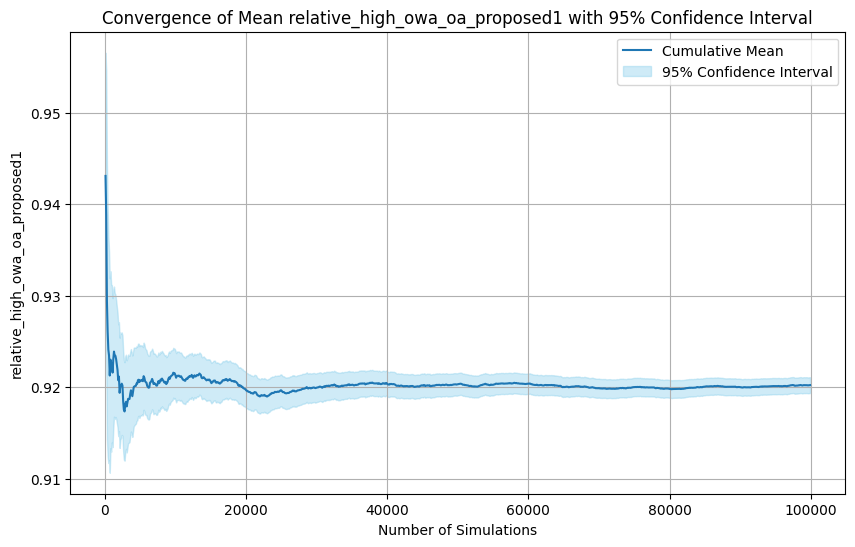

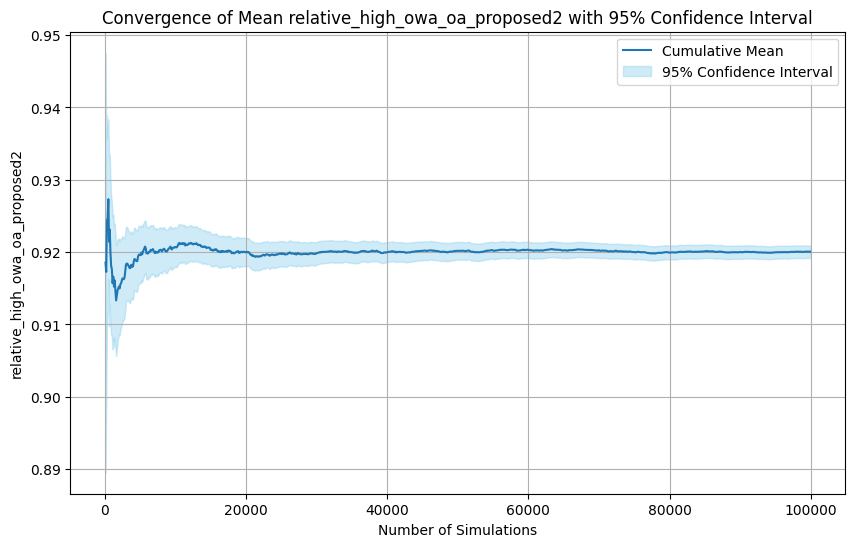

In [ ]:
test_convergence_from_config('all_oa')

### All RN Fixed Scale Transformation Functions
The mean converges at around 60k simulations.

========= Convergence Test for all_rn_fixed_scale ===============
============== Relative Mean =================


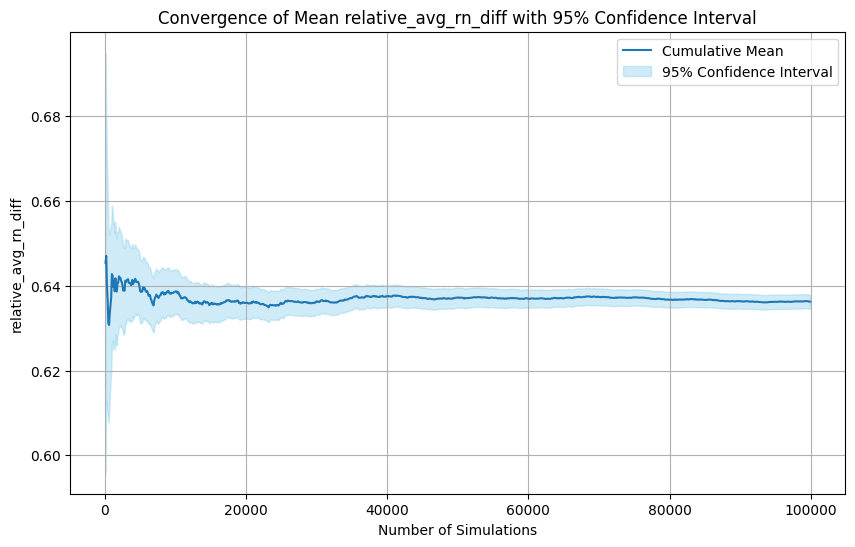

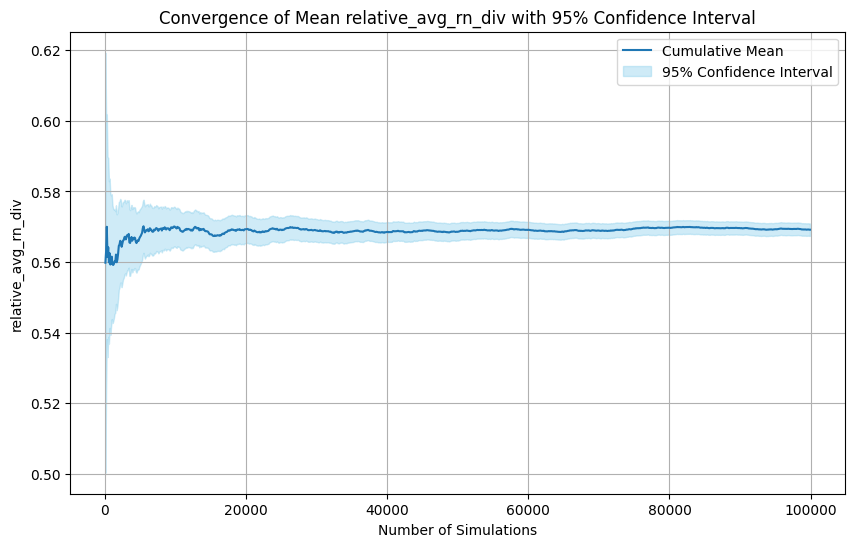

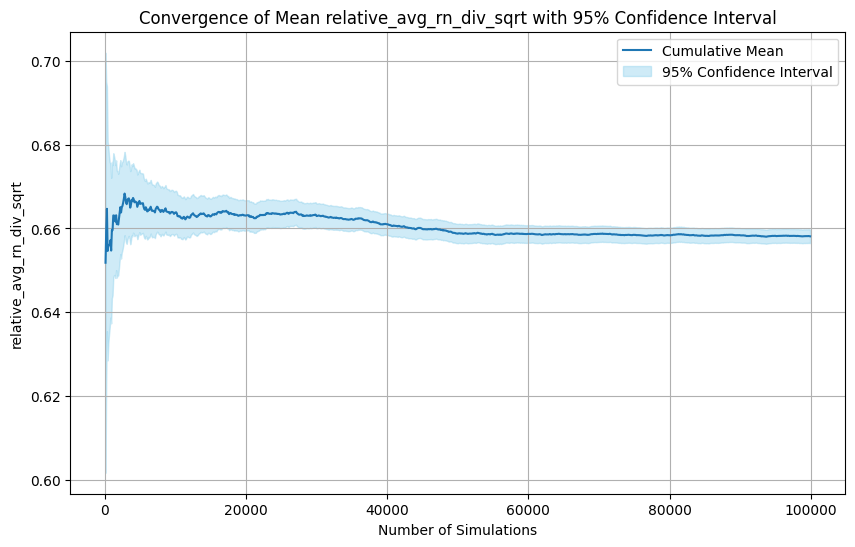

============ Relative High OWA ===============


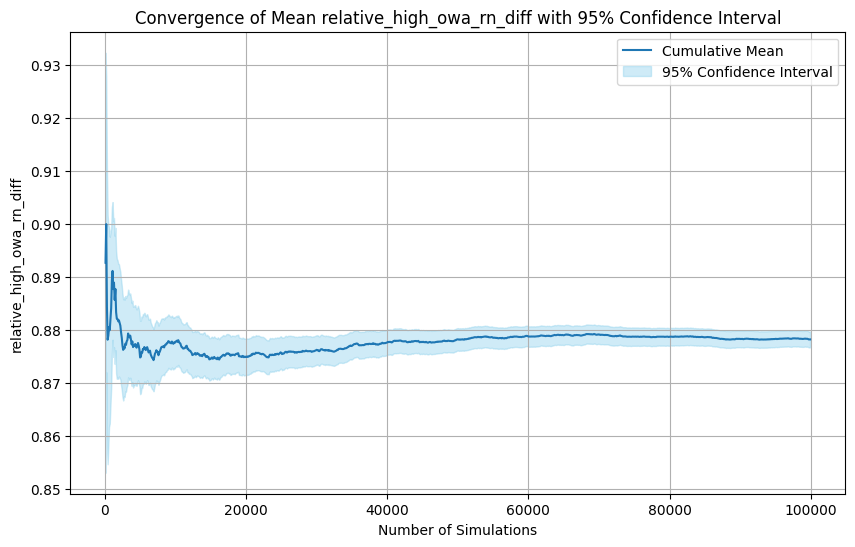

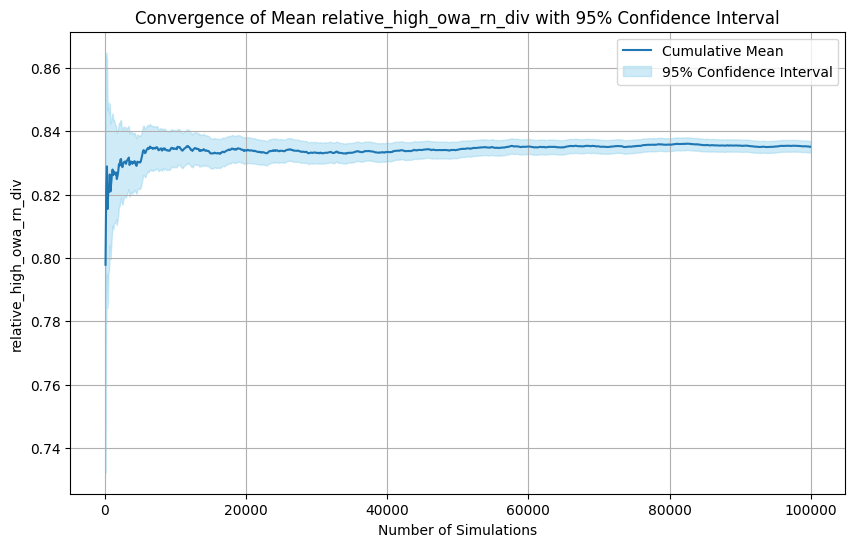

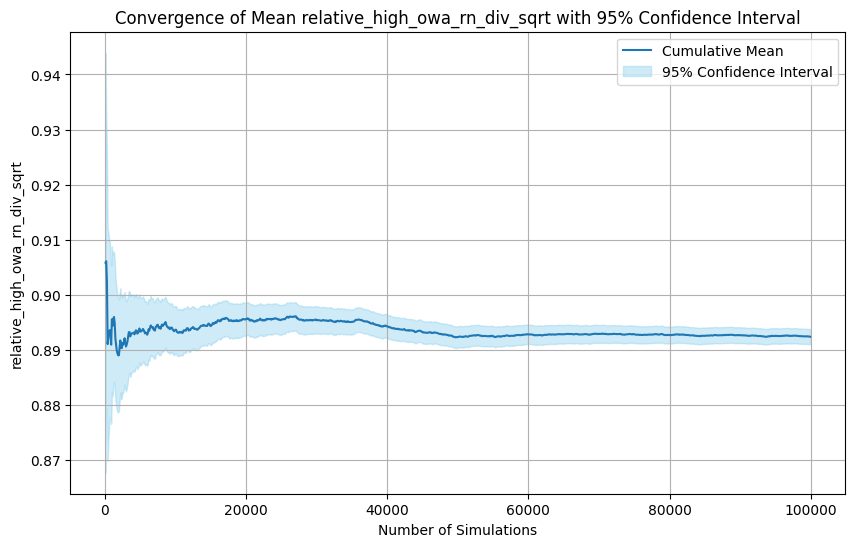

In [ ]:
test_convergence_from_config('all_rn_fixed_scale')

### All RN From Data Transformation Functions
The mean converges at around 60k simulations.

========= Convergence Test for all_rn_from_data ===============
============== Relative Mean =================


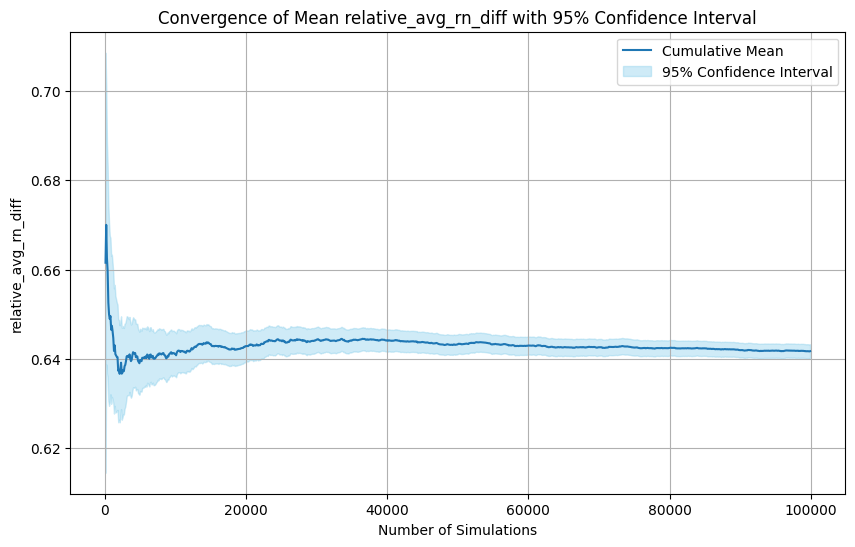

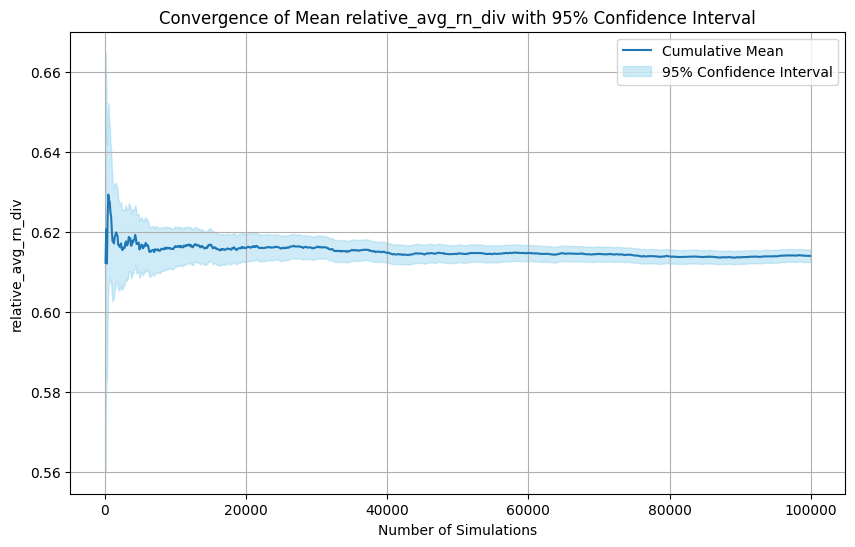

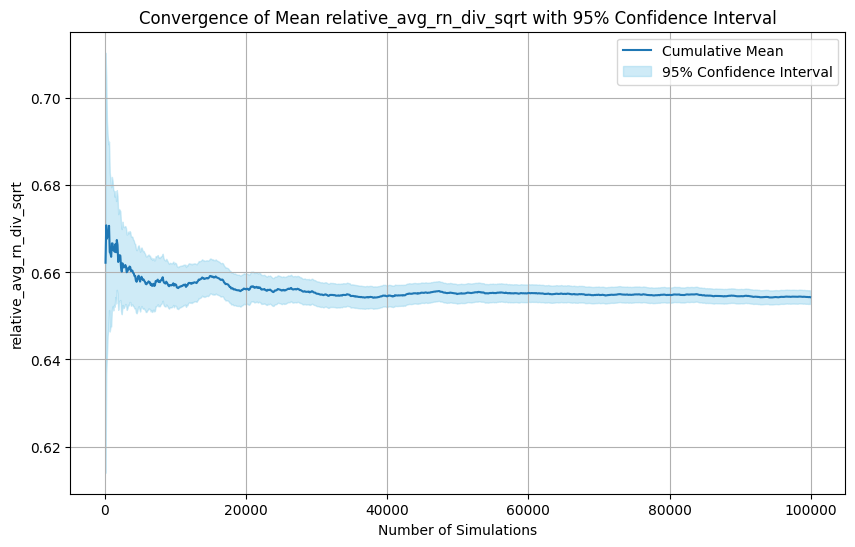

============ Relative High OWA ===============


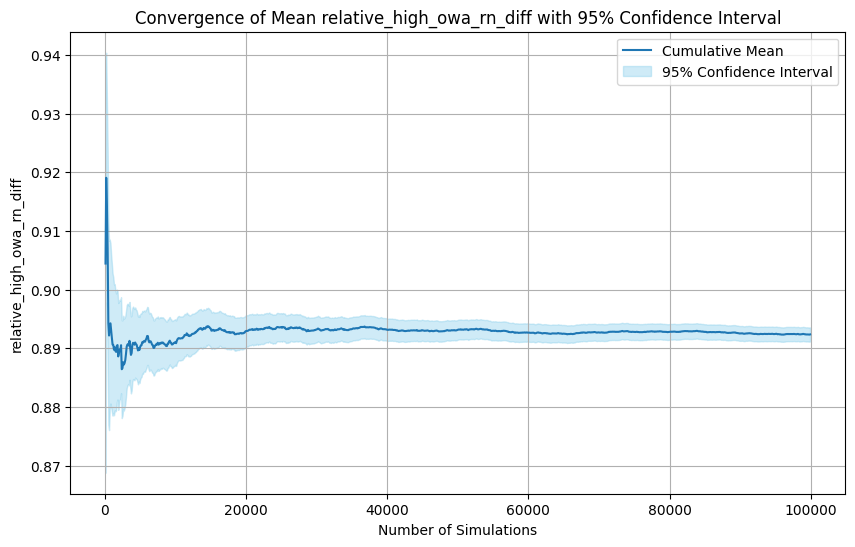

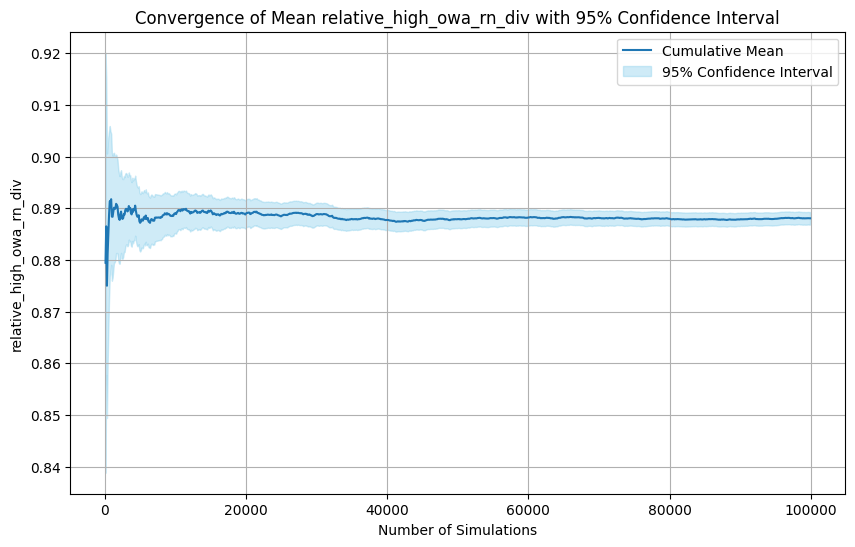

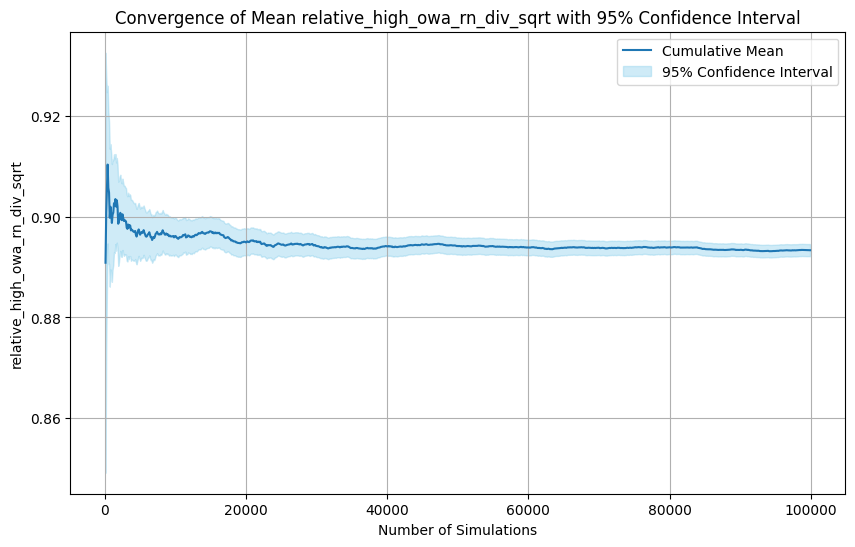

In [ ]:
test_convergence_from_config('all_rn_from_data')

### All UV Cardinal Transformation Functions
The mean converges at around 60k simulations.

========= Convergence Test for all_uv_cardinal ===============
============== Relative Mean =================


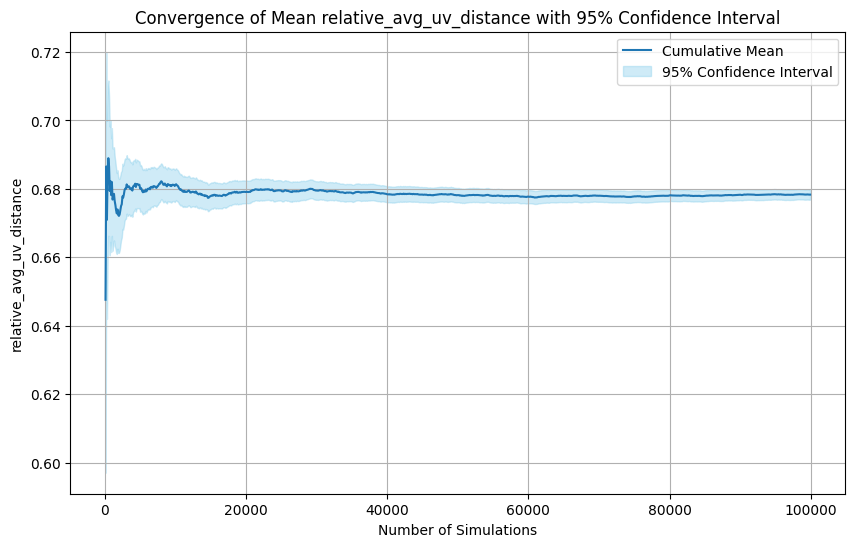

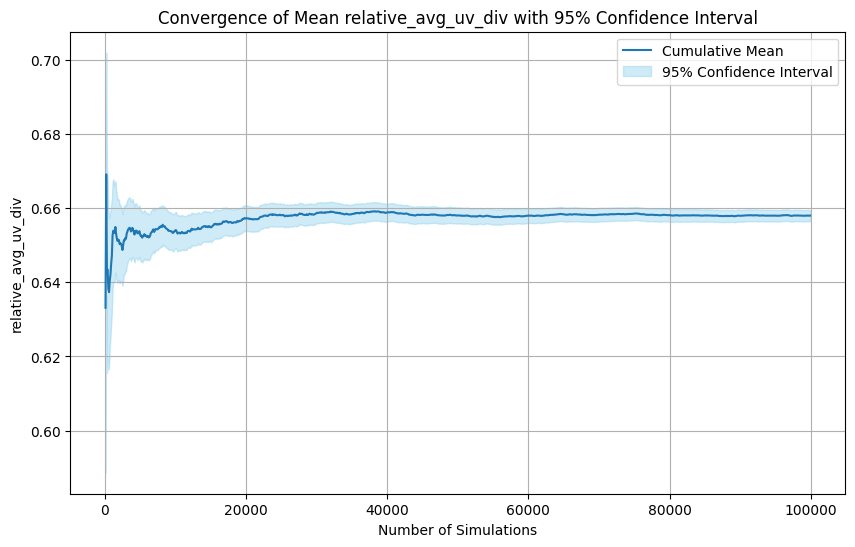

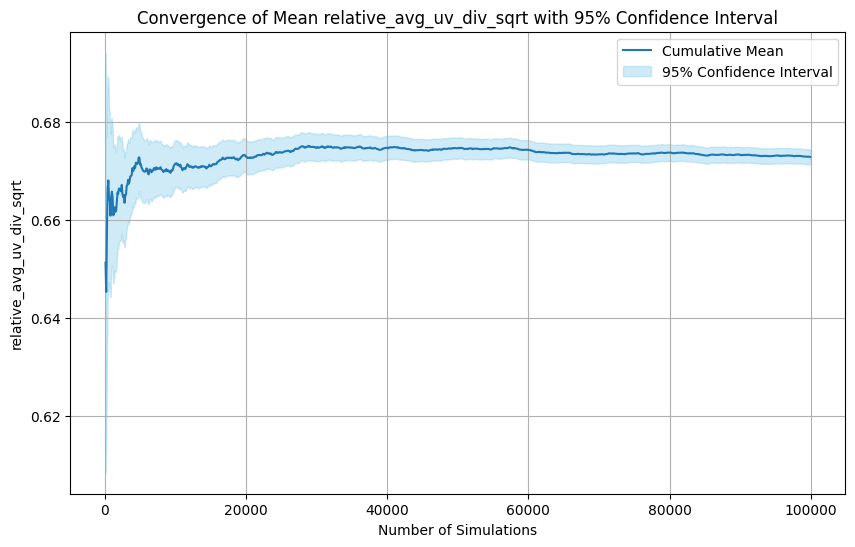

============ Relative High OWA ===============


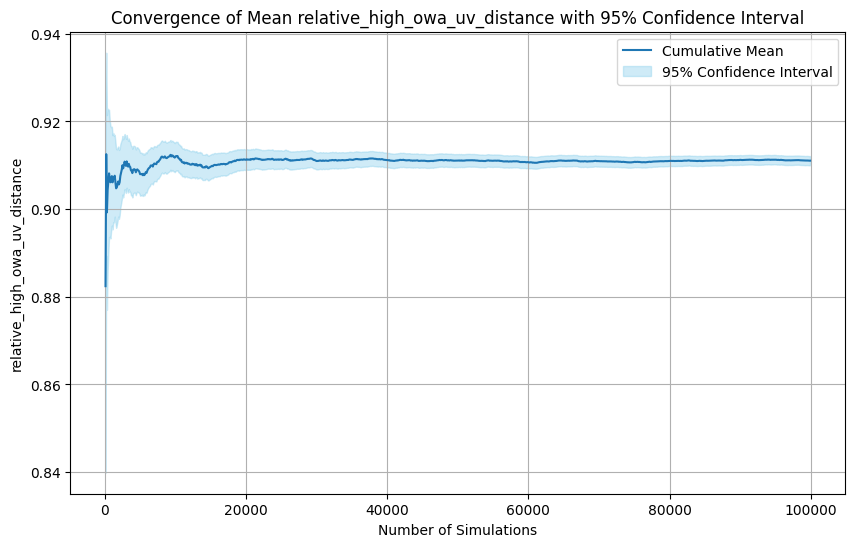

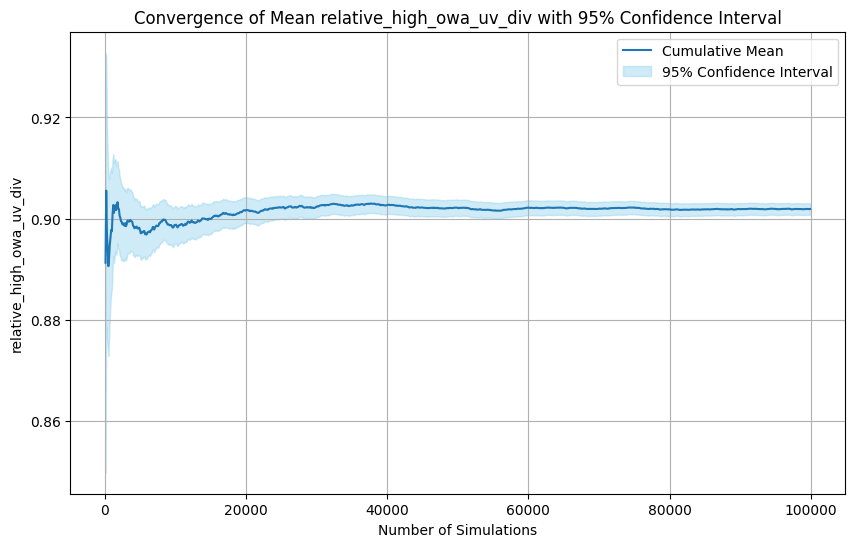

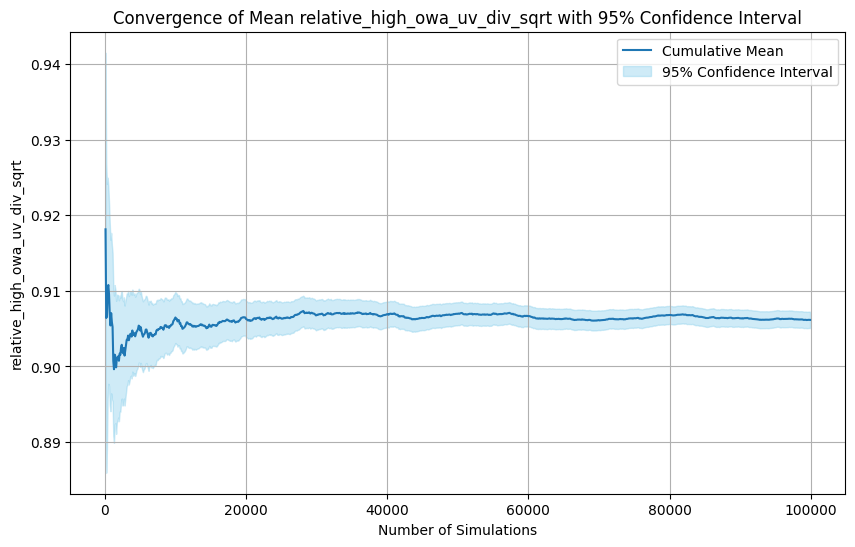

In [ ]:
test_convergence_from_config('all_uv_cardinal')

### All UV Ordinal Transformation Functions
The mean converges at around 80k simulations.

========= Convergence Test for all_uv_ordinal ===============
============== Relative Mean =================


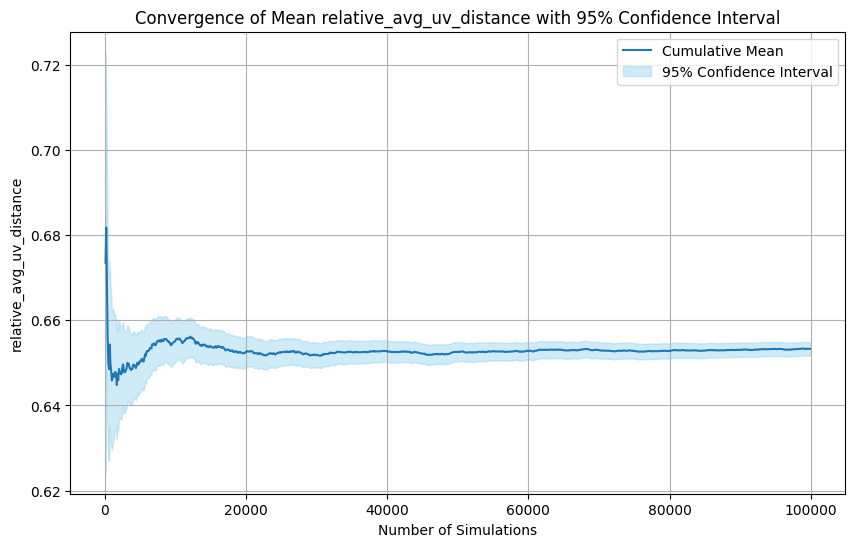

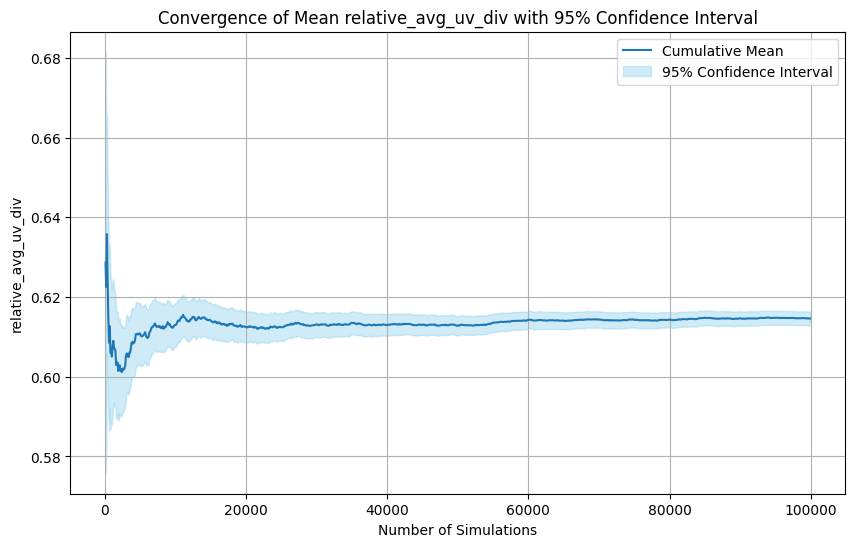

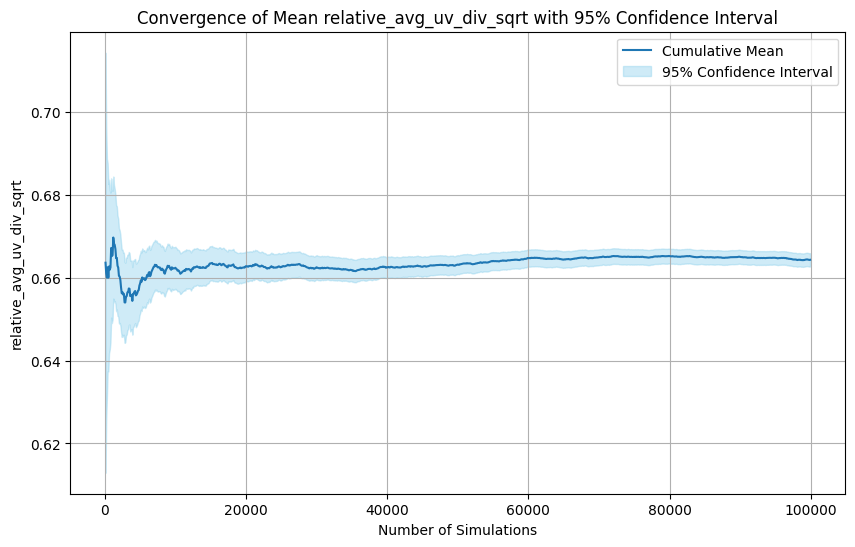

============ Relative High OWA ===============


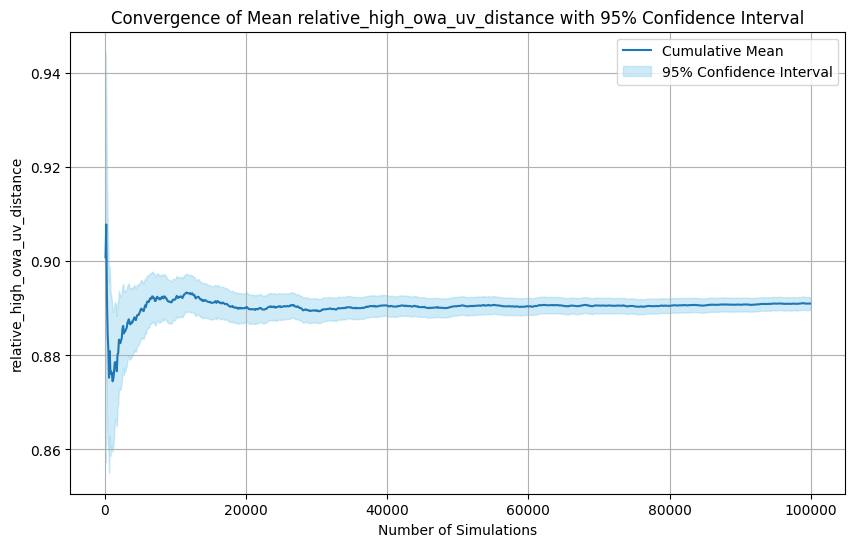

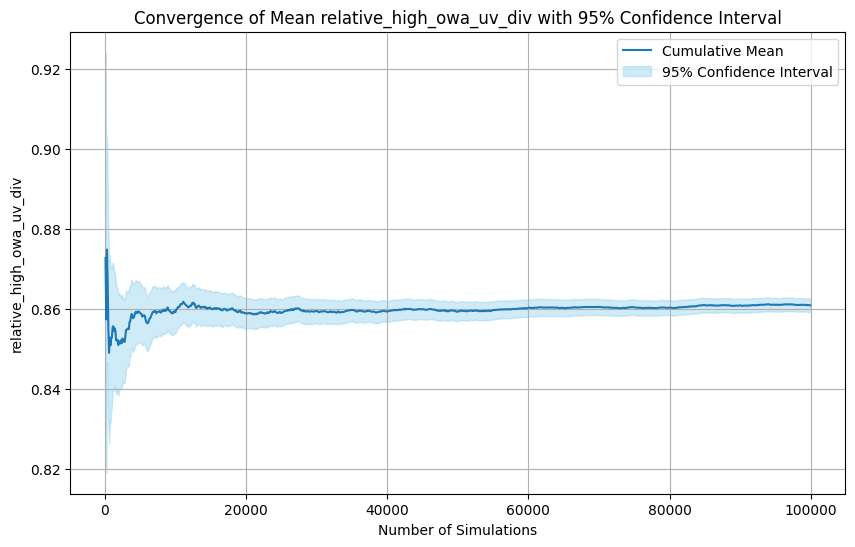

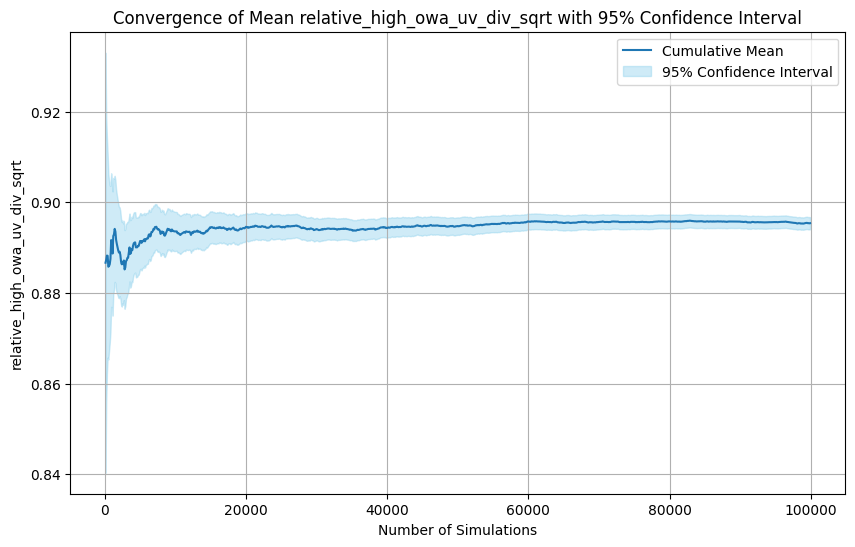

In [ ]:
test_convergence_from_config('all_uv_ordinal')

### Lowest Performing Transformation Functions
The mean converges at around 80k simulations.

========= Convergence Test for lowest_performing ===============
============== Relative Mean =================


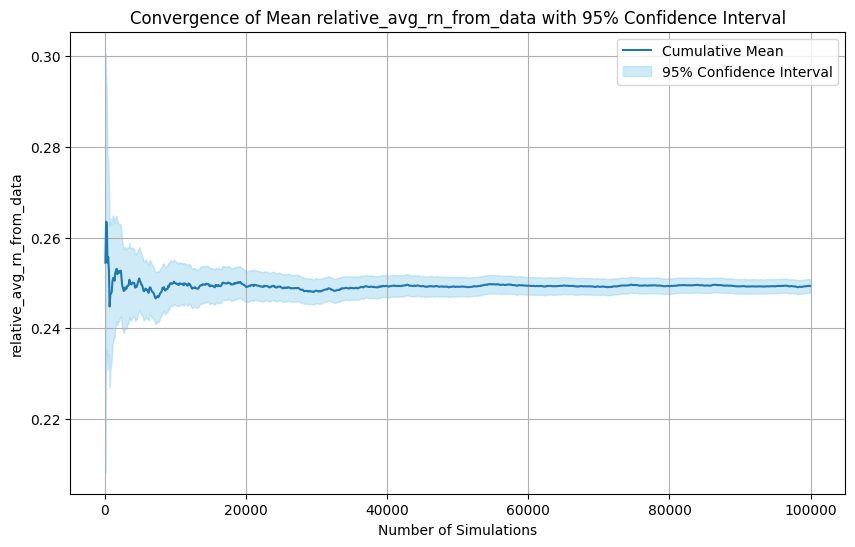

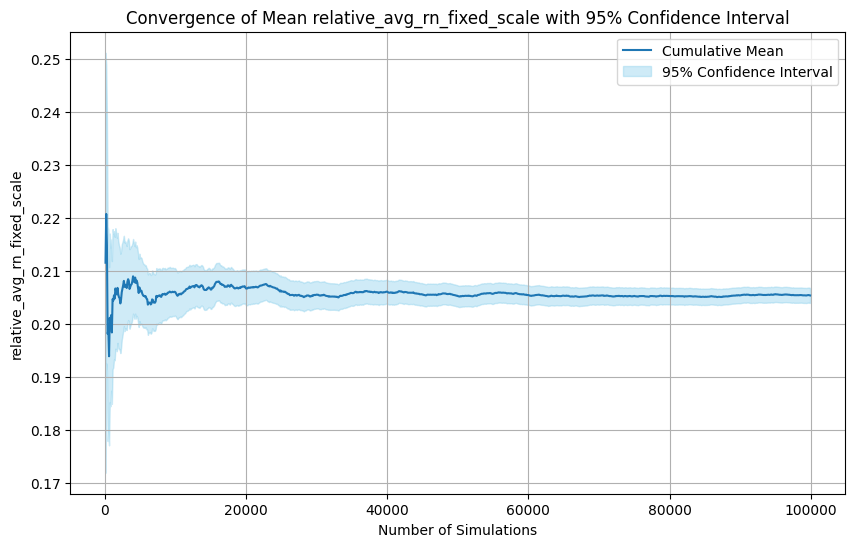

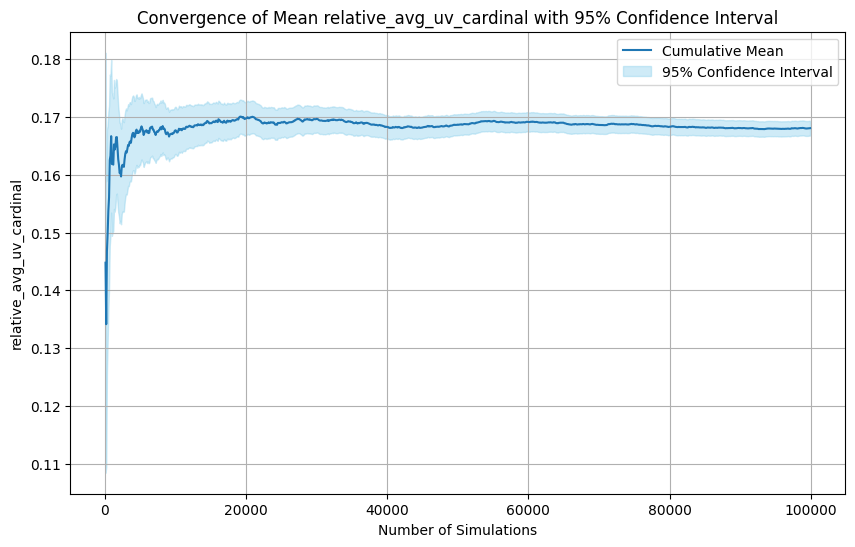

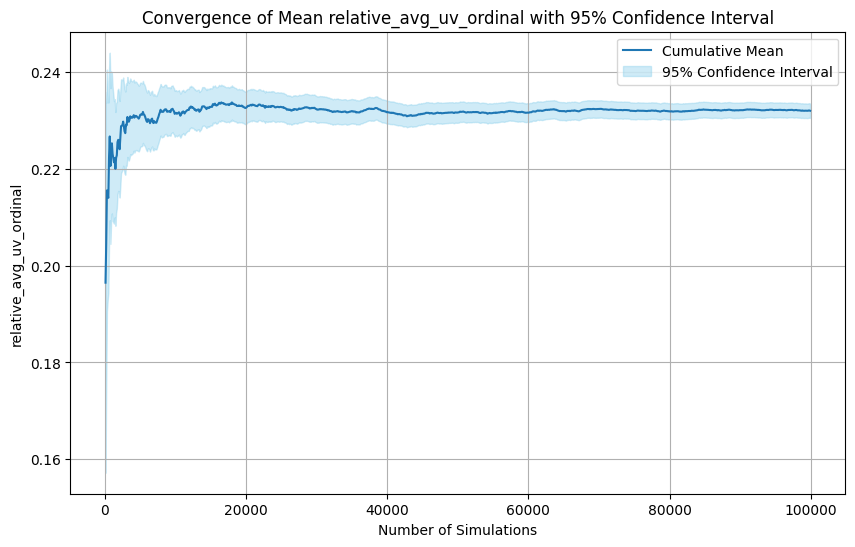

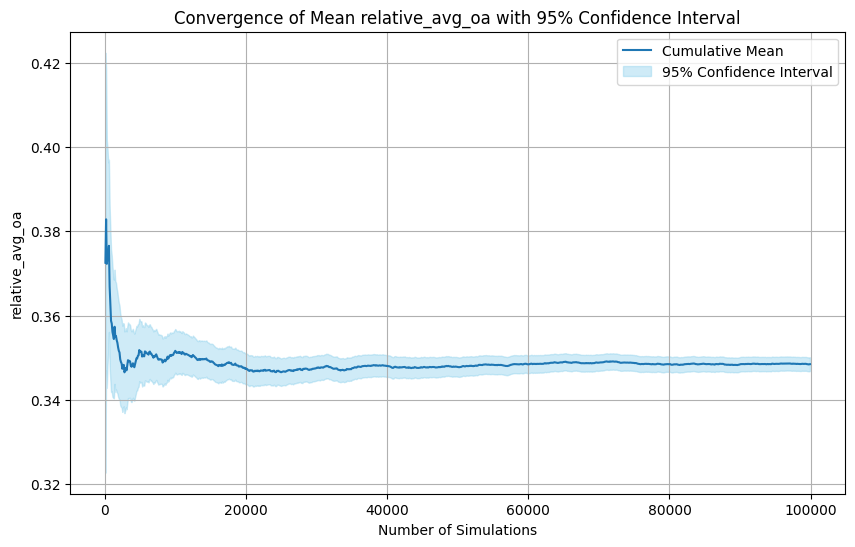

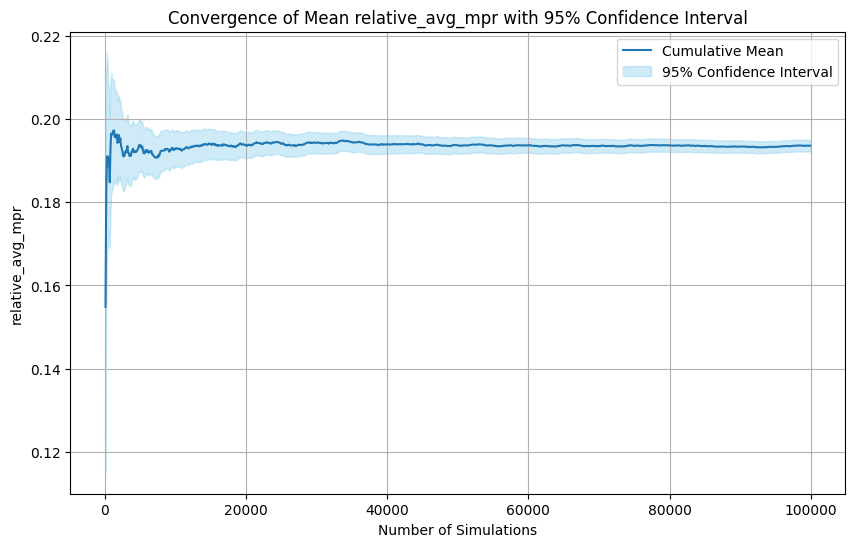

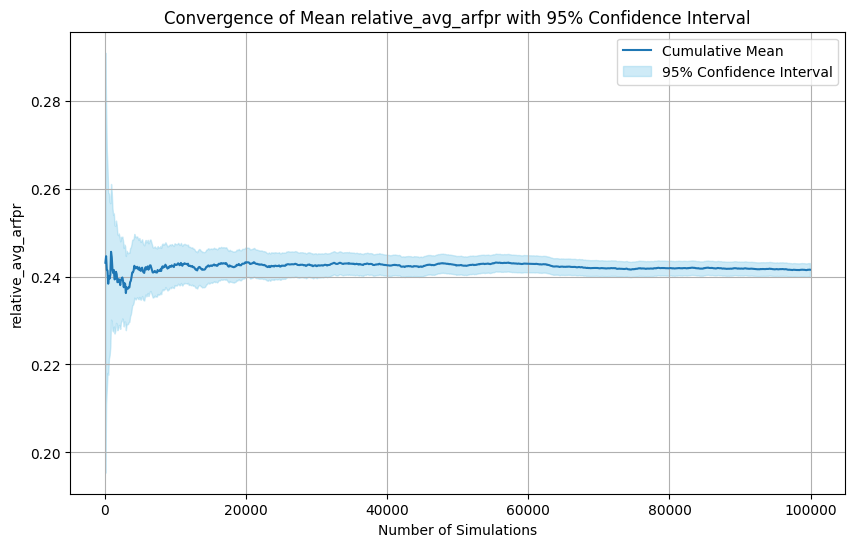

============ Relative High OWA ===============


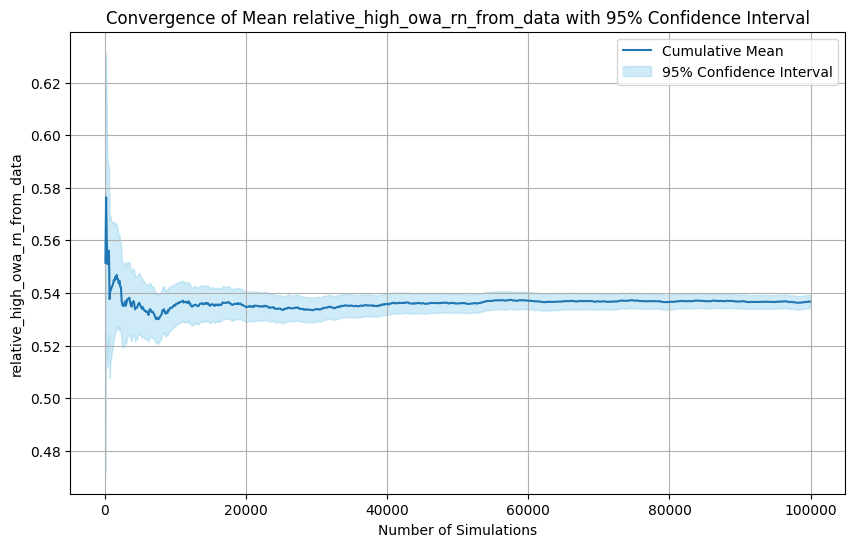

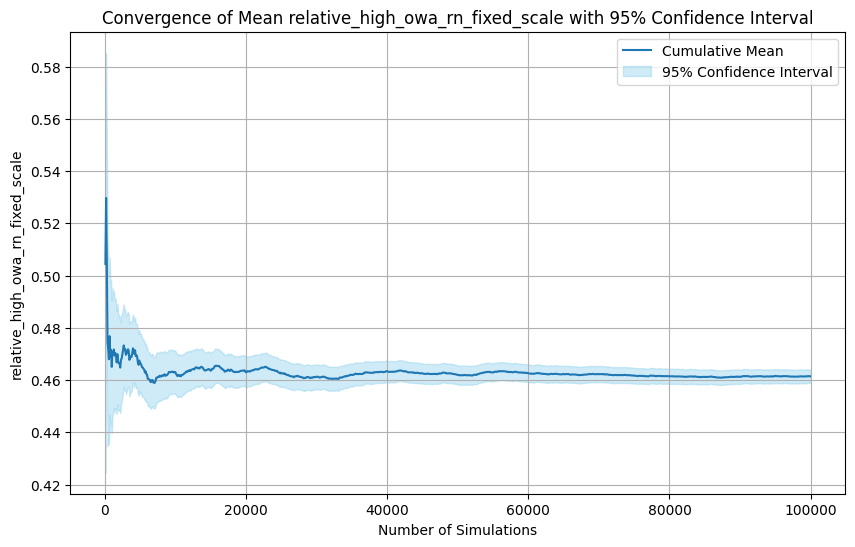

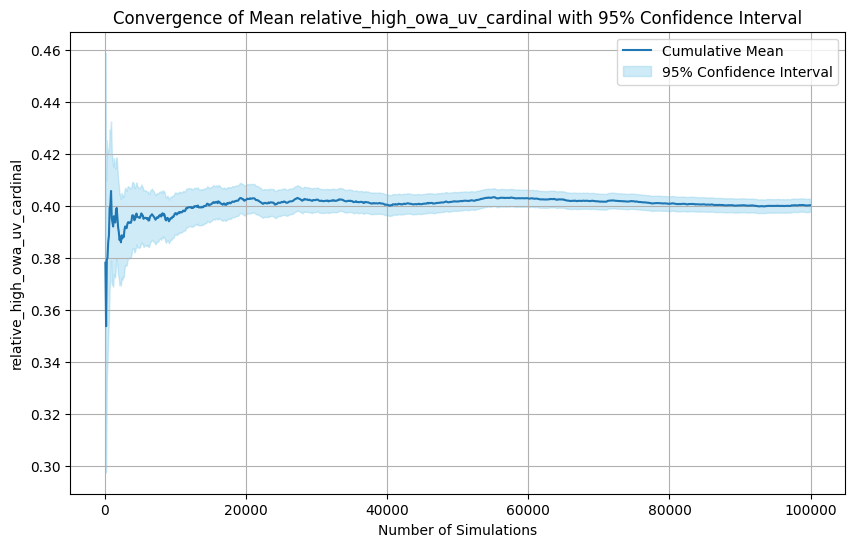

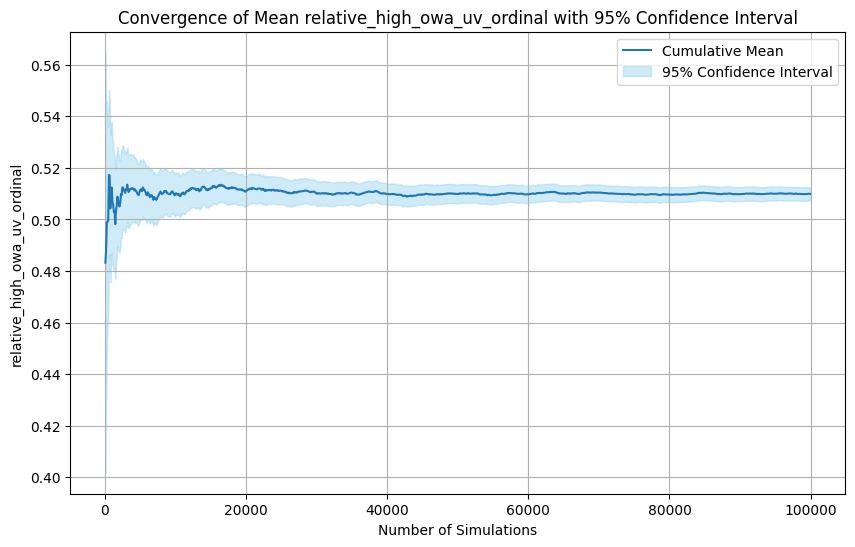

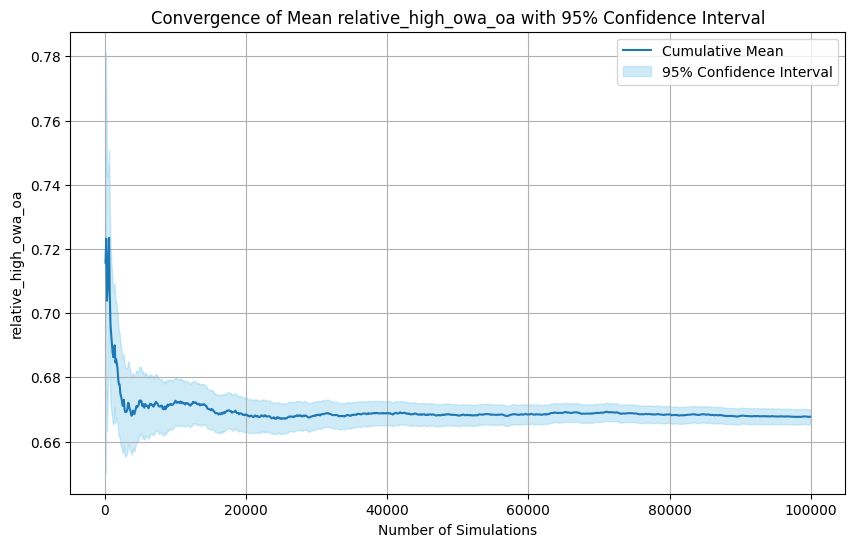

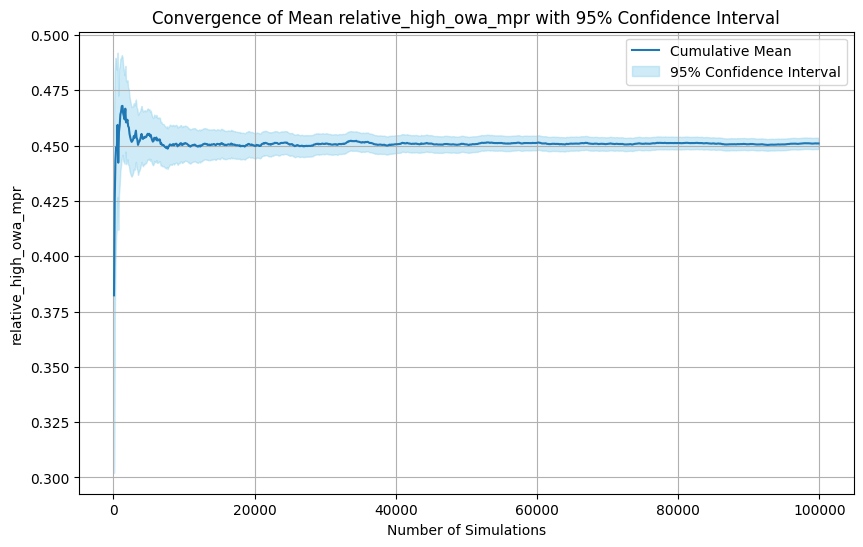

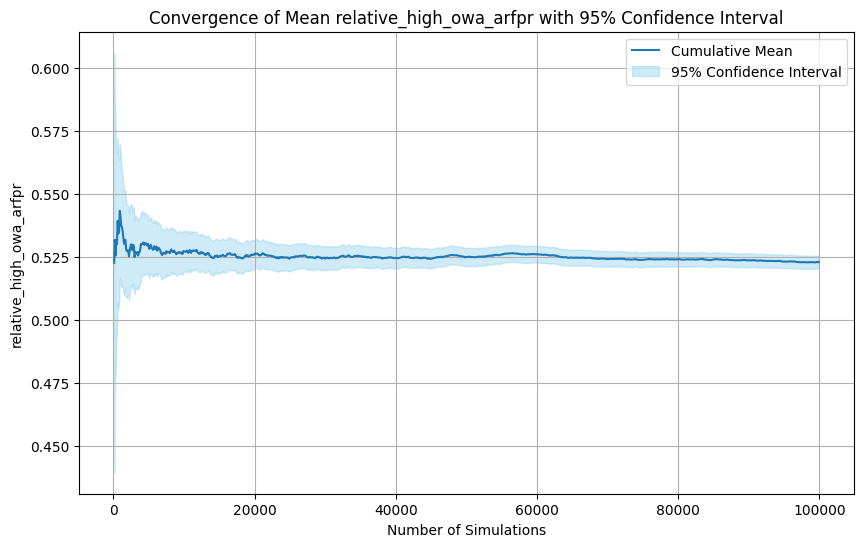

In [ ]:
test_convergence_from_config('lowest_performing')

### Highest Performing Transformation Functions
The mean converges at around 80k simulations.

========= Convergence Test for highest_performing ===============
============== Relative Mean =================


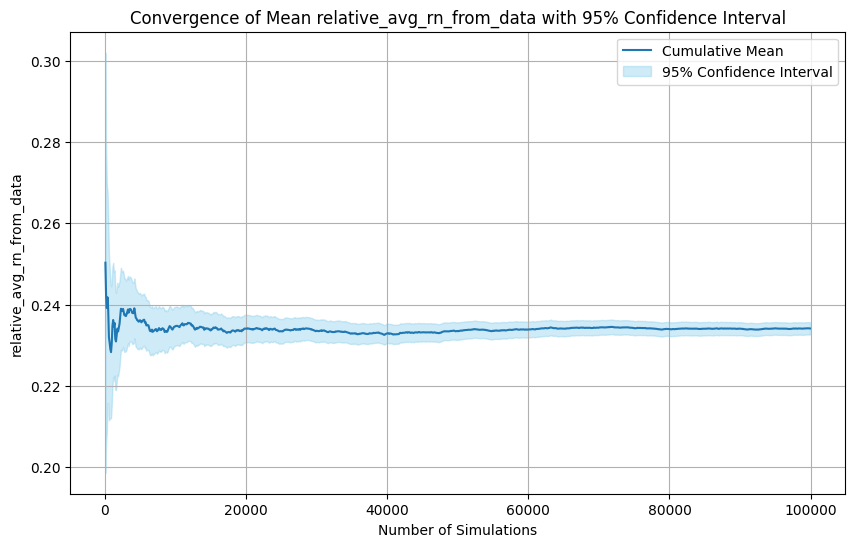

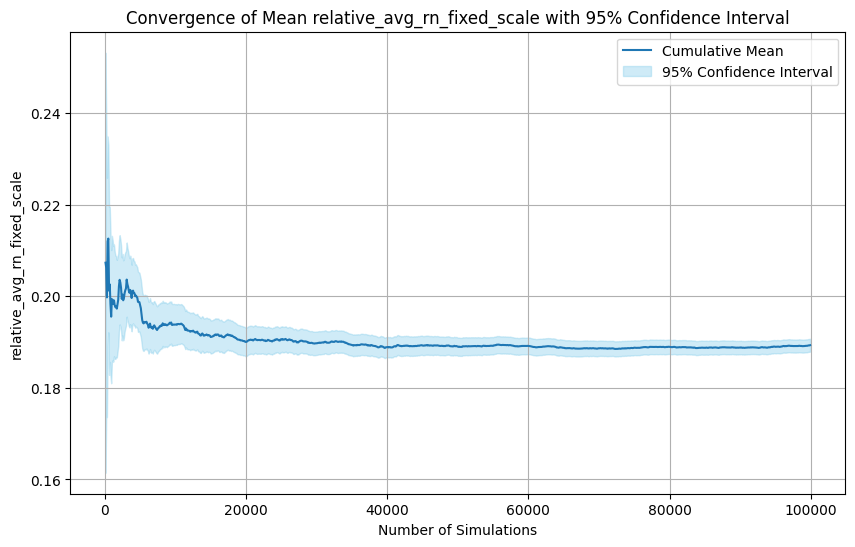

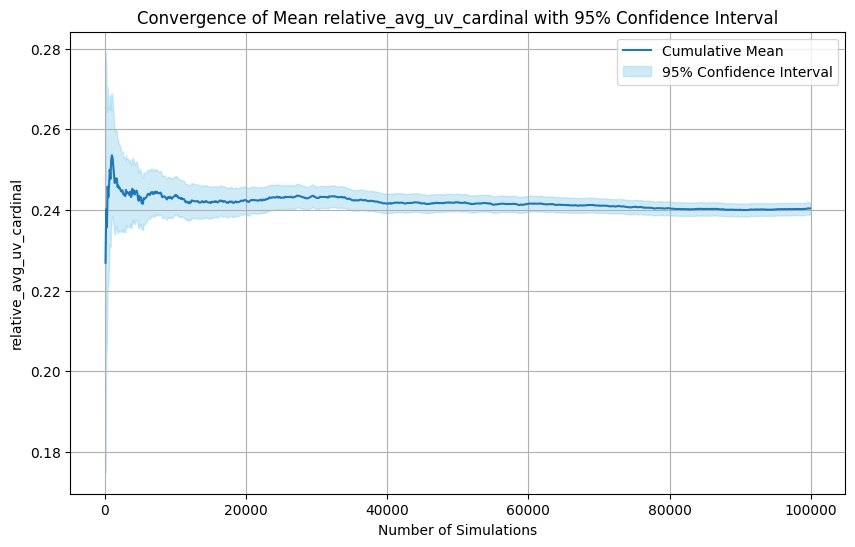

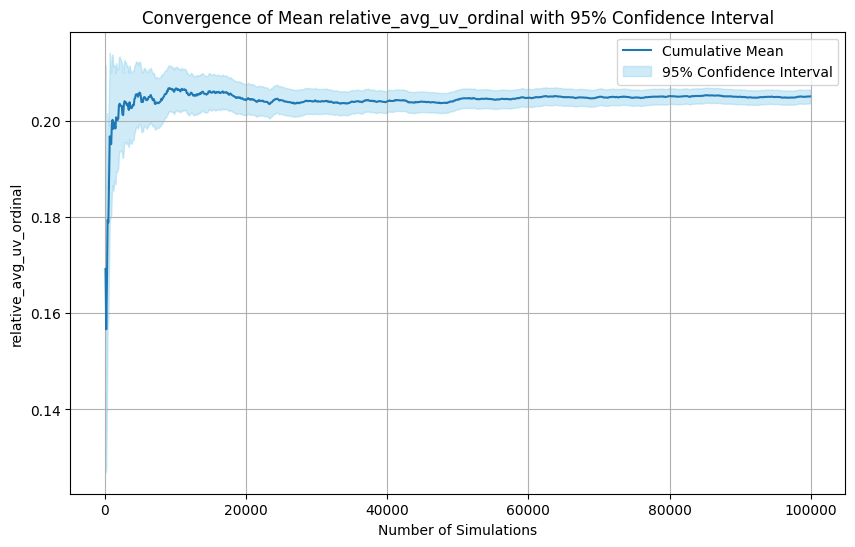

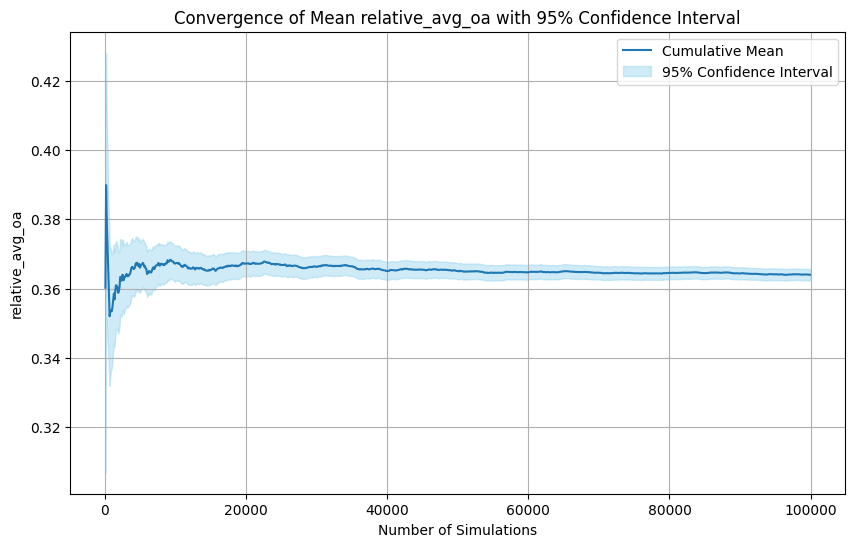

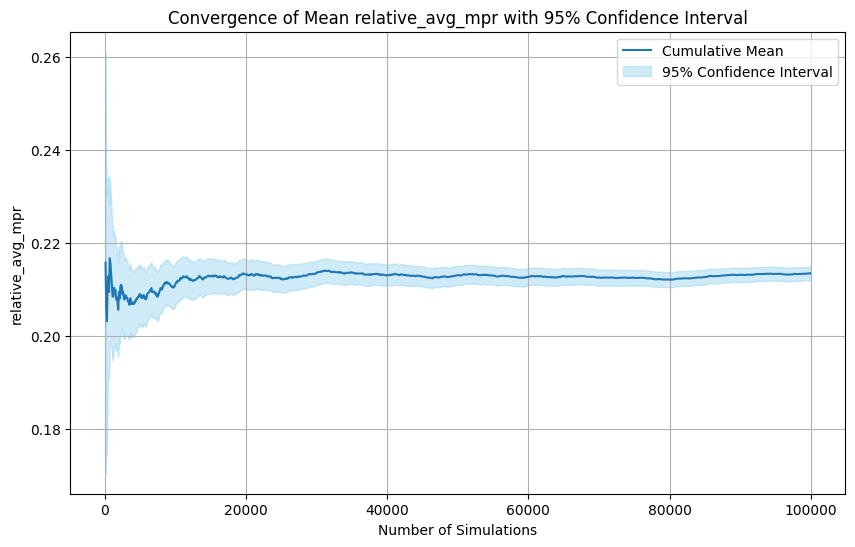

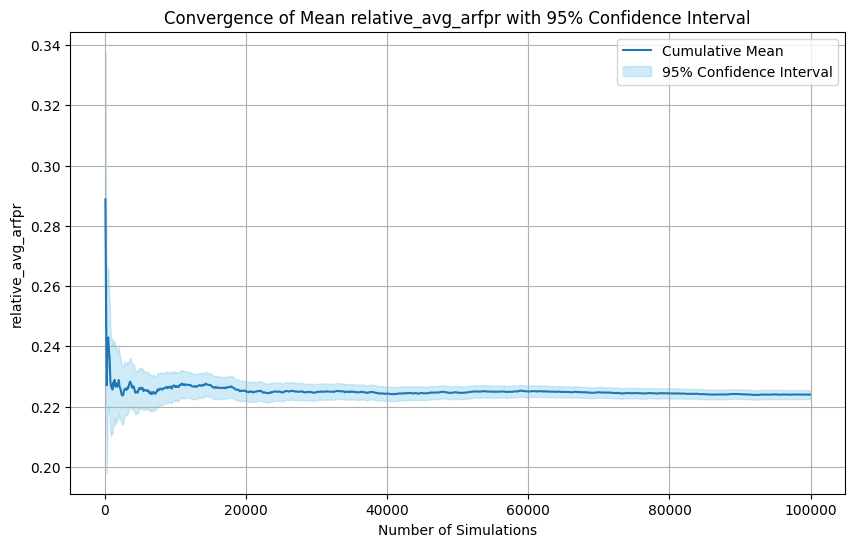

============ Relative High OWA ===============


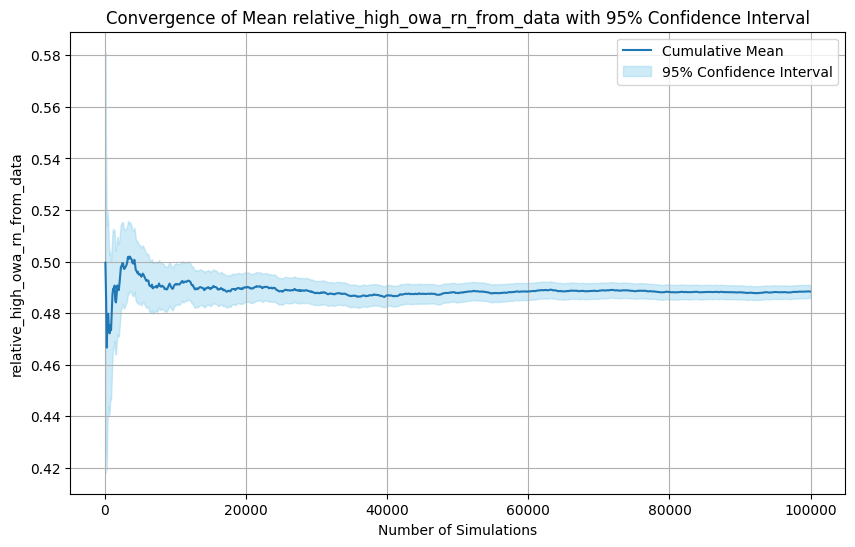

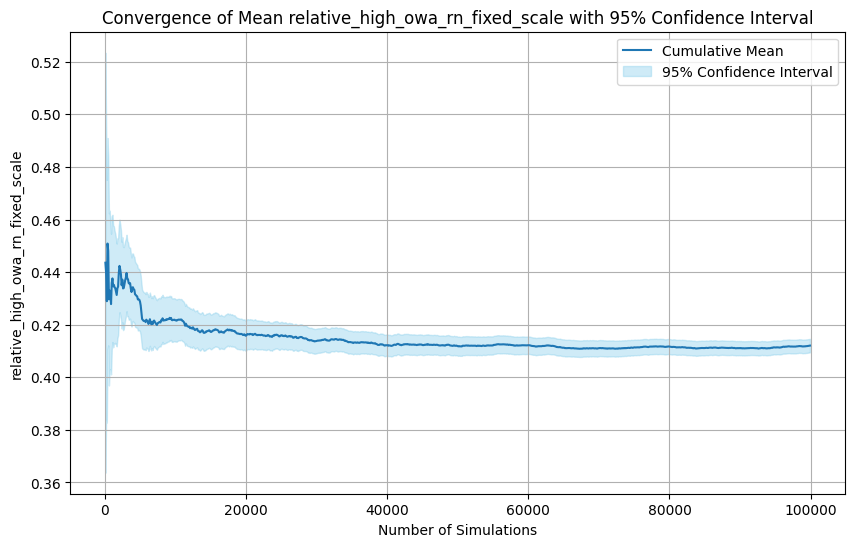

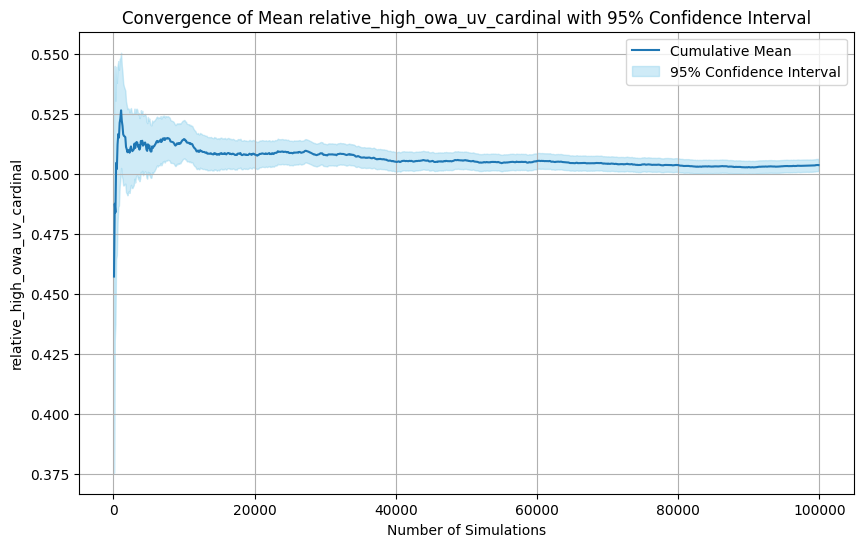

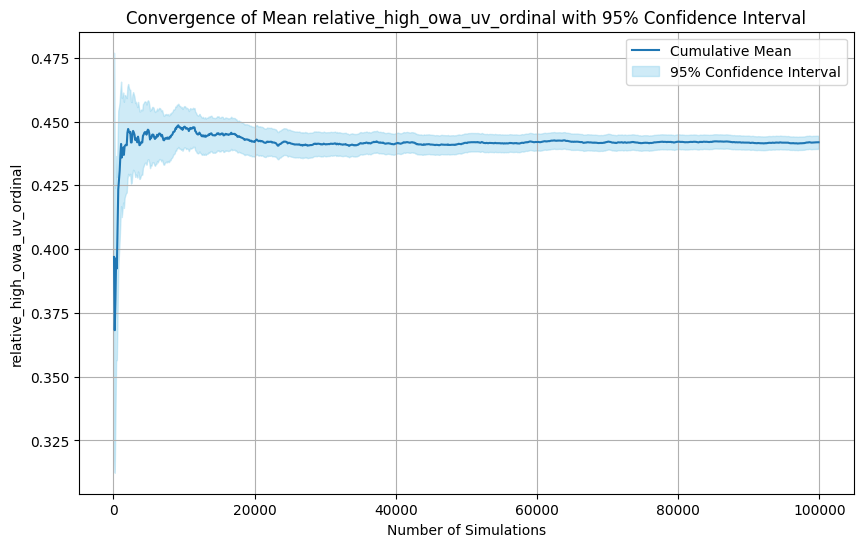

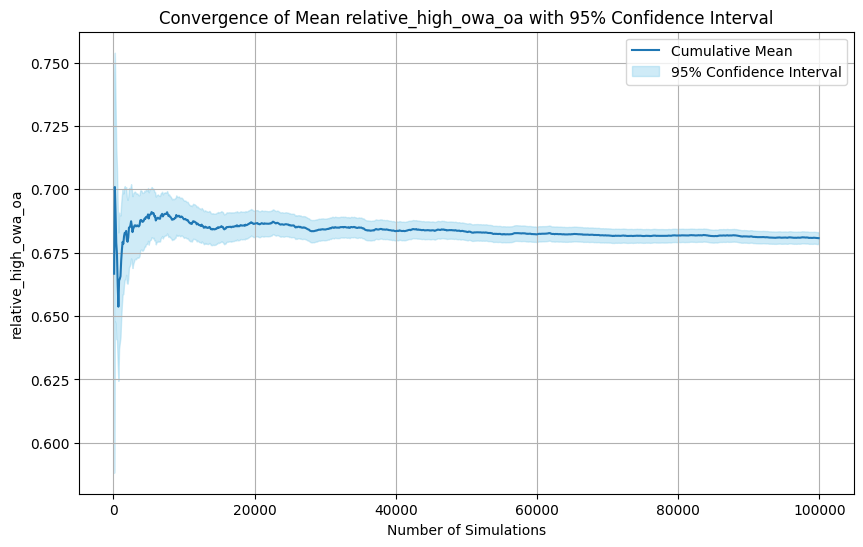

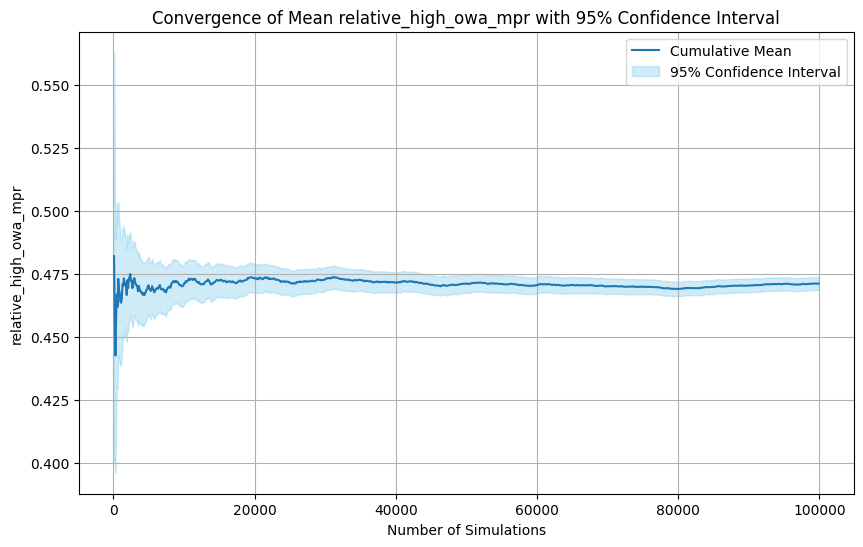

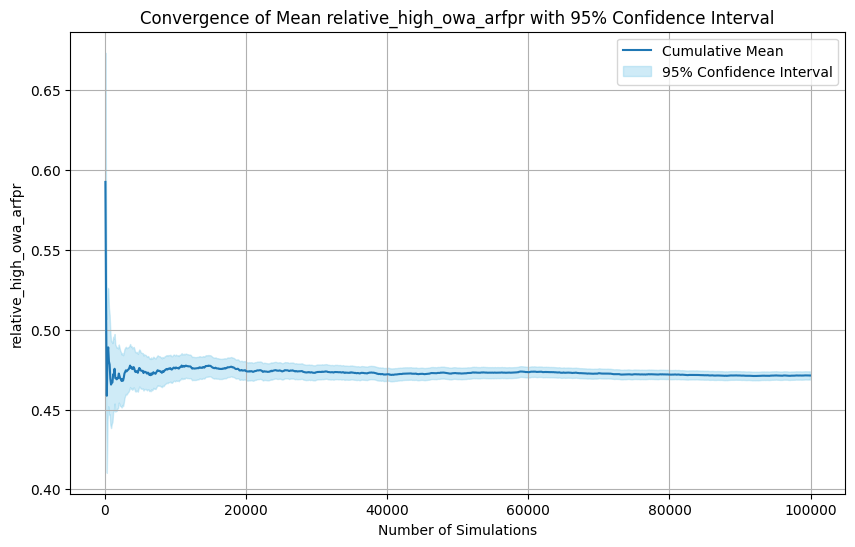

In [ ]:
test_convergence_from_config('highest_performing')

### Formats Combined Proposed Transformation Functions
The mean converges at around 80k simulations.

========= Convergence Test for formats_combined_proposed ===============
============== Relative Mean =================


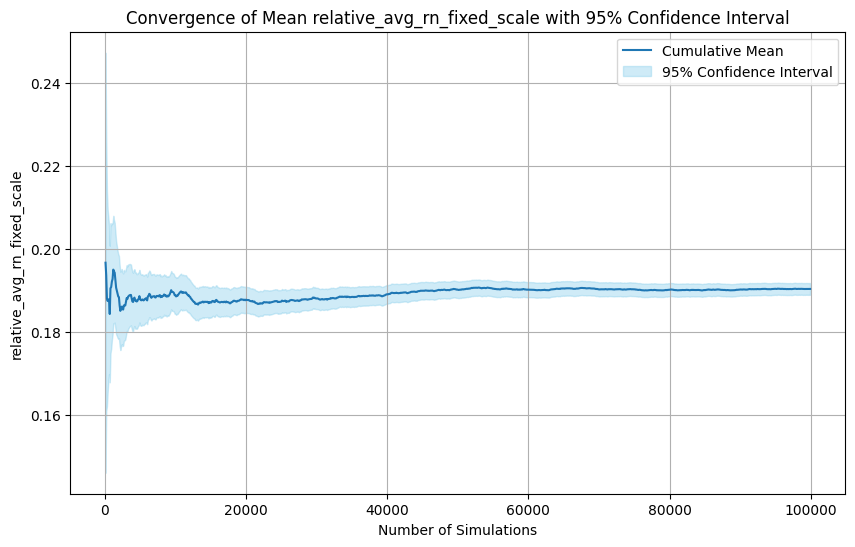

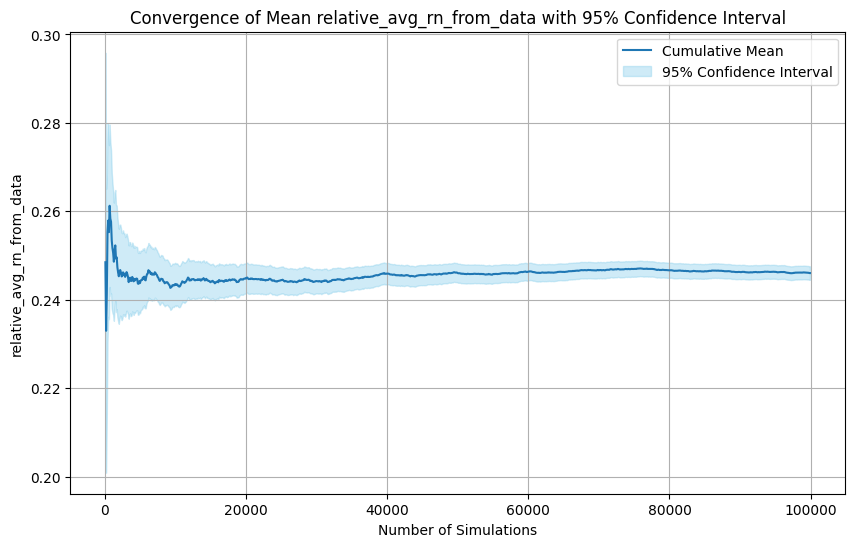

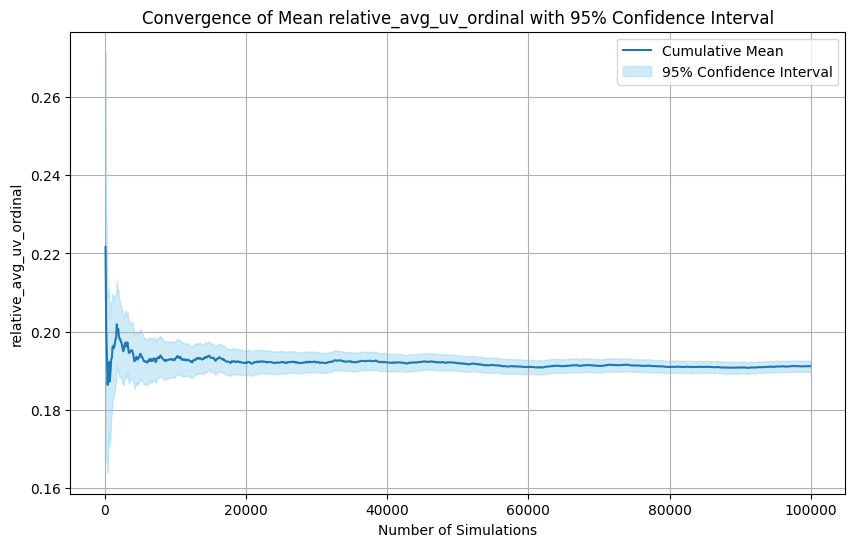

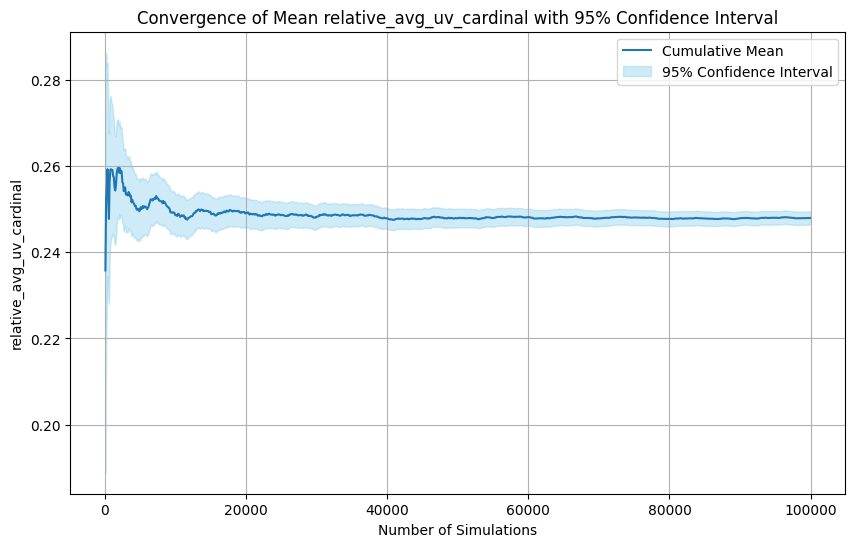

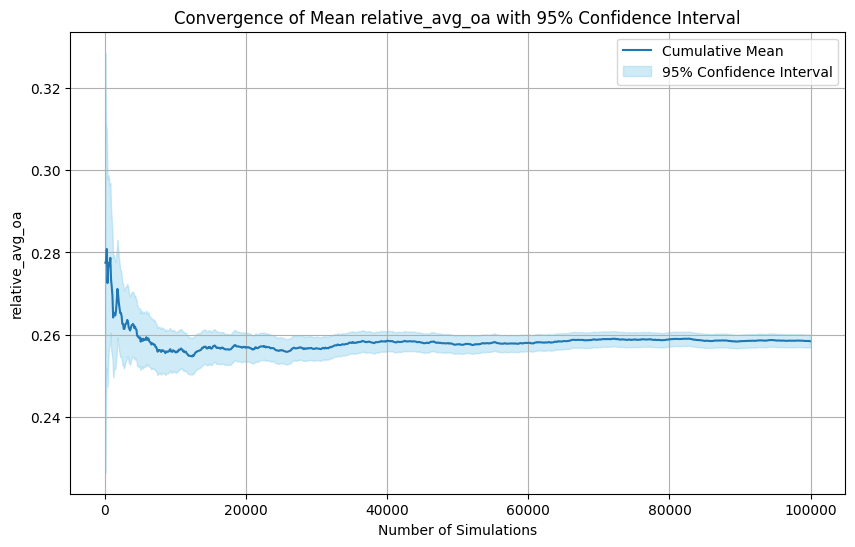

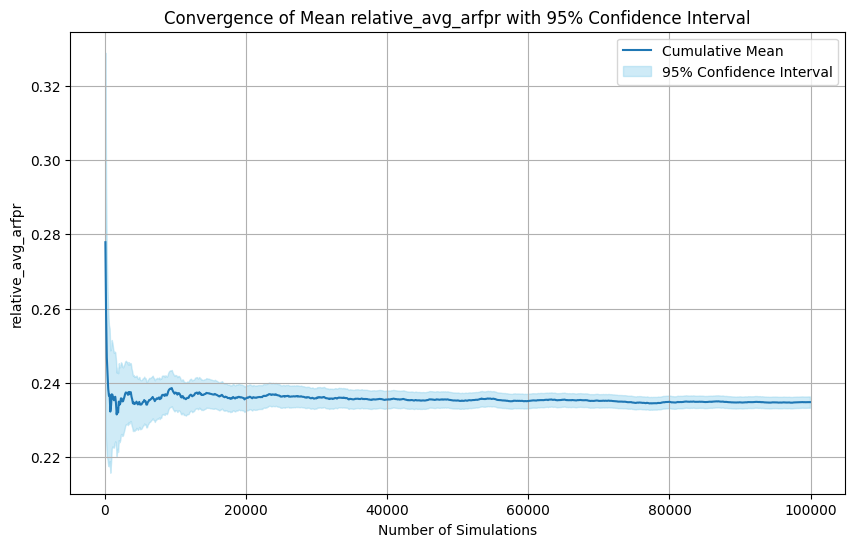

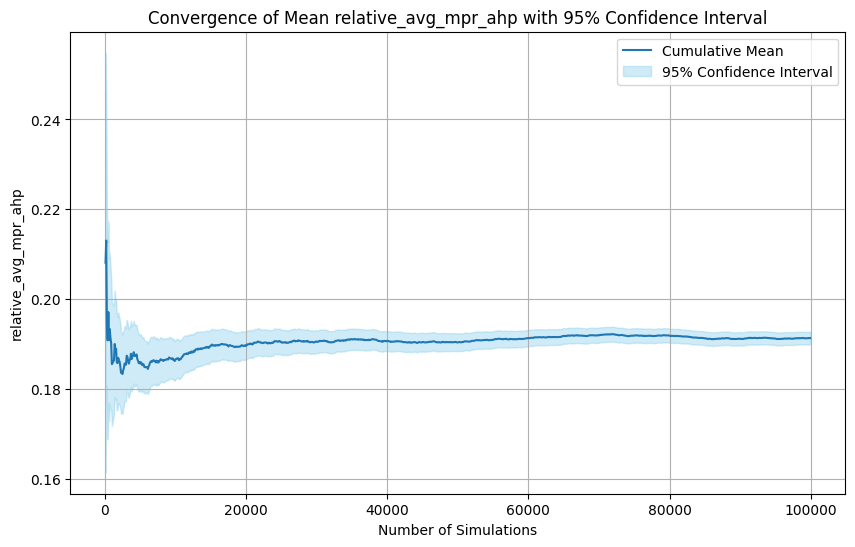

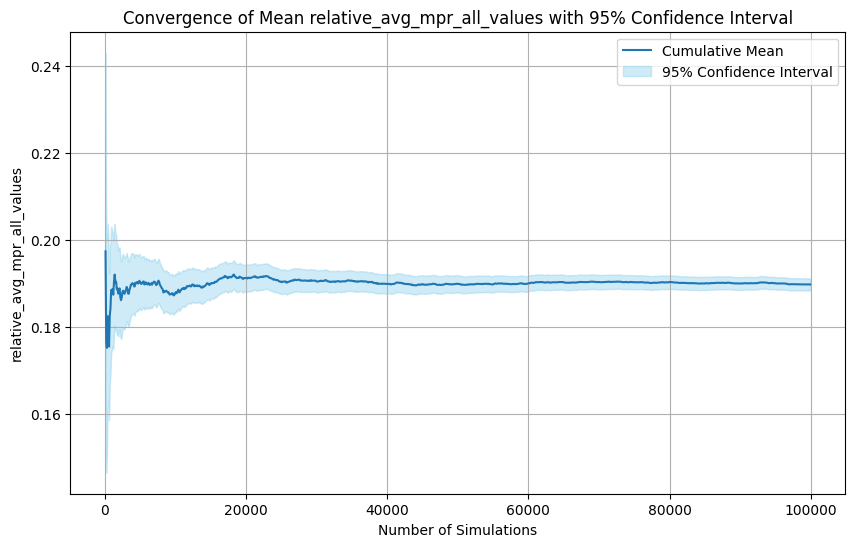

============ Relative High OWA ===============


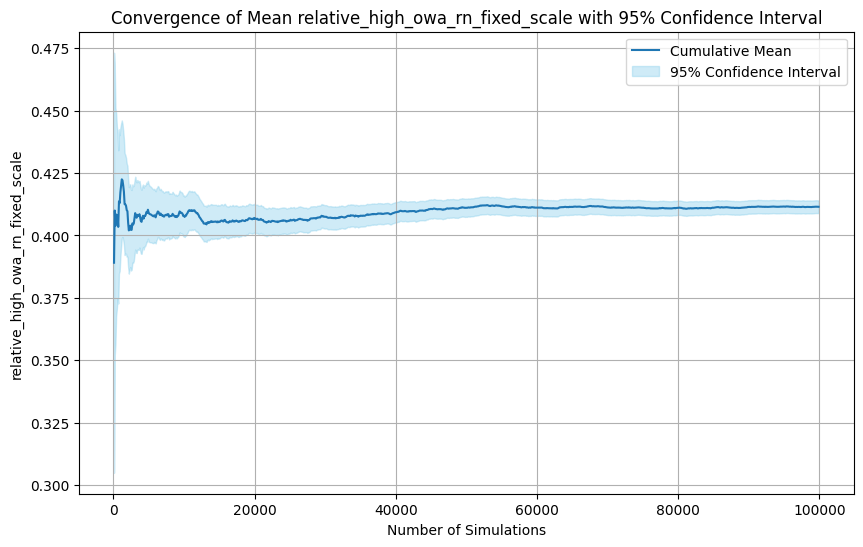

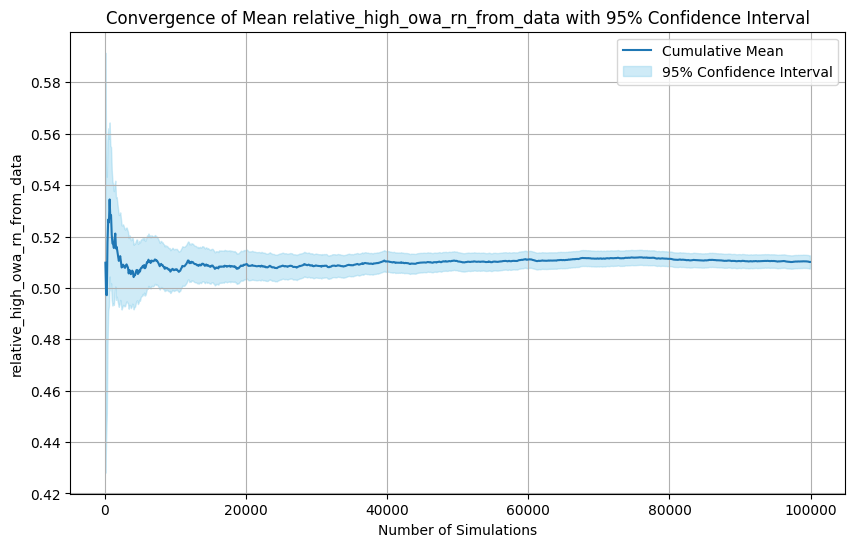

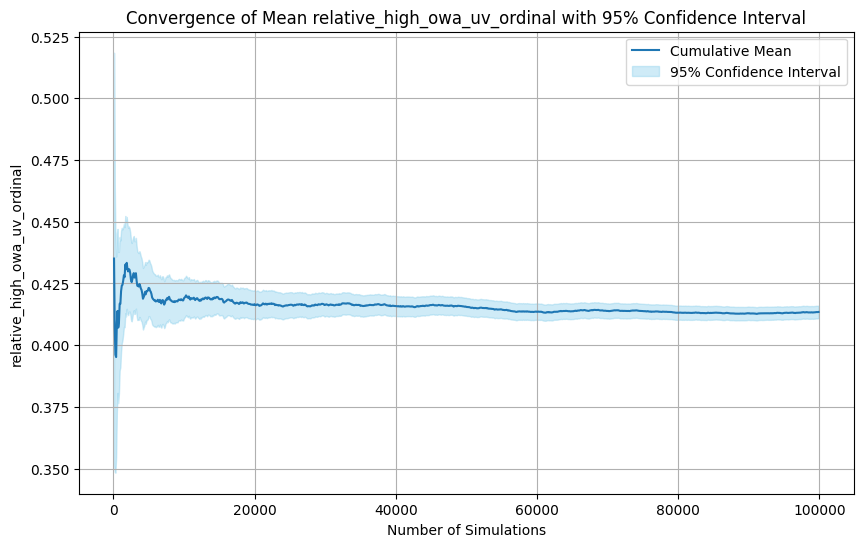

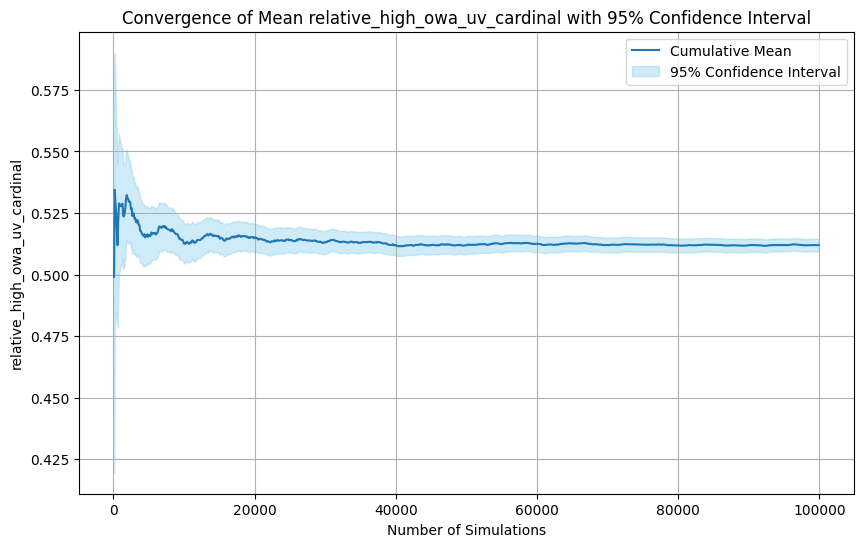

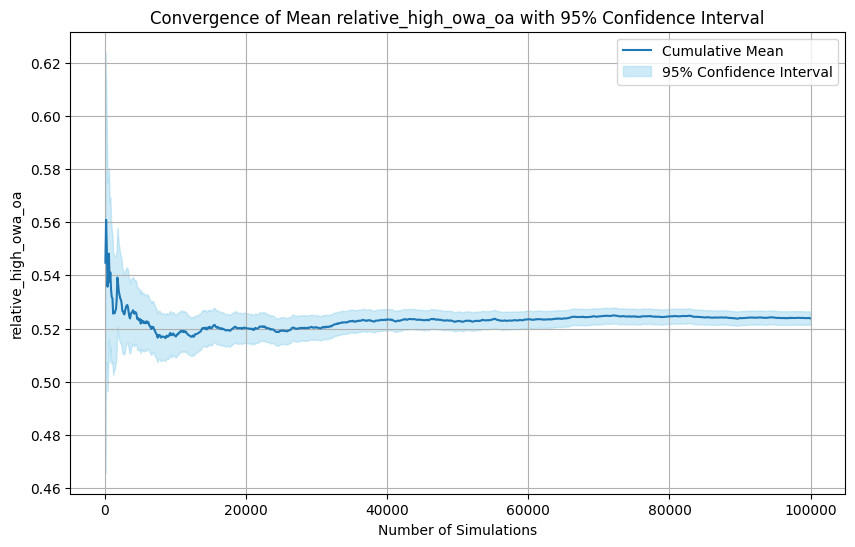

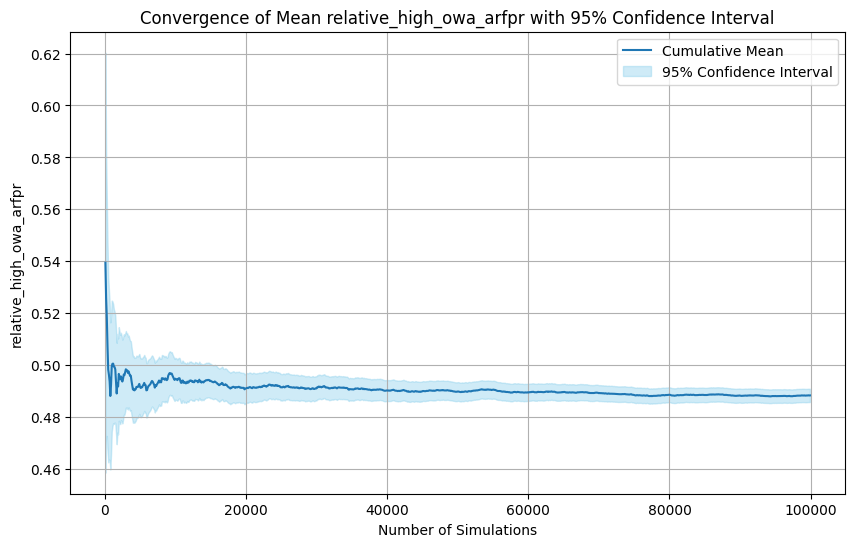

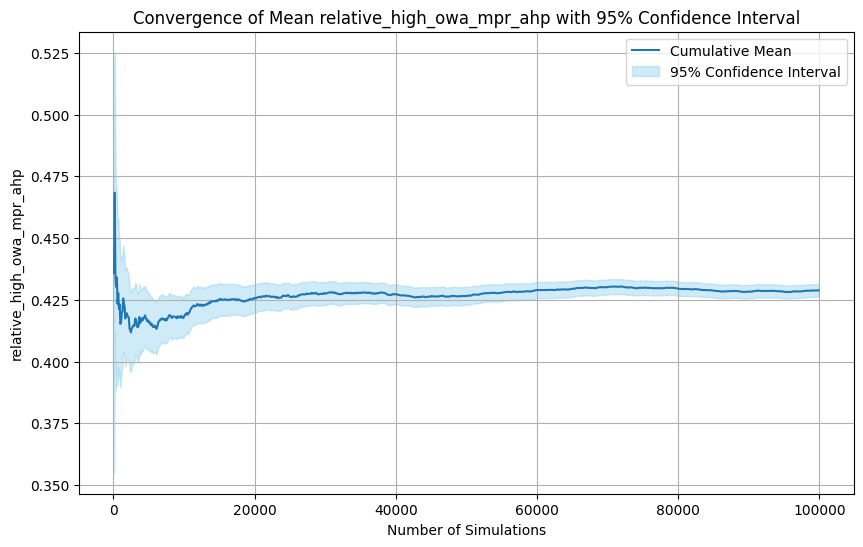

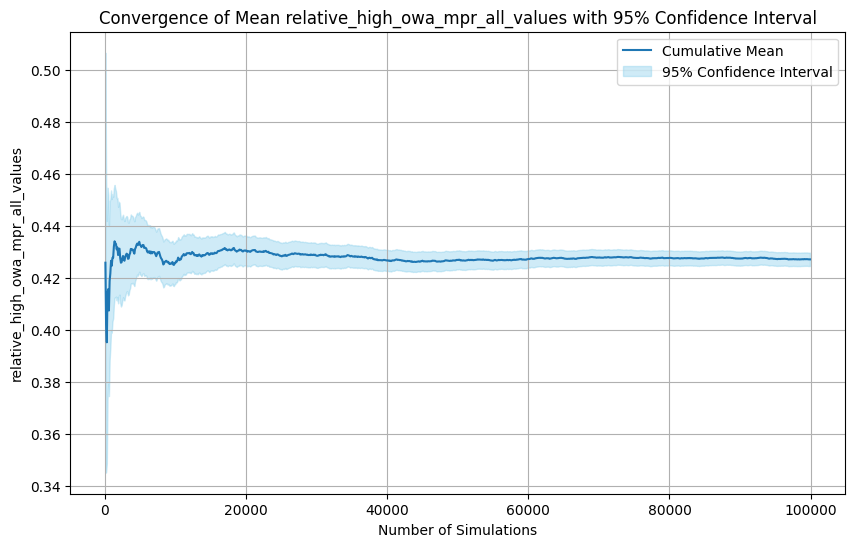

In [ ]:
test_convergence_from_config('formats_combined_proposed')

### Formats Combined All Transformation Functions
The mean converges at around 80k simulations.

========= Convergence Test for formats_combined_all_functions ===============
============== Relative Mean =================


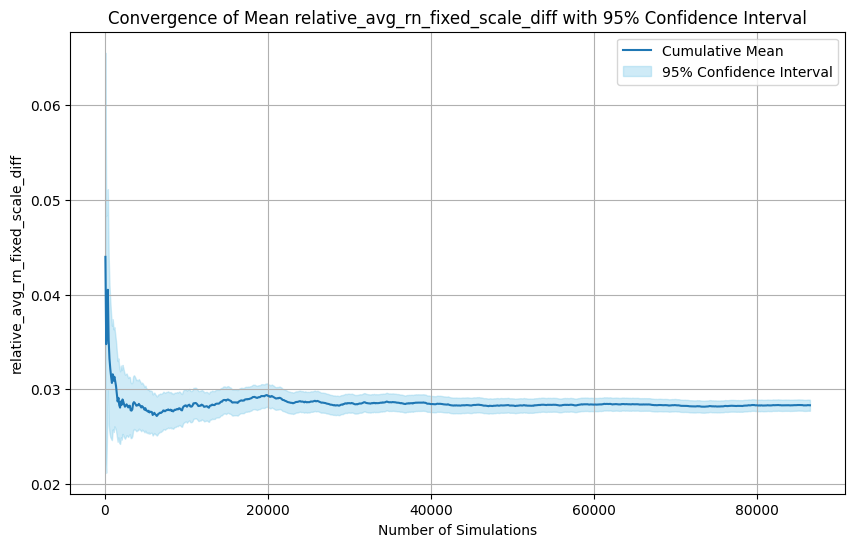

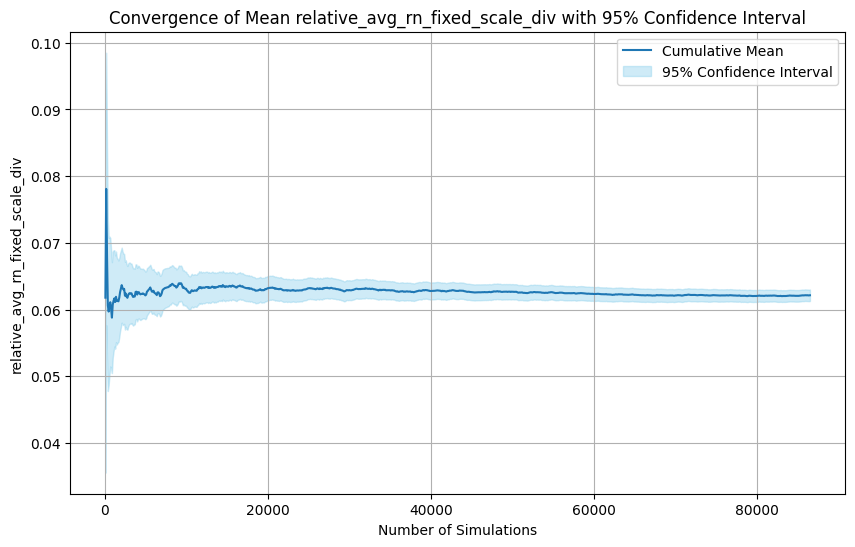

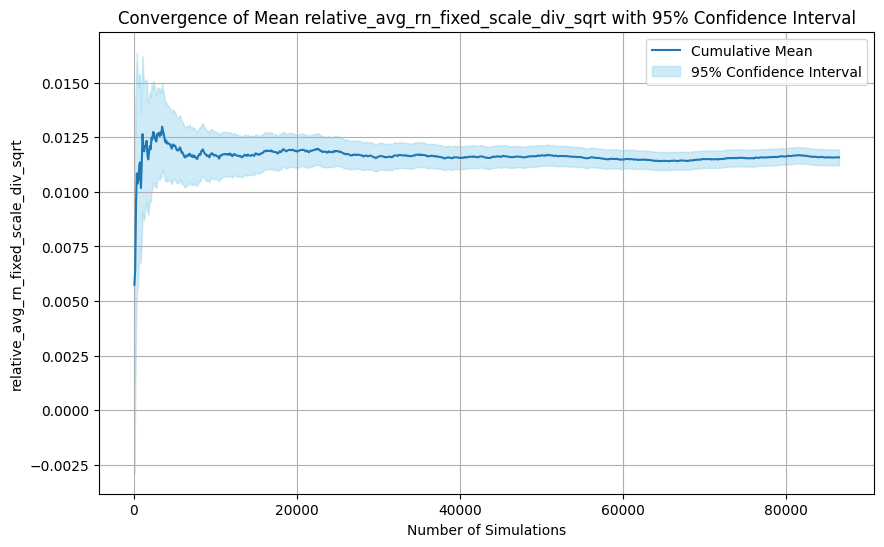

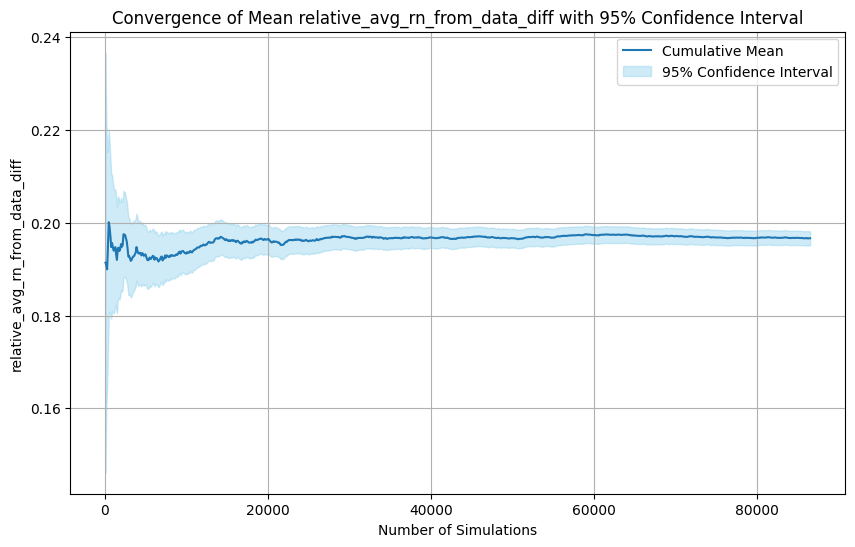

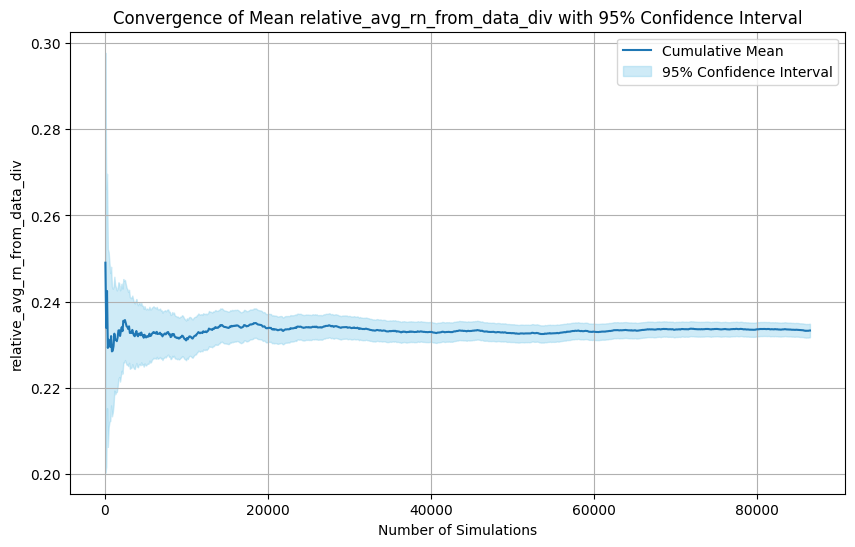

...

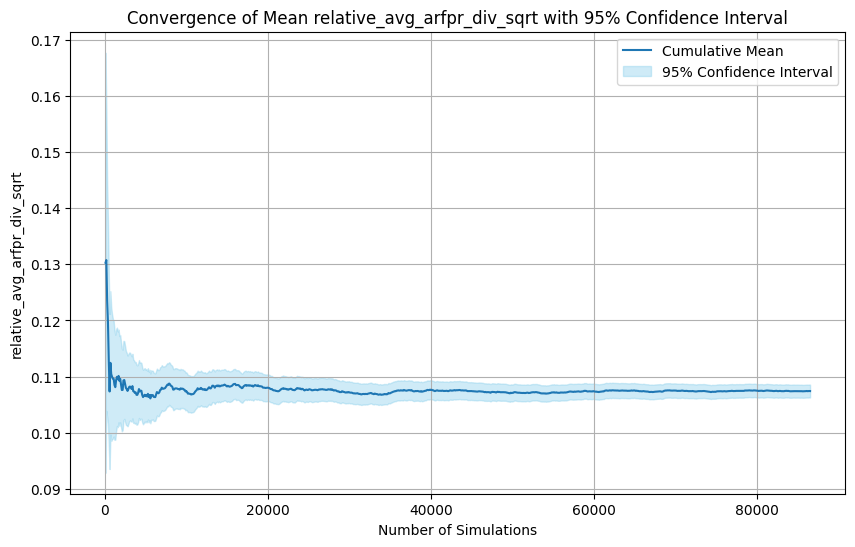

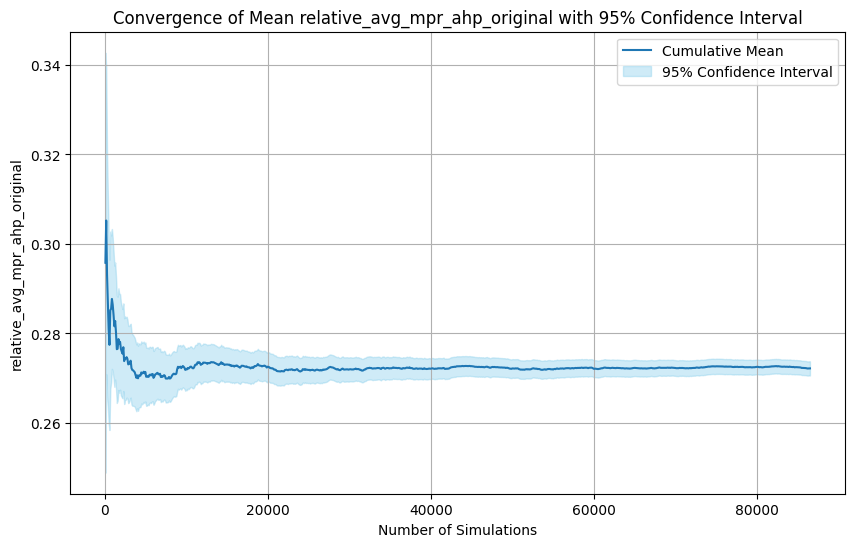

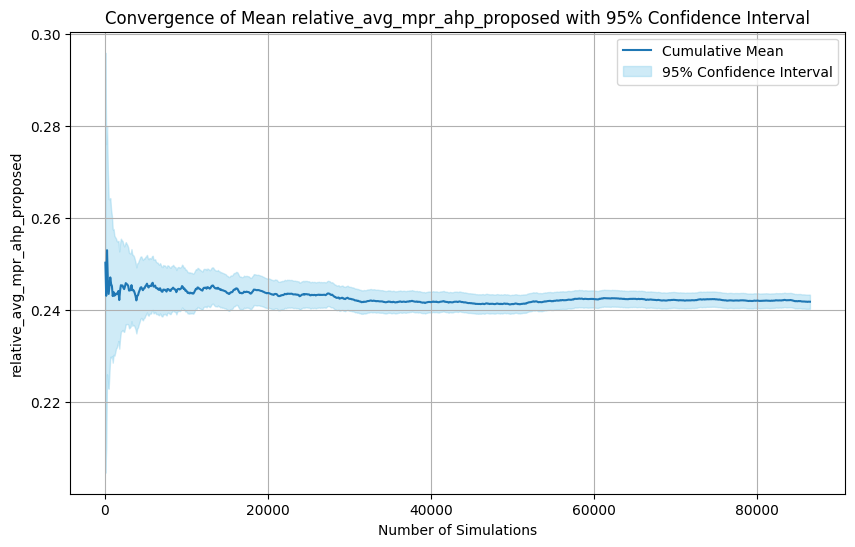

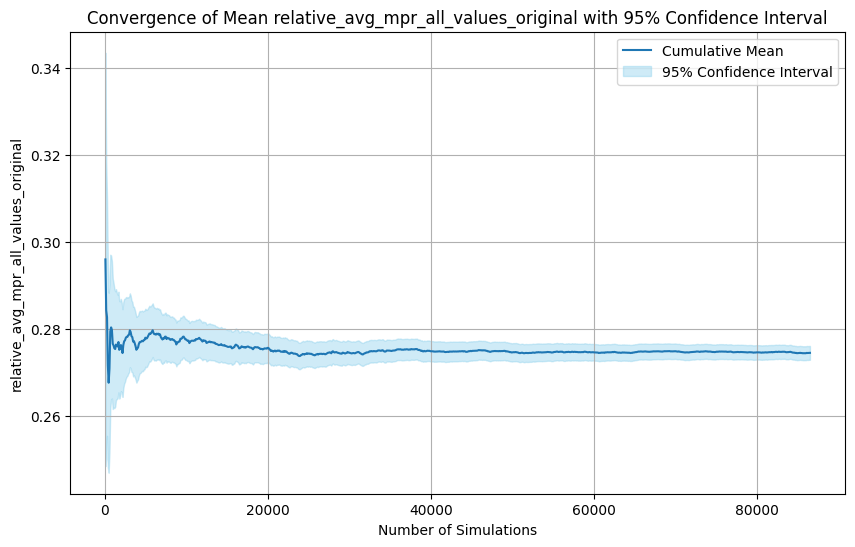

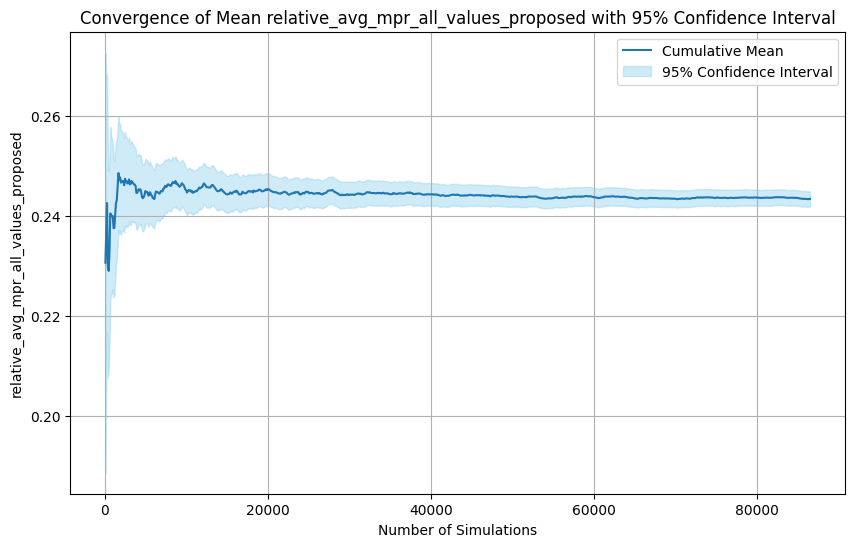

============ Relative High OWA ===============


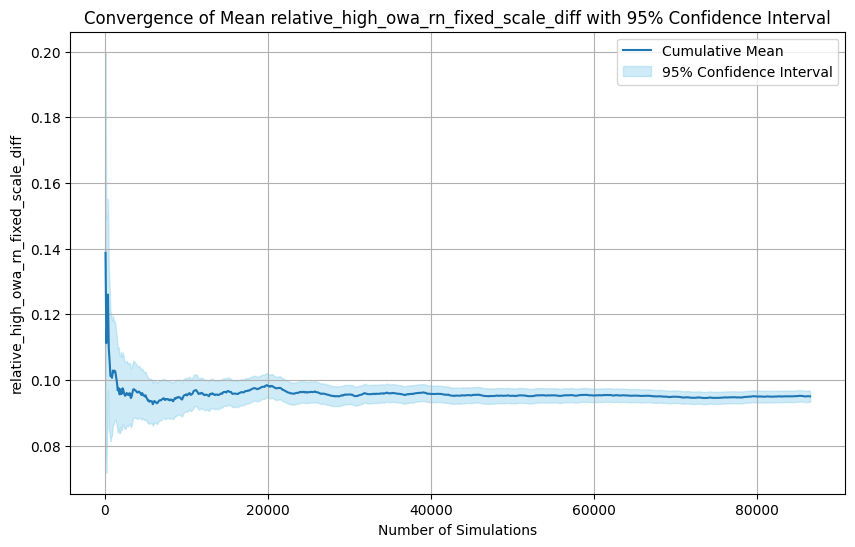

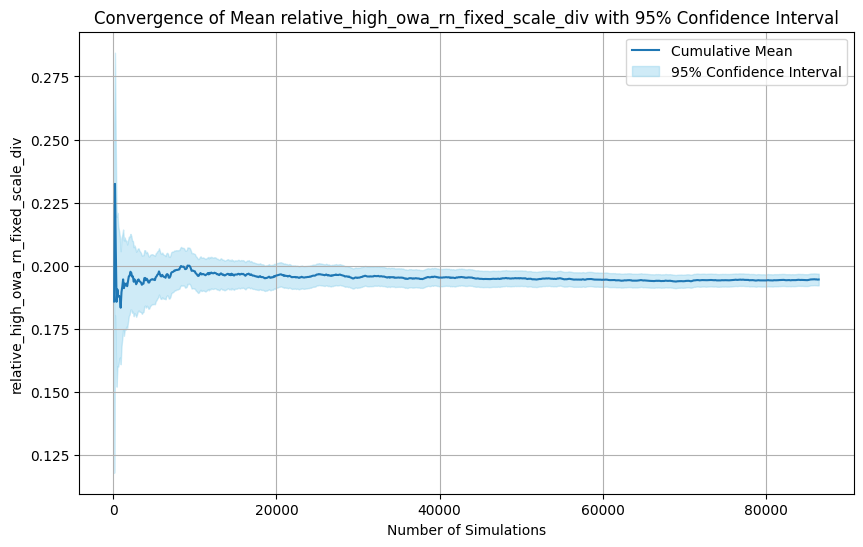

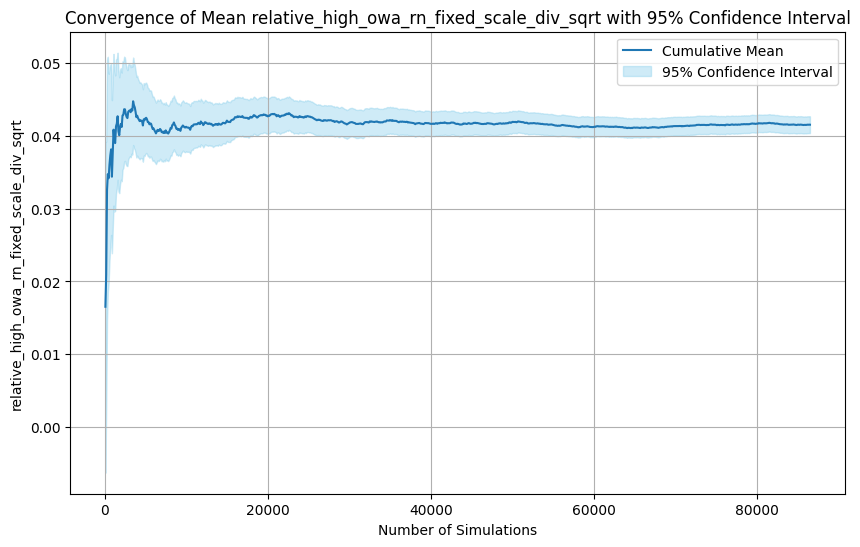

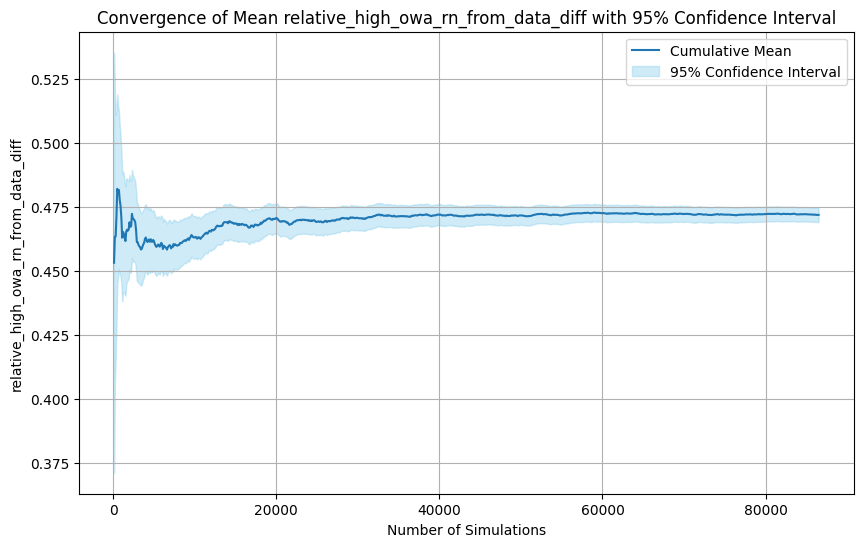

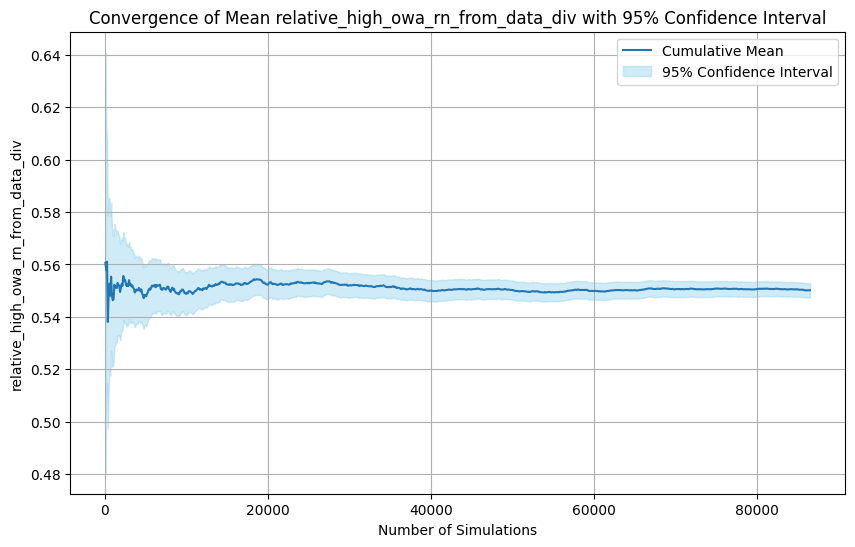

...

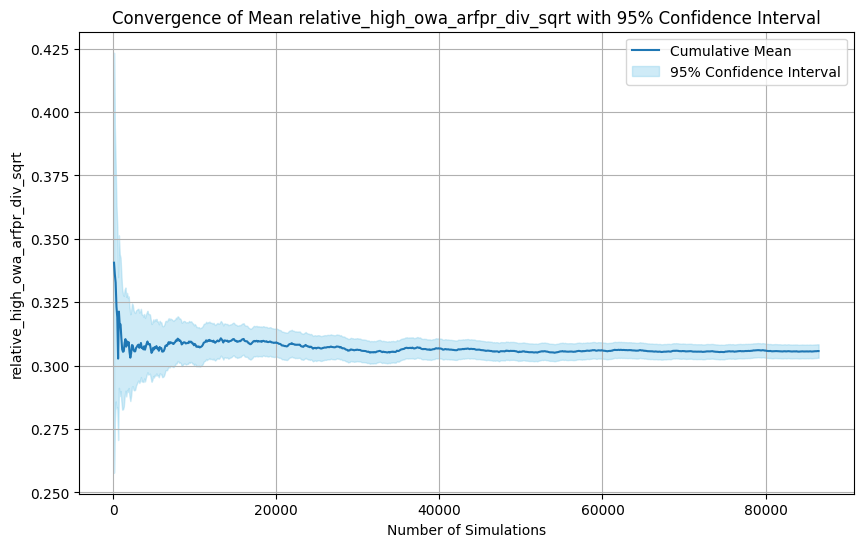

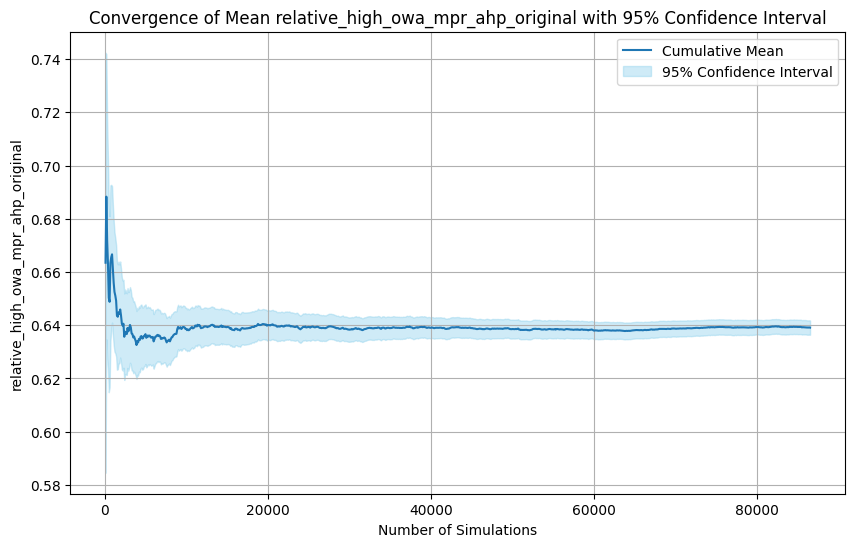

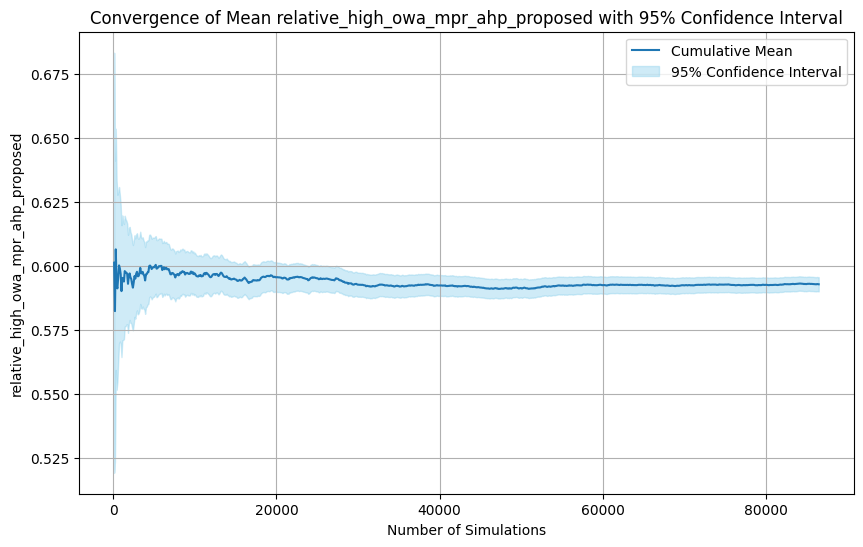

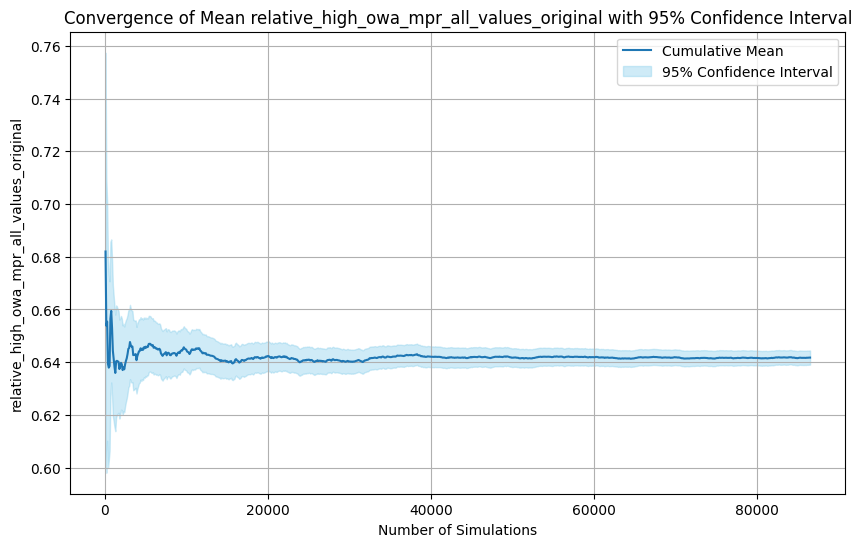

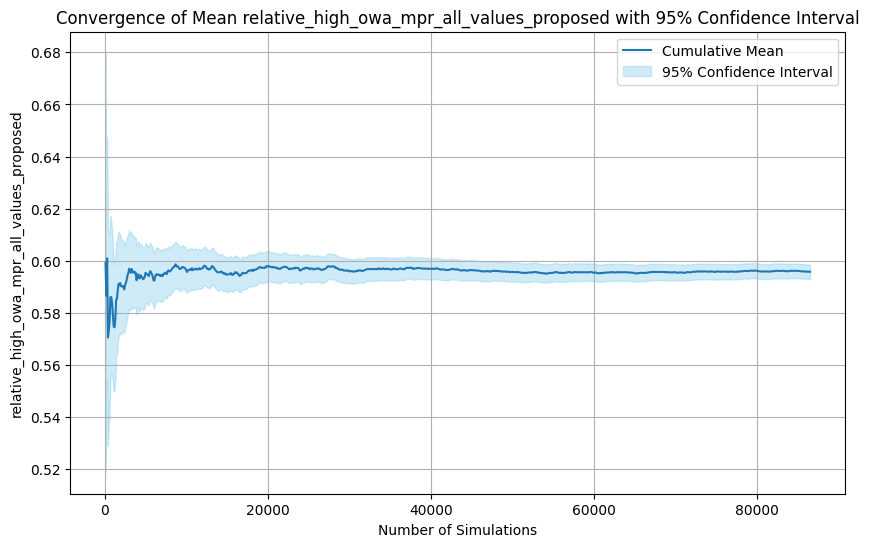

In [ ]:
test_convergence_from_config('formats_combined_all_functions')

### Formats Combined Distance-Based Transformation Functions
The mean converges at around 80k simulations.

========= Convergence Test for formats_combined_distance ===============
============== Relative Mean =================


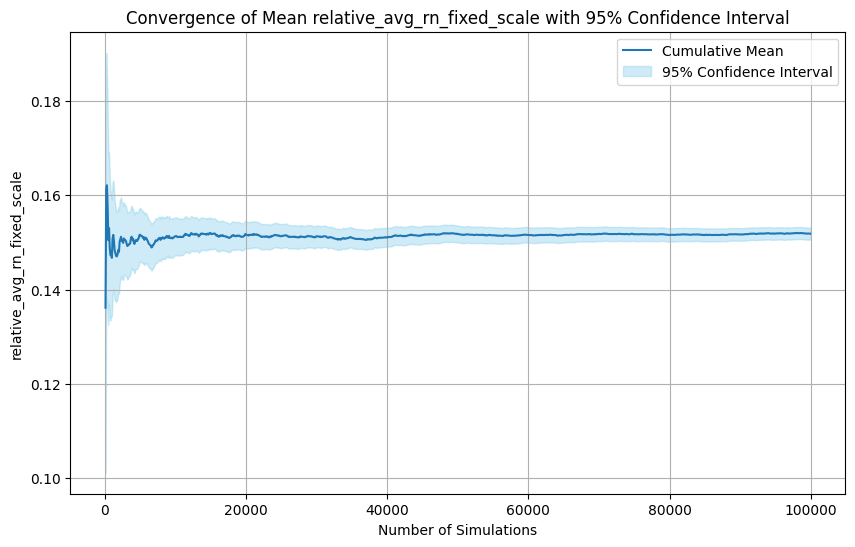

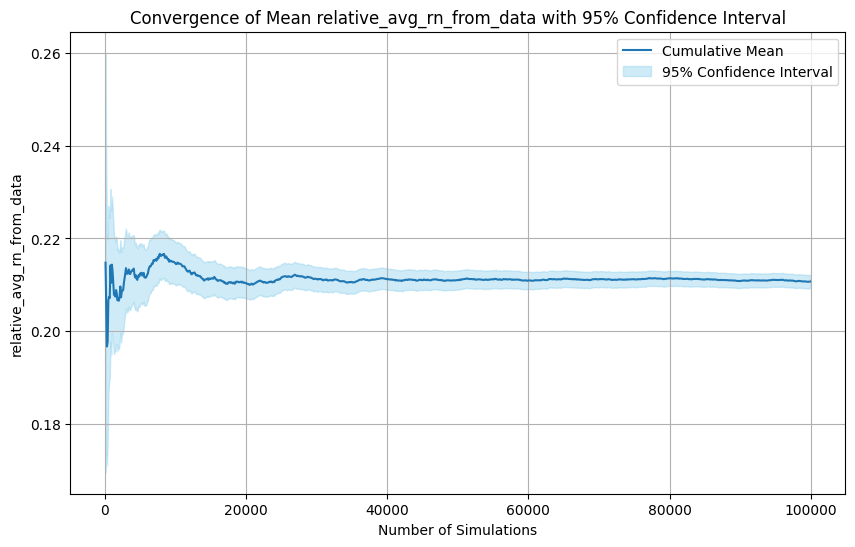

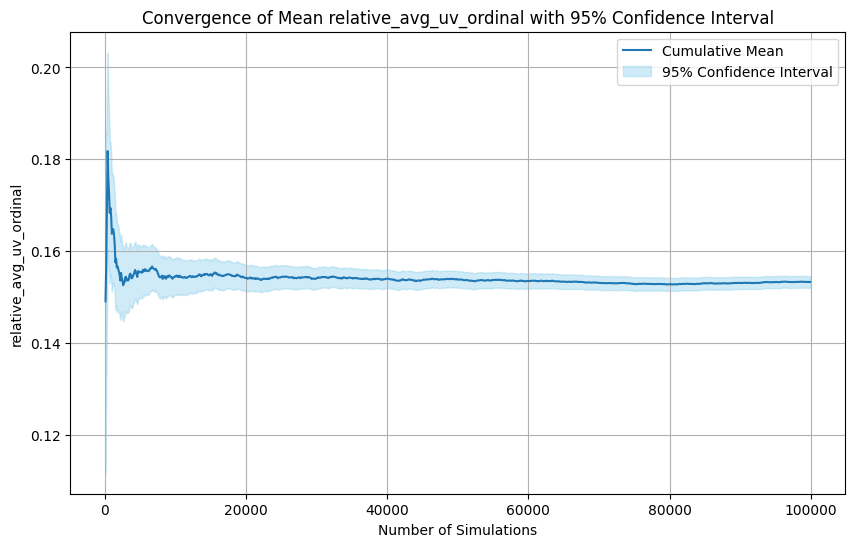

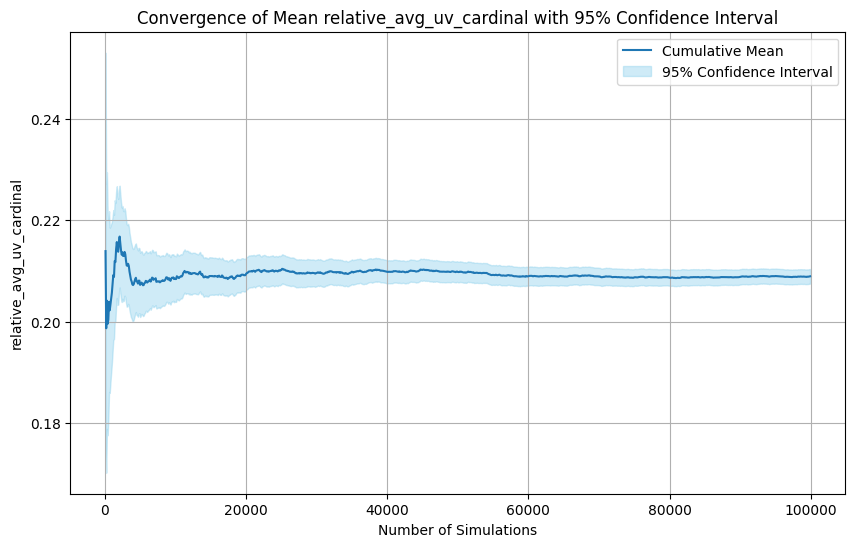

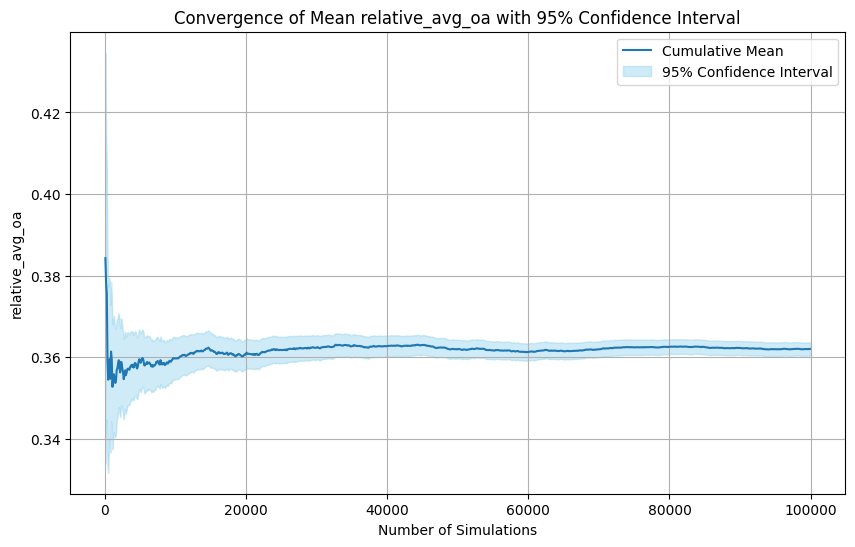

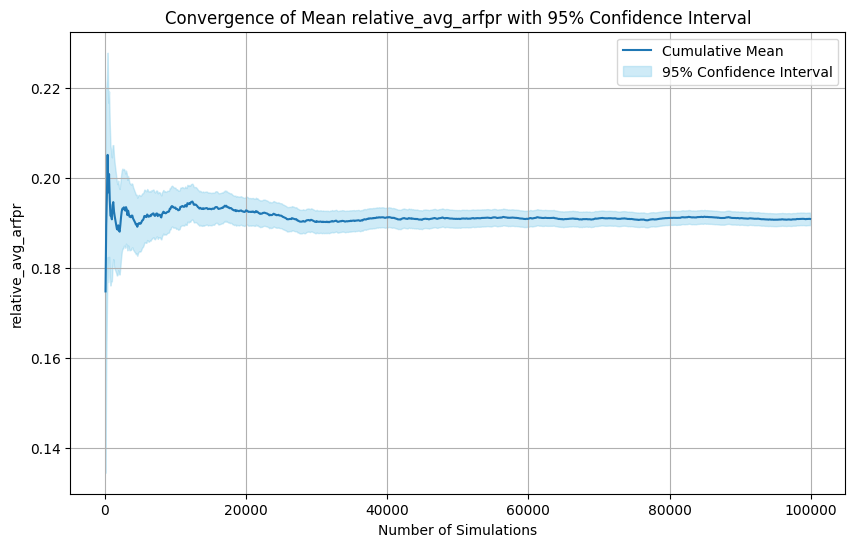

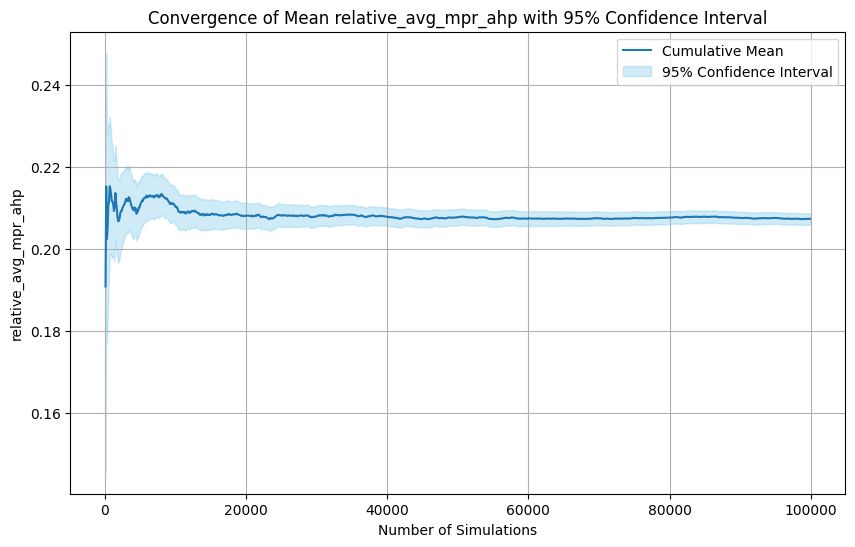

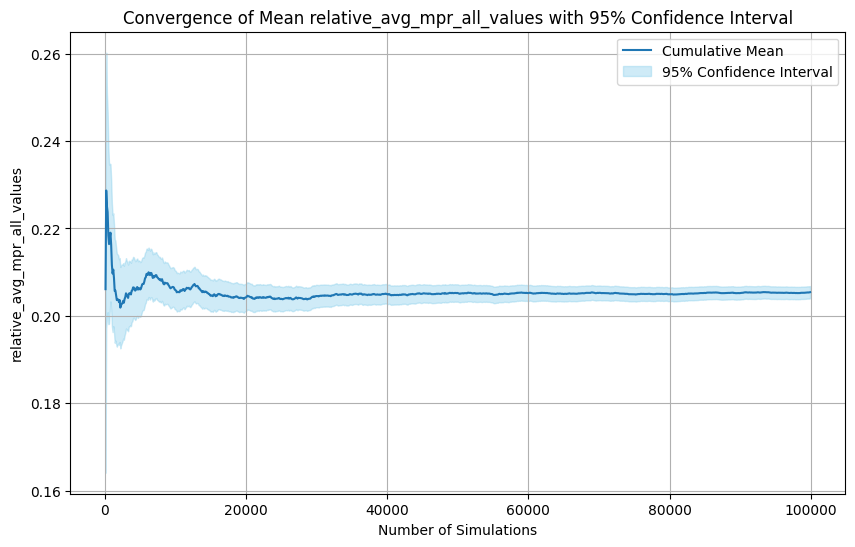

============ Relative High OWA ===============


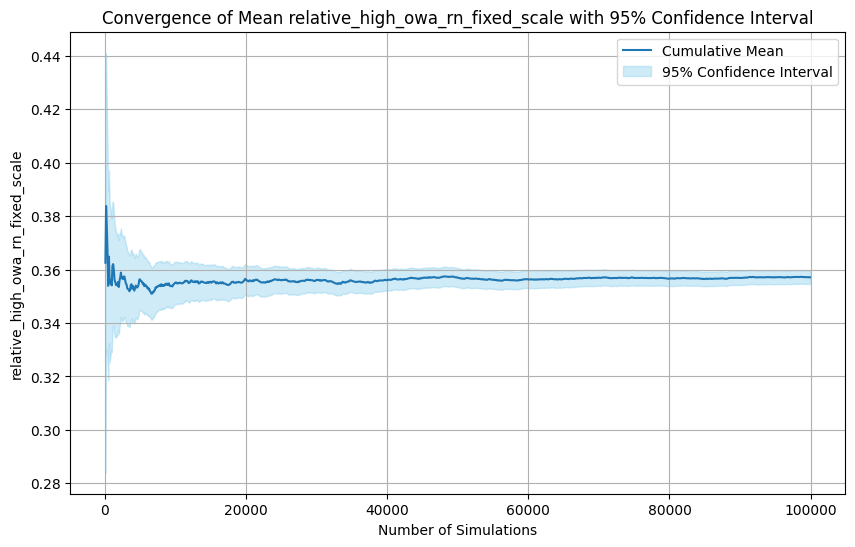

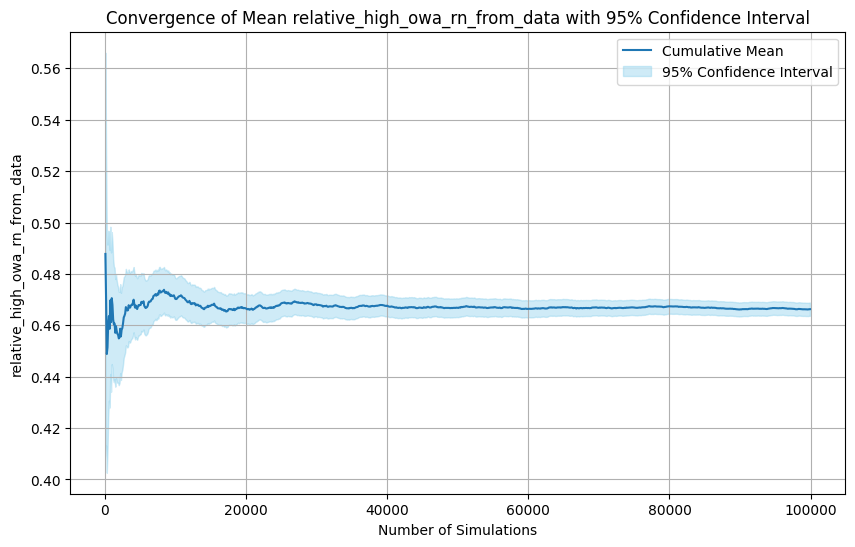

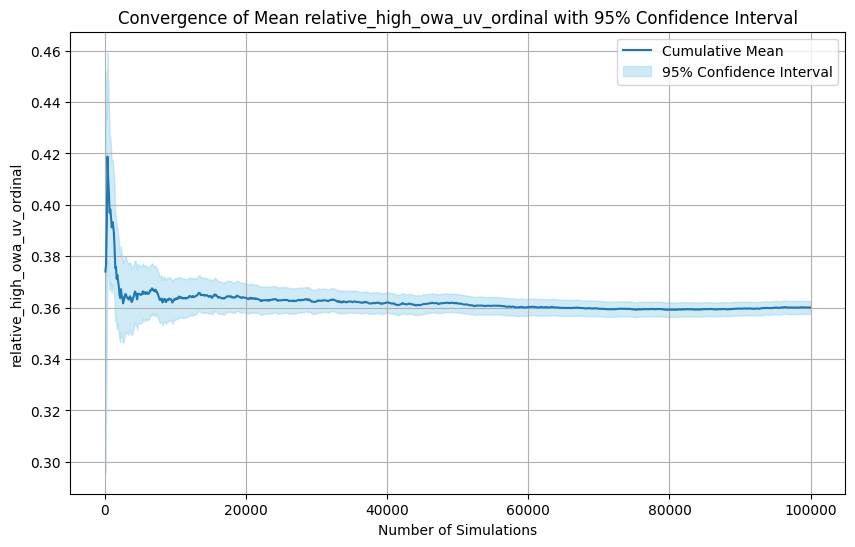

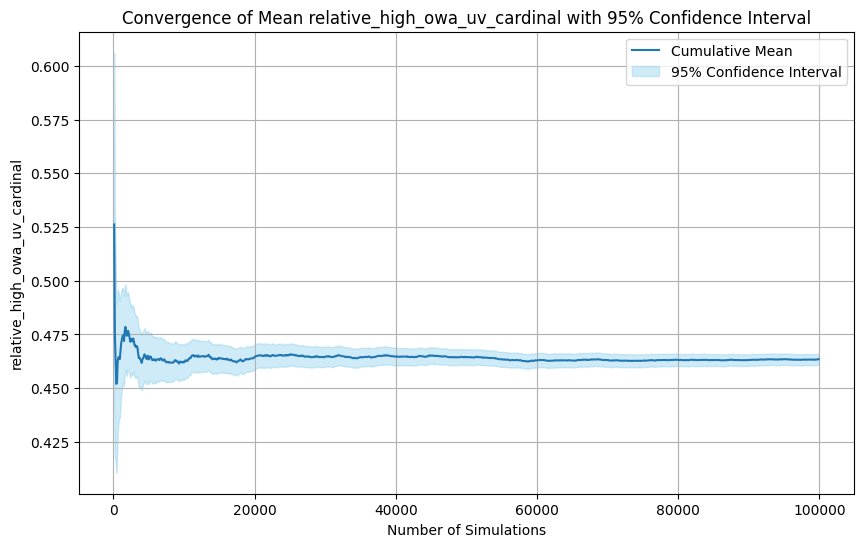

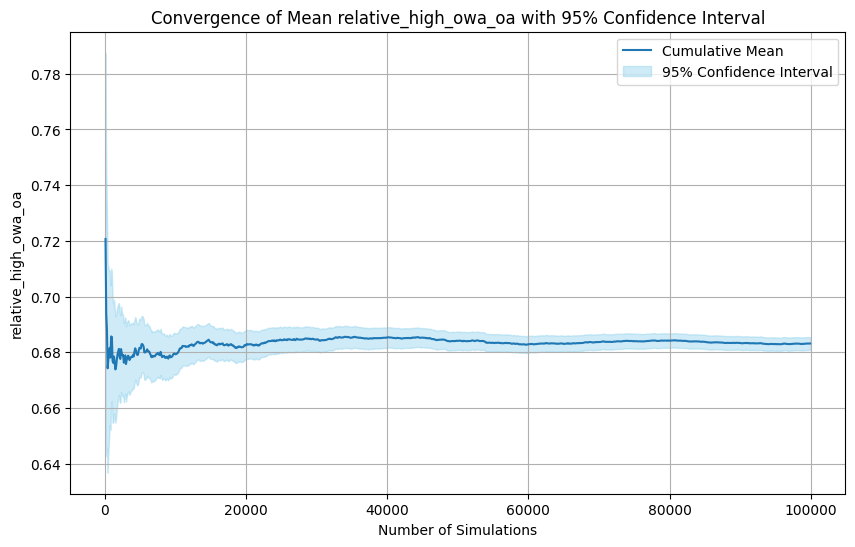

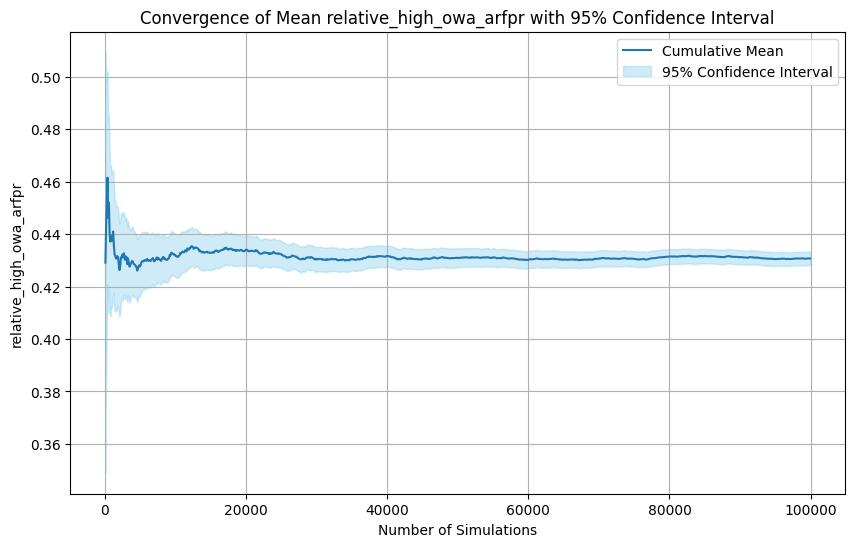

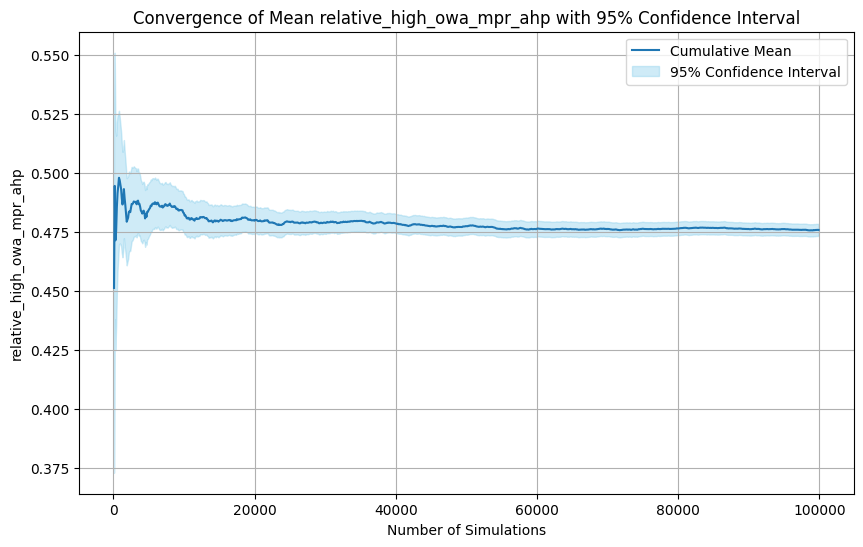

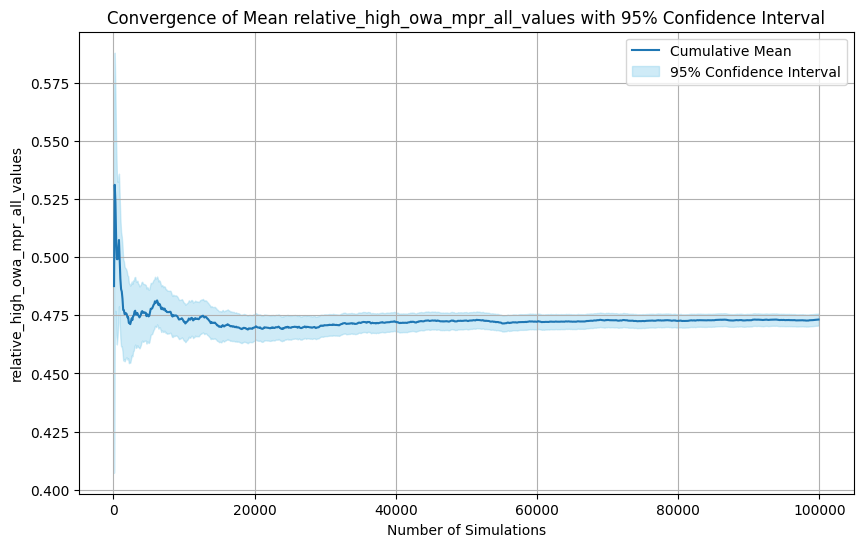

In [ ]:
test_convergence_from_config('formats_combined_distance')

### Formats Combined Division-Based Transformation Functions
The mean converges at around 80k simulations.

========= Convergence Test for formats_combined_div ===============
============== Relative Mean =================


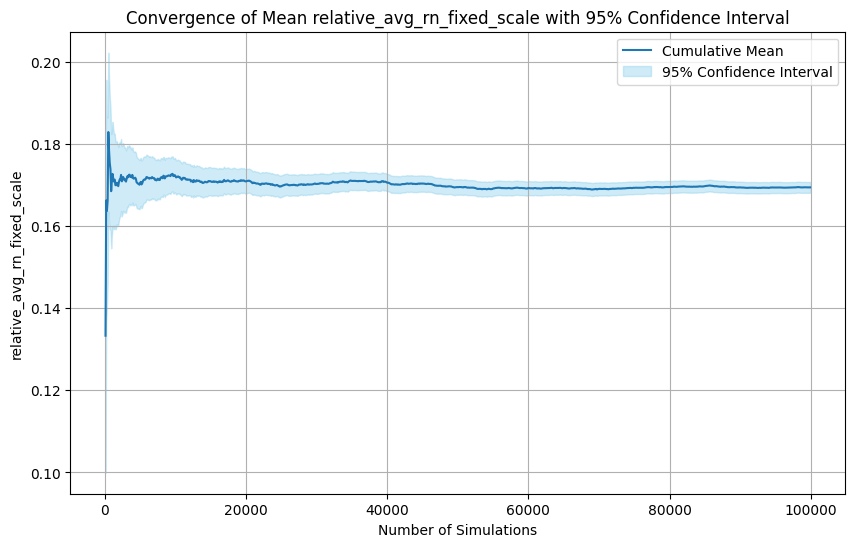

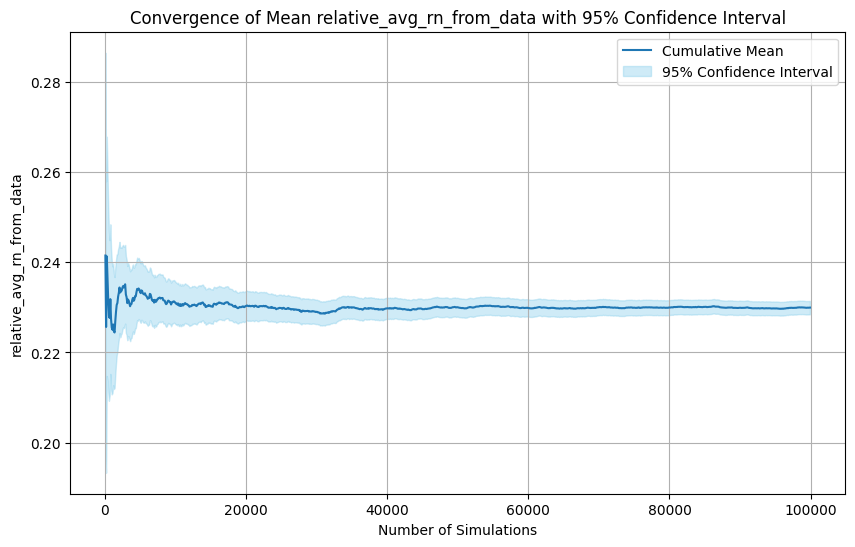

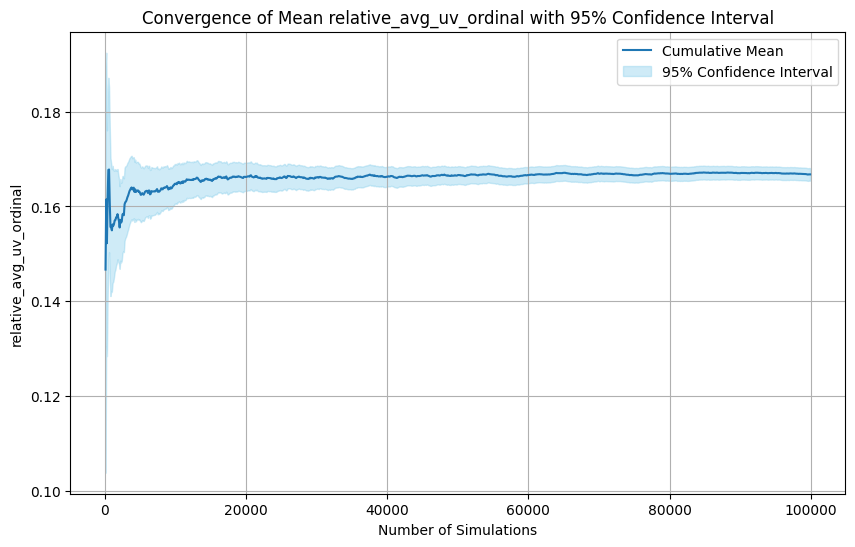

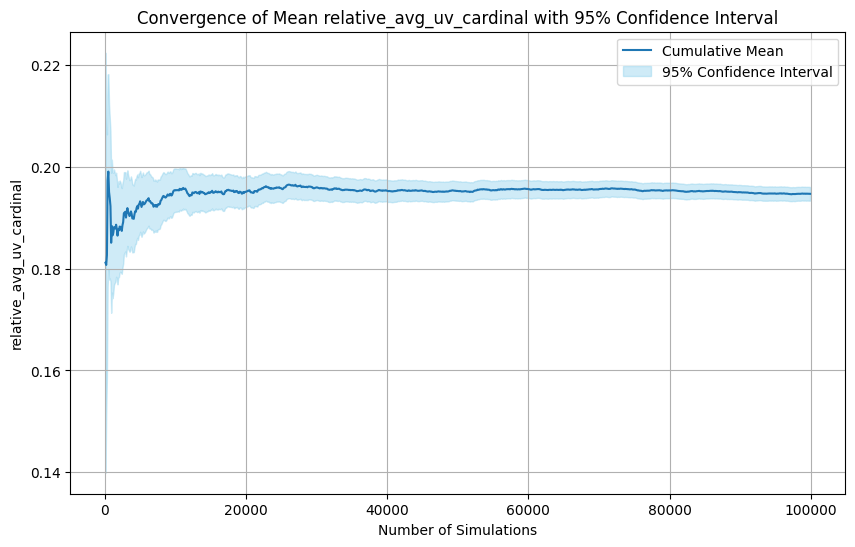

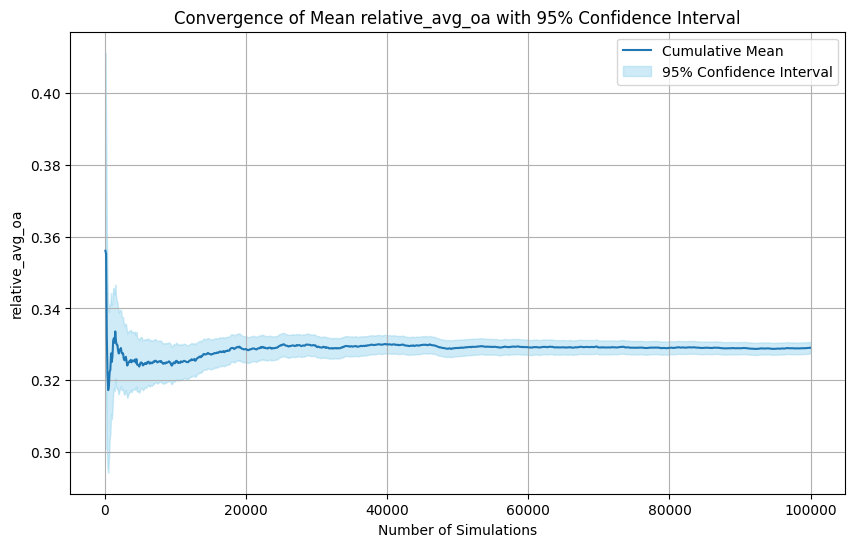

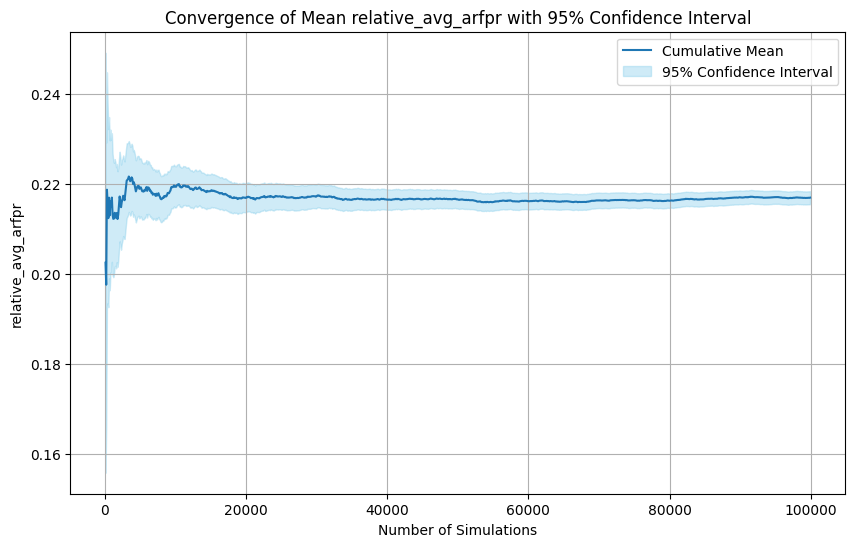

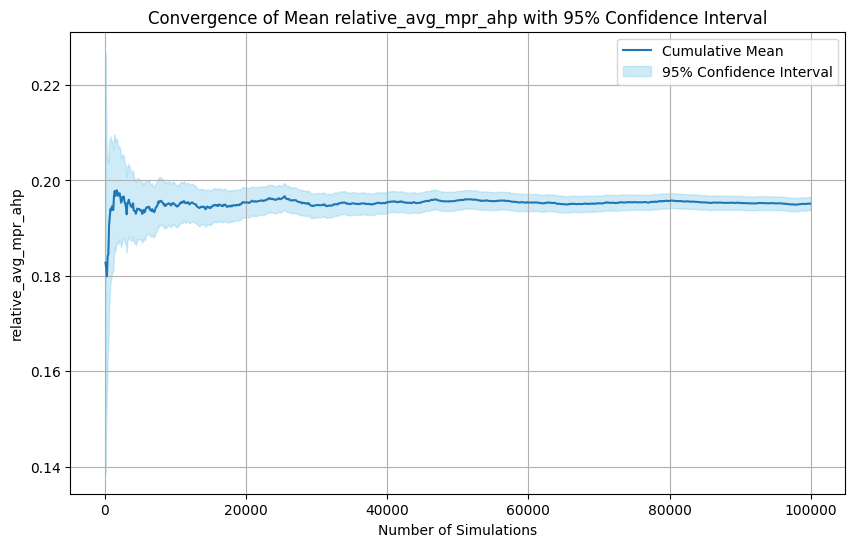

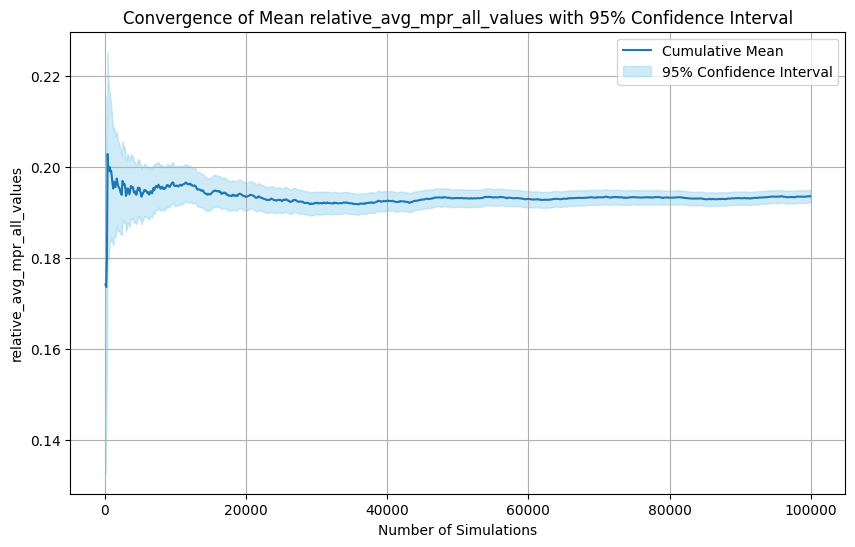

============ Relative High OWA ===============


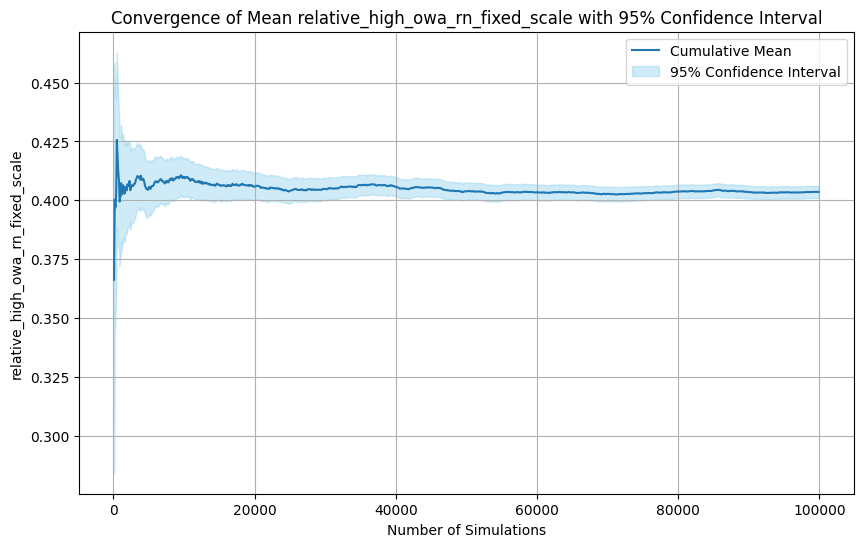

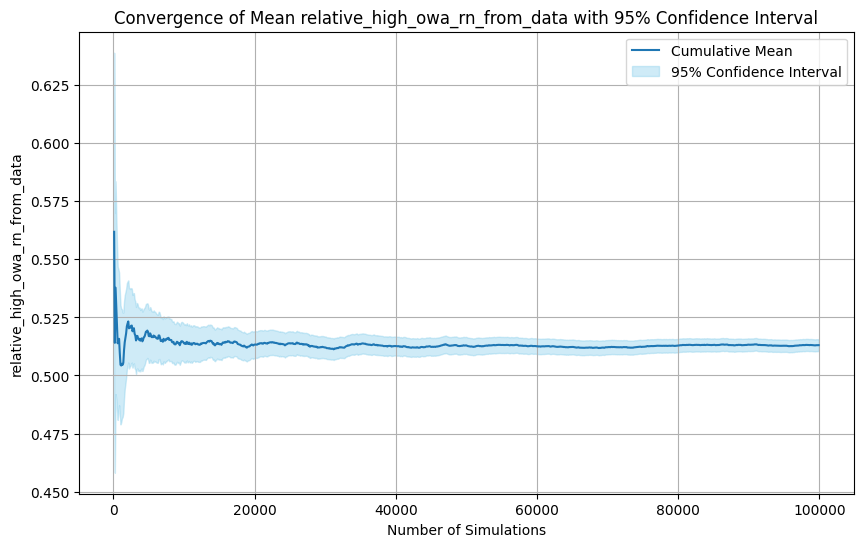

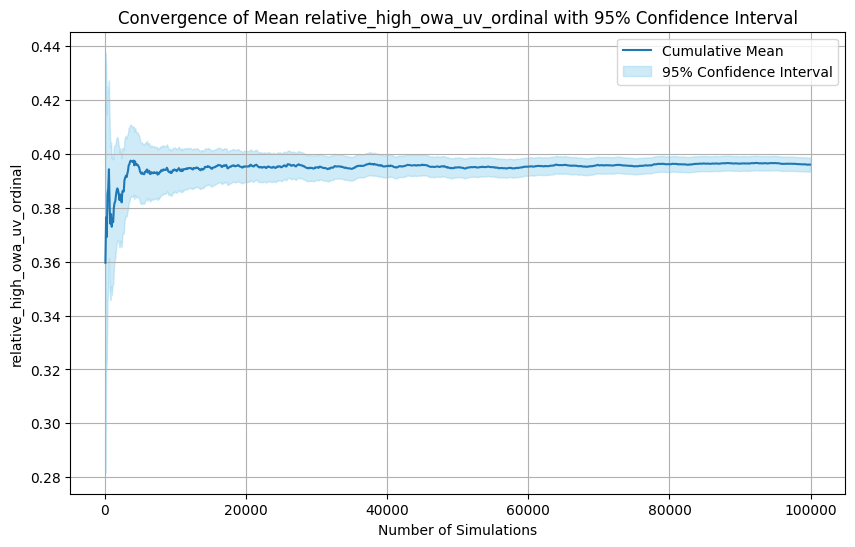

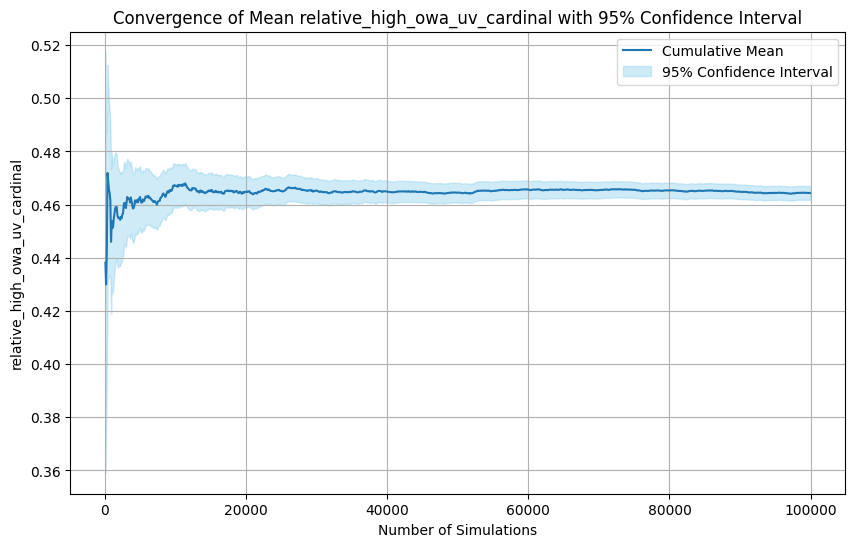

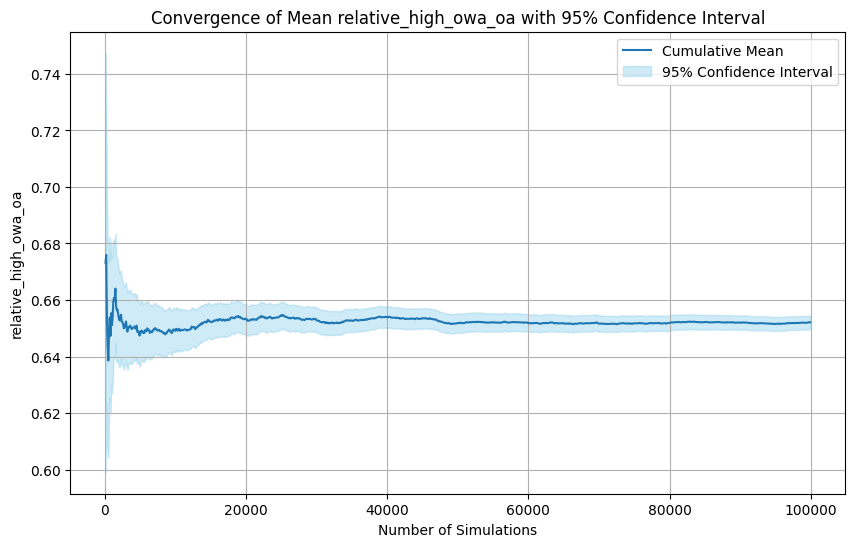

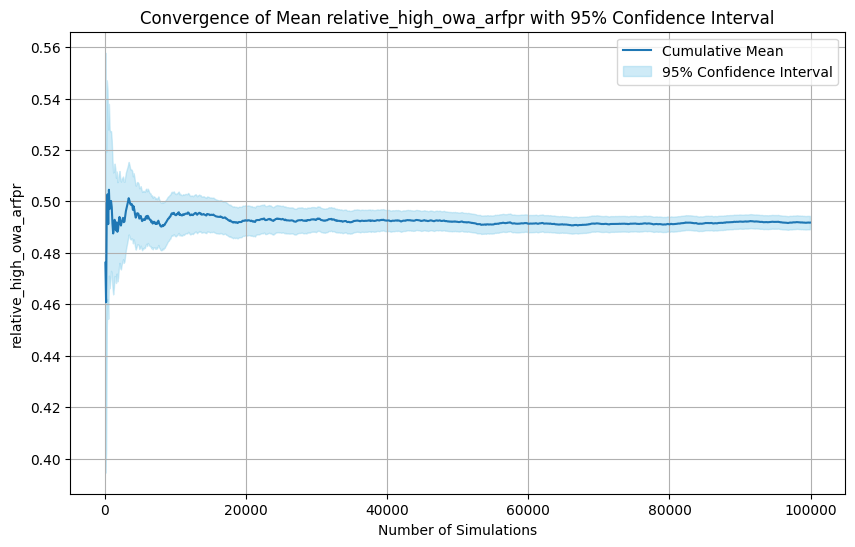

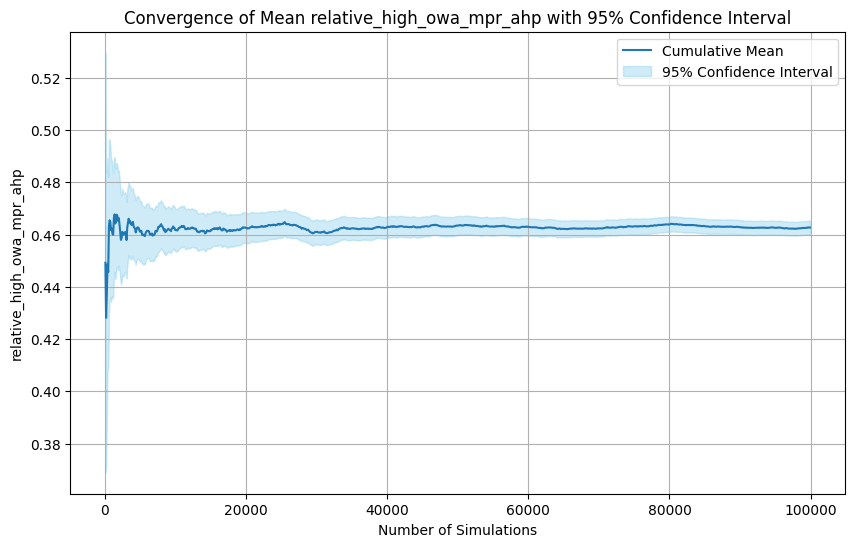

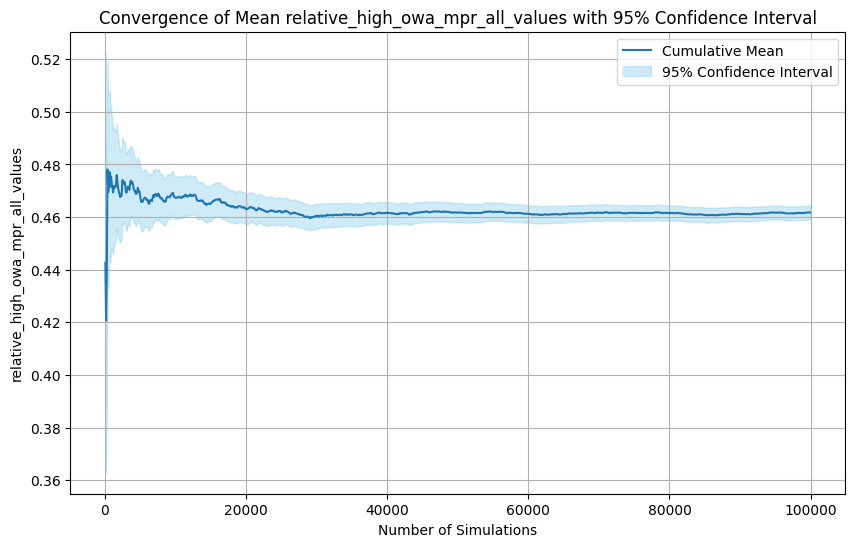

In [ ]:
test_convergence_from_config('formats_combined_div')

### Formats Combined Div-Sqrt Transformation Functions
The mean converges at around 80k simulations.

========= Convergence Test for formats_combined_div_sqrt ===============
============== Relative Mean =================


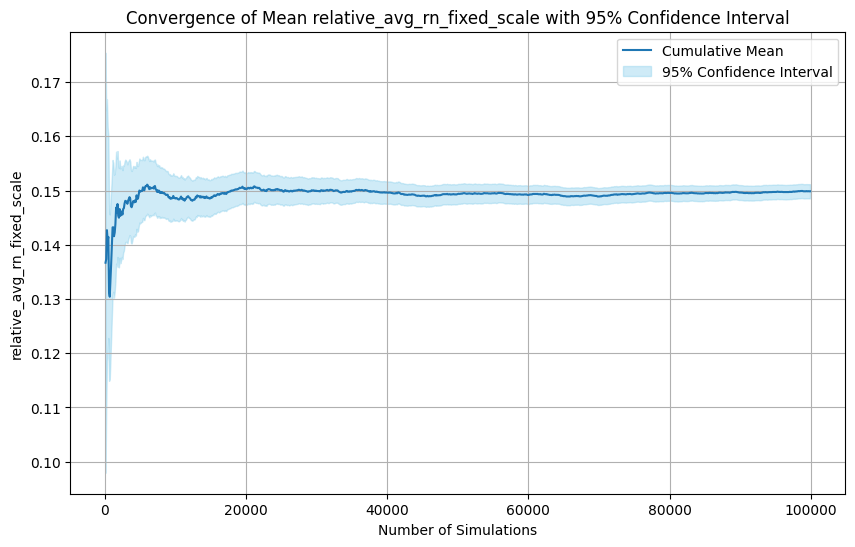

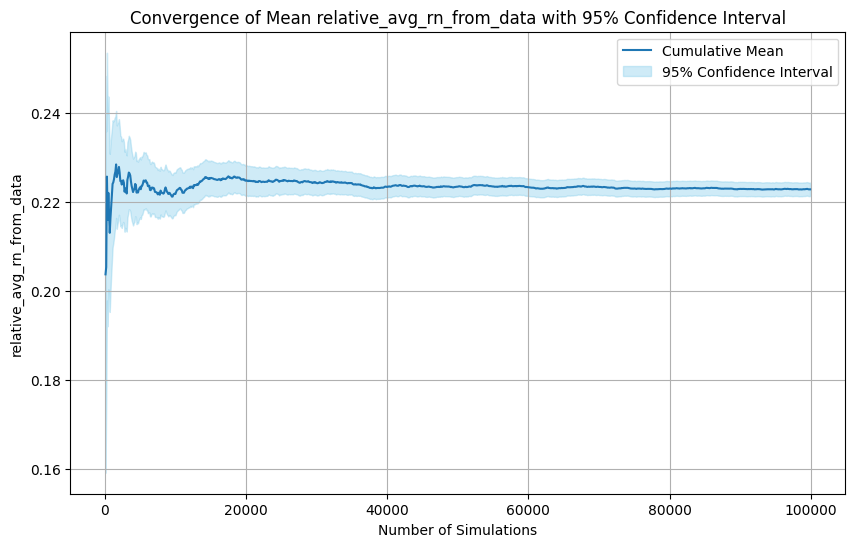

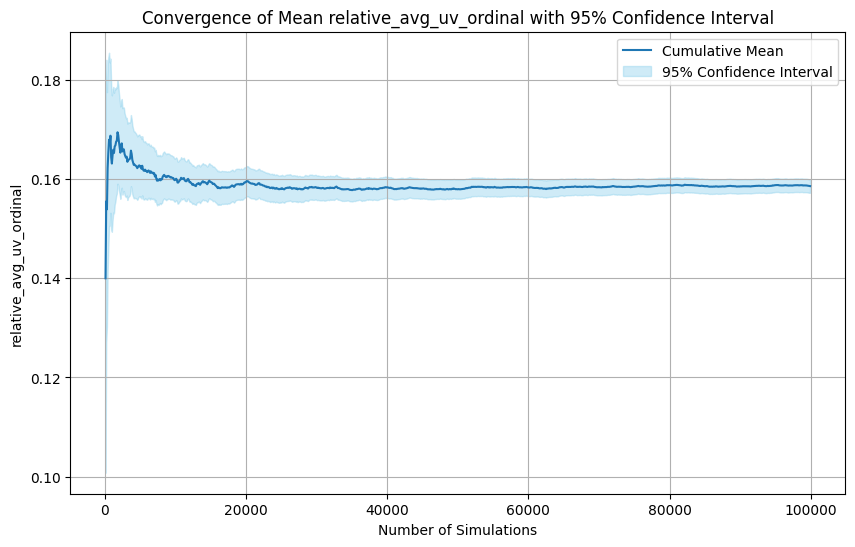

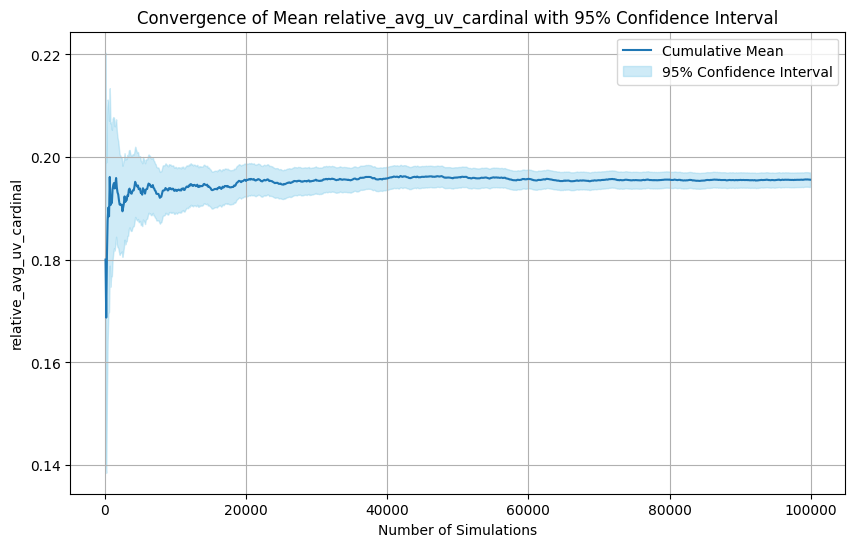

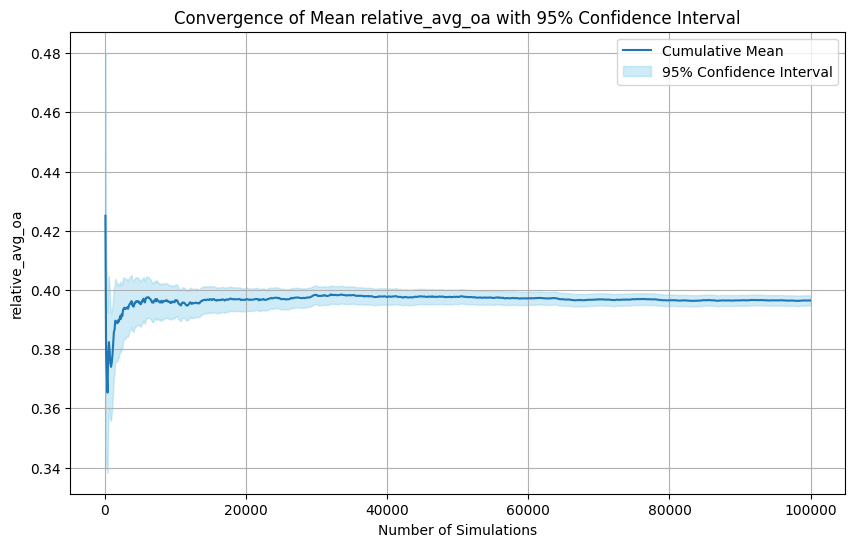

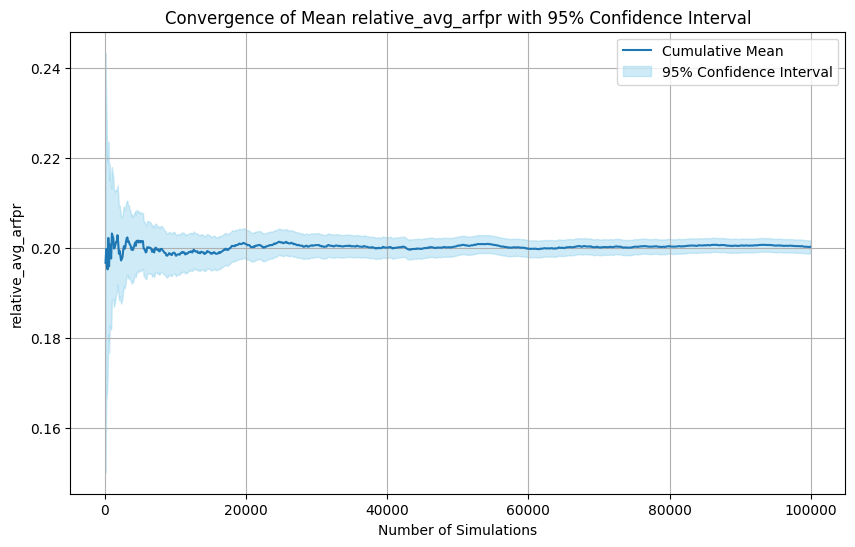

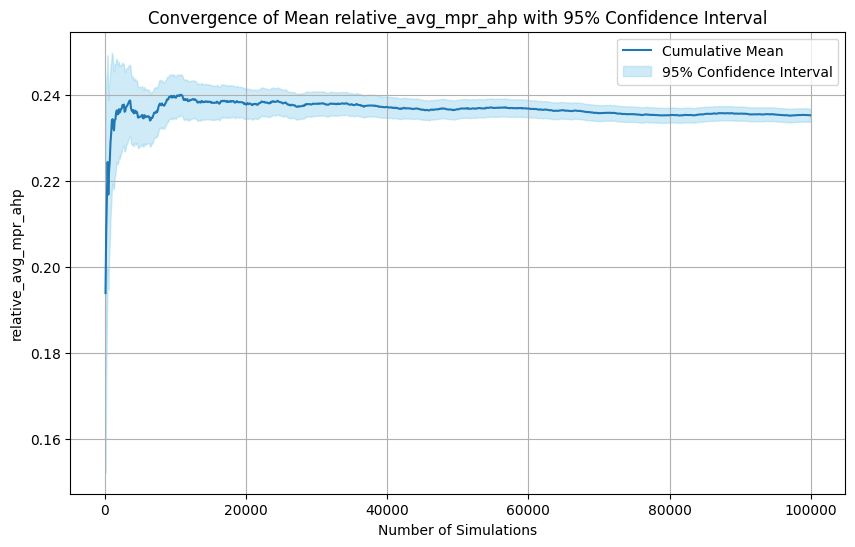

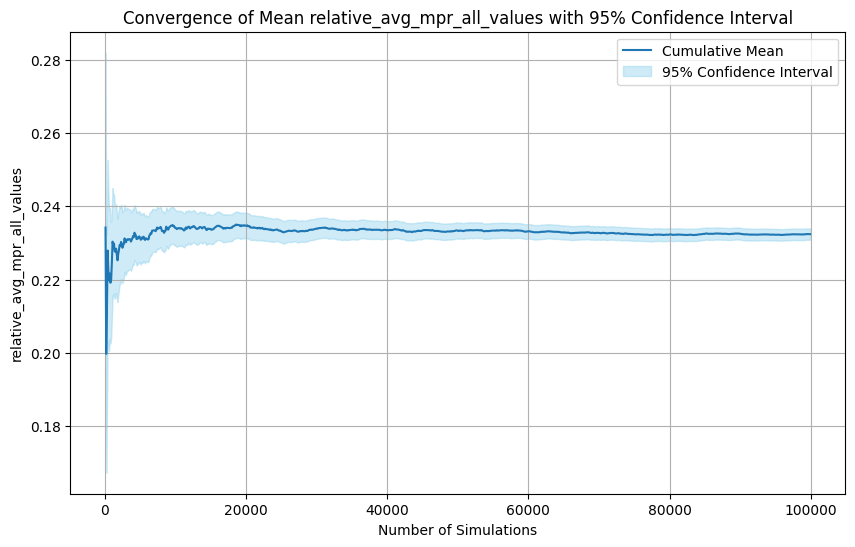

============ Relative High OWA ===============


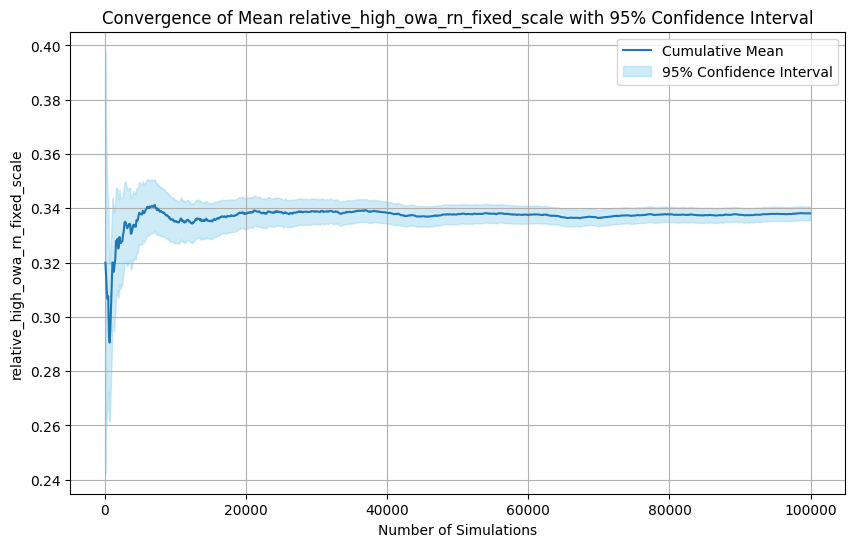

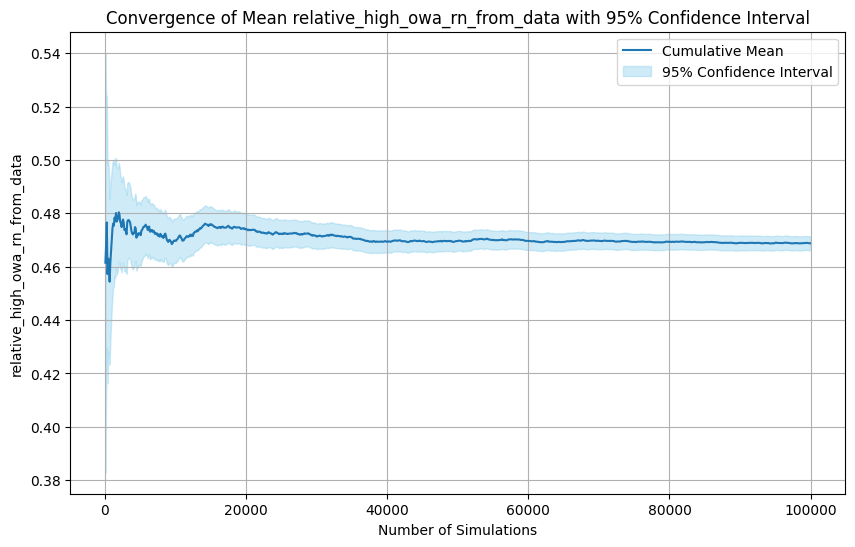

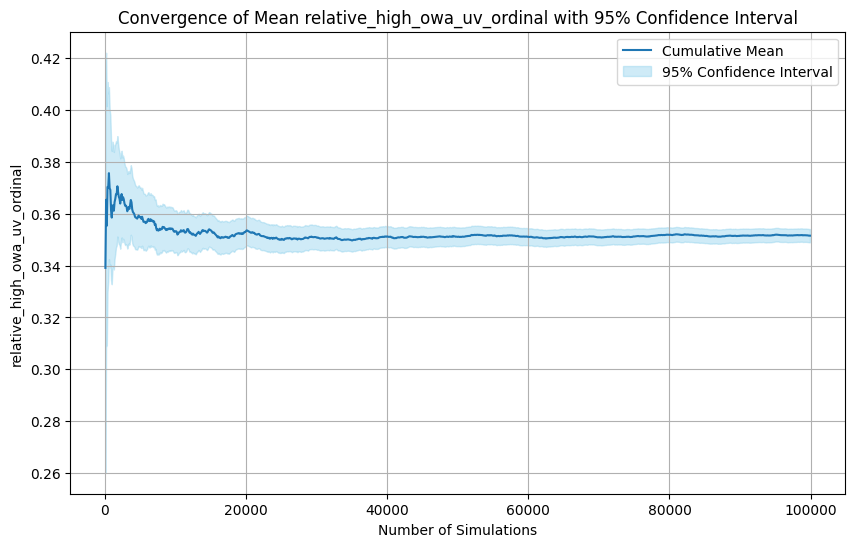

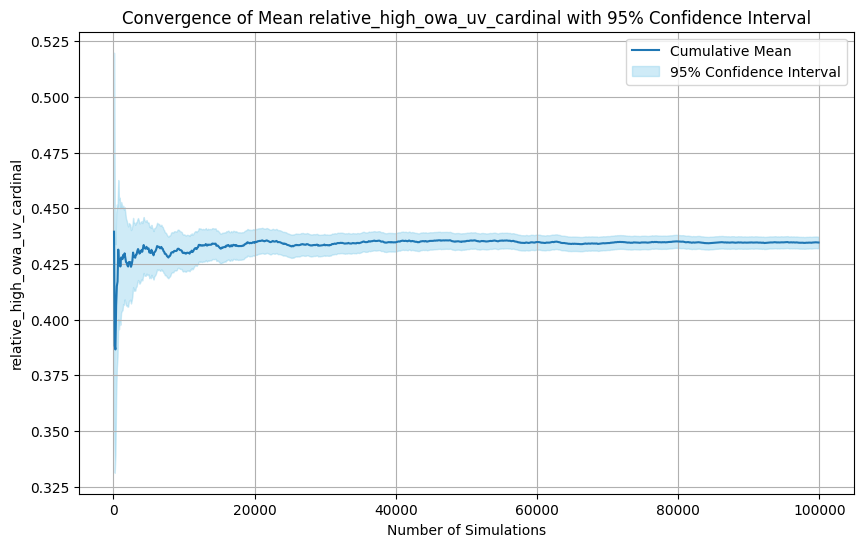

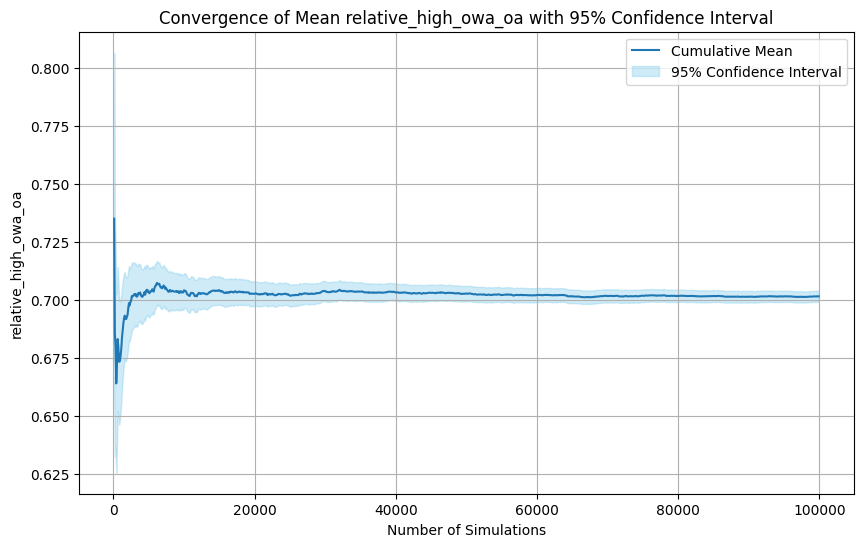

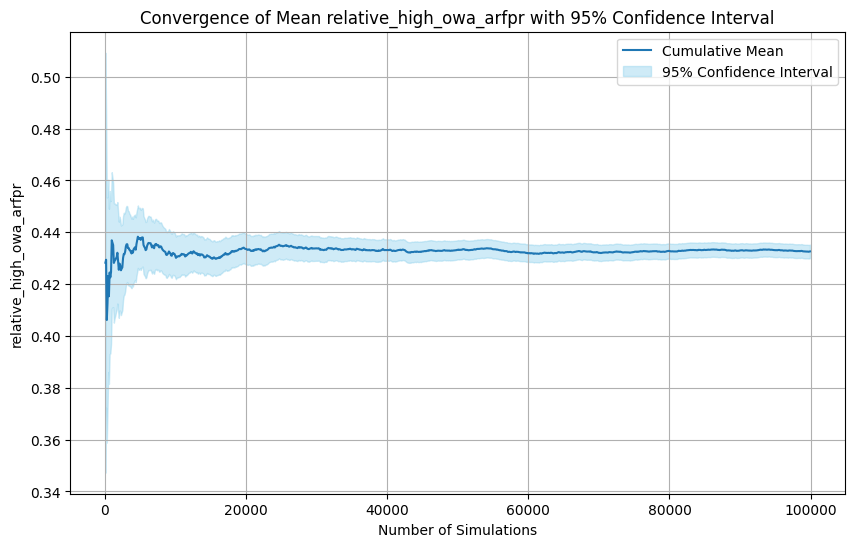

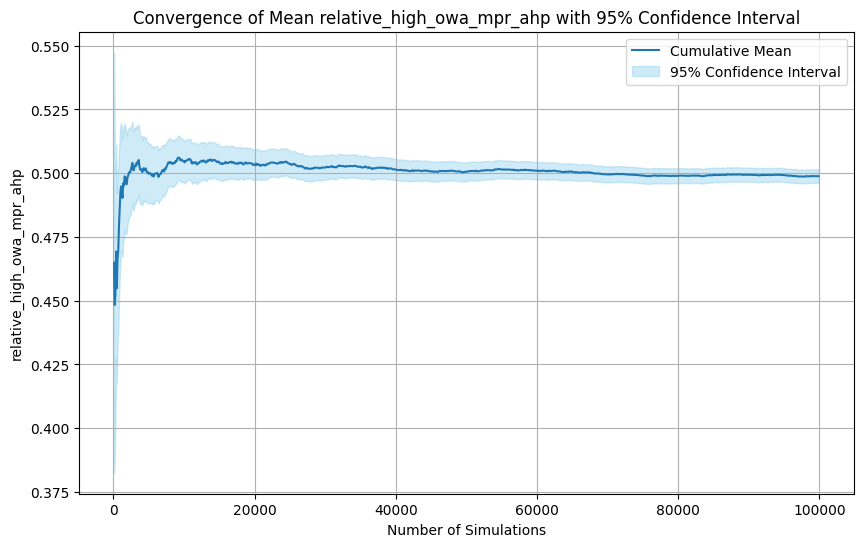

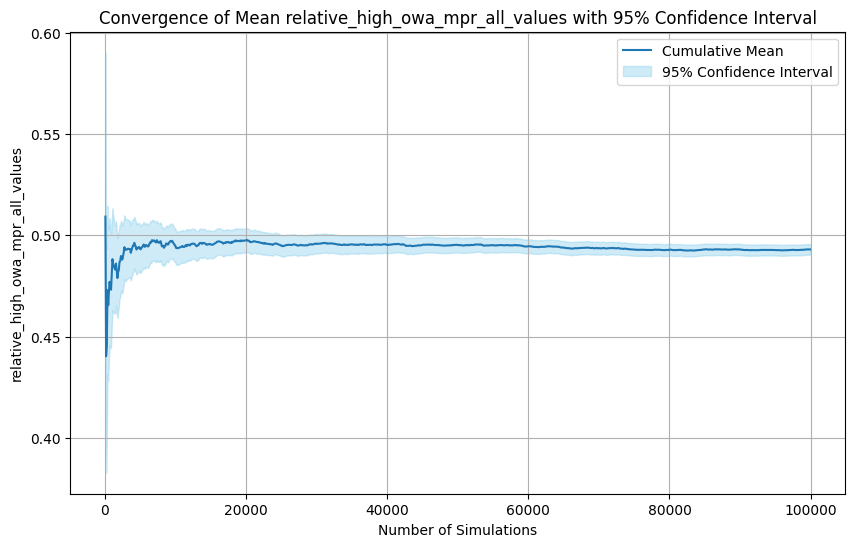

In [ ]:
test_convergence_from_config('formats_combined_div_sqrt')

# Run-to-Run Stability Analysis

## First Technique - Early Aggregation

### All ARFPR Config

The Confidence Intervals are close enough, so the stability is proved.

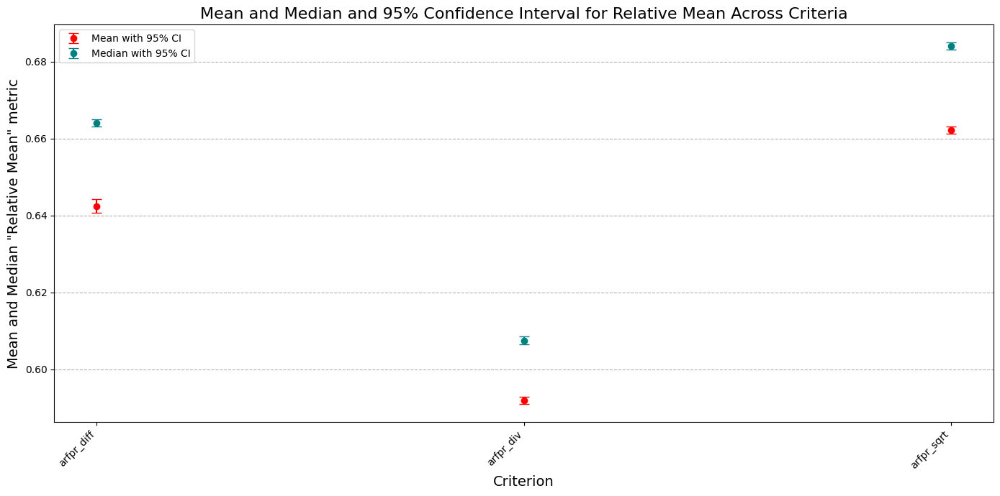

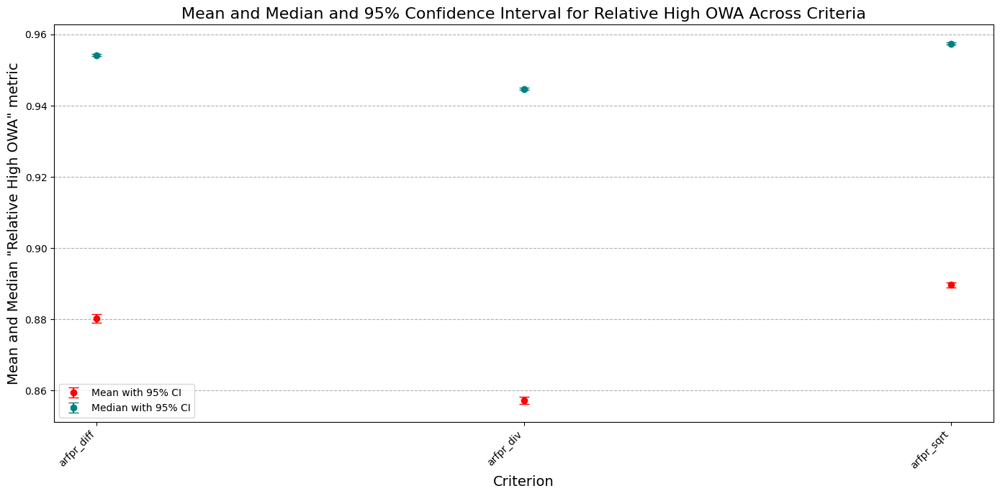

In [ ]:
arfpr_mean_cis, arfpr_median_cis = test_run_to_run_stability_from_config('all_arfpr',
                                                                         plot_graph=False)
for metric in ['relative_avg', 'relative_high_owa']:
  plot_cis_from_dict(arfpr_mean_cis, arfpr_median_cis, metric)

# print_mean_cis(arfpr_mean_cis)
# print_median_cis(arfpr_median_cis)

### All MPR AHP Config

The Confidence Intervals are close enough, so the stability is proved.

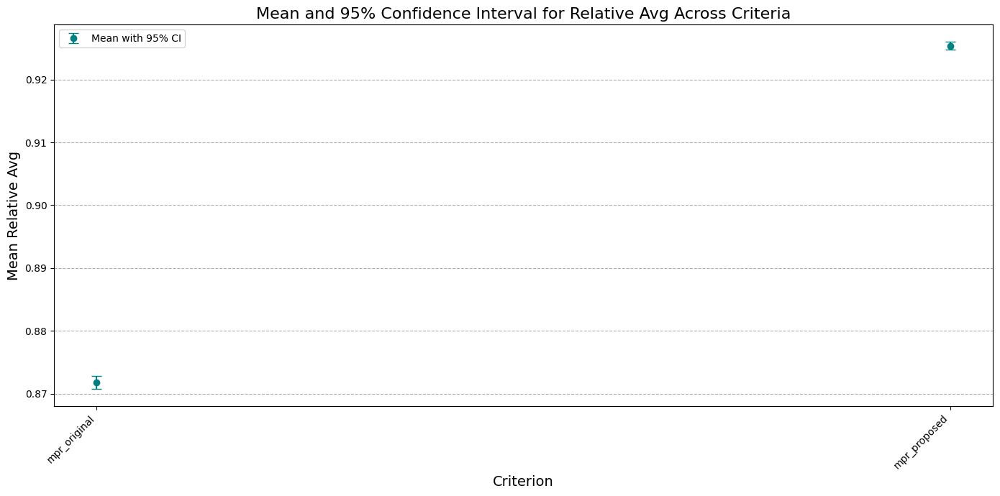

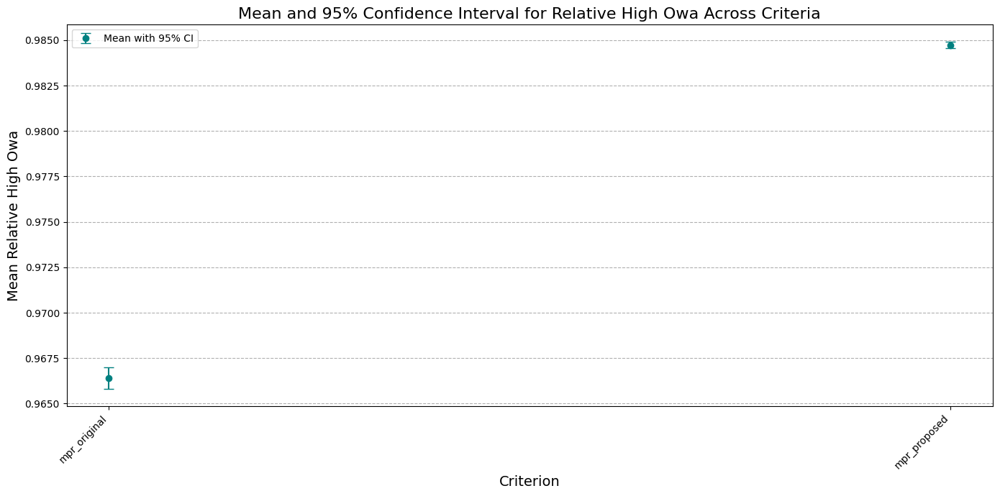

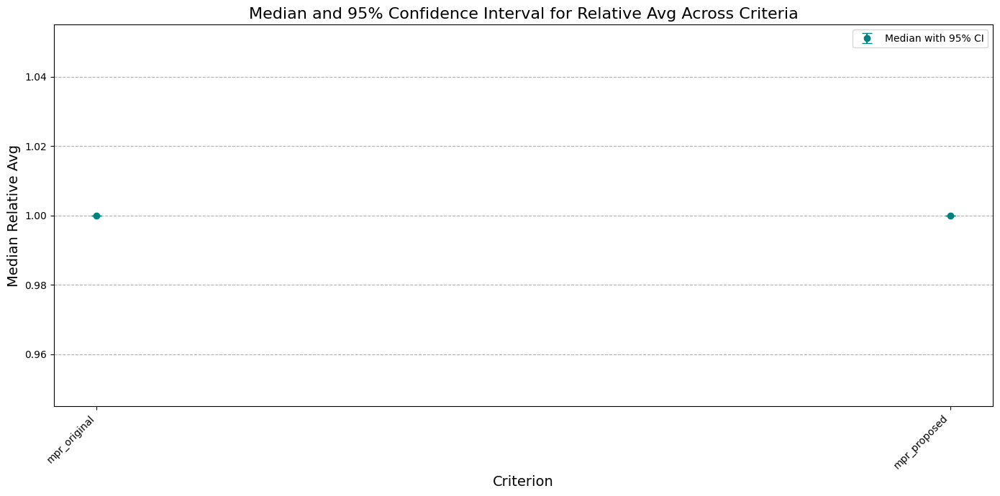

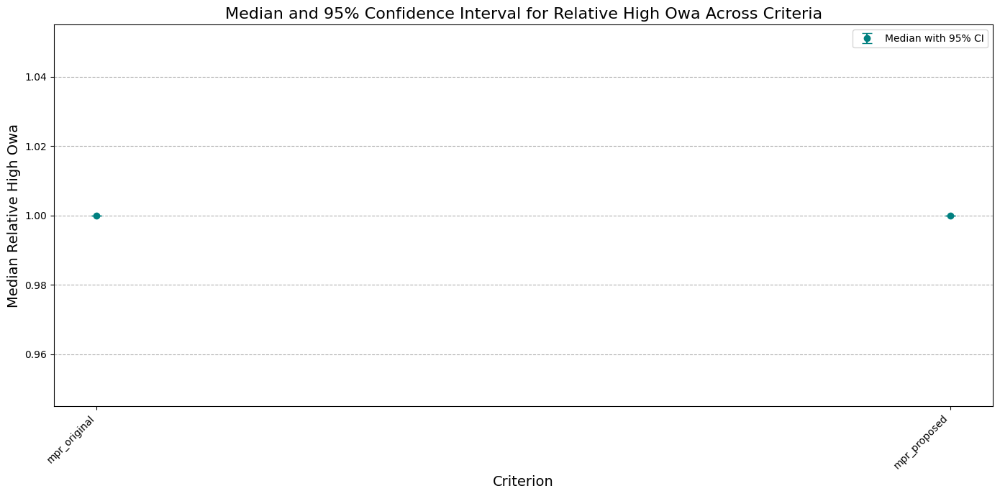

==================== Confidence Intervals for relative_avg_mpr_original ===========================
Final Mean Estimate: 0.8718
95% Confidence Interval (Mean): [0.8708, 0.8728]

==================== Confidence Intervals for relative_avg_mpr_proposed ===========================
Final Mean Estimate: 0.9254
95% Confidence Interval (Mean): [0.9248, 0.9260]

==================== Confidence Intervals for relative_high_owa_mpr_original ===========================
Final Mean Estimate: 0.9664
95% Confidence Interval (Mean): [0.9658, 0.9670]

==================== Confidence Intervals for relative_high_owa_mpr_proposed ===========================
Final Mean Estimate: 0.9847
95% Confidence Interval (Mean): [0.9845, 0.9849]

==================== Confidence Intervals for relative_avg_mpr_original ===========================
Final Median Estimate: 1.0000
95% Confidence Interval (Median): [1.0000, 1.0000]

==================== Confidence Intervals for relative_avg_mpr_proposed ========================

In [ ]:
mpr_mean_cis, mpr_median_cis = test_run_to_run_stability_from_config('all_mpr_ahp',
                                                                     plot_graph=True)
print_mean_cis(mpr_mean_cis)
print_median_cis(mpr_median_cis)

### All MPR All Values Config

The Confidence Intervals are close enough, so the stability is proved.


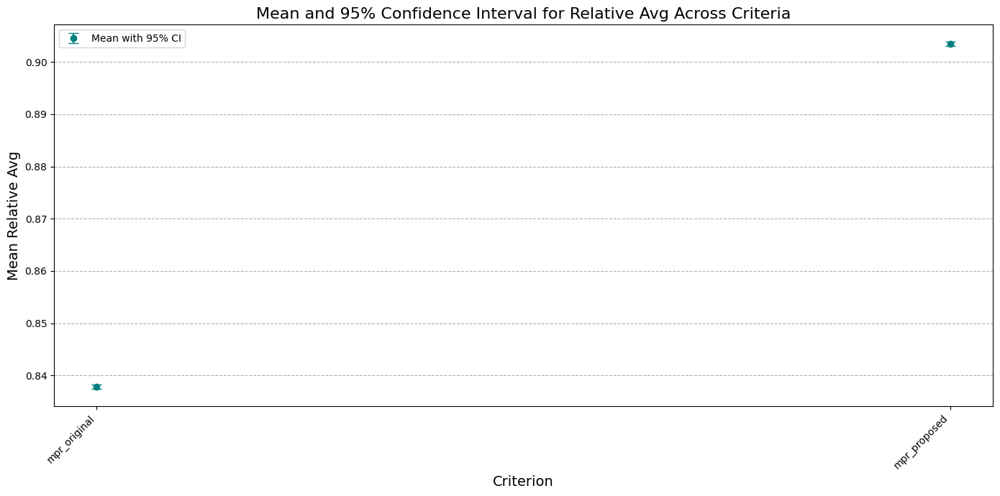

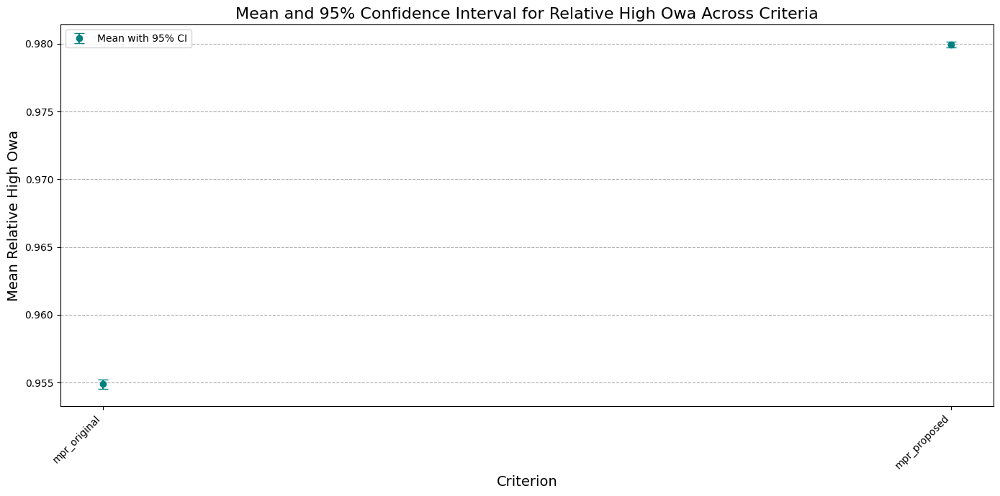

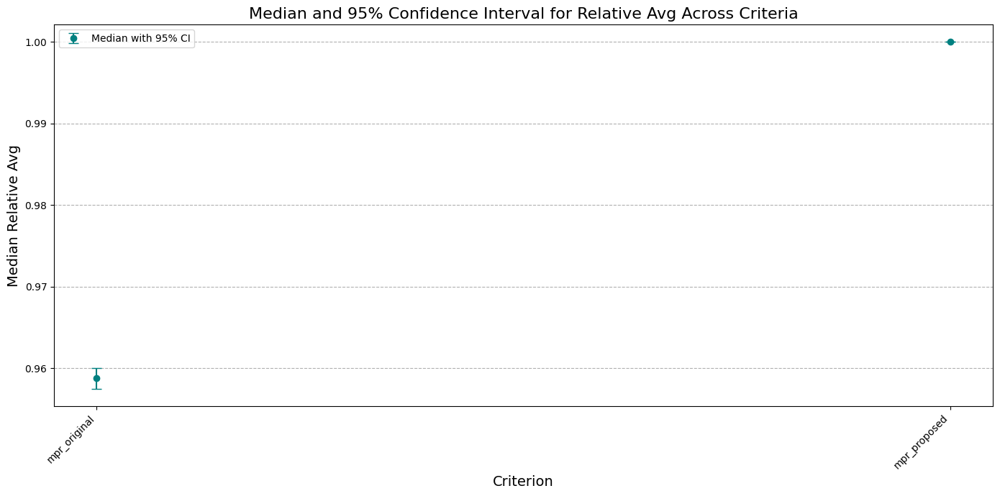

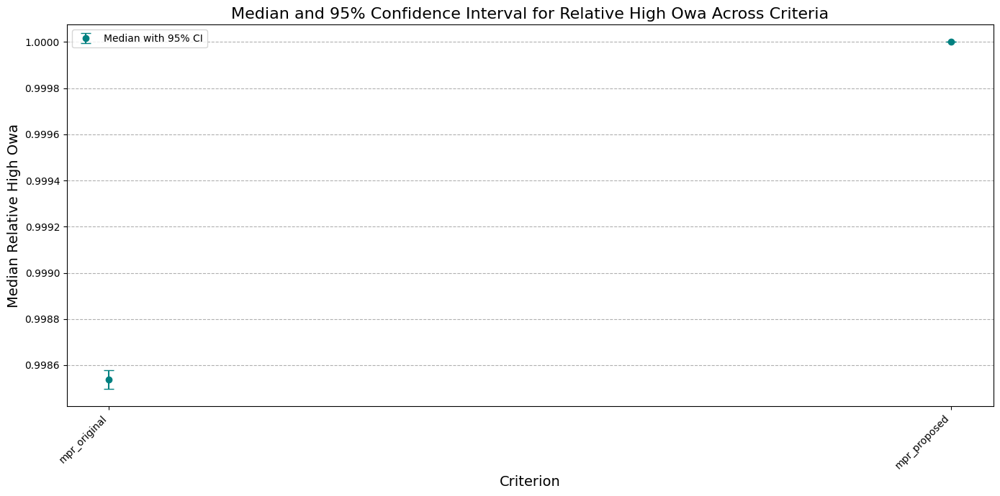

==================== Confidence Intervals for relative_avg_mpr_original ===========================
Final Mean Estimate: 0.8378
95% Confidence Interval (Mean): [0.8374, 0.8382]

==================== Confidence Intervals for relative_avg_mpr_proposed ===========================
Final Mean Estimate: 0.9035
95% Confidence Interval (Mean): [0.9031, 0.9038]

==================== Confidence Intervals for relative_high_owa_mpr_original ===========================
Final Mean Estimate: 0.9549
95% Confidence Interval (Mean): [0.9545, 0.9552]

==================== Confidence Intervals for relative_high_owa_mpr_proposed ===========================
Final Mean Estimate: 0.9799
95% Confidence Interval (Mean): [0.9797, 0.9801]

==================== Confidence Intervals for relative_avg_mpr_original ===========================
Final Median Estimate: 0.9589
95% Confidence Interval (Median): [0.9575, 0.9600]

==================== Confidence Intervals for relative_avg_mpr_proposed ========================

In [ ]:
mpr2_mean_cis, mpr2_median_cis = test_run_to_run_stability_from_config('all_mpr_all_values',
                                                                       plot_graph=True)
print_mean_cis(mpr2_mean_cis)
print_median_cis(mpr2_median_cis)

### All OA Config

The Confidence Intervals are close enough, so the stability is proved.

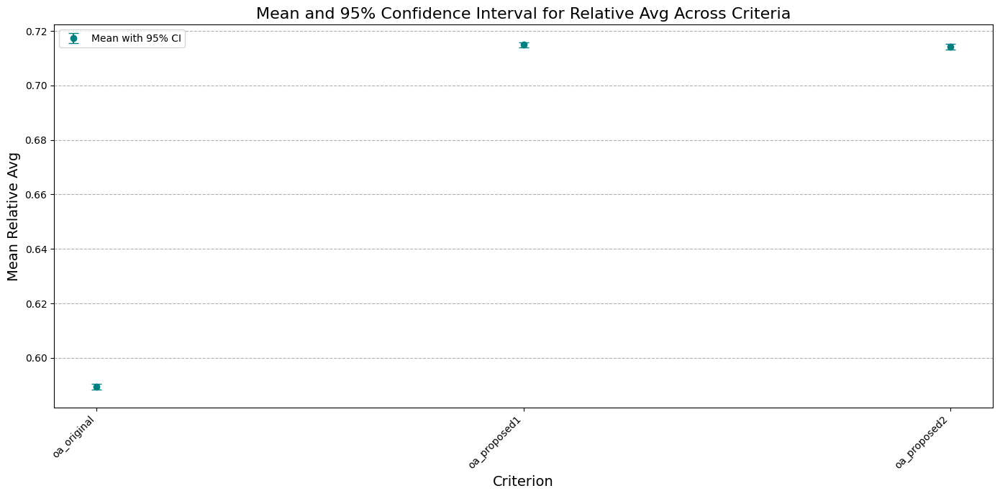

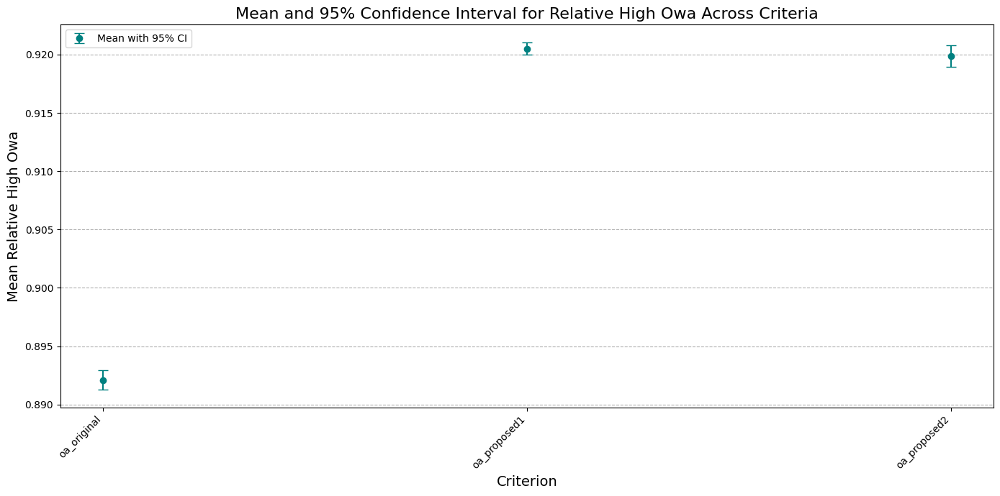

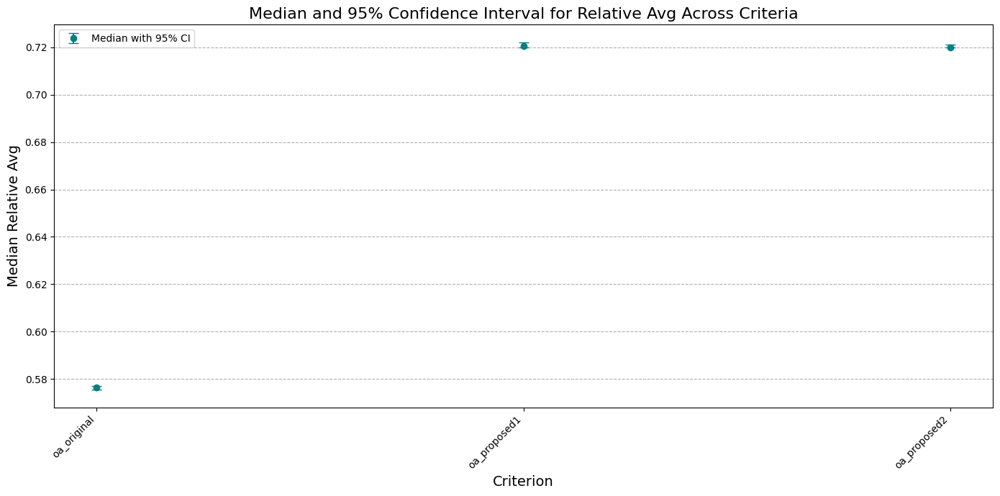

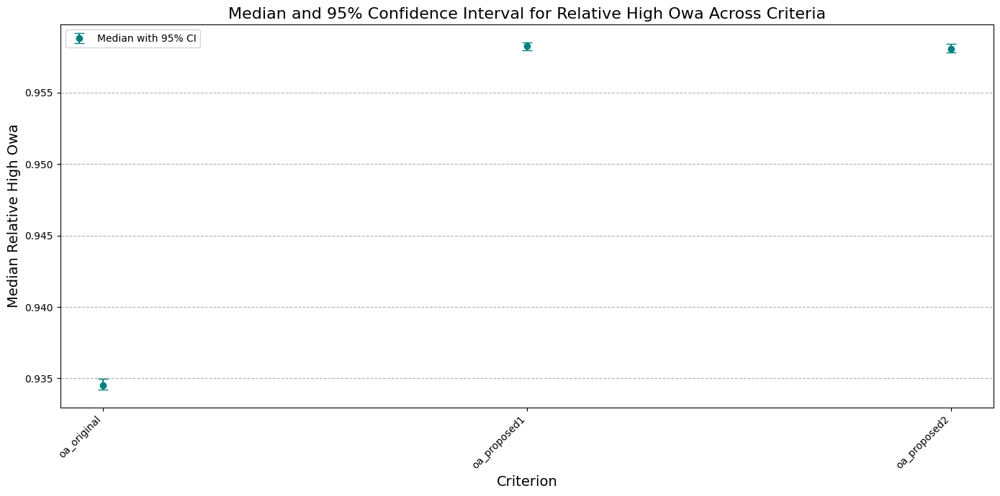

==================== Confidence Intervals for relative_avg_oa_original ===========================
Final Mean Estimate: 0.5893
95% Confidence Interval (Mean): [0.5882, 0.5904]

==================== Confidence Intervals for relative_avg_oa_proposed1 ===========================
Final Mean Estimate: 0.7150
95% Confidence Interval (Mean): [0.7140, 0.7160]

==================== Confidence Intervals for relative_avg_oa_proposed2 ===========================
Final Mean Estimate: 0.7142
95% Confidence Interval (Mean): [0.7131, 0.7152]

==================== Confidence Intervals for relative_high_owa_oa_original ===========================
Final Mean Estimate: 0.8921
95% Confidence Interval (Mean): [0.8913, 0.8929]

==================== Confidence Intervals for relative_high_owa_oa_proposed1 ===========================
Final Mean Estimate: 0.9205
95% Confidence Interval (Mean): [0.9200, 0.9211]

==================== Confidence Intervals for relative_high_owa_oa_proposed2 =========================

In [ ]:
oa_mean_cis, oa_median_cis = test_run_to_run_stability_from_config('all_oa',
                                                                   plot_graph=True)
print_mean_cis(oa_mean_cis)
print_median_cis(oa_median_cis)

### All RN Fixed Scale Config

The Confidence Intervals are close enough, so the stability is proved.

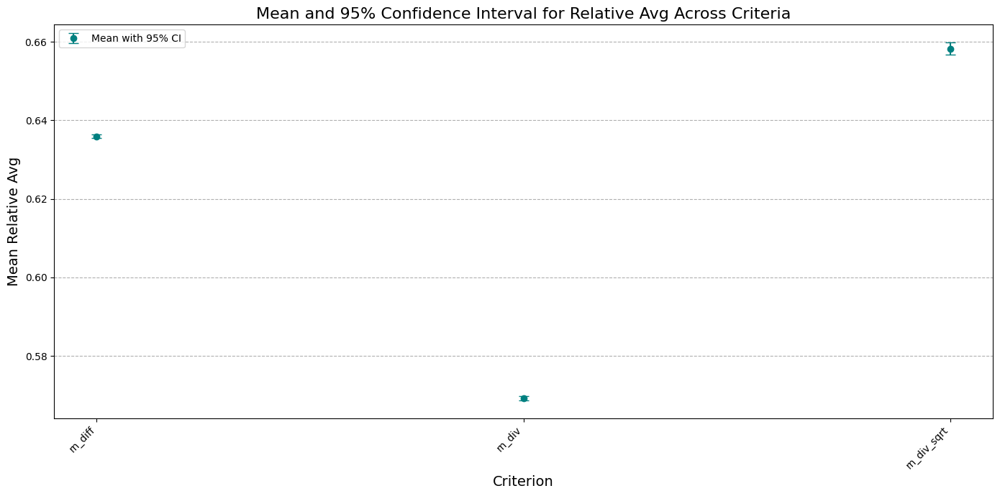

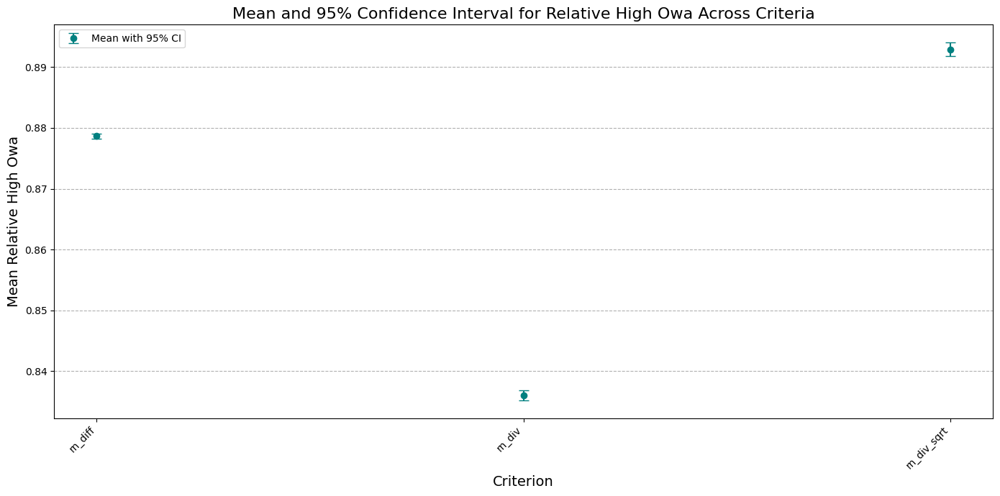

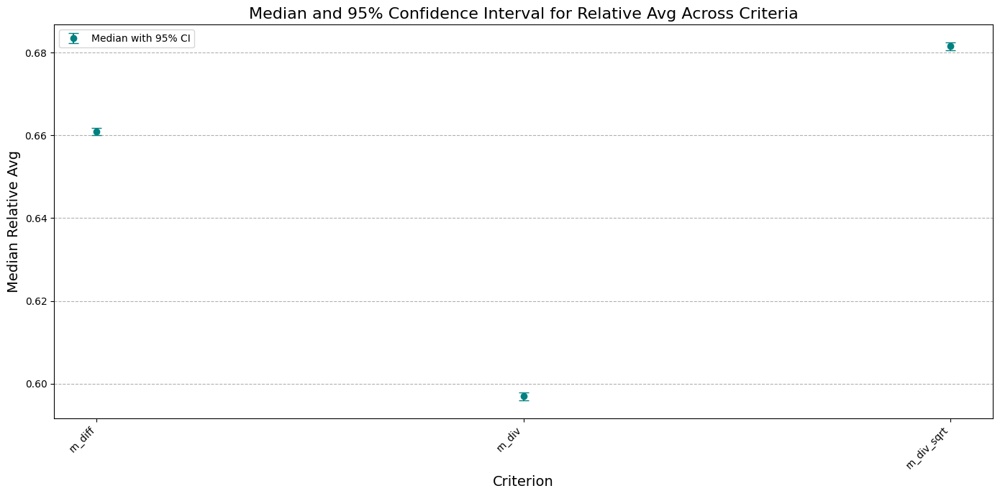

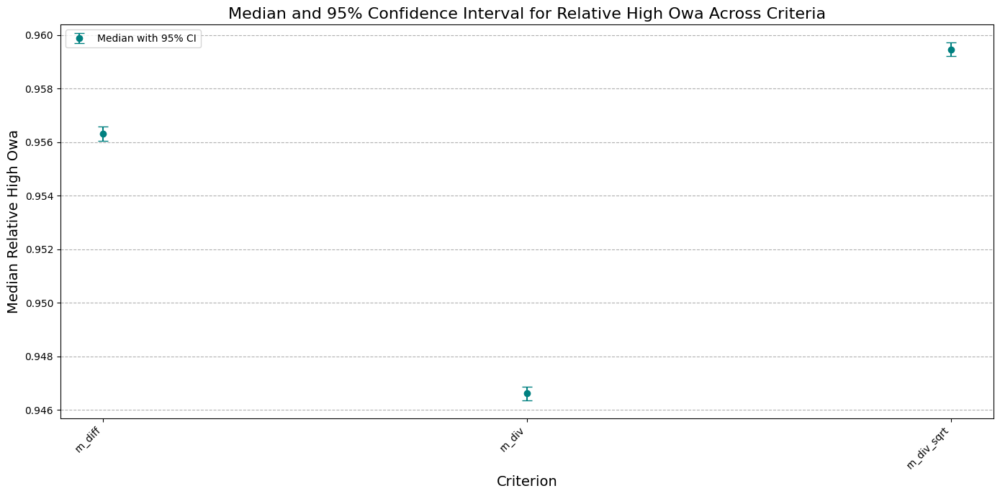

==================== Confidence Intervals for relative_avg_rn_diff ===========================
Final Mean Estimate: 0.6359
95% Confidence Interval (Mean): [0.6355, 0.6363]

==================== Confidence Intervals for relative_avg_rn_div ===========================
Final Mean Estimate: 0.5693
95% Confidence Interval (Mean): [0.5687, 0.5699]

==================== Confidence Intervals for relative_avg_rn_div_sqrt ===========================
Final Mean Estimate: 0.6583
95% Confidence Interval (Mean): [0.6567, 0.6598]

==================== Confidence Intervals for relative_high_owa_rn_diff ===========================
Final Mean Estimate: 0.8786
95% Confidence Interval (Mean): [0.8782, 0.8791]

==================== Confidence Intervals for relative_high_owa_rn_div ===========================
Final Mean Estimate: 0.8360
95% Confidence Interval (Mean): [0.8352, 0.8368]

==================== Confidence Intervals for relative_high_owa_rn_div_sqrt ===========================
Final Mean Estimate

In [ ]:
rn_fs_mean_cis, rn_fs_median_cis = test_run_to_run_stability_from_config('all_rn_fixed_scale',
                                                                         plot_graph=True)
print_mean_cis(rn_fs_mean_cis)
print_median_cis(rn_fs_median_cis)

### All RN From Data Config

The Confidence Intervals are close enough, so the stability is proved.

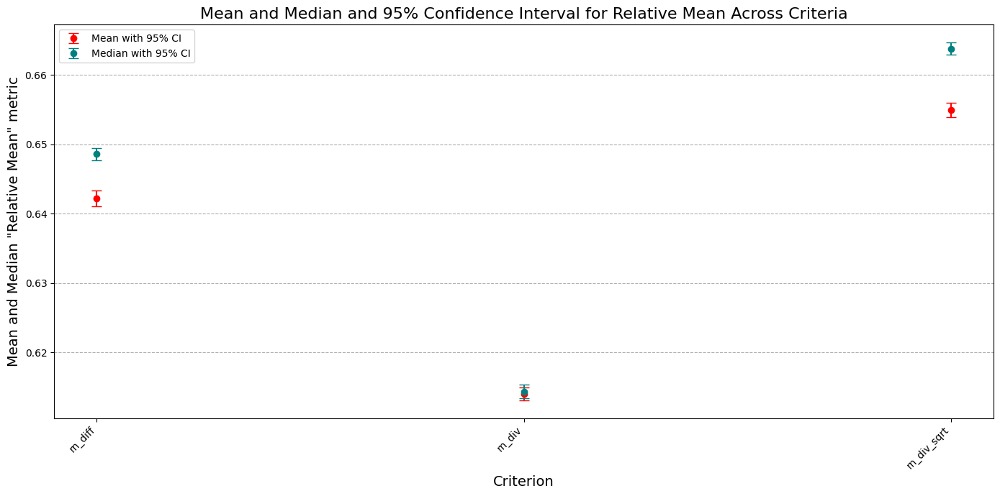

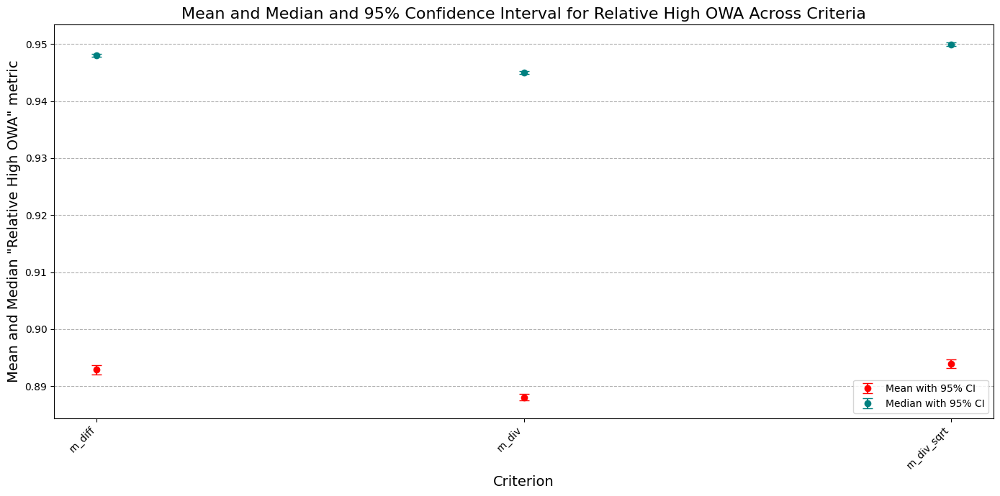

In [ ]:
rn_fd_mean_cis, rn_fd_median_cis = test_run_to_run_stability_from_config('all_rn_from_data',
                                                                         plot_graph=False)
for metric in ['relative_avg', 'relative_high_owa']:
  plot_cis_from_dict(rn_fd_mean_cis, rn_fd_median_cis, metric)
# print_mean_cis(rn_fd_mean_cis)
# print_median_cis(rn_fd_median_cis)

### All UV Cardinal Config

The Confidence Intervals are close enough, so the stability is proved.

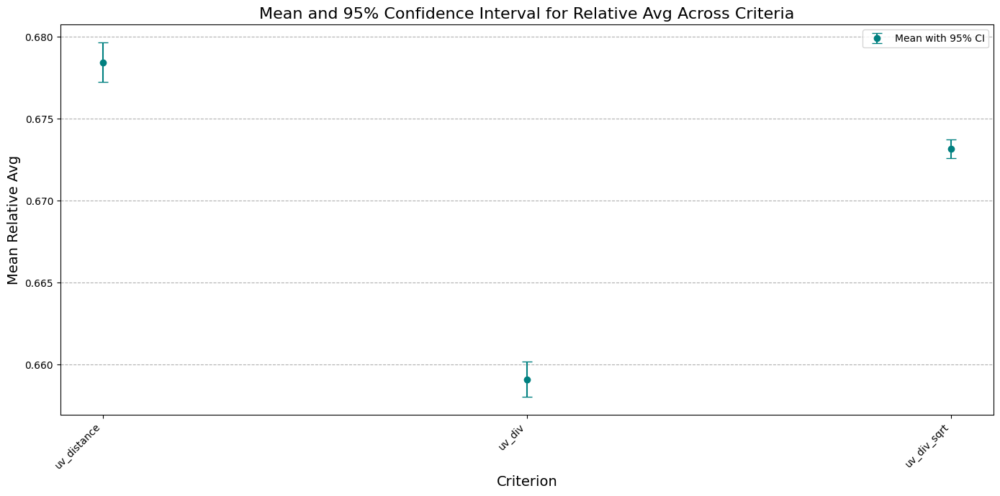

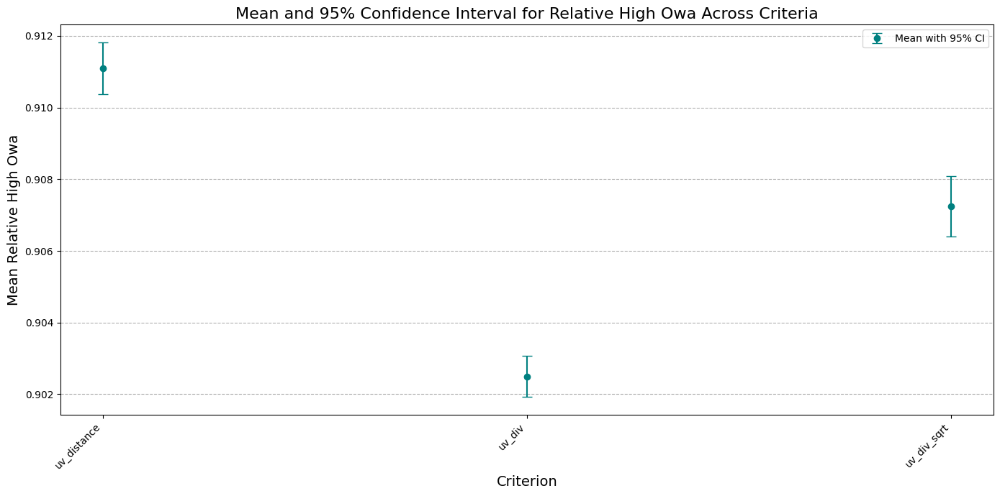

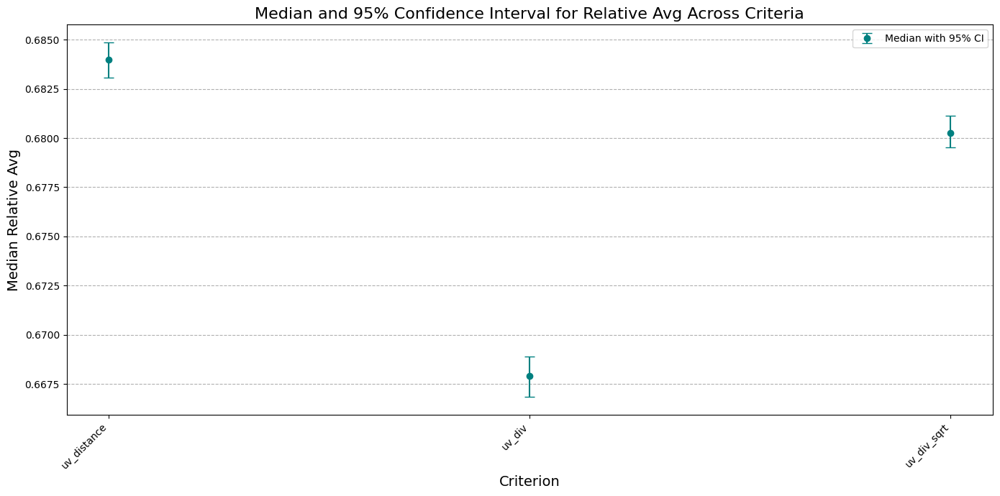

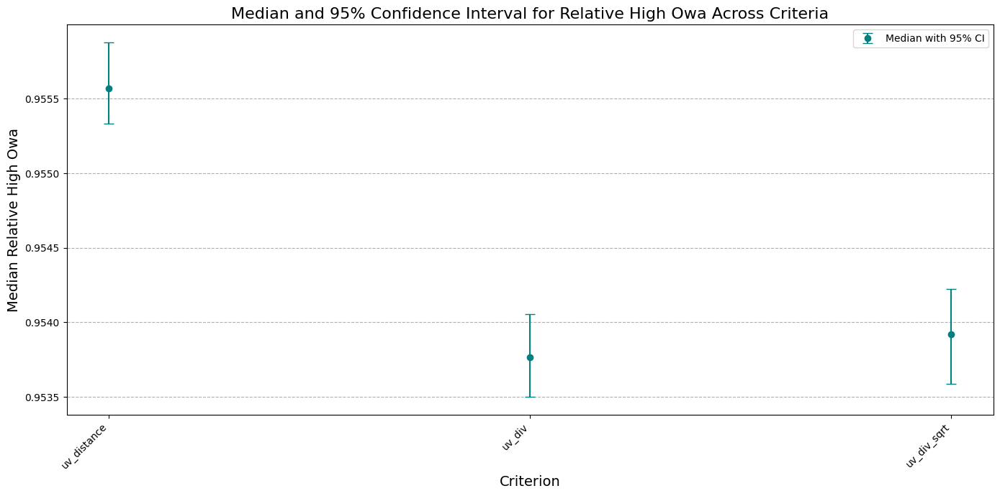

==================== Confidence Intervals for relative_avg_uv_distance ===========================
Final Mean Estimate: 0.6784
95% Confidence Interval (Mean): [0.6772, 0.6797]

==================== Confidence Intervals for relative_avg_uv_div ===========================
Final Mean Estimate: 0.6591
95% Confidence Interval (Mean): [0.6580, 0.6602]

==================== Confidence Intervals for relative_avg_uv_div_sqrt ===========================
Final Mean Estimate: 0.6732
95% Confidence Interval (Mean): [0.6726, 0.6737]

==================== Confidence Intervals for relative_high_owa_uv_distance ===========================
Final Mean Estimate: 0.9111
95% Confidence Interval (Mean): [0.9104, 0.9118]

==================== Confidence Intervals for relative_high_owa_uv_div ===========================
Final Mean Estimate: 0.9025
95% Confidence Interval (Mean): [0.9019, 0.9031]

==================== Confidence Intervals for relative_high_owa_uv_div_sqrt ===========================
Final Mean 

In [ ]:
uv_card_mean_cis, uv_card_median_cis = test_run_to_run_stability_from_config('all_uv_cardinal',
                                                                             plot_graph=True)
print_mean_cis(uv_card_mean_cis)
print_median_cis(uv_card_median_cis)

### All UV Ordinal Config

The Confidence Intervals are close enough, so the stability is proved.

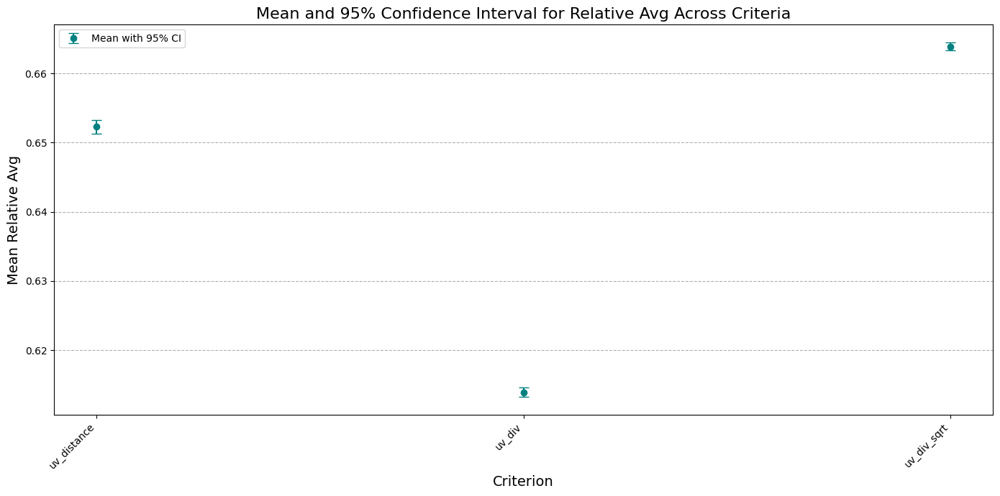

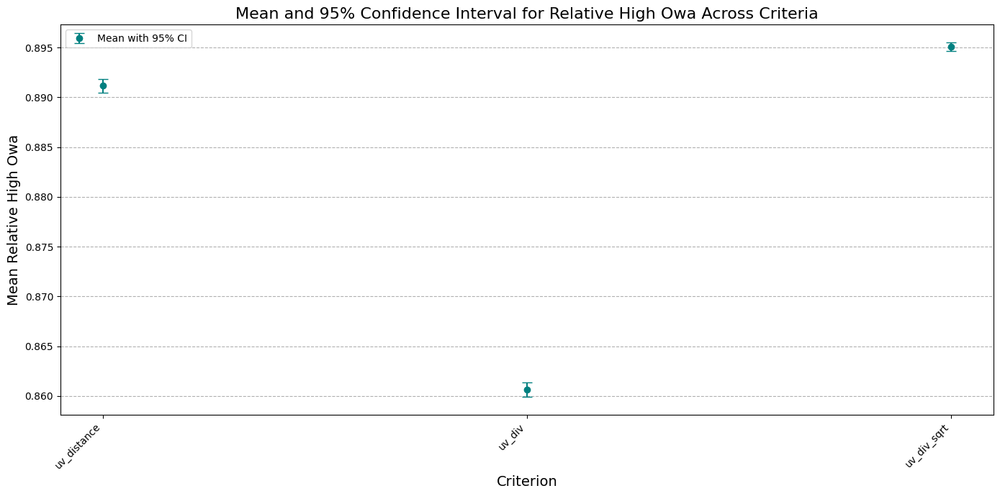

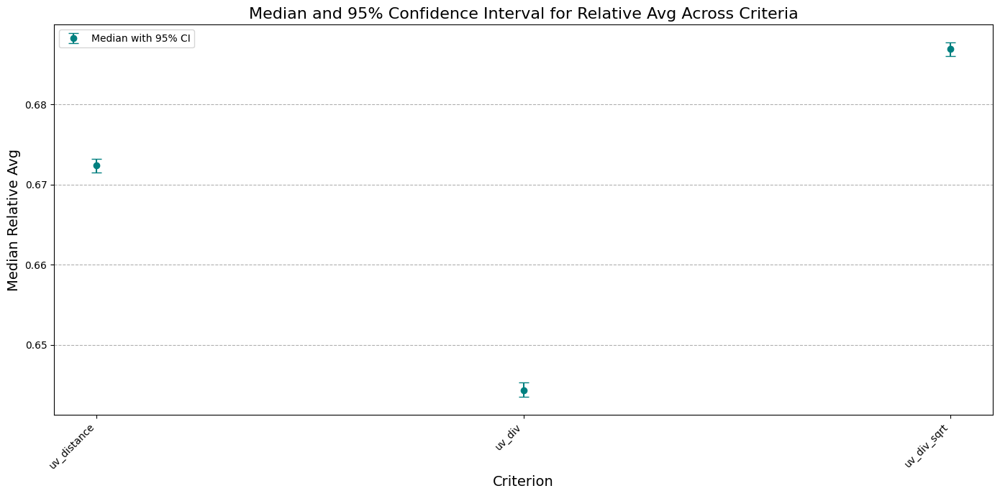

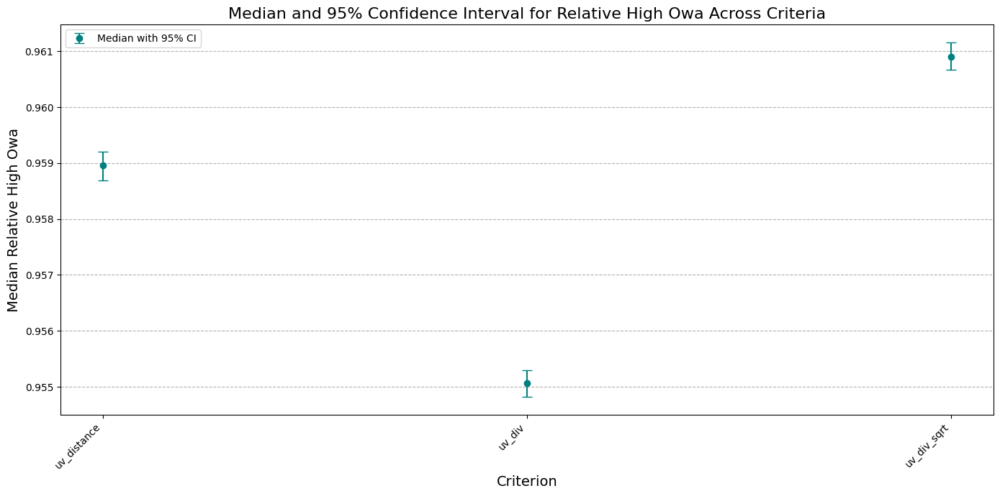

==================== Confidence Intervals for relative_avg_uv_distance ===========================
Final Mean Estimate: 0.6523
95% Confidence Interval (Mean): [0.6513, 0.6533]

==================== Confidence Intervals for relative_avg_uv_div ===========================
Final Mean Estimate: 0.6139
95% Confidence Interval (Mean): [0.6132, 0.6146]

==================== Confidence Intervals for relative_avg_uv_div_sqrt ===========================
Final Mean Estimate: 0.6639
95% Confidence Interval (Mean): [0.6633, 0.6645]

==================== Confidence Intervals for relative_high_owa_uv_distance ===========================
Final Mean Estimate: 0.8911
95% Confidence Interval (Mean): [0.8905, 0.8918]

==================== Confidence Intervals for relative_high_owa_uv_div ===========================
Final Mean Estimate: 0.8606
95% Confidence Interval (Mean): [0.8599, 0.8614]

==================== Confidence Intervals for relative_high_owa_uv_div_sqrt ===========================
Final Mean 

In [ ]:
uv_ord_mean_cis, uv_ord_median_cis = test_run_to_run_stability_from_config('all_uv_ordinal',
                                                                             plot_graph=True)
print_mean_cis(uv_ord_mean_cis)
print_median_cis(uv_ord_median_cis)

### Formats Combined Proposed Functions Config

The Confidence Intervals are close enough, so the stability is proved.

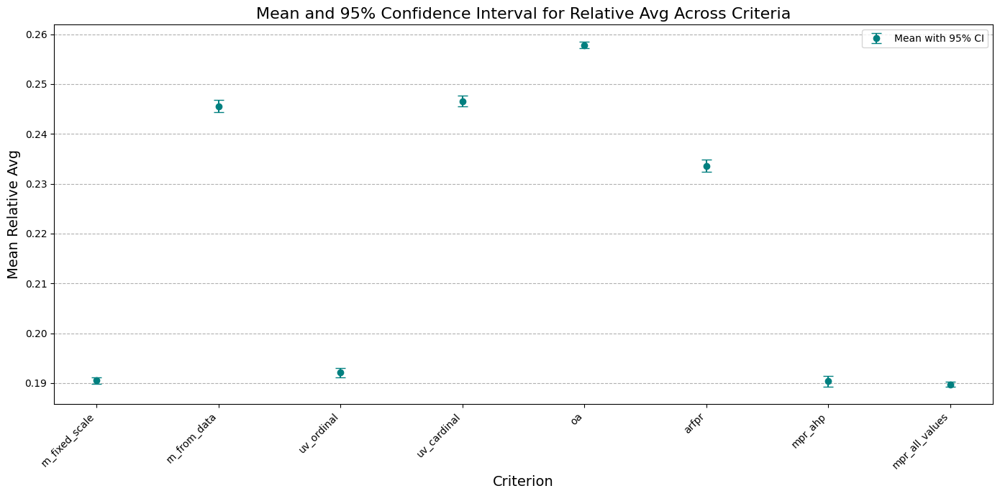

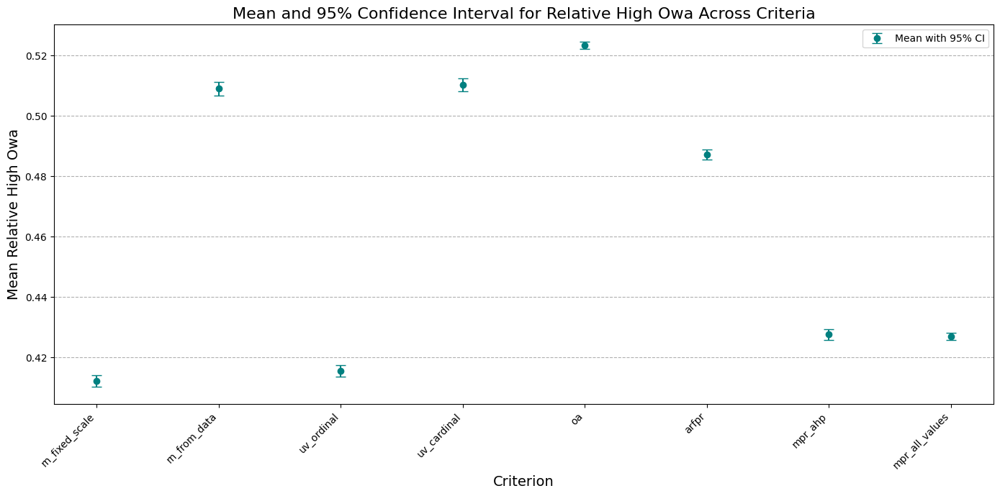

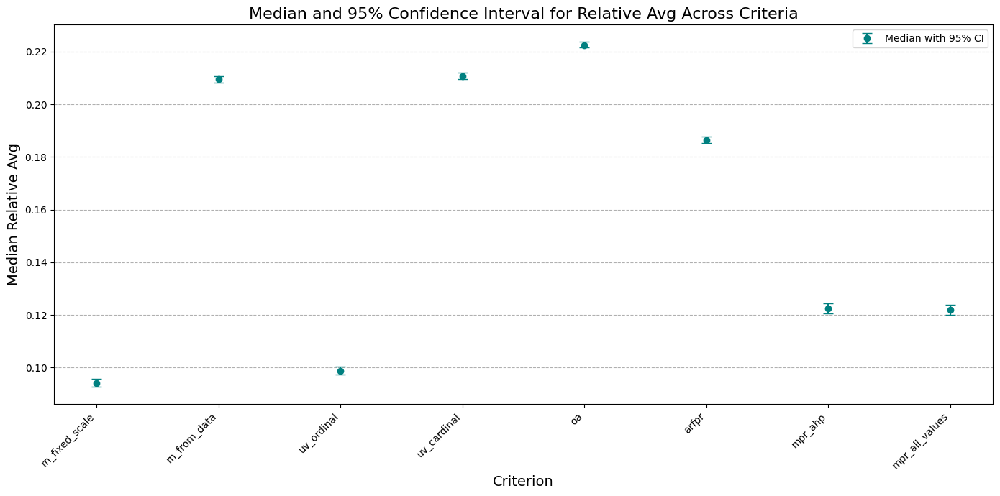

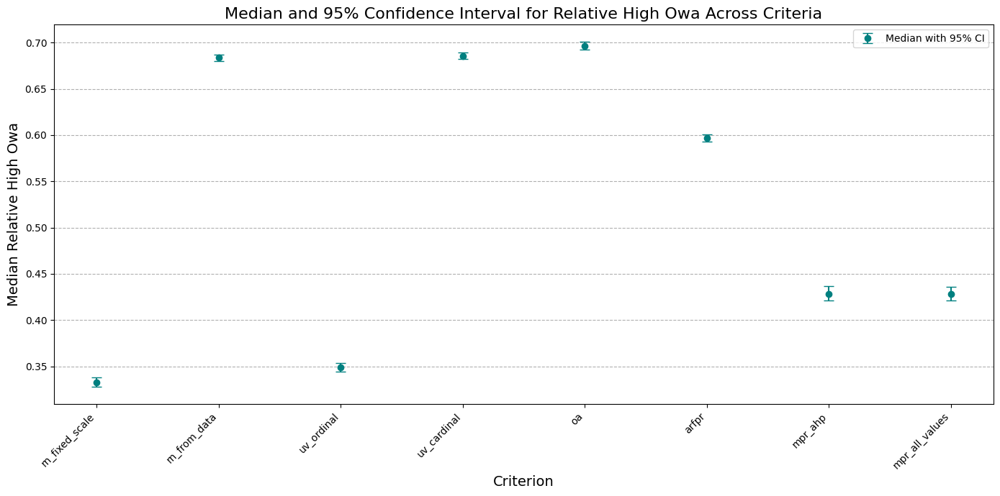

==================== Confidence Intervals for relative_avg_rn_fixed_scale ===========================
Final Mean Estimate: 0.1905
95% Confidence Interval (Mean): [0.1898, 0.1911]

==================== Confidence Intervals for relative_avg_rn_from_data ===========================
Final Mean Estimate: 0.2456
95% Confidence Interval (Mean): [0.2444, 0.2468]

==================== Confidence Intervals for relative_avg_uv_ordinal ===========================
Final Mean Estimate: 0.1921
95% Confidence Interval (Mean): [0.1912, 0.1930]

==================== Confidence Intervals for relative_avg_uv_cardinal ===========================
Final Mean Estimate: 0.2466
95% Confidence Interval (Mean): [0.2455, 0.2477]

==================== Confidence Intervals for relative_avg_oa ===========================
Final Mean Estimate: 0.2578
95% Confidence Interval (Mean): [0.2572, 0.2584]

==================== Confidence Intervals for relative_avg_arfpr ===========================
Final Mean Estimate: 0.2336


In [ ]:
proposed_mean_cis, proposed_median_cis = test_run_to_run_stability_from_config('formats_combined_proposed',
                                                                               plot_graph=True)
print_mean_cis(proposed_mean_cis)
print_median_cis(proposed_median_cis)

### Lowest Performing Functions Config

The Confidence Intervals are close enough, so the stability is proved.

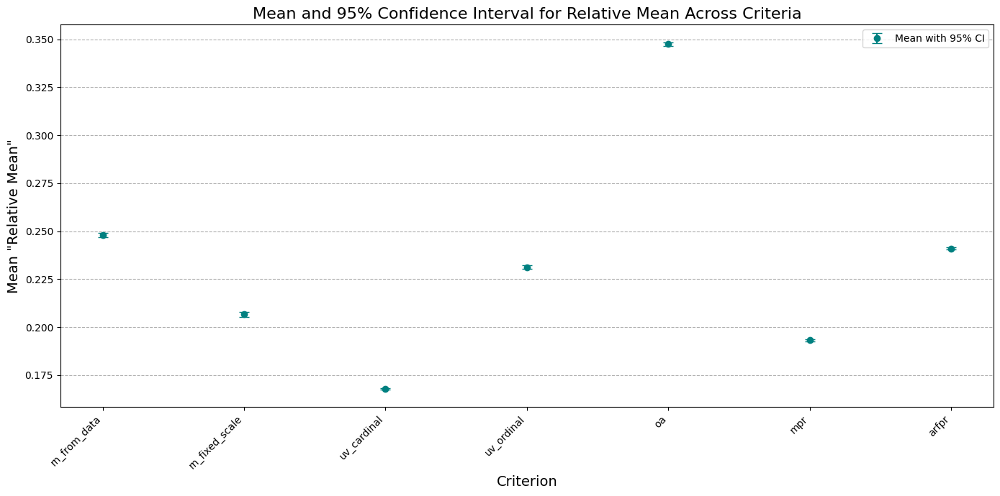

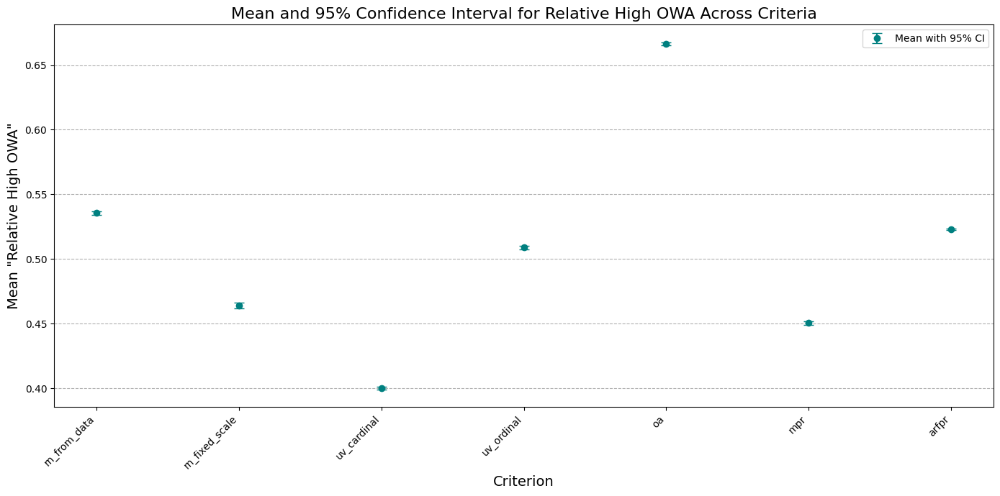

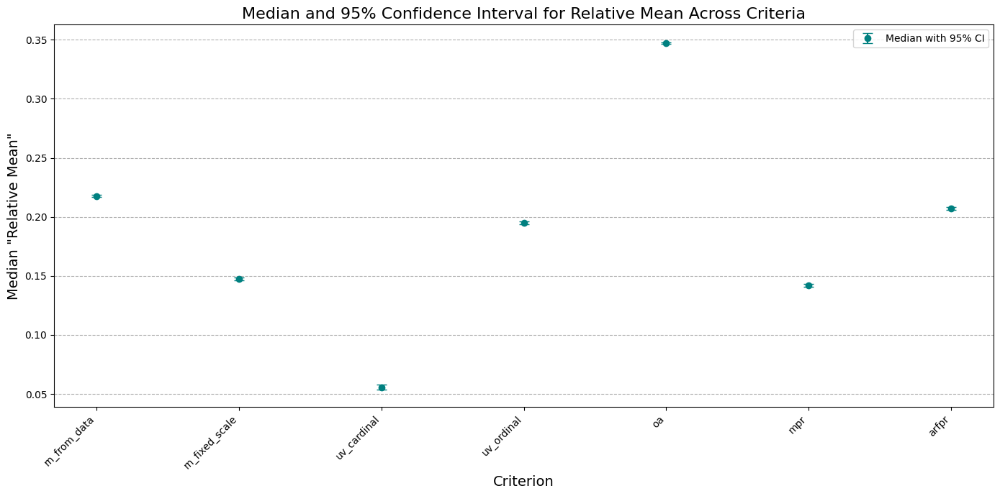

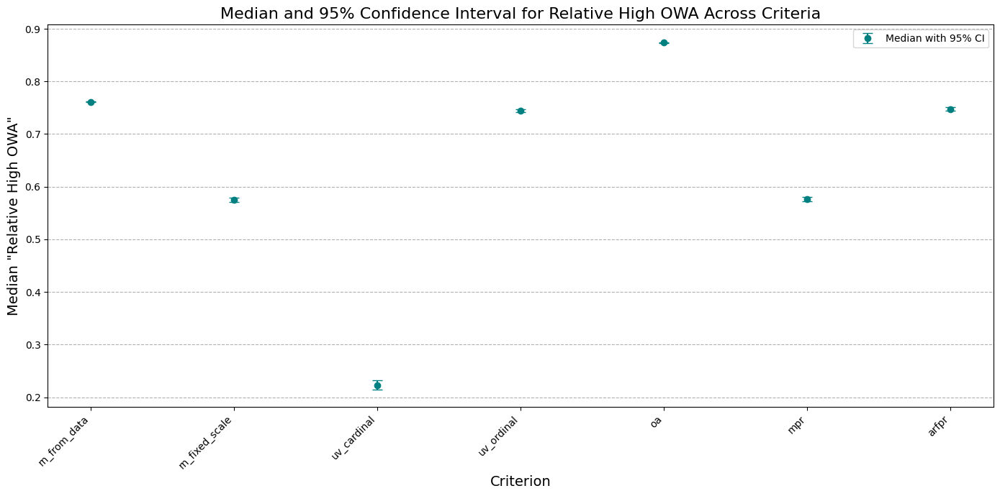

==================== Confidence Intervals for relative_avg_rn_from_data ===========================
Final Mean Estimate: 0.2480
95% Confidence Interval (Mean): [0.2470, 0.2491]

==================== Confidence Intervals for relative_avg_rn_fixed_scale ===========================
Final Mean Estimate: 0.2067
95% Confidence Interval (Mean): [0.2053, 0.2080]

==================== Confidence Intervals for relative_avg_uv_cardinal ===========================
Final Mean Estimate: 0.1679
95% Confidence Interval (Mean): [0.1674, 0.1683]

==================== Confidence Intervals for relative_avg_uv_ordinal ===========================
Final Mean Estimate: 0.2313
95% Confidence Interval (Mean): [0.2305, 0.2321]

==================== Confidence Intervals for relative_avg_oa ===========================
Final Mean Estimate: 0.3475
95% Confidence Interval (Mean): [0.3465, 0.3486]

==================== Confidence Intervals for relative_avg_mpr ===========================
Final Mean Estimate: 0.1932
95

In [ ]:
lowest_mean_cis, lowest_median_cis = test_run_to_run_stability_from_config('lowest_performing',
                                                                           plot_graph=True)
print_mean_cis(lowest_mean_cis)
print_median_cis(lowest_median_cis)

### Highest Performing Functions Config

The Confidence Intervals are close enough, so the stability is proved.

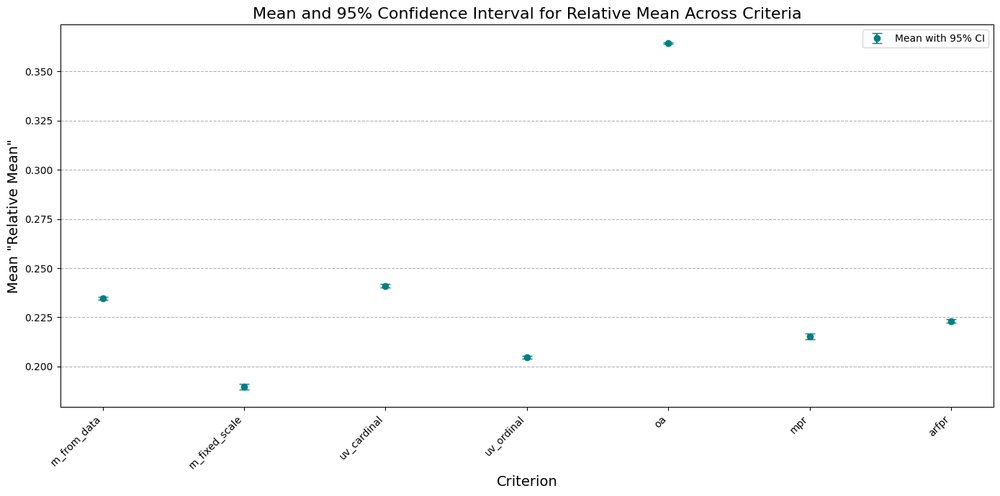

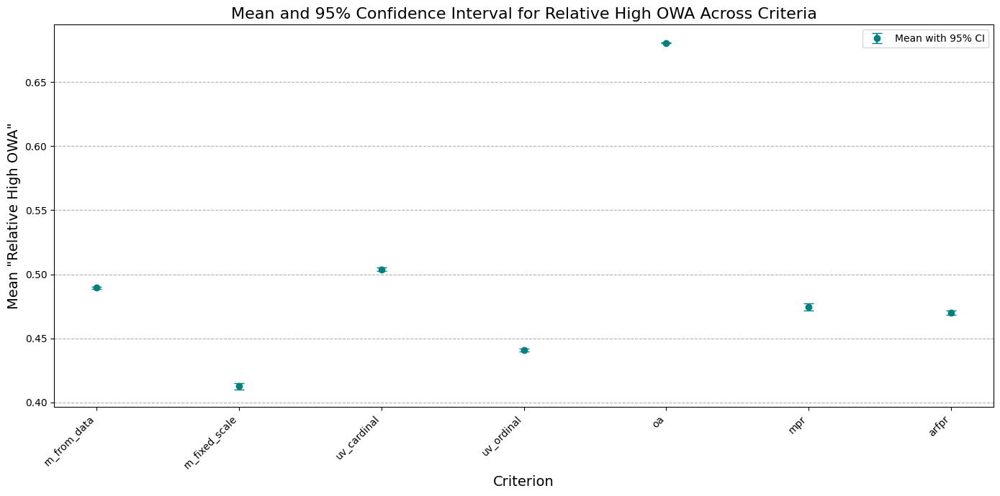

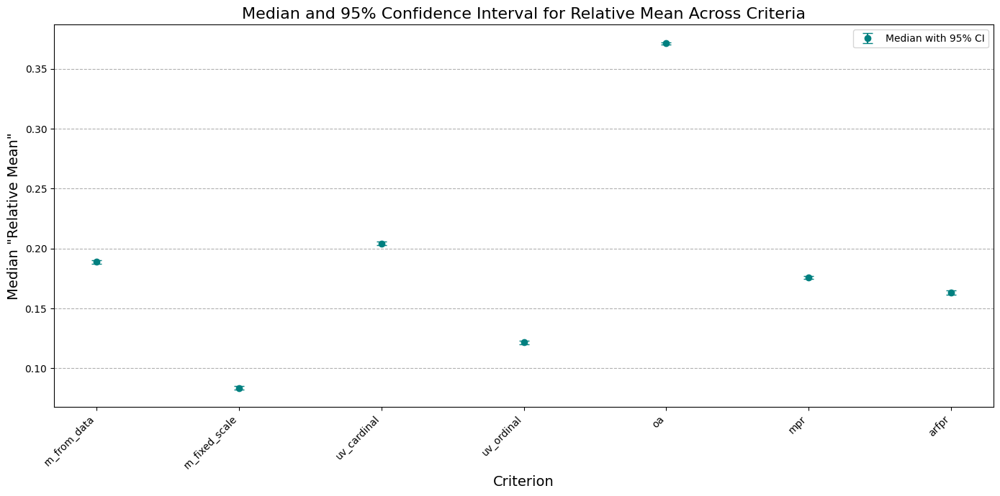

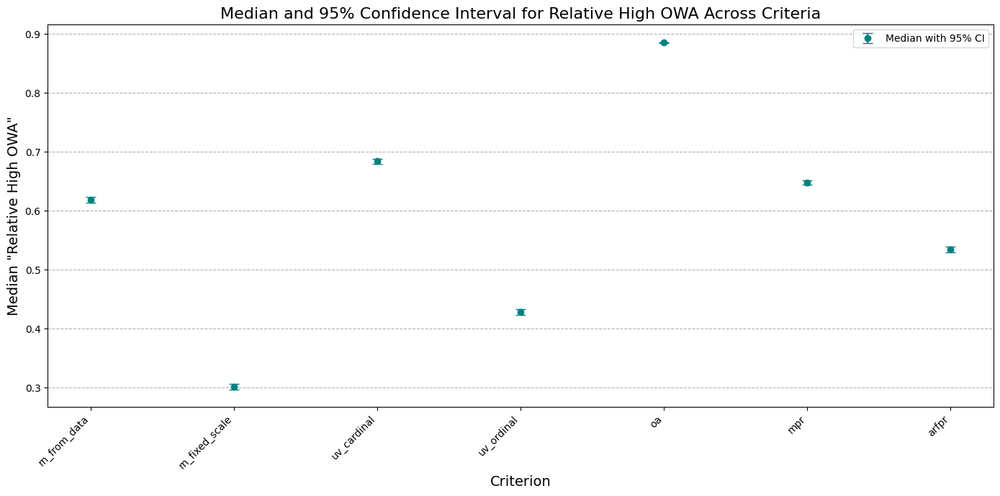

==================== Confidence Intervals for relative_avg_rn_from_data ===========================
Final Mean Estimate: 0.2347
95% Confidence Interval (Mean): [0.2341, 0.2353]

==================== Confidence Intervals for relative_avg_rn_fixed_scale ===========================
Final Mean Estimate: 0.1897
95% Confidence Interval (Mean): [0.1882, 0.1913]

==================== Confidence Intervals for relative_avg_uv_cardinal ===========================
Final Mean Estimate: 0.2410
95% Confidence Interval (Mean): [0.2401, 0.2420]

==================== Confidence Intervals for relative_avg_uv_ordinal ===========================
Final Mean Estimate: 0.2046
95% Confidence Interval (Mean): [0.2039, 0.2054]

==================== Confidence Intervals for relative_avg_oa ===========================
Final Mean Estimate: 0.3645
95% Confidence Interval (Mean): [0.3640, 0.3649]

==================== Confidence Intervals for relative_avg_mpr ===========================
Final Mean Estimate: 0.2154
95

In [ ]:
highest_mean_cis, highest_median_cis = test_run_to_run_stability_from_config('highest_performing',
                                                                             plot_graph=True)
print_mean_cis(highest_mean_cis)
print_median_cis(highest_median_cis)

### Formats Combined All Functions Config

The Confidence Intervals are close enough, so the stability is proved.

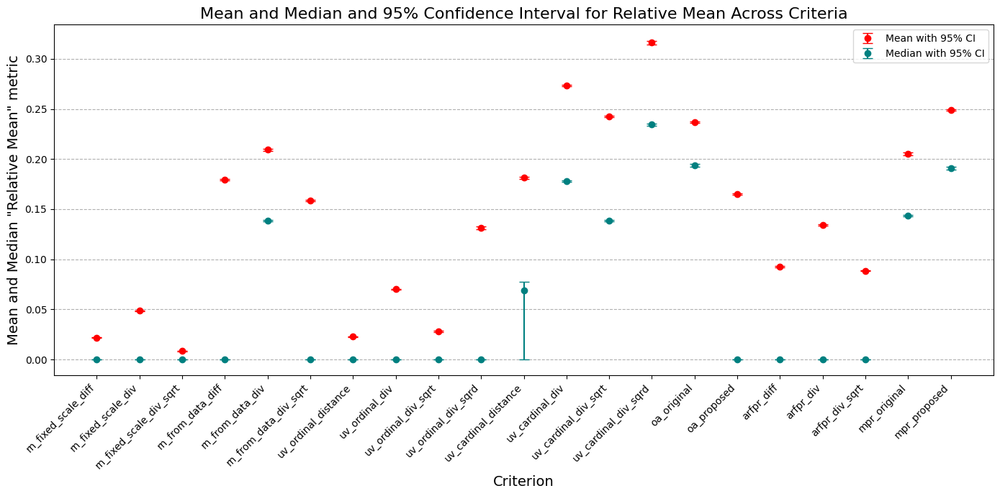

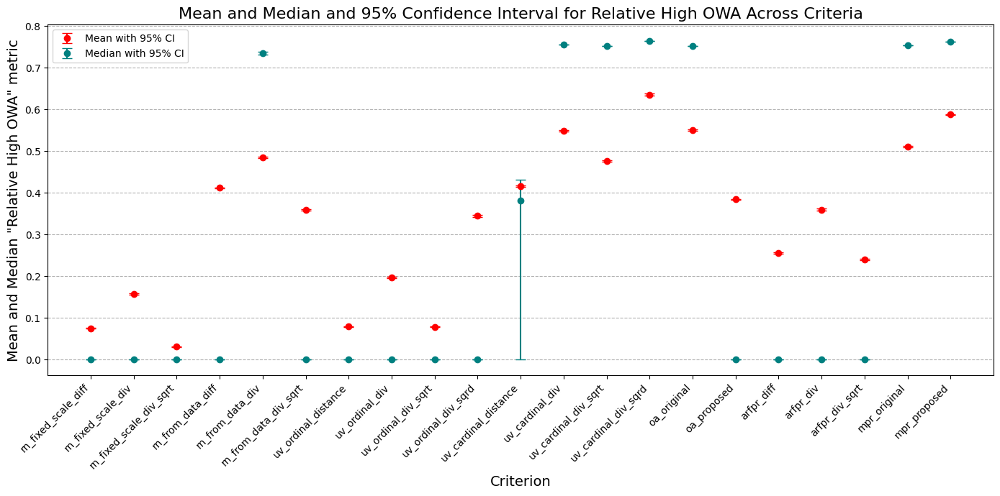

In [ ]:
all_functions_mean_cis, all_functions_median_cis = test_run_to_run_stability_from_config('formats_combined_all_functions',
                                                                                         plot_graph=False)
for metric in ['relative_avg', 'relative_high_owa']:
  plot_cis_from_dict(all_functions_mean_cis, all_functions_median_cis, metric)
# print_mean_cis(all_functions_mean_cis)
# print_median_cis(all_functions_median_cis)

### Formats Combined Distance-Based Functions Config

The Confidence Intervals are close enough, so the stability is proved.


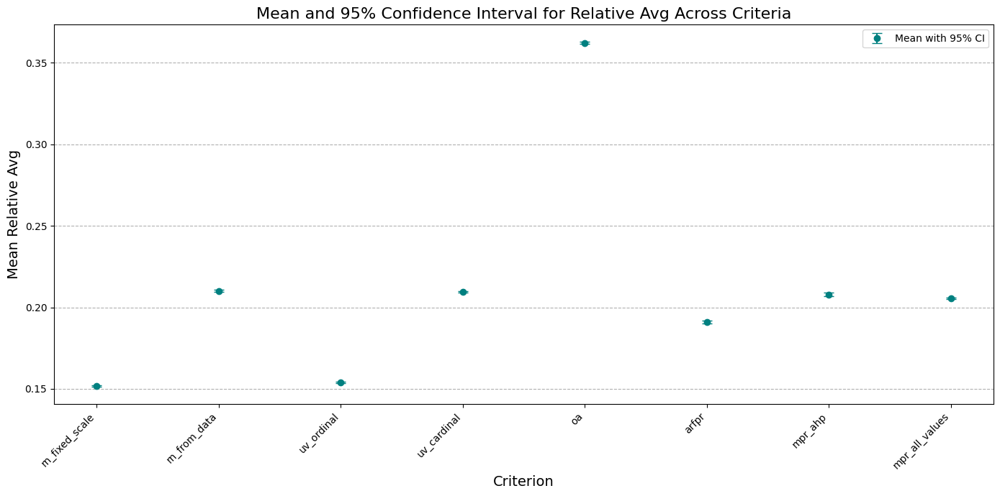

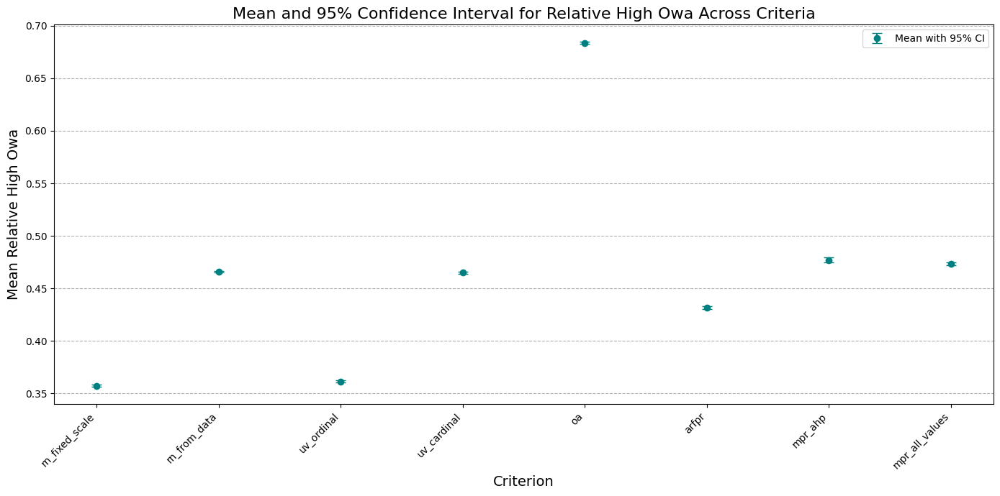

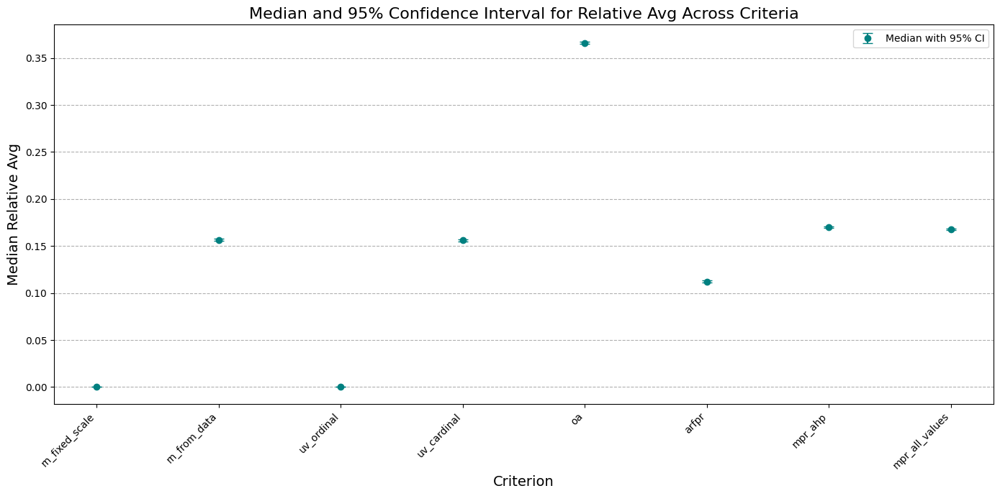

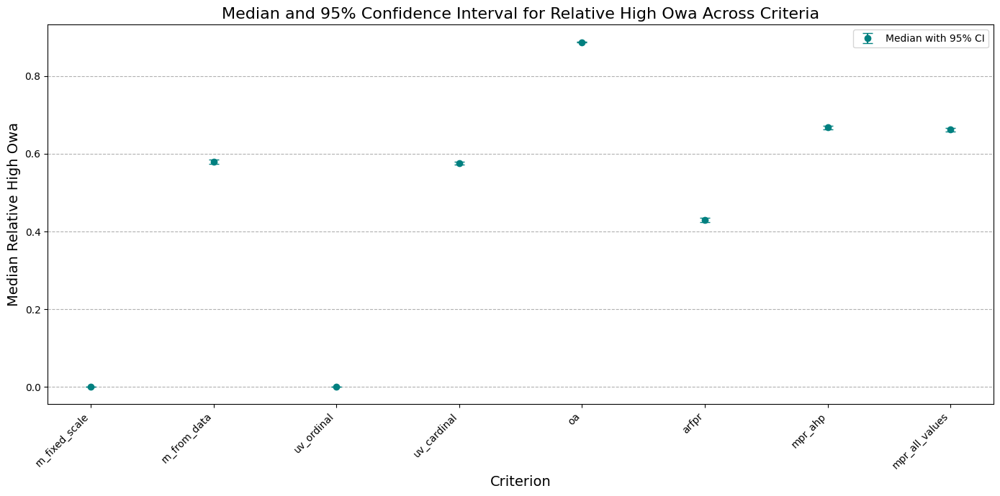

==================== Confidence Intervals for relative_avg_rn_fixed_scale ===========================
Final Mean Estimate: 0.1516
95% Confidence Interval (Mean): [0.1511, 0.1521]

==================== Confidence Intervals for relative_avg_rn_from_data ===========================
Final Mean Estimate: 0.2100
95% Confidence Interval (Mean): [0.2094, 0.2107]

==================== Confidence Intervals for relative_avg_uv_ordinal ===========================
Final Mean Estimate: 0.1539
95% Confidence Interval (Mean): [0.1534, 0.1543]

==================== Confidence Intervals for relative_avg_uv_cardinal ===========================
Final Mean Estimate: 0.2095
95% Confidence Interval (Mean): [0.2092, 0.2099]

==================== Confidence Intervals for relative_avg_oa ===========================
Final Mean Estimate: 0.3622
95% Confidence Interval (Mean): [0.3616, 0.3628]

==================== Confidence Intervals for relative_avg_arfpr ===========================
Final Mean Estimate: 0.1910


In [ ]:
distance_mean_cis, distance_median_cis = test_run_to_run_stability_from_config('formats_combined_distance',
                                                                               plot_graph=True)
print_mean_cis(distance_mean_cis)
print_median_cis(distance_median_cis)

### Formats Combined Division-Based Functions Config

The Confidence Intervals are close enough, so the stability is proved.

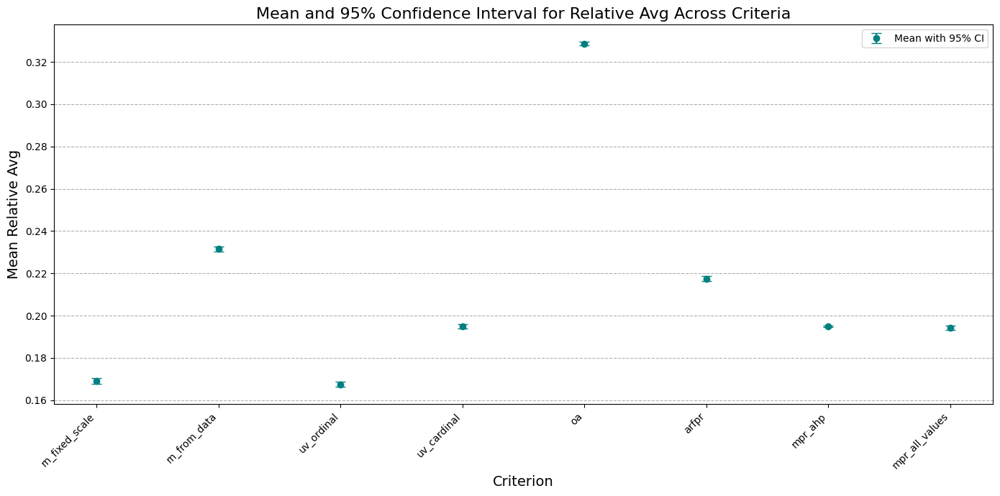

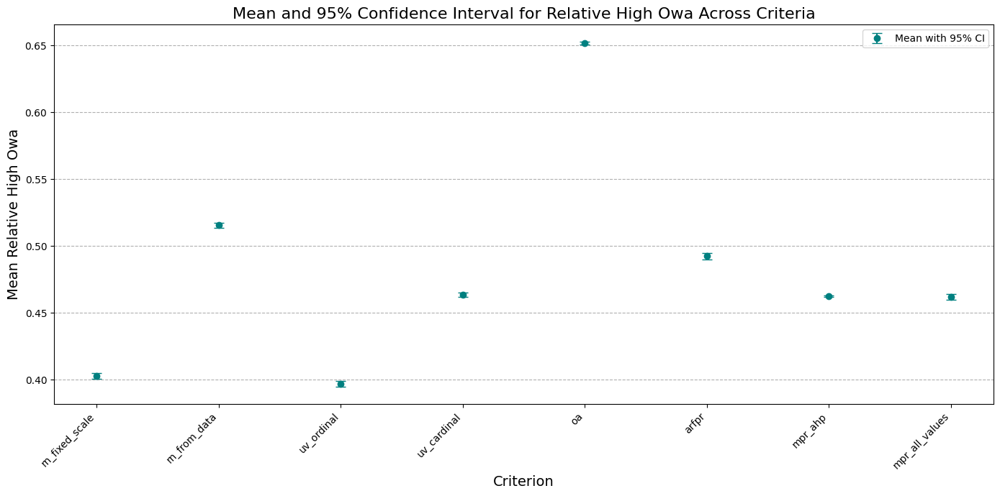

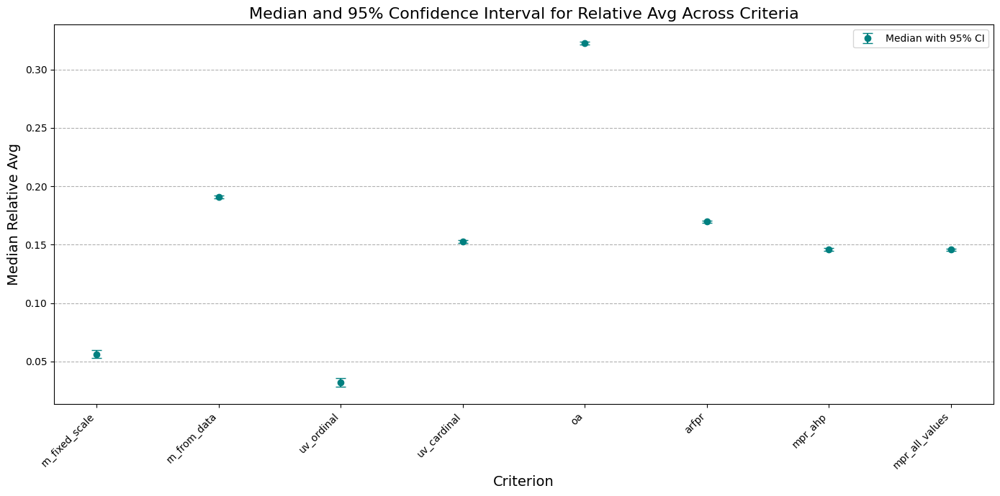

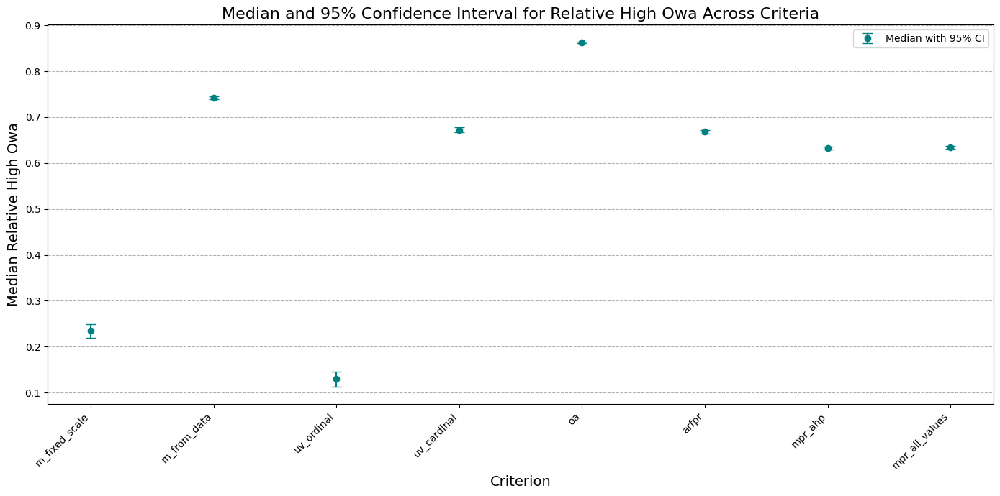

==================== Confidence Intervals for relative_avg_rn_fixed_scale ===========================
Final Mean Estimate: 0.1691
95% Confidence Interval (Mean): [0.1679, 0.1703]

==================== Confidence Intervals for relative_avg_rn_from_data ===========================
Final Mean Estimate: 0.2315
95% Confidence Interval (Mean): [0.2304, 0.2326]

==================== Confidence Intervals for relative_avg_uv_ordinal ===========================
Final Mean Estimate: 0.1674
95% Confidence Interval (Mean): [0.1662, 0.1686]

==================== Confidence Intervals for relative_avg_uv_cardinal ===========================
Final Mean Estimate: 0.1949
95% Confidence Interval (Mean): [0.1938, 0.1960]

==================== Confidence Intervals for relative_avg_oa ===========================
Final Mean Estimate: 0.3286
95% Confidence Interval (Mean): [0.3278, 0.3294]

==================== Confidence Intervals for relative_avg_arfpr ===========================
Final Mean Estimate: 0.2174


In [ ]:
div_mean_cis, div_median_cis = test_run_to_run_stability_from_config('formats_combined_div',
                                                                     plot_graph=True)
print_mean_cis(div_mean_cis)
print_median_cis(div_median_cis)

### Formats Combined Div-Sqrt-Based Functions Config

The Confidence Intervals are close enough, so the stability is proved.

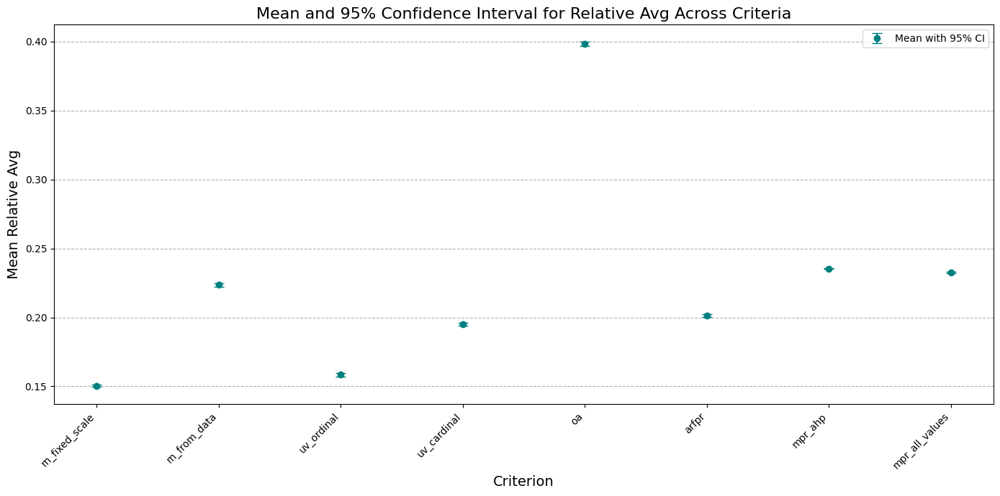

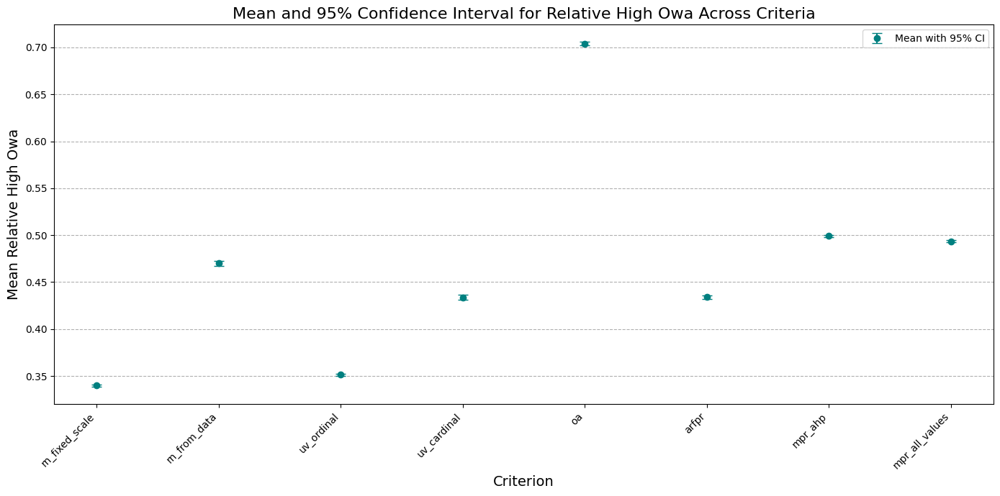

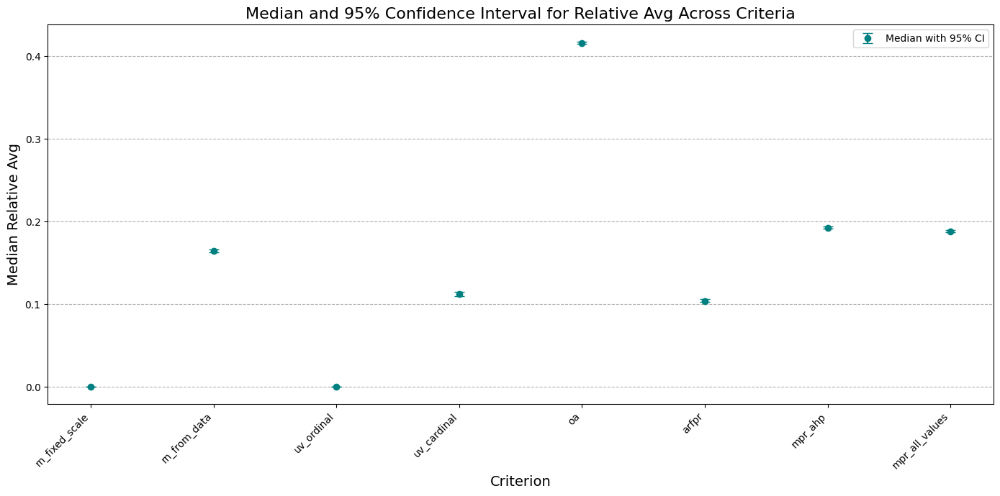

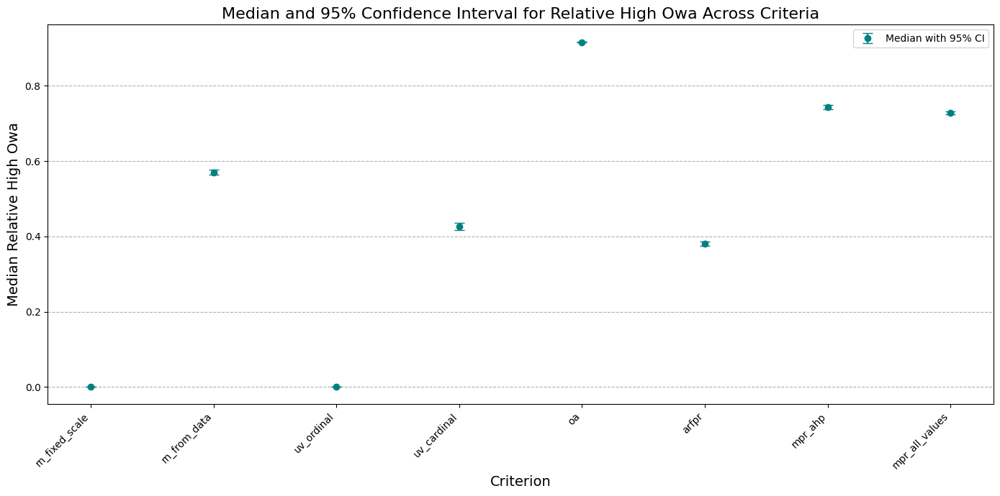

==================== Confidence Intervals for relative_avg_rn_fixed_scale ===========================
Final Mean Estimate: 0.1505
95% Confidence Interval (Mean): [0.1495, 0.1515]

==================== Confidence Intervals for relative_avg_rn_from_data ===========================
Final Mean Estimate: 0.2236
95% Confidence Interval (Mean): [0.2221, 0.2250]

==================== Confidence Intervals for relative_avg_uv_ordinal ===========================
Final Mean Estimate: 0.1583
95% Confidence Interval (Mean): [0.1571, 0.1595]

==================== Confidence Intervals for relative_avg_uv_cardinal ===========================
Final Mean Estimate: 0.1951
95% Confidence Interval (Mean): [0.1939, 0.1962]

==================== Confidence Intervals for relative_avg_oa ===========================
Final Mean Estimate: 0.3982
95% Confidence Interval (Mean): [0.3967, 0.3997]

==================== Confidence Intervals for relative_avg_arfpr ===========================
Final Mean Estimate: 0.2012


In [ ]:
div_sqrt_mean_cis, div_sqrt_median_cis = test_run_to_run_stability_from_config('formats_combined_div_sqrt',
                                                                               plot_graph=True)
print_mean_cis(div_sqrt_mean_cis)
print_median_cis(div_sqrt_median_cis)

# Plots for Chapter 5

In [ ]:
#@title Plot the CIs
def plot_cis_for_config(config_name):
  df = pd.read_csv(f'{config_name}_sample_100000_run_1.csv')
  criteria_names = get_criteria_names(df)
  metrics = ['relative_avg', 'relative_high_owa']

  # Mean CIs
  means = mean_cis_from_df(df)
  medians = median_cis_from_df(df)

  for metric in metrics:
    plot_cis_from_dict(means, medians, metric)

def plot_cis_for_config_separated(config_name):
  df = pd.read_csv(f'{config_name}_sample_100000_run_1.csv')
  criteria_names = get_criteria_names(df)
  metrics = ['relative_avg', 'relative_high_owa']

  # Mean CIs
  means = mean_cis_from_df(df)
  for metric in metrics:
    plot_mean_ci_from_dict(means, metric)

  # Median CIs
  medians = median_cis_from_df(df)
  for metric in metrics:
    plot_median_ci_from_dict(medians, metric)

def print_cis_for_config(config_name):
  df = pd.read_csv(f'{config_name}_sample_100000_run_1.csv')
  criteria_names = get_criteria_names(df)
  metrics = ['relative_avg', 'relative_high_owa']

  # Mean CIs
  means = mean_cis_from_df(df)
  print_mean_cis(means)

  # Median CIs
  medians = median_cis_from_df(df)
  print_median_cis(medians)

In [ ]:
#@markdown Load the config
experiment_name = 'formats_combined_proposed' #@param ['all_rn_from_data', 'all_rn_fixed_scale', 'all_uv_cardinal', 'all_uv_ordinal', 'all_oa', 'all_mpr', 'all_arfpr', 'lowest_performing', 'highest_performing', 'formats_combined_proposed', 'formats_combined_distance', 'formats_combined_div'] {isTemplate: true}
df_name = f'{experiment_name}_sample_100000_run_1.csv'
df = pd.read_csv(df_name)

criteria_names = get_criteria_names(df)
print(criteria_names)

['rn_fixed_scale', 'rn_from_data', 'uv_ordinal', 'uv_cardinal', 'oa', 'arfpr', 'mpr']


In [ ]:
#@markdown Distribution Plot
plot_type = 'violin' #@param ['violin', 'box', 'histogram'] {isTemplate: true}
metric = 'relative_avg' #@param ['relative_avg', 'relative_high_owa', 'relative_num_alternatives_contribution'] {isTemplate: true}

if plot_type == 'violin':
  violinplot_for_metric(df, metric, criteria_names)
elif plot_type == 'box':
  boxplot_for_metric(df, metric, criteria_names)
elif plot_type == 'histogram':
  histogram_for_metric(df, metric, criteria_names)
else:
  print('Invalid plot type')

# Confidence Intervals

## All RN From Data

In [ ]:
print_cis_for_config('all_rn_from_data')

==================== Confidence Intervals for relative_avg_rn_diff ===========================
Final Mean Estimate: 0.6417
95% Confidence Interval (Mean): [0.6402, 0.6433]

==================== Confidence Intervals for relative_avg_rn_div ===========================
Final Mean Estimate: 0.6140
95% Confidence Interval (Mean): [0.6124, 0.6155]

==================== Confidence Intervals for relative_avg_rn_div_sqrt ===========================
Final Mean Estimate: 0.6543
95% Confidence Interval (Mean): [0.6528, 0.6559]

==================== Confidence Intervals for relative_high_owa_rn_diff ===========================
Final Mean Estimate: 0.8923
95% Confidence Interval (Mean): [0.8911, 0.8935]

==================== Confidence Intervals for relative_high_owa_rn_div ===========================
Final Mean Estimate: 0.8881
95% Confidence Interval (Mean): [0.8869, 0.8893]

==================== Confidence Intervals for relative_high_owa_rn_div_sqrt ===========================
Final Mean Estimate

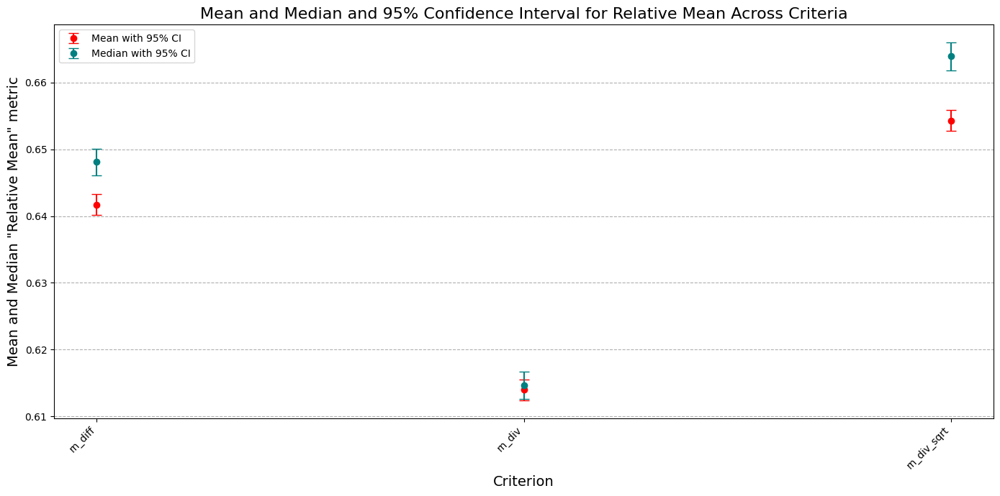

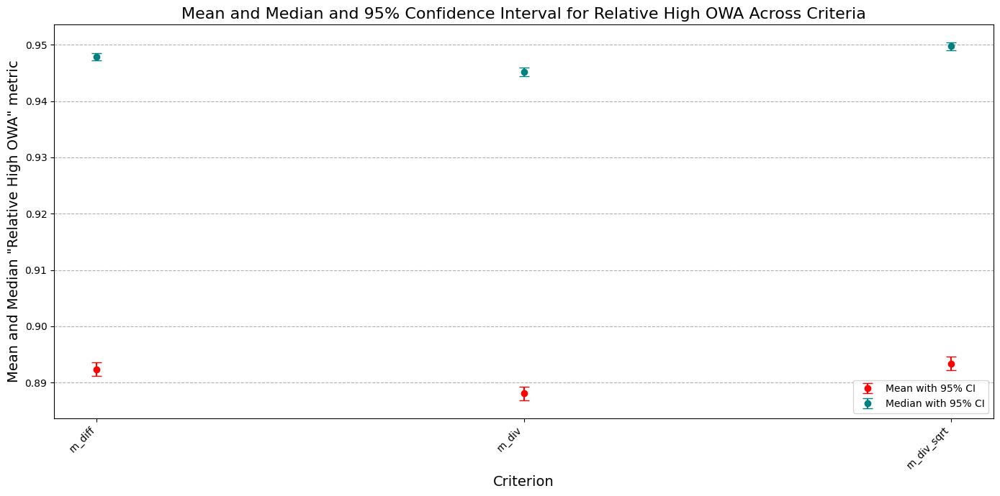

In [ ]:
plot_cis_for_config('all_rn_from_data')

## All RN Fixed Scale

In [ ]:
print_cis_for_config('all_rn_fixed_scale')

==================== Confidence Intervals for relative_avg_rn_diff ===========================
Final Mean Estimate: 0.6363
95% Confidence Interval (Mean): [0.6346, 0.6379]

==================== Confidence Intervals for relative_avg_rn_div ===========================
Final Mean Estimate: 0.5692
95% Confidence Interval (Mean): [0.5674, 0.5709]

==================== Confidence Intervals for relative_avg_rn_div_sqrt ===========================
Final Mean Estimate: 0.6581
95% Confidence Interval (Mean): [0.6565, 0.6598]

==================== Confidence Intervals for relative_high_owa_rn_diff ===========================
Final Mean Estimate: 0.8782
95% Confidence Interval (Mean): [0.8767, 0.8797]

==================== Confidence Intervals for relative_high_owa_rn_div ===========================
Final Mean Estimate: 0.8351
95% Confidence Interval (Mean): [0.8333, 0.8369]

==================== Confidence Intervals for relative_high_owa_rn_div_sqrt ===========================
Final Mean Estimate

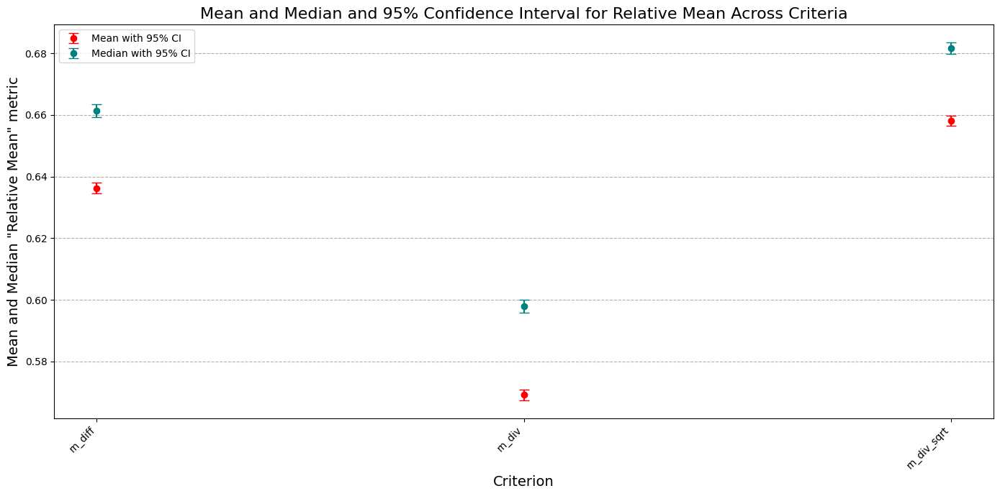

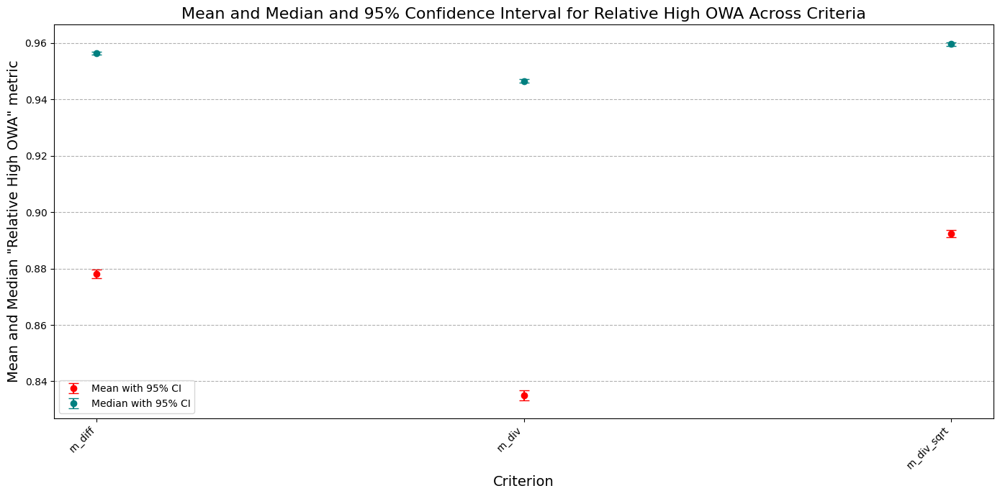

In [ ]:
plot_cis_for_config('all_rn_fixed_scale')

## All Cardinal UV

In [ ]:
print_cis_for_config('all_uv_cardinal')

==================== Confidence Intervals for relative_avg_uv_distance ===========================
Final Mean Estimate: 0.5571
95% Confidence Interval (Mean): [0.5555, 0.5587]

==================== Confidence Intervals for relative_avg_uv_div ===========================
Final Mean Estimate: 0.5343
95% Confidence Interval (Mean): [0.5326, 0.5360]

==================== Confidence Intervals for relative_avg_uv_div_sqrt ===========================
Final Mean Estimate: 0.5174
95% Confidence Interval (Mean): [0.5158, 0.5191]

==================== Confidence Intervals for relative_avg_uv_div_sqrd ===========================
Final Mean Estimate: 0.5237
95% Confidence Interval (Mean): [0.5220, 0.5255]

==================== Confidence Intervals for relative_high_owa_uv_distance ===========================
Final Mean Estimate: 0.8350
95% Confidence Interval (Mean): [0.8334, 0.8366]

==================== Confidence Intervals for relative_high_owa_uv_div ===========================
Final Mean Estim

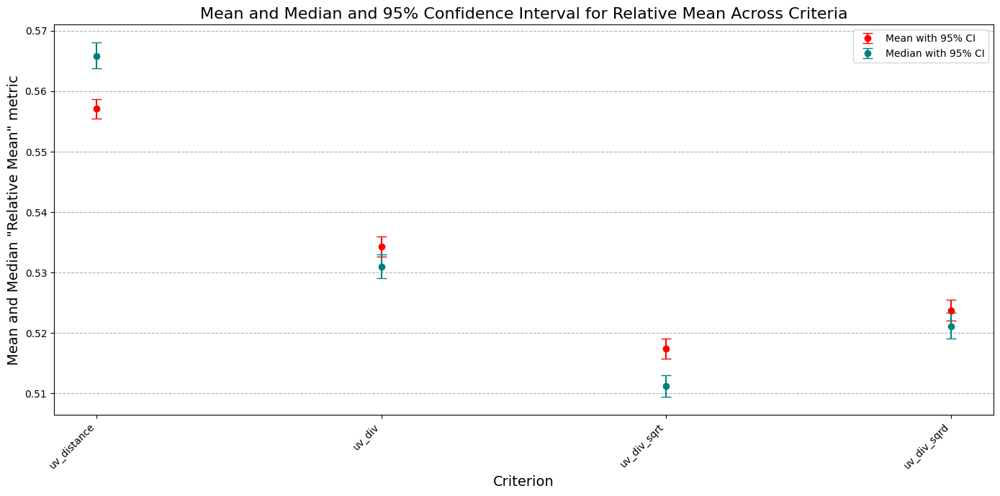

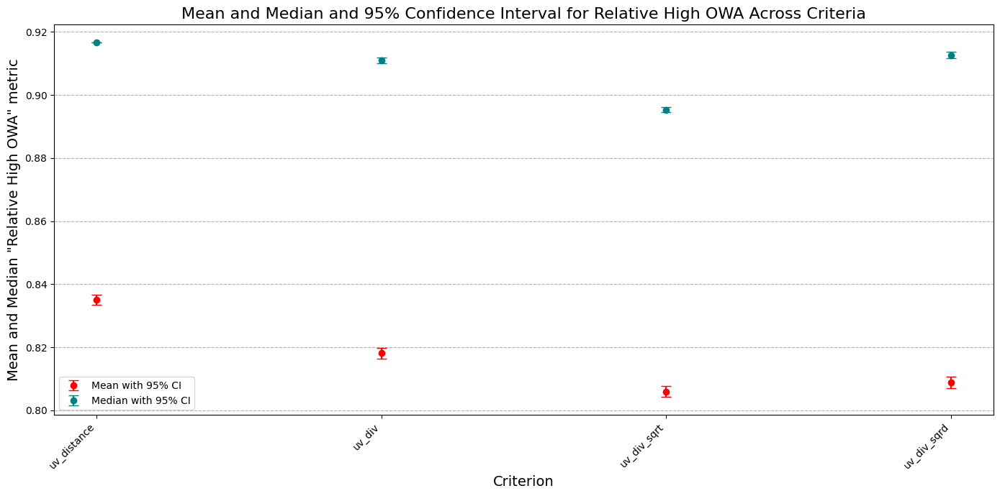

In [ ]:
plot_cis_for_config('all_uv_cardinal')

## All Ordinal UV

In [ ]:
print_cis_for_config('all_uv_ordinal')

==================== Confidence Intervals for relative_avg_uv_distance ===========================
Final Mean Estimate: 0.5180
95% Confidence Interval (Mean): [0.5162, 0.5197]

==================== Confidence Intervals for relative_avg_uv_div ===========================
Final Mean Estimate: 0.4895
95% Confidence Interval (Mean): [0.4876, 0.4913]

==================== Confidence Intervals for relative_avg_uv_div_sqrt ===========================
Final Mean Estimate: 0.5060
95% Confidence Interval (Mean): [0.5042, 0.5077]

==================== Confidence Intervals for relative_avg_uv_div_sqrd ===========================
Final Mean Estimate: 0.4327
95% Confidence Interval (Mean): [0.4308, 0.4345]

==================== Confidence Intervals for relative_high_owa_uv_distance ===========================
Final Mean Estimate: 0.7875
95% Confidence Interval (Mean): [0.7855, 0.7894]

==================== Confidence Intervals for relative_high_owa_uv_div ===========================
Final Mean Estim

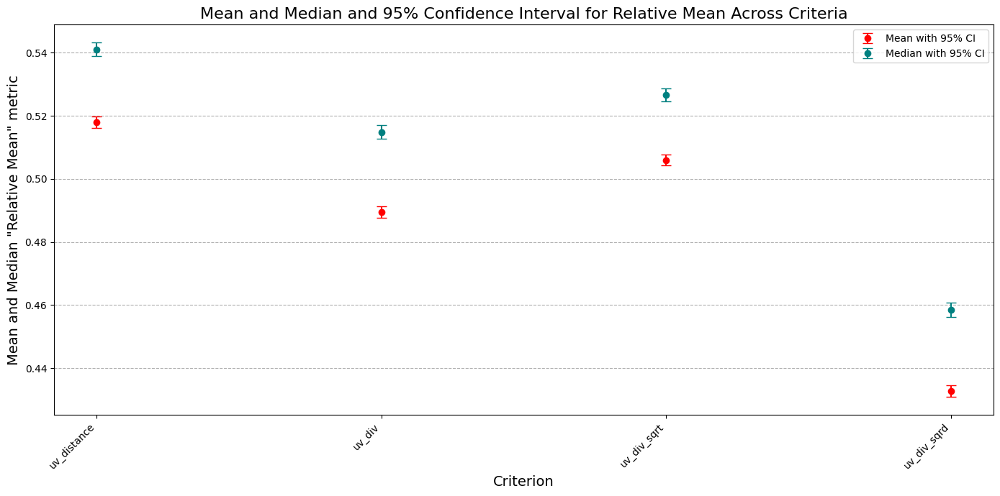

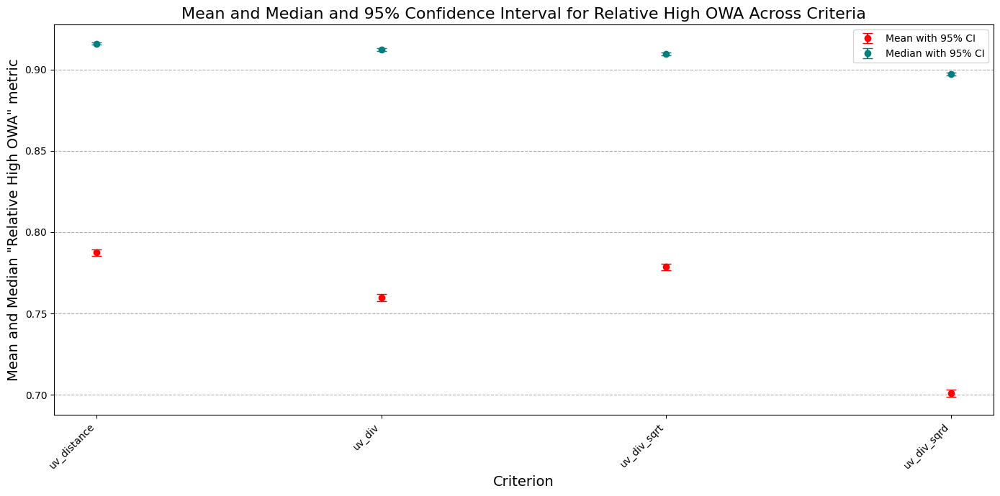

In [ ]:
plot_cis_for_config('all_uv_ordinal')

## All OA

In [ ]:
print_cis_for_config('all_oa')

==================== Confidence Intervals for relative_avg_oa_original ===========================
Final Mean Estimate: 0.7491
95% Confidence Interval (Mean): [0.7478, 0.7504]

==================== Confidence Intervals for relative_avg_oa_proposed ===========================
Final Mean Estimate: 0.9404
95% Confidence Interval (Mean): [0.9397, 0.9411]

==================== Confidence Intervals for relative_high_owa_oa_original ===========================
Final Mean Estimate: 0.9465
95% Confidence Interval (Mean): [0.9461, 0.9469]

==================== Confidence Intervals for relative_high_owa_oa_proposed ===========================
Final Mean Estimate: 0.9828
95% Confidence Interval (Mean): [0.9826, 0.9830]

==================== Confidence Intervals for relative_avg_oa_original ===========================
Final Median Estimate: 0.7500
95% Confidence Interval (Median): [0.7500, 0.7500]

==================== Confidence Intervals for relative_avg_oa_proposed ===========================
Fi

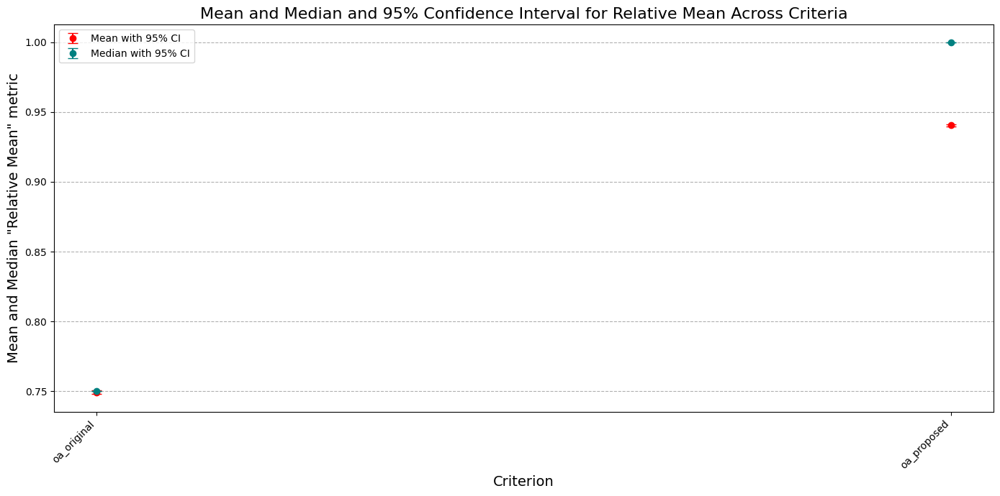

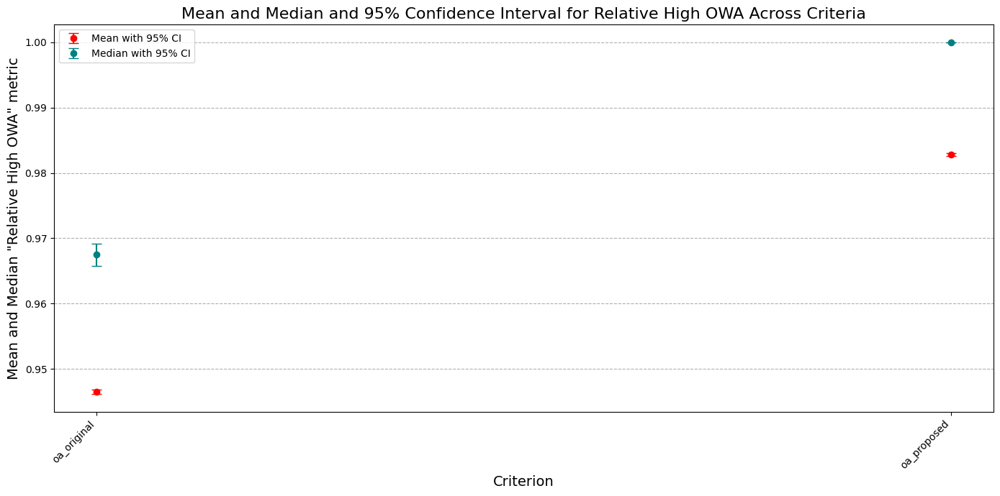

In [ ]:
plot_cis_for_config('all_oa')

## All MPR

In [ ]:
print_cis_for_config('all_mpr')

==================== Confidence Intervals for relative_avg_mpr_original ===========================
Final Mean Estimate: 0.8901
95% Confidence Interval (Mean): [0.8891, 0.8912]

==================== Confidence Intervals for relative_avg_mpr_proposed ===========================
Final Mean Estimate: 0.8293
95% Confidence Interval (Mean): [0.8280, 0.8307]

==================== Confidence Intervals for relative_high_owa_mpr_original ===========================
Final Mean Estimate: 0.9734
95% Confidence Interval (Mean): [0.9730, 0.9738]

==================== Confidence Intervals for relative_high_owa_mpr_proposed ===========================
Final Mean Estimate: 0.9518
95% Confidence Interval (Mean): [0.9510, 0.9525]

==================== Confidence Intervals for relative_avg_mpr_original ===========================
Final Median Estimate: 1.0000
95% Confidence Interval (Median): [1.0000, 1.0000]

==================== Confidence Intervals for relative_avg_mpr_proposed ========================

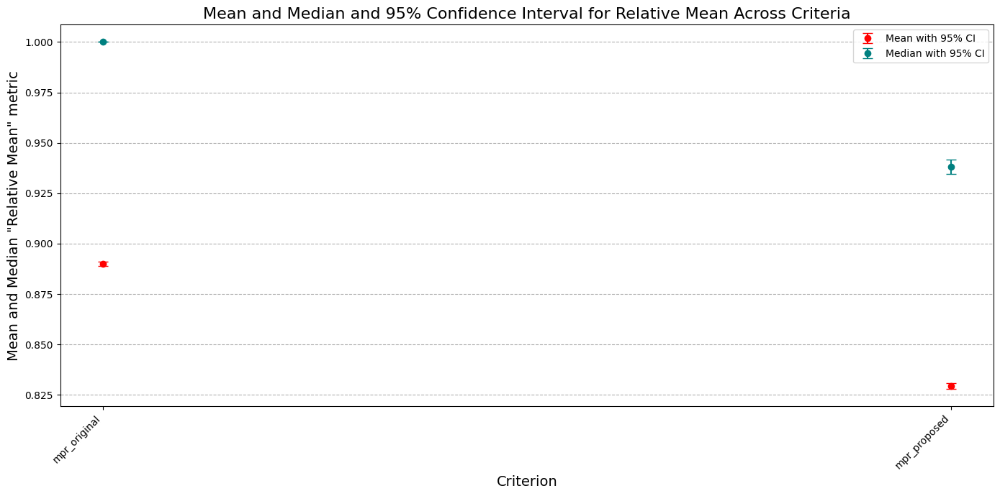

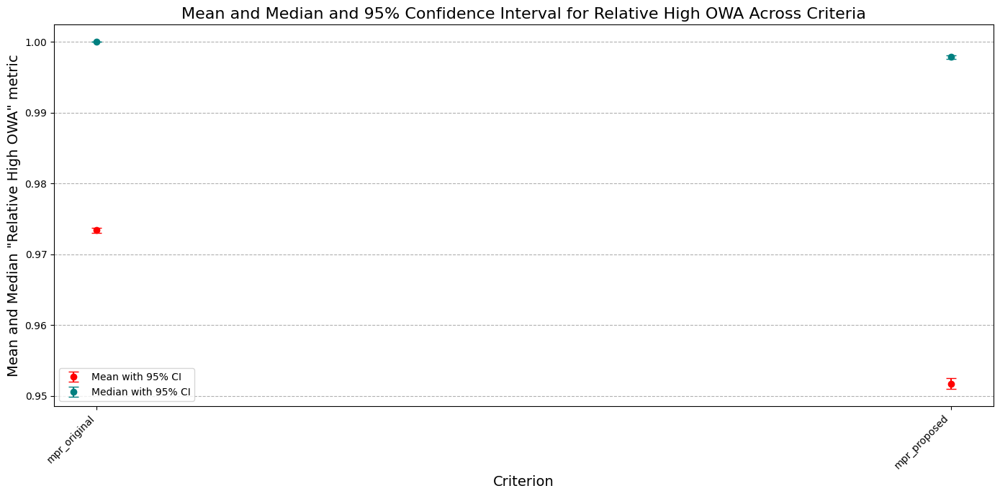

In [ ]:
plot_cis_for_config('all_mpr')

## All ARFPR

In [ ]:
print_cis_for_config('all_arfpr')

==================== Confidence Intervals for relative_avg_arfpr_diff ===========================
Final Mean Estimate: 0.6401
95% Confidence Interval (Mean): [0.6384, 0.6417]

==================== Confidence Intervals for relative_avg_arfpr_div ===========================
Final Mean Estimate: 0.5919
95% Confidence Interval (Mean): [0.5902, 0.5937]

==================== Confidence Intervals for relative_avg_arfpr_sqrt ===========================
Final Mean Estimate: 0.6614
95% Confidence Interval (Mean): [0.6597, 0.6630]

==================== Confidence Intervals for relative_high_owa_arfpr_diff ===========================
Final Mean Estimate: 0.8788
95% Confidence Interval (Mean): [0.8774, 0.8802]

==================== Confidence Intervals for relative_high_owa_arfpr_div ===========================
Final Mean Estimate: 0.8572
95% Confidence Interval (Mean): [0.8556, 0.8587]

==================== Confidence Intervals for relative_high_owa_arfpr_sqrt ===========================
Final Mea

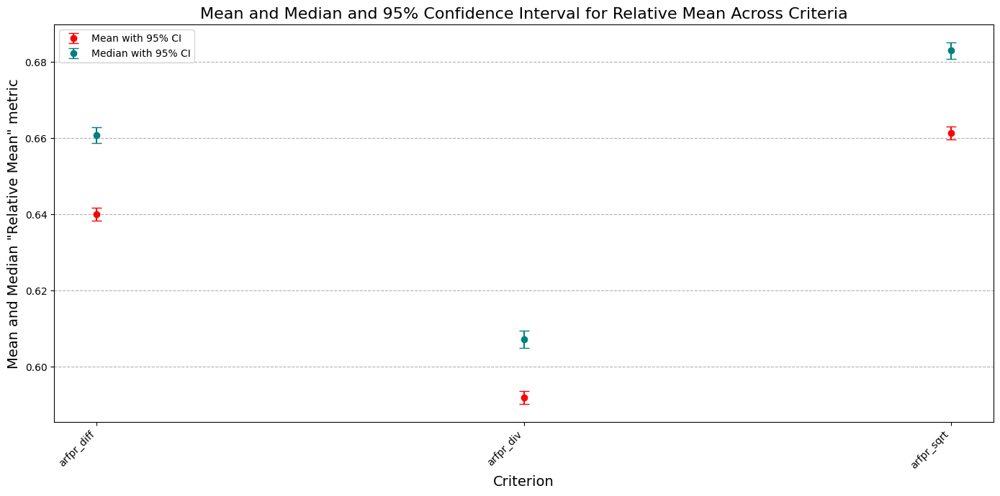

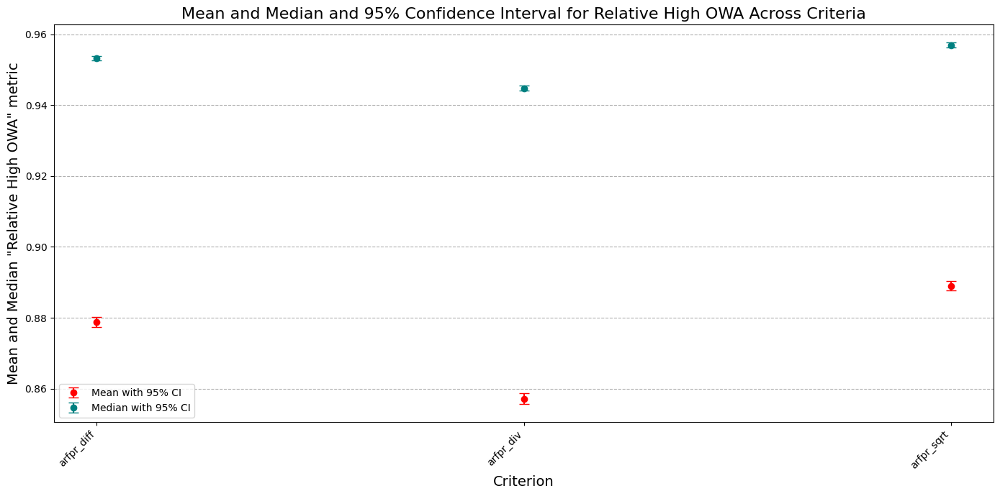

In [ ]:
plot_cis_for_config('all_arfpr')

## Lowest Performing Transformations

In [ ]:
print_cis_for_config('lowest_performing')

==================== Confidence Intervals for relative_avg_rn_from_data ===========================
Final Mean Estimate: 0.2493
95% Confidence Interval (Mean): [0.2478, 0.2508]

==================== Confidence Intervals for relative_avg_rn_fixed_scale ===========================
Final Mean Estimate: 0.2053
95% Confidence Interval (Mean): [0.2039, 0.2067]

==================== Confidence Intervals for relative_avg_uv_cardinal ===========================
Final Mean Estimate: 0.1681
95% Confidence Interval (Mean): [0.1668, 0.1693]

==================== Confidence Intervals for relative_avg_uv_ordinal ===========================
Final Mean Estimate: 0.2320
95% Confidence Interval (Mean): [0.2305, 0.2335]

==================== Confidence Intervals for relative_avg_oa ===========================
Final Mean Estimate: 0.3484
95% Confidence Interval (Mean): [0.3468, 0.3501]

==================== Confidence Intervals for relative_avg_mpr ===========================
Final Mean Estimate: 0.1936
95

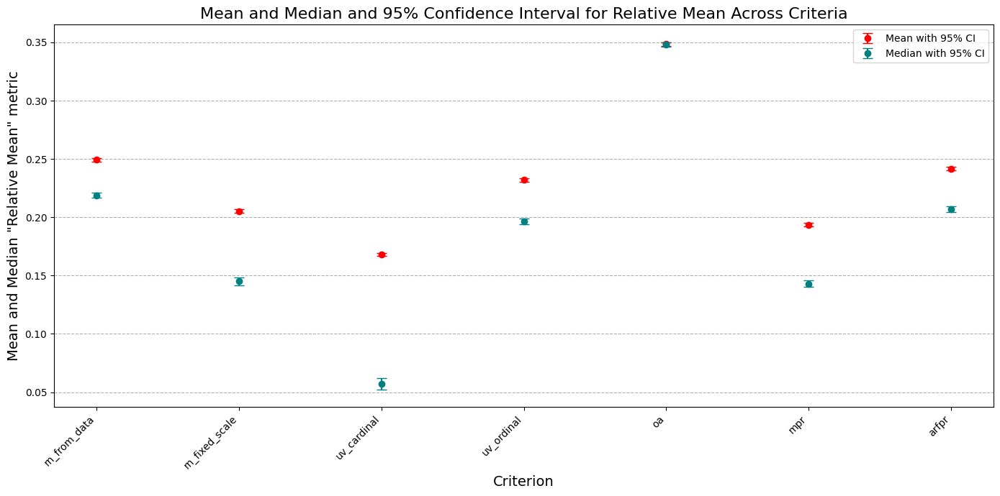

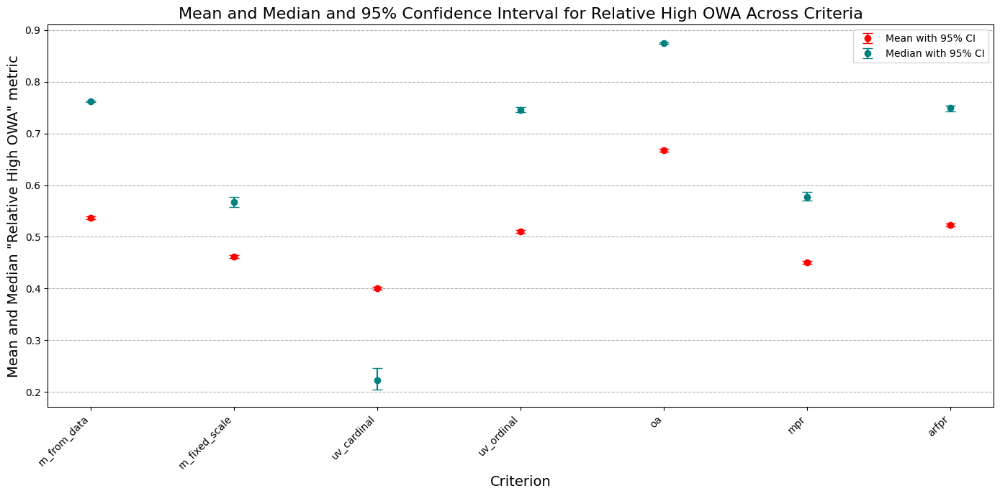

In [ ]:
plot_cis_for_config('lowest_performing')

## Highest Performing Transformations

In [ ]:
print_cis_for_config('highest_performing')

==================== Confidence Intervals for relative_avg_rn_from_data ===========================
Final Mean Estimate: 0.2341
95% Confidence Interval (Mean): [0.2326, 0.2356]

==================== Confidence Intervals for relative_avg_rn_fixed_scale ===========================
Final Mean Estimate: 0.1894
95% Confidence Interval (Mean): [0.1880, 0.1908]

==================== Confidence Intervals for relative_avg_uv_cardinal ===========================
Final Mean Estimate: 0.2404
95% Confidence Interval (Mean): [0.2389, 0.2419]

==================== Confidence Intervals for relative_avg_uv_ordinal ===========================
Final Mean Estimate: 0.2051
95% Confidence Interval (Mean): [0.2037, 0.2066]

==================== Confidence Intervals for relative_avg_oa ===========================
Final Mean Estimate: 0.3640
95% Confidence Interval (Mean): [0.3624, 0.3656]

==================== Confidence Intervals for relative_avg_mpr ===========================
Final Mean Estimate: 0.2135
95

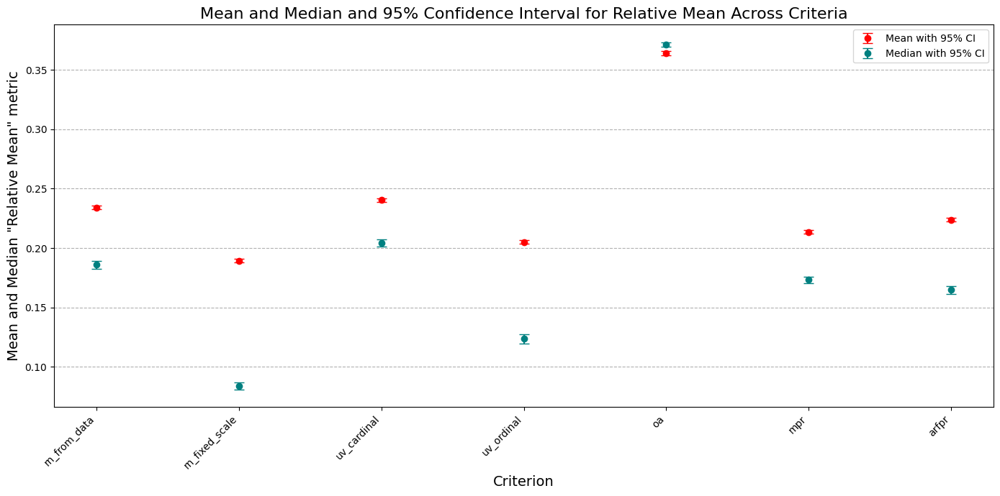

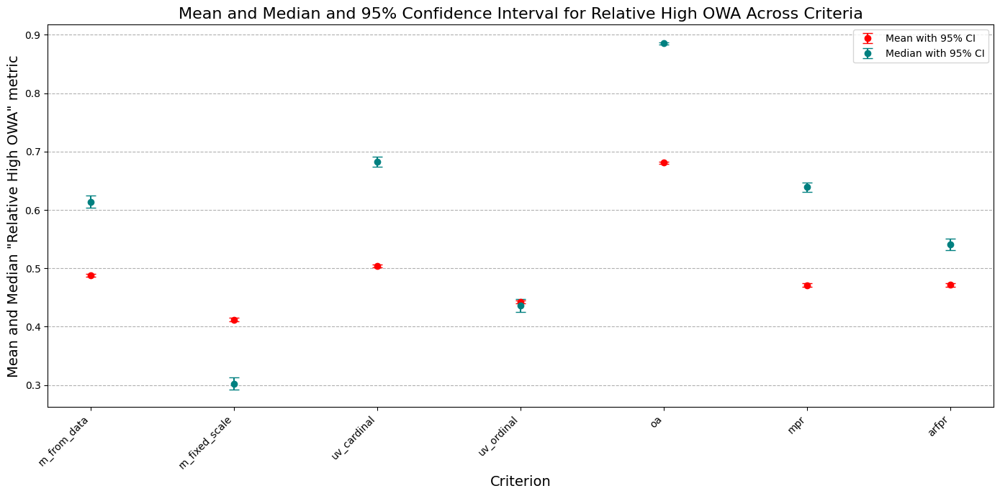

In [ ]:
plot_cis_for_config('highest_performing')

## Formats Combined Proposed Transformations

In [ ]:
print_cis_for_config('formats_combined_proposed')

==================== Confidence Intervals for relative_avg_rn_fixed_scale ===========================
Final Mean Estimate: 0.2165
95% Confidence Interval (Mean): [0.2150, 0.2180]

==================== Confidence Intervals for relative_avg_rn_from_data ===========================
Final Mean Estimate: 0.2551
95% Confidence Interval (Mean): [0.2535, 0.2566]

==================== Confidence Intervals for relative_avg_uv_ordinal ===========================
Final Mean Estimate: 0.2165
95% Confidence Interval (Mean): [0.2151, 0.2180]

==================== Confidence Intervals for relative_avg_uv_cardinal ===========================
Final Mean Estimate: 0.2557
95% Confidence Interval (Mean): [0.2542, 0.2573]

==================== Confidence Intervals for relative_avg_oa ===========================
Final Mean Estimate: 0.2678
95% Confidence Interval (Mean): [0.2662, 0.2694]

==================== Confidence Intervals for relative_avg_arfpr ===========================
Final Mean Estimate: 0.2446


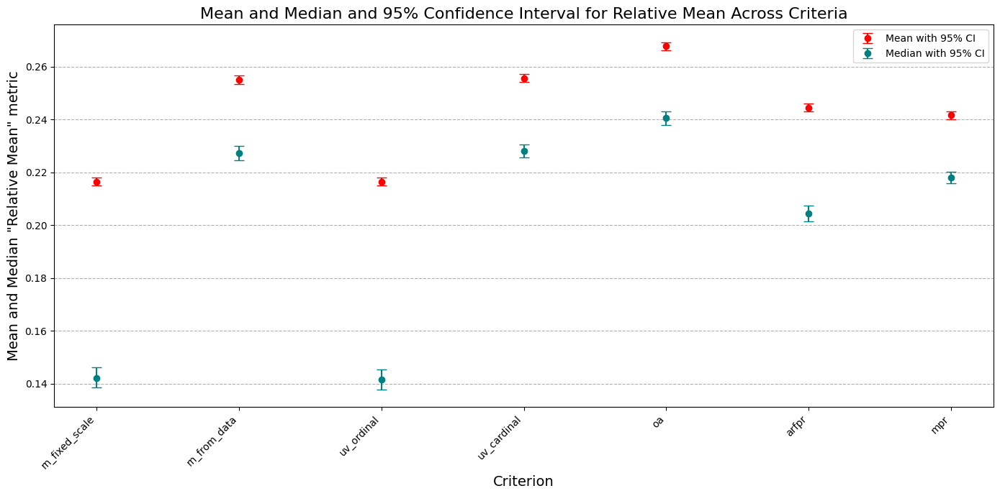

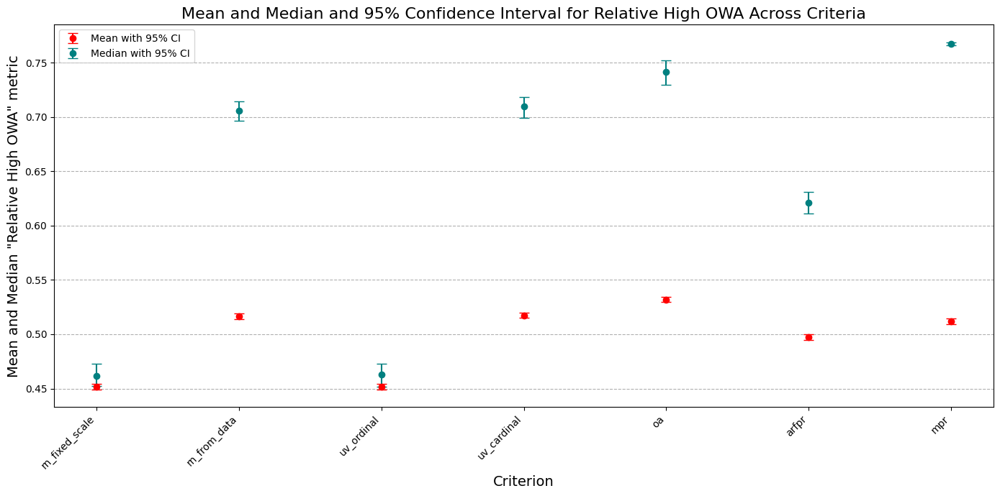

In [ ]:
plot_cis_for_config('formats_combined_proposed')

## Formats Combined All Transformations

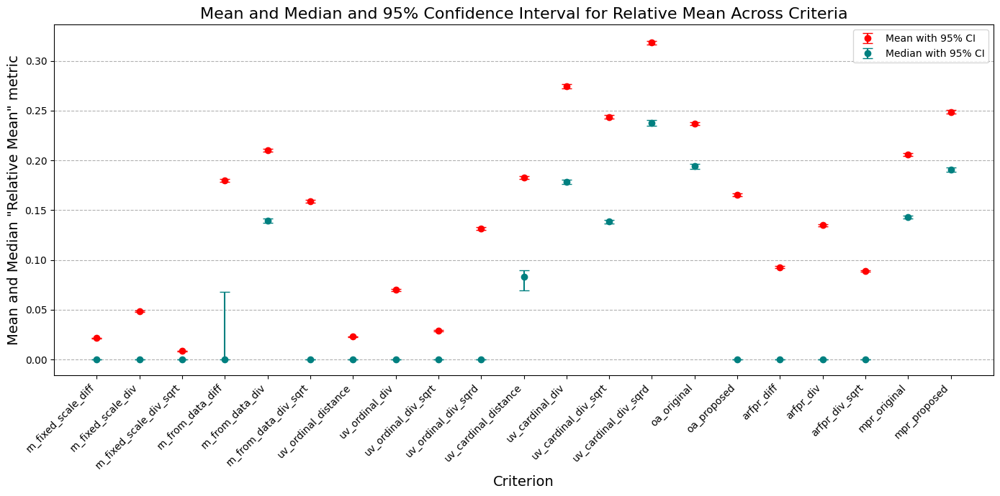

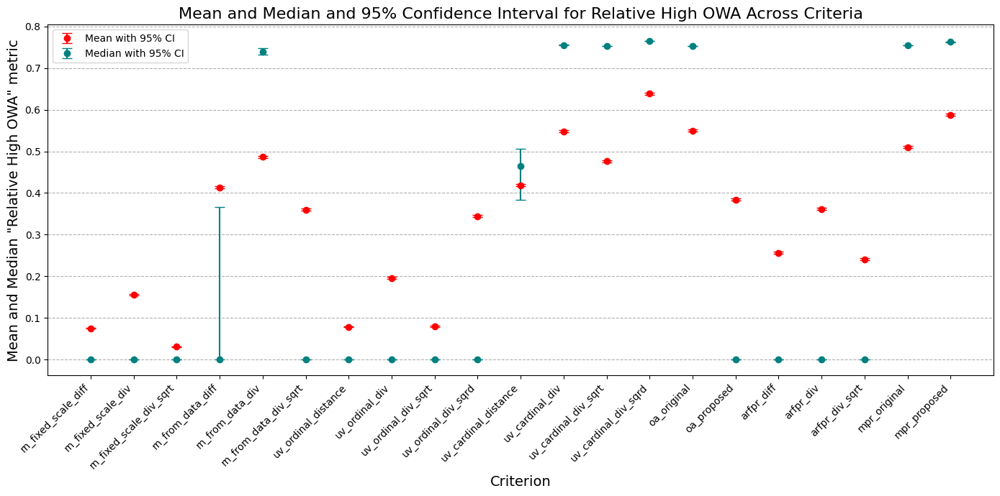

In [ ]:
plot_cis_for_config('formats_combined_all_functions')

## Formats Combined Distance Transformations

In [ ]:
print_cis_for_config('formats_combined_distance')

==================== Confidence Intervals for relative_avg_rn_fixed_scale ===========================
Final Mean Estimate: 0.1942
95% Confidence Interval (Mean): [0.1928, 0.1956]

==================== Confidence Intervals for relative_avg_rn_from_data ===========================
Final Mean Estimate: 0.2315
95% Confidence Interval (Mean): [0.2300, 0.2330]

==================== Confidence Intervals for relative_avg_uv_ordinal ===========================
Final Mean Estimate: 0.1951
95% Confidence Interval (Mean): [0.1937, 0.1965]

==================== Confidence Intervals for relative_avg_uv_cardinal ===========================
Final Mean Estimate: 0.2317
95% Confidence Interval (Mean): [0.2302, 0.2332]

==================== Confidence Intervals for relative_avg_oa ===========================
Final Mean Estimate: 0.3612
95% Confidence Interval (Mean): [0.3596, 0.3628]

==================== Confidence Intervals for relative_avg_arfpr ===========================
Final Mean Estimate: 0.2207


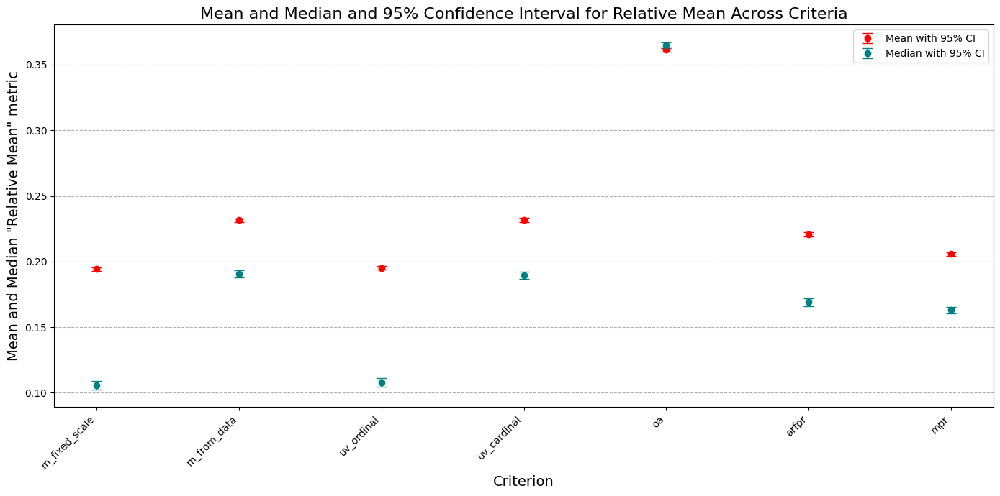

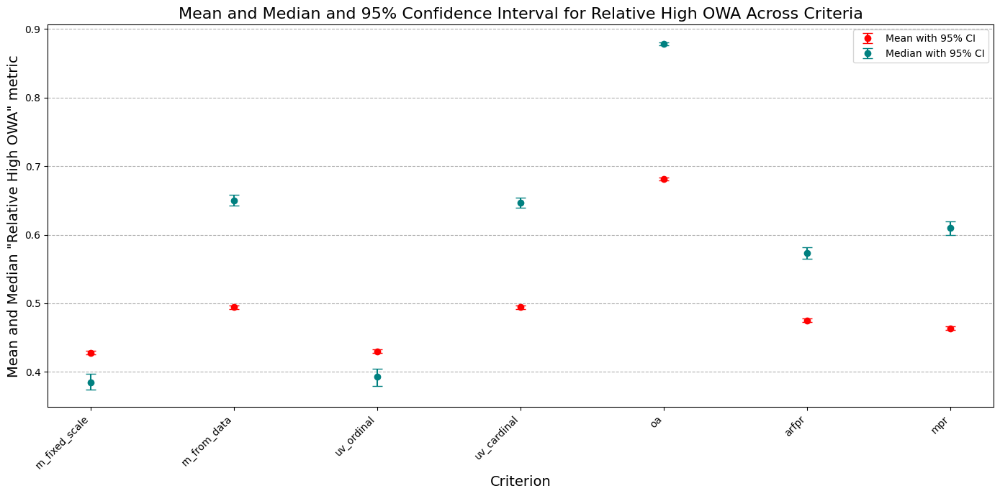

In [ ]:
plot_cis_for_config('formats_combined_distance')

## Formats Combined Division Transformations

In [ ]:
print_cis_for_config('formats_combined_div')

==================== Confidence Intervals for relative_avg_rn_fixed_scale ===========================
Final Mean Estimate: 0.2057
95% Confidence Interval (Mean): [0.2043, 0.2071]

==================== Confidence Intervals for relative_avg_rn_from_data ===========================
Final Mean Estimate: 0.2458
95% Confidence Interval (Mean): [0.2443, 0.2473]

==================== Confidence Intervals for relative_avg_uv_ordinal ===========================
Final Mean Estimate: 0.1993
95% Confidence Interval (Mean): [0.1979, 0.2007]

==================== Confidence Intervals for relative_avg_uv_cardinal ===========================
Final Mean Estimate: 0.2040
95% Confidence Interval (Mean): [0.2026, 0.2054]

==================== Confidence Intervals for relative_avg_oa ===========================
Final Mean Estimate: 0.3471
95% Confidence Interval (Mean): [0.3454, 0.3487]

==================== Confidence Intervals for relative_avg_arfpr ===========================
Final Mean Estimate: 0.2399


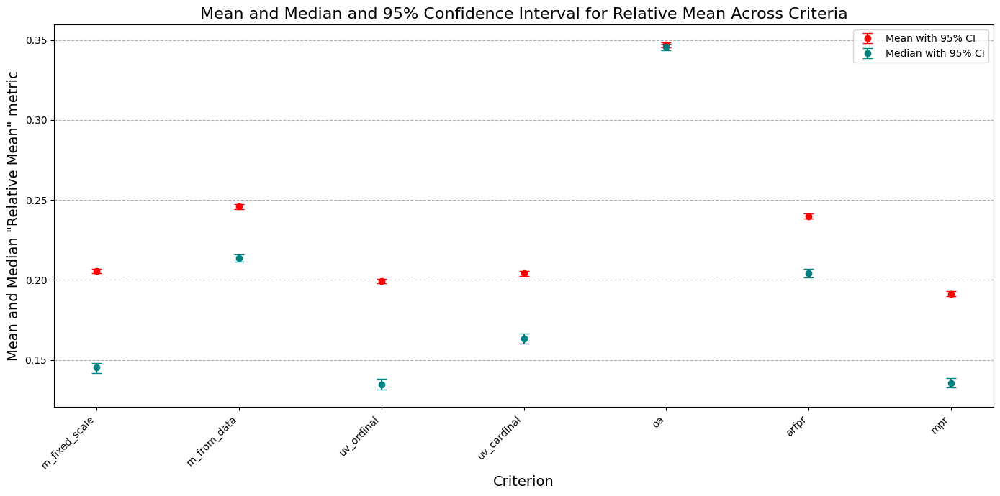

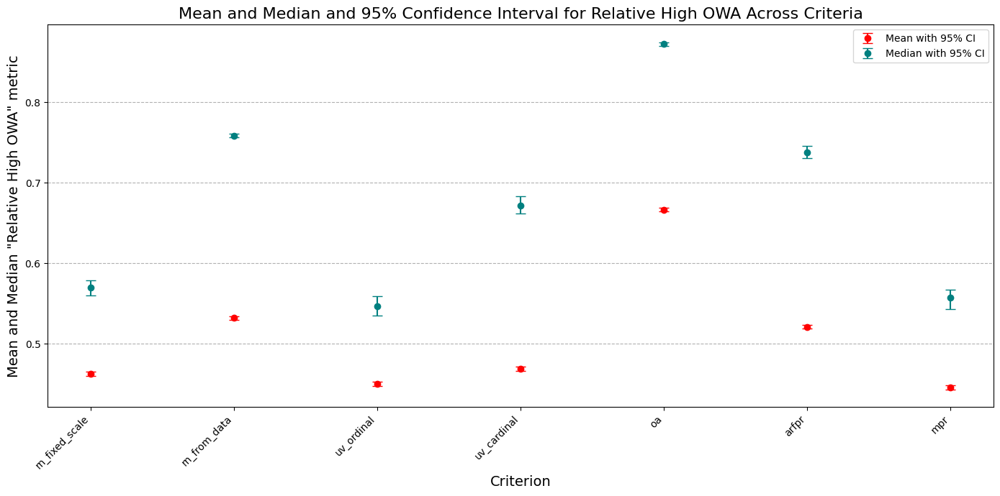

In [ ]:
plot_cis_for_config('formats_combined_div')

# Gemini Code

In [ ]:
#@title General Gemini code from prompt

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os # For creating an output directory

# --- Configuration ---
# Replace with the actual path to your CSV file in Colab
# If you upload it directly to the root of your Colab session storage,
# the filename itself is usually sufficient.
file_path = "formats_combined_proposed_sample_1000_run_0.csv"
output_directory = "monte_carlo_analysis_results"

# Create output directory if it doesn't exist
if not os.path.exists(output_directory):
    os.makedirs(output_directory)

# --- Load the Dataset ---
try:
    df = pd.read_csv(file_path)
    print(f"Successfully loaded {file_path}")
except FileNotFoundError:
    print(f"Error: File not found at {file_path}. Please upload the file to your Colab environment and check the path.")
    exit() # Exit if file not found

print("\nFirst 5 rows of the dataframe:")
print(df.head())
print("\nDataframe Info:")
df.info()

# --- Helper function to extract criteria names ---
metric_prefix_for_criteria_extraction = "max_"
criteria_names = []
for col in df.columns:
    if col.startswith(metric_prefix_for_criteria_extraction) and not col.endswith("_nd_set"):
        criteria_names.append(col[len(metric_prefix_for_criteria_extraction):])

print(f"\nIdentified criteria: {criteria_names}")
print("-" * 50)

# --- 1. Overall Simulation Characteristics ---
print("\n## 1. Overall Simulation Characteristics")
print("-" * 50)

# Distribution of 'num_alternatives'
print("\nDistribution of 'num_alternatives':")
print(df['num_alternatives'].value_counts().sort_index())

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='num_alternatives', palette="viridis")
plt.title('Distribution of Number of Alternatives per Simulation')
plt.xlabel('Number of Alternatives')
plt.ylabel('Frequency (Number of Simulations)')
plt.grid(True, which='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(os.path.join(output_directory, "num_alternatives_distribution.png"))
plt.show()
plt.close()
print(f"Saved num_alternatives_distribution.png to {output_directory}")


# Frequency of 'has_unique_solution'
print("\nFrequency of 'has_unique_solution':")
unique_solution_counts = df['has_unique_solution'].value_counts(normalize=True) * 100
print(unique_solution_counts)

plt.figure(figsize=(6, 4))
unique_solution_counts.plot(kind='bar', color=['skyblue', 'lightcoral'])
plt.title('Percentage of Simulations with Unique Solutions')
plt.xlabel('Has Unique Solution?')
plt.ylabel('Percentage (%)')
plt.xticks(ticks=[0, 1], labels=['True', 'False'], rotation=0)
plt.grid(True, which='both', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(os.path.join(output_directory, "unique_solution_frequency.png"))
plt.show()
plt.close()
print(f"Saved unique_solution_frequency.png to {output_directory}")

# --- 2. Descriptive Statistics for Key Metrics (Focus on high_owa) ---
print("\n## 2. Descriptive Statistics for Key Metrics (per Criterion)")
print("-" * 50)

# Corrected metric name for relative_num_alternatives_contribution
metrics_to_analyze = ['high_owa_', 'relative_high_owa_', 'num_alternatives_contributed_', 'relative_num_alternatives_contribution_']
summary_stats_list = []

for criterion in criteria_names:
    stats_criterion = {'criterion': criterion}
    for metric_base in metrics_to_analyze:
        # Construct the column name correctly for relative_num_alternatives_contribution
        if metric_base == 'relative_num_alternatives_contribution_':
            col_name = f"relative_num_alternatives_contribution_{criterion}" # Full name
        else:
            col_name = f"{metric_base}{criterion}"

        if col_name in df.columns:
            desc_stats = df[col_name].describe()
            stats_criterion[f'{metric_base}mean'] = desc_stats['mean']
            stats_criterion[f'{metric_base}std'] = desc_stats['std']
            stats_criterion[f'{metric_base}min'] = desc_stats['min']
            stats_criterion[f'{metric_base}25%'] = desc_stats['25%']
            stats_criterion[f'{metric_base}median'] = desc_stats['50%']
            stats_criterion[f'{metric_base}75%'] = desc_stats['75%']
            stats_criterion[f'{metric_base}max'] = desc_stats['max']

            mean_ci = stats.t.interval(0.95, len(df[col_name])-1, loc=np.mean(df[col_name]), scale=stats.sem(df[col_name]))
            stats_criterion[f'{metric_base}mean_CI_lower'] = mean_ci[0]
            stats_criterion[f'{metric_base}mean_CI_upper'] = mean_ci[1]
        else:
            print(f"Warning: Column {col_name} not found. Skipping.")
    summary_stats_list.append(stats_criterion)

summary_stats_df = pd.DataFrame(summary_stats_list)
pd.set_option('display.max_columns', None) # Ensure all columns are displayed
print("\nSummary Statistics and 95% CIs for means:")
print(summary_stats_df)

summary_csv_path = os.path.join(output_directory, "summary_statistics_per_criterion.csv")
summary_stats_df.to_csv(summary_csv_path, index=False)
print(f"\nSummary statistics saved to {summary_csv_path}")

# --- 3. Visualizations for Comparing Criteria (Focus on high_owa) ---
print("\n## 3. Visualizations for Comparing Criteria")
print("-" * 50)

# Box plots for 'high_owa' across criteria
high_owa_cols = [f'high_owa_{c}' for c in criteria_names if f'high_owa_{c}' in df.columns]
if high_owa_cols: # Proceed only if columns exist
    df_high_owa = df[high_owa_cols]
    df_high_owa_melted = df_high_owa.melt(var_name='Criterion', value_name='High OWA Value')
    df_high_owa_melted['Criterion'] = df_high_owa_melted['Criterion'].str.replace('high_owa_', '')

    plt.figure(figsize=(16, 8))
    sns.boxplot(data=df_high_owa_melted, x='Criterion', y='High OWA Value', palette="Set3")
    plt.title('Comparison of "High OWA" Values Across Criteria', fontsize=16)
    plt.xlabel('Criterion', fontsize=14)
    plt.ylabel('High OWA Value (Degree of Non-Dominance)', fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.grid(True, which='both', linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.savefig(os.path.join(output_directory, "boxplot_high_owa_by_criterion.png"))
    plt.show()
    plt.close()
    print(f"Saved boxplot_high_owa_by_criterion.png to {output_directory}")
else:
    print("No 'high_owa_' columns found for plotting.")

# Box plots for 'relative_high_owa' across criteria
relative_high_owa_cols = [f'relative_high_owa_{c}' for c in criteria_names if f'relative_high_owa_{c}' in df.columns]
if relative_high_owa_cols: # Proceed only if columns exist
    df_relative_high_owa = df[relative_high_owa_cols]
    df_relative_high_owa_melted = df_relative_high_owa.melt(var_name='Criterion', value_name='Relative High OWA Value')
    df_relative_high_owa_melted['Criterion'] = df_relative_high_owa_melted['Criterion'].str.replace('relative_high_owa_', '')

    plt.figure(figsize=(16, 8))
    sns.boxplot(data=df_relative_high_owa_melted, x='Criterion', y='Relative High OWA Value', palette="Set2")
    plt.title('Comparison of "Relative High OWA" Values Across Criteria', fontsize=16)
    plt.xlabel('Criterion', fontsize=14)
    plt.ylabel('Relative High OWA Value', fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.grid(True, which='both', linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.savefig(os.path.join(output_directory, "boxplot_relative_high_owa_by_criterion.png"))
    plt.show()
    plt.close()
    print(f"Saved boxplot_relative_high_owa_by_criterion.png to {output_directory}")
else:
    print("No 'relative_high_owa_' columns found for plotting.")


# --- 4. Correlation with 'num_alternatives' ---
print("\n## 4. Correlation with 'num_alternatives'")
print("-" * 50)

num_cols_for_plot = 4
num_rows_for_plot = (len(criteria_names) + num_cols_for_plot - 1) // num_cols_for_plot

# Scatter plots: num_alternatives vs high_owa for each criterion
if high_owa_cols: # Proceed only if 'high_owa_' columns were found earlier
    fig, axes = plt.subplots(num_rows_for_plot, num_cols_for_plot, figsize=(18, 4 * num_rows_for_plot), sharey=True)
    axes = axes.flatten()
    plot_idx = 0
    for i, criterion in enumerate(criteria_names):
        col_name = f'high_owa_{criterion}'
        if col_name in df.columns:
            sns.scatterplot(ax=axes[plot_idx], data=df, x='num_alternatives', y=col_name, alpha=0.5)
            correlation = df['num_alternatives'].corr(df[col_name])
            axes[plot_idx].set_title(f'{criterion}\nCorr: {correlation:.2f}')
            axes[plot_idx].set_xlabel('Number of Alternatives')
            axes[plot_idx].set_ylabel('High OWA Value')
            axes[plot_idx].grid(True, linestyle='--')
            plot_idx +=1

    for j in range(plot_idx, len(axes)): # Hide unused subplots
        fig.delaxes(axes[j])

    plt.suptitle('High OWA Value vs. Number of Alternatives (per Criterion)', fontsize=18, y=1.03 if num_rows_for_plot > 1 else 1.0) # Adjust y for suptitle
    plt.tight_layout()
    plt.savefig(os.path.join(output_directory, "scatter_high_owa_vs_num_alternatives.png"))
    plt.show()
    plt.close()
    print(f"Saved scatter_high_owa_vs_num_alternatives.png to {output_directory}")

# Scatter plots: num_alternatives vs relative_high_owa for each criterion
if relative_high_owa_cols: # Proceed only if 'relative_high_owa_' columns were found earlier
    fig, axes = plt.subplots(num_rows_for_plot, num_cols_for_plot, figsize=(18, 4 * num_rows_for_plot), sharey=True)
    axes = axes.flatten()
    plot_idx = 0
    for i, criterion in enumerate(criteria_names):
        col_name = f'relative_high_owa_{criterion}'
        if col_name in df.columns:
            sns.scatterplot(ax=axes[plot_idx], data=df, x='num_alternatives', y=col_name, alpha=0.5, color='green')
            correlation = df['num_alternatives'].corr(df[col_name])
            axes[plot_idx].set_title(f'{criterion}\nCorr: {correlation:.2f}')
            axes[plot_idx].set_xlabel('Number of Alternatives')
            axes[plot_idx].set_ylabel('Relative High OWA')
            axes[plot_idx].grid(True, linestyle='--')
            plot_idx +=1

    for j in range(plot_idx, len(axes)): # Hide unused subplots
        fig.delaxes(axes[j])

    plt.suptitle('Relative High OWA Value vs. Number of Alternatives (per Criterion)', fontsize=18, y=1.03 if num_rows_for_plot > 1 else 1.0) # Adjust y for suptitle
    plt.tight_layout()
    plt.savefig(os.path.join(output_directory, "scatter_relative_high_owa_vs_num_alternatives.png"))
    plt.show()
    plt.close()
    print(f"Saved scatter_relative_high_owa_vs_num_alternatives.png to {output_directory}")

# --- 5. Correlation Matrix for Key Metrics ---
print("\n## 5. Correlation Matrix for Key Metrics")
print("-" * 50)
key_metric_cols = ['num_alternatives']
for criterion in criteria_names:
    # Ensure to only add columns that actually exist in the dataframe
    high_owa_col_name = f'high_owa_{criterion}'
    num_alt_contrib_col_name = f'num_alternatives_contributed_{criterion}'
    if high_owa_col_name in df.columns:
        key_metric_cols.append(high_owa_col_name)
    if num_alt_contrib_col_name in df.columns:
        key_metric_cols.append(num_alt_contrib_col_name)

# Ensure only existing columns are used for correlation
key_metric_cols_existing = [col for col in key_metric_cols if col in df.columns]

if len(key_metric_cols_existing) > 1: # Need at least 2 columns for a correlation matrix
    correlation_matrix = df[key_metric_cols_existing].corr()

    plt.figure(figsize=(max(12, len(key_metric_cols_existing)*0.8), max(10, len(key_metric_cols_existing)*0.7))) # Dynamic sizing
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5, annot_kws={"size": 8})
    plt.title('Correlation Matrix of Key Metrics', fontsize=16)
    plt.xticks(rotation=45, ha='right', fontsize=10)
    plt.yticks(fontsize=10)
    plt.tight_layout()
    plt.savefig(os.path.join(output_directory, "correlation_matrix_key_metrics.png"))
    plt.show()
    plt.close()
    print(f"Saved correlation_matrix_key_metrics.png to {output_directory}")
else:
    print("Not enough key metric columns found to generate a correlation matrix.")

print(f"\nAnalysis of the single file is complete. All outputs saved to the '{output_directory}' directory.")
print("For a full stability analysis, you would need to load and process the other CSV files (different sample sizes and runs).")

In [ ]:
#@title Reading statistics csv
import pandas as pd
summary_df = pd.read_csv('monte_carlo_analysis_results/summary_statistics_per_criterion.csv')
summary_df

In [ ]:
#@title Visualization of CIs
# prompt: create visualizations for the confidence intervals in summary_df

import matplotlib.pyplot as plt
import os
output_directory = 'monte_carlo_analysis_results'
# Visualizations for Confidence Intervals
print("\n## Visualizations for Confidence Intervals")
print("-" * 50)

# Plotting Mean and Confidence Intervals for high_owa
metrics_to_plot_ci = ['high_owa_', 'relative_high_owa_', 'num_alternatives_contributed_', 'relative_num_alternatives_contribution_']

for metric_base in metrics_to_plot_ci:
    mean_col = f'{metric_base}mean'
    ci_lower_col = f'{metric_base}mean_CI_lower'
    ci_upper_col = f'{metric_base}mean_CI_upper'

    if mean_col in summary_df.columns and ci_lower_col in summary_df.columns and ci_upper_col in summary_df.columns:
        plt.figure(figsize=(14, 7))
        plt.errorbar(summary_df['criterion'], summary_df[mean_col],
                     yerr=[summary_df[mean_col] - summary_df[ci_lower_col], summary_df[ci_upper_col] - summary_df[mean_col]],
                     fmt='o', capsize=5, label='Mean with 95% CI', color='teal')

        plt.title(f'Mean and 95% Confidence Interval for {metric_base.replace("_", " ").strip().title()} Across Criteria', fontsize=16)
        plt.xlabel('Criterion', fontsize=14)
        plt.ylabel(f'Mean {metric_base.replace("_", " ").strip().title()}', fontsize=14)
        plt.xticks(rotation=45, ha='right')
        plt.grid(True, which='both', linestyle='--', alpha=0.6)
        plt.legend()
        plt.tight_layout()
        plt.savefig(os.path.join(output_directory, f'mean_ci_{metric_base.replace("_", "").strip()}.png'))
        plt.show()
        plt.close()
        print(f"Saved mean_ci_{metric_base.replace('_', '').strip()}.png to {output_directory}")
    else:
        print(f"Confidence interval columns for {metric_base.replace('_', ' ').strip()} not found. Skipping plot.")

In [ ]:
#@title Other Colab

# prompt: Violin plot of statistics of the columns of a pandas dataframe that has the prefix 'relative_high_owa_' and a statistical description of these columns

import plotly.graph_objects as go

# Select the columns with the specified prefix
owa_columns = df.filter(like='high_owa_')
# owa_columns = owa_columns.filter

# Print statistical description
print("Statistical Description of 'relative_high_owa_' columns:")
print(owa_columns.describe())

# Create violin plots for each selected column
fig = go.Figure()

for col in owa_columns.columns:
    fig.add_trace(go.Violin(y=owa_columns[col], name=col, box_visible=True, meanline_visible=True))

fig.update_layout(
    title_text="Violin Plot of Relative High Owa Scores per Criterion",
    yaxis_title="Score"
)

fig.show()


--- Starting Phase 1: Convergence Analysis ---


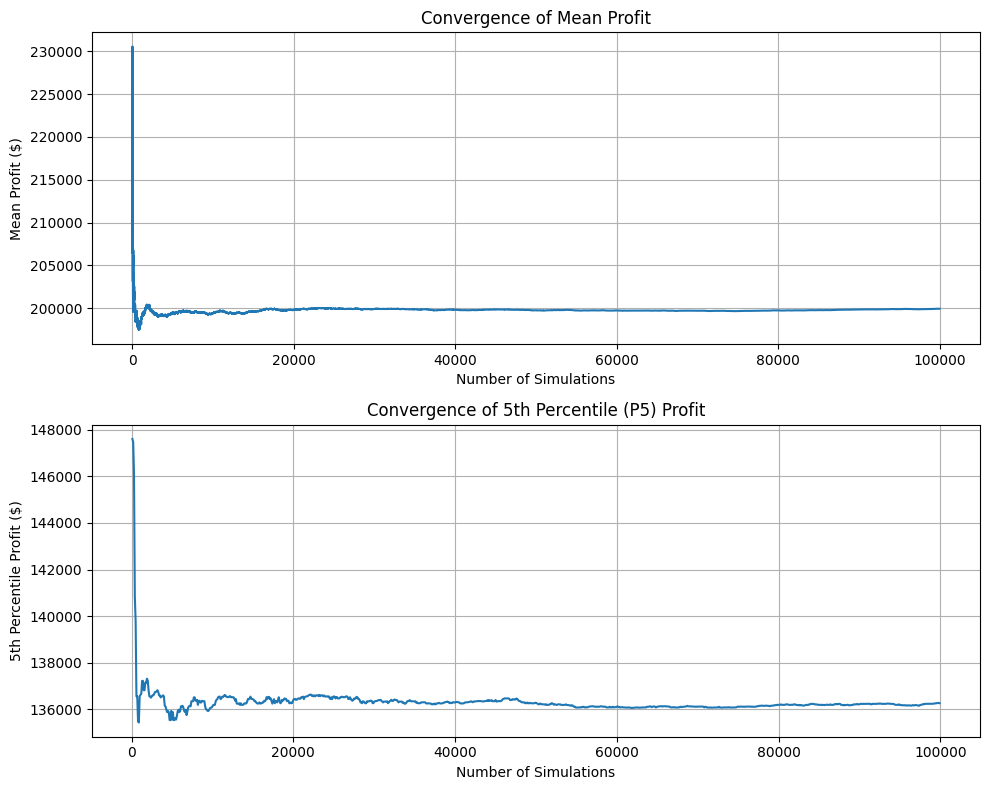


Phase 1 Complete. Chosen N = 15000 for each run.

--- Starting Phase 2: Run-to-Run Stability Analysis ---
Run 1/10: Mean Profit = $199,743.37, P5 Profit = $136,493.79
Run 2/10: Mean Profit = $200,480.22, P5 Profit = $137,070.70
Run 3/10: Mean Profit = $199,827.27, P5 Profit = $136,375.81
Run 4/10: Mean Profit = $199,571.32, P5 Profit = $135,507.21
Run 5/10: Mean Profit = $200,149.50, P5 Profit = $136,206.28
Run 6/10: Mean Profit = $199,892.91, P5 Profit = $136,358.86
Run 7/10: Mean Profit = $199,934.59, P5 Profit = $136,823.65
Run 8/10: Mean Profit = $199,920.57, P5 Profit = $136,556.82
Run 9/10: Mean Profit = $200,069.17, P5 Profit = $136,293.77
Run 10/10: Mean Profit = $200,153.19, P5 Profit = $136,729.66

--- Phase 2 Final Results ---
Mean Profit: $199,974.21
Stability (Std Dev of Mean): $240.02

5th Percentile Profit: $136,441.66
Stability (Std Dev of P5): $400.27


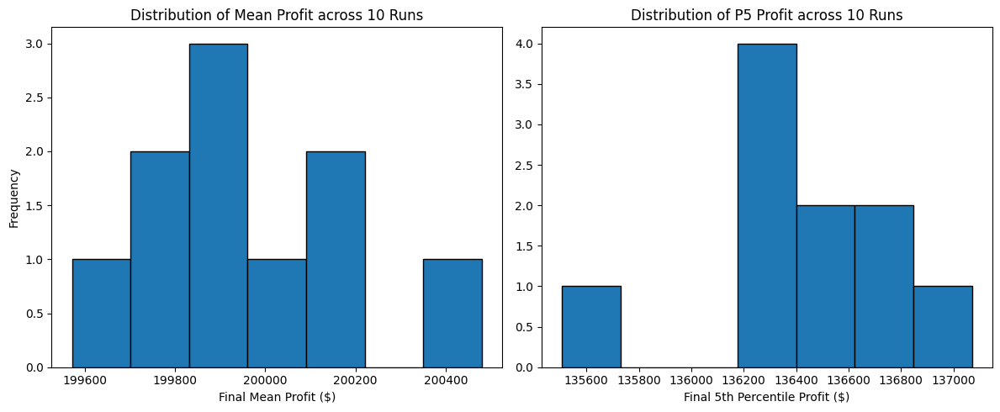

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Define the Simulation Model ---
# This function runs a single simulation for a given number of iterations and seed.
def run_profit_simulation(num_simulations, seed):
    """
    Runs a Monte Carlo simulation for product profit.
    """
    # Set the seed for reproducibility
    np.random.seed(seed)

    # Model parameters
    price_per_unit = 50

    # Simulate random variables
    units_sold = np.random.normal(loc=10000, scale=1500, size=num_simulations)
    cost_per_unit = np.random.uniform(low=25, high=35, size=num_simulations)

    # Ensure units sold and cost are non-negative
    units_sold[units_sold < 0] = 0

    # Calculate profit for each simulation
    profit = (units_sold * price_per_unit) - (units_sold * cost_per_unit)

    return profit

# --- 2. Phase 1: Convergence Analysis ---
# Objective: Find the required number of simulations (N) for our metrics to stabilize.

print("--- Starting Phase 1: Convergence Analysis ---")
long_run_simulations = 100000
exploratory_results = run_profit_simulation(long_run_simulations, seed=0)

# Calculate cumulative metrics
cumulative_mean = np.cumsum(exploratory_results) / np.arange(1, long_run_simulations + 1)
cumulative_p5 = [np.percentile(exploratory_results[:i], 5) for i in range(100, long_run_simulations, 100)]

# Plot the convergence
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# Mean Convergence Plot
axes[0].plot(cumulative_mean)
axes[0].set_title('Convergence of Mean Profit')
axes[0].set_xlabel('Number of Simulations')
axes[0].set_ylabel('Mean Profit ($)')
axes[0].grid(True)

# 5th Percentile Convergence Plot
axes[1].plot(range(100, long_run_simulations, 100), cumulative_p5)
axes[1].set_title('Convergence of 5th Percentile (P5) Profit')
axes[1].set_xlabel('Number of Simulations')
axes[1].set_ylabel('5th Percentile Profit ($)')
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Interpretation of Phase 1:
# By looking at the plots, we can see that both the mean and the P5 profit start to
# flatten out significantly after about 10,000 simulations.
# To be safe, we will choose N = 15,000 for our production runs.
N_per_run = 15000
print(f"\nPhase 1 Complete. Chosen N = {N_per_run} for each run.\n")


# --- 3. Phase 2: Run-to-Run Stability Analysis ---
# Objective: Verify that running the simulation multiple times with N=15,000 gives consistent results.

print("--- Starting Phase 2: Run-to-Run Stability Analysis ---")
M_runs = 10  # We will run the entire simulation 10 times
final_mean_profits = []
final_p5_profits = []

for i in range(M_runs):
    # Run the simulation with N iterations and a DIFFERENT seed each time
    run_results = run_profit_simulation(num_simulations=N_per_run, seed=i)

    # Calculate and store the final metrics for this run
    final_mean_profits.append(np.mean(run_results))
    final_p5_profits.append(np.percentile(run_results, 5))
    print(f"Run {i+1}/{M_runs}: Mean Profit = ${np.mean(run_results):,.2f}, P5 Profit = ${np.percentile(run_results, 5):,.2f}")

# Analyze the results from the M runs
mean_of_means = np.mean(final_mean_profits)
std_of_means = np.std(final_mean_profits)

mean_of_p5s = np.mean(final_p5_profits)
std_of_p5s = np.std(final_p5_profits)

print("\n--- Phase 2 Final Results ---")
print(f"Mean Profit: ${mean_of_means:,.2f}")
print(f"Stability (Std Dev of Mean): ${std_of_means:,.2f}\n")

print(f"5th Percentile Profit: ${mean_of_p5s:,.2f}")
print(f"Stability (Std Dev of P5): ${std_of_p5s:,.2f}")

# Plot the distribution of the final metrics from the M runs
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(final_mean_profits, bins=7, edgecolor='black')
axes[0].set_title('Distribution of Mean Profit across 10 Runs')
axes[0].set_xlabel('Final Mean Profit ($)')
axes[0].set_ylabel('Frequency')

axes[1].hist(final_p5_profits, bins=7, edgecolor='black')
axes[1].set_title('Distribution of P5 Profit across 10 Runs')
axes[1].set_xlabel('Final 5th Percentile Profit ($)')

plt.tight_layout()
plt.show()

--- Starting Phase 1: Convergence Analysis with CI ---


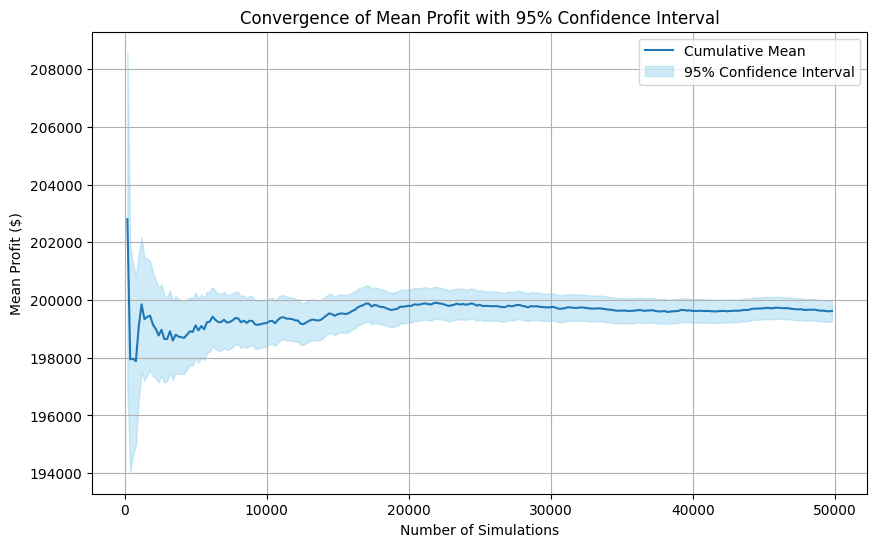


Phase 1 Complete. Chosen N = 15000 for each run.

--- Starting Phase 2: Run-to-Run Stability Analysis ---

--- Phase 2 Final Report ---
Final Mean Profit Estimate: $199,974.21
95% Confidence Interval (Mean): [$199,793.22, $200,155.20]

Final 5th Percentile Profit Estimate: $136,441.66
95% Confidence Interval (P5): [$136,139.83, $136,743.48]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t

# --- 1. Define the Simulation Model (same as before) ---
def run_profit_simulation(num_simulations, seed):
    np.random.seed(seed)
    price_per_unit = 50
    units_sold = np.random.normal(loc=10000, scale=1500, size=num_simulations)
    cost_per_unit = np.random.uniform(low=25, high=35, size=num_simulations)
    units_sold[units_sold < 0] = 0
    profit = (units_sold * price_per_unit) - (units_sold * cost_per_unit)
    return profit

# --- 2. Phase 1: Convergence Analysis with Confidence Intervals ---
print("--- Starting Phase 1: Convergence Analysis with CI ---")
long_run_simulations = 50000
exploratory_results = run_profit_simulation(long_run_simulations, seed=0)

# Calculate cumulative metrics for plotting
plot_points = np.arange(200, long_run_simulations, 200)
cumulative_means = []
ci_upper_bounds = []
ci_lower_bounds = []

Z = 1.96  # For 95% CI

for i in plot_points:
    current_data = exploratory_results[:i]
    mean = np.mean(current_data)
    std_dev = np.std(current_data)
    margin_of_error = Z * (std_dev / np.sqrt(i))

    cumulative_means.append(mean)
    ci_upper_bounds.append(mean + margin_of_error)
    ci_lower_bounds.append(mean - margin_of_error)

# Plot the convergence with CI bands
plt.figure(figsize=(10, 6))
plt.plot(plot_points, cumulative_means, label='Cumulative Mean')
plt.fill_between(plot_points, ci_lower_bounds, ci_upper_bounds, color='skyblue', alpha=0.4, label='95% Confidence Interval')
plt.title('Convergence of Mean Profit with 95% Confidence Interval')
plt.xlabel('Number of Simulations')
plt.ylabel('Mean Profit ($)')
plt.legend()
plt.grid(True, which='both', linestyle='--', alpha=0.6)
plt.show()


N_per_run = 15000
print(f"\nPhase 1 Complete. Chosen N = {N_per_run} for each run.\n")


# --- 3. Phase 2: Run-to-Run Stability with Final Confidence Interval ---
print("--- Starting Phase 2: Run-to-Run Stability Analysis ---")
M_runs = 10
final_mean_profits = []
final_p5_profits = []

for i in range(M_runs):
    run_results = run_profit_simulation(num_simulations=N_per_run, seed=i)
    final_mean_profits.append(np.mean(run_results))
    final_p5_profits.append(np.percentile(run_results, 5))

# Convert to numpy arrays for easier calculations
final_mean_profits = np.array(final_mean_profits)
final_p5_profits = np.array(final_p5_profits)

# Calculate the final confidence interval for the MEAN profit
mean_of_means = np.mean(final_mean_profits)
std_of_means = np.std(final_mean_profits, ddof=1) # Use ddof=1 for sample std dev
degrees_of_freedom = M_runs - 1
confidence_level = 0.95
t_value = t.ppf((1 + confidence_level) / 2, df=degrees_of_freedom)
margin_of_error_final = t_value * (std_of_means / np.sqrt(M_runs))

# Calculate the final CI for the P5 profit (using the same method)
mean_of_p5s = np.mean(final_p5_profits)
std_of_p5s = np.std(final_p5_profits, ddof=1)
margin_of_error_p5 = t_value * (std_of_p5s / np.sqrt(M_runs))

print("\n--- Phase 2 Final Report ---")
print(f"Final Mean Profit Estimate: ${mean_of_means:,.2f}")
print(f"95% Confidence Interval (Mean): [${mean_of_means - margin_of_error_final:,.2f}, ${mean_of_means + margin_of_error_final:,.2f}]\n")

print(f"Final 5th Percentile Profit Estimate: ${mean_of_p5s:,.2f}")
print(f"95% Confidence Interval (P5): [${mean_of_p5s - margin_of_error_p5:,.2f}, ${mean_of_p5s + margin_of_error_p5:,.2f}]")

In [ ]:

series = pd.Series(list(range(100)))
mean = series.rolling(window=25).mean()
mean[24]

np.float64(12.0)

In [ ]:
df = pd.DataFrame({'A': [1, 2, 3, 4, 5], 'B': [6, 7, 8, 9, 10]})
a = df['A']
a.name

'A'

--- Calculating 95% Bootstrap CI for the Median ---
Original sample median: $197,375.03

Bootstrap 95% Confidence Interval for the Median:
[$196,393.63, $198,309.44]


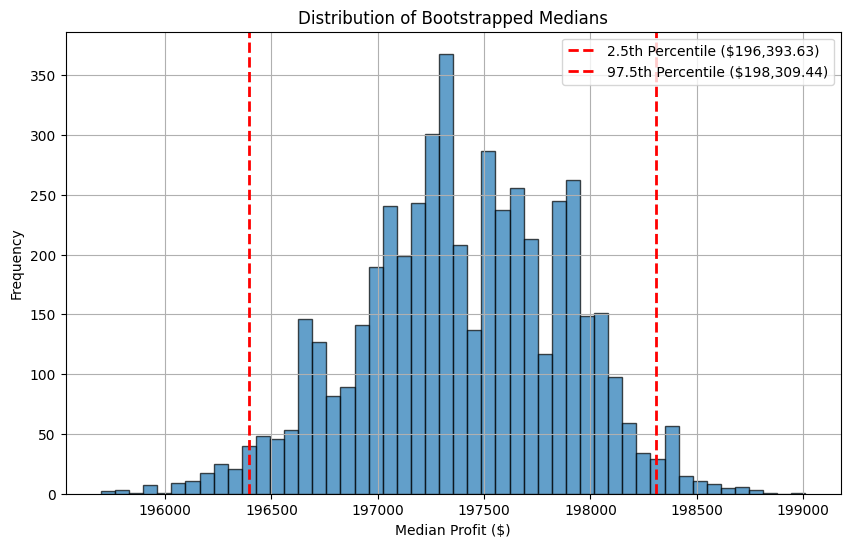

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- We'll use the same simulation function as before ---
def run_profit_simulation(num_simulations, seed):
    np.random.seed(seed)
    price_per_unit = 50
    units_sold = np.random.normal(loc=10000, scale=1500, size=num_simulations)
    cost_per_unit = np.random.uniform(low=25, high=35, size=num_simulations)
    units_sold[units_sold < 0] = 0
    profit = (units_sold * price_per_unit) - (units_sold * cost_per_unit)
    return profit

# --- Run a simulation to get a sample dataset ---
# In a real scenario, this would be the results from one of your stable runs.
N_per_run = 15000
simulation_results = run_profit_simulation(num_simulations=N_per_run, seed=42)

# --- Calculate the Bootstrap Confidence Interval for the Median ---

print(f"--- Calculating 95% Bootstrap CI for the Median ---")
print(f"Original sample median: ${np.median(simulation_results):,.2f}")

# Bootstrap parameters
n_iterations = 5000  # Number of bootstrap samples to create
n_size = len(simulation_results) # Size of each bootstrap sample

# Array to store the medians from each bootstrap sample
bootstrapped_medians = []

for i in range(n_iterations):
    # Create a bootstrap sample by resampling with replacement
    bootstrap_sample = np.random.choice(simulation_results, size=n_size, replace=True)

    # Calculate and store the median of the bootstrap sample
    median = np.median(bootstrap_sample)
    bootstrapped_medians.append(median)

# Calculate the 95% confidence interval using percentiles
confidence_level = 0.95
lower_bound = np.percentile(bootstrapped_medians, (1 - confidence_level) / 2 * 100)
upper_bound = np.percentile(bootstrapped_medians, (confidence_level + (1 - confidence_level) / 2) * 100)

print(f"\nBootstrap 95% Confidence Interval for the Median:")
print(f"[${lower_bound:,.2f}, ${upper_bound:,.2f}]")


# --- Visualize the distribution of bootstrapped medians ---
plt.figure(figsize=(10, 6))
plt.hist(bootstrapped_medians, bins=50, edgecolor='black', alpha=0.7)
plt.axvline(lower_bound, color='red', linestyle='--', linewidth=2, label=f'2.5th Percentile (${lower_bound:,.2f})')
plt.axvline(upper_bound, color='red', linestyle='--', linewidth=2, label=f'97.5th Percentile (${upper_bound:,.2f})')
plt.title('Distribution of Bootstrapped Medians')
plt.xlabel('Median Profit ($)')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True, which='both', linestyle='--', alpha=0.6)
plt.show()

# Publication-Ready Gridded Multi-Panel Figures & MCG / CCG Summary Tables
<!-- PUBLICATION_FIGURES_AND_TABLES_EXTENSION -->
The cell below computes both **Maximal Contribution Gap ($	ext{MCG} = \max_c U_c - \min_c L_c$)** and **Central Contribution Gap ($	ext{CCG} = \max_c \hat{c}_c - \min_c \hat{c}_c$)** across all single-format (`all_*`) and combined-format (`lowest_performing`, `highest_performing`, `formats_combined_proposed`) experiments, and generates the gridded multi-panel figures (`single_format_experiments_gridded.png` and `combined_experiments_gridded.png`) with major and minor coordinate grids.

In [ ]:
#@title Generate Gridded Multi-Panel Figures & MCG/CCG Summary Tables (Tables 2, 3, and 4)
# <!-- PUBLICATION_FIGURES_AND_TABLES_EXTENSION -->

label_map_pub = {
    'rn_from_data': 'RN (Derived Scale)',
    'rn_fixed_scale': 'RN (Fixed Scale)',
    'uv_cardinal': 'UV (Cardinal)',
    'uv_ordinal': 'UV (Ordinal)',
    'oa': 'OA',
    'mpr': 'MPR',
    'arfpr': 'ARFPR',
}

def plot_publication_combined_gridded(dfs_dict, out_filename='combined_experiments_gridded.png'):
  combined_cfgs = [
      ('lowest_performing', 'Experiment 1: Lowest-Performing Legacy Portfolio'),
      ('highest_performing', 'Experiment 2: Highest-Performing Legacy Portfolio'),
      ('formats_combined_proposed', 'Experiment 3: Proposed Linear Portfolio')
  ]
  order = ['rn_from_data', 'rn_fixed_scale', 'uv_cardinal', 'uv_ordinal', 'oa', 'mpr', 'arfpr']
  fig, axes = plt.subplots(3, 2, figsize=(14, 13), dpi=300, sharey='col')

  for row_idx, (cfg, row_title) in enumerate(combined_cfgs):
    if cfg not in dfs_dict:
      continue
    means_d = mean_cis_from_df(dfs_dict[cfg])
    meds_d  = median_cis_from_df(dfs_dict[cfg])
    for col_idx, (m_prefix, m_name) in enumerate([('relative_avg', 'RMC'), ('relative_high_owa', 'RHPC')]):
      ax = axes[row_idx, col_idx]
      cols = [f'{m_prefix}_{c}' for c in order]
      labels = [label_map_pub[c] for c in order]

      means = np.array([means_d[col]['mean'] for col in cols])
      m_lb  = np.array([means_d[col]['lower_bound'] for col in cols])
      m_ub  = np.array([means_d[col]['upper_bound'] for col in cols])

      meds  = np.array([meds_d[col]['median'] for col in cols])
      md_lb = np.array([meds_d[col]['lower_bound'] for col in cols])
      md_ub = np.array([meds_d[col]['upper_bound'] for col in cols])

      mcg_m, ccg_m   = np.max(m_ub) - np.min(m_lb), np.max(means) - np.min(means)
      mcg_md, ccg_md = np.max(md_ub) - np.min(md_lb), np.max(meds) - np.min(meds)
      print(f"{cfg:26s} | {m_name:4s} -> Mean MCG (CCG): {mcg_m:.3f} ({ccg_m:.3f}) | Median MCG (CCG): {mcg_md:.3f} ({ccg_md:.3f})")

      x = np.arange(len(labels))
      ax.errorbar(x - 0.1, means, yerr=[means - m_lb, m_ub - means],
                  fmt='o', capsize=4, markersize=5.5, label='Mean (95% CI)', color='#d62728')
      ax.errorbar(x + 0.1, meds, yerr=[meds - md_lb, md_ub - meds],
                  fmt='s', capsize=4, markersize=5.5, label='Median (95% CI)', color='#008080')
      ax.set_title(f'{row_title} — {m_name}', fontsize=11, fontweight='bold')
      ax.set_xticks(x)
      ax.set_xticklabels(labels, rotation=28, ha='right', fontsize=9.5)
      ax.set_ylabel(m_name, fontsize=10.5)
      ax.minorticks_on()
      ax.grid(True, which='major', linestyle='--', alpha=0.65)
      ax.grid(True, which='minor', linestyle=':', alpha=0.35)
      ax.legend(loc='best', fontsize=9)

  plt.tight_layout()
  plt.savefig(out_filename, dpi=300)
  plt.show()
